# Blood Rheology Feature Integration and Cohort Audit

This notebook assembles existing blood-rheology measurements and analysis outputs into a traceable, measurement-level dataset. It documents cohort coverage, reconciles step-measurement identifiers, and provides representative signal previews. Previously generated analyses are loaded as inputs; their calculations are not rerun here.

The active scope is human blood rheology. Gel and gel-point measurements are excluded. The source packages and cohort filters differ, so their record counts are reported separately before integration.

## Cohort overview

- The standardized data catalogue contains 357 measurements: 200 LAOS records and 157 step records (74 increasing, 73 decreasing, and 10 with unknown direction).
- The final LAOS feature table contains 181 measurements after duplicate and unlabeled-record exclusions.
- The shared step-feature table contains 138 measurements. The separate step-response analysis package contains 136; its supplied comparison indicates that two AUG18 records in the shared table are absent from its raw-workbook comparison.

These counts refer to distinct source packages and filtering rules. They are not interchangeable sample sizes. The following sections retain source provenance and make identifier coverage explicit.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Compatibility for original analysis code written before NumPy 2.0.
if not hasattr(np, "trapz") and hasattr(np, "trapezoid"):
    np.trapz = np.trapezoid
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

## 1. Locate the project and analysis inputs

The project root is located from its move manifest. This allows the notebook to run from the project directory or one of its subfolders without hard-coded launch-directory assumptions.

In [2]:
search_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
search_roots.append(Path.home() / "Desktop" / "Haemograph_Project")
PROJECT_ROOT = next(
    (path for path in search_roots if (path / "MOVE_MANIFEST.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate Haemograph_Project. Open this notebook from its project folder.")

SOURCE_PACKAGES_DIR = PROJECT_ROOT / "03_Team_Contributions"
PROCESSING_DIR = SOURCE_PACKAGES_DIR / "Part1_Data_Processing" / "Extracted_Contents" / "main-data"
LAOS_FEATURE_MATCHES = list(SOURCE_PACKAGES_DIR.glob("Part2*/Extracted_Contents/*/laos_features.csv"))
if len(LAOS_FEATURE_MATCHES) != 1:
    raise FileNotFoundError(f"Expected one LAOS feature table; found {len(LAOS_FEATURE_MATCHES)}")
LAOS_FEATURE_DIR = LAOS_FEATURE_MATCHES[0].parent
STEP_ANALYSIS_DIR = SOURCE_PACKAGES_DIR / "Part3_Step_Transient_Analysis"
STEP_OUTPUT_DIR = STEP_ANALYSIS_DIR / "outputs"

SIGNALS_PATH = PROCESSING_DIR / "standardized_signals.csv.gz"
INDEX_PATH = PROCESSING_DIR / "measurement_index.csv"
LAOS_FEATURES_PATH = LAOS_FEATURE_DIR / "laos_features.csv"
SHARED_STEP_FEATURES_PATH = PROCESSING_DIR / "step_analysis_outputs_main" / "step_features.csv"
STEP_ANALYSIS_FEATURES_PATH = STEP_OUTPUT_DIR / "step_features.csv"

print("Project root:", PROJECT_ROOT)
print("Processing data package:", PROCESSING_DIR)
print("LAOS feature package:", LAOS_FEATURE_DIR)
print("Step-response analysis package:", STEP_OUTPUT_DIR)

Project root: /Users/riamishra/Desktop/Haemograph_Project
Processing data package: /Users/riamishra/Desktop/Haemograph_Project/03_Team_Contributions/Part1_Data_Processing/Extracted_Contents/main-data
LAOS feature package: /Users/riamishra/Desktop/Haemograph_Project/03_Team_Contributions/Part2_Conventional_LAOS/Extracted_Contents/Part2 ¿C Conventional LAOS Analysis
Step-response analysis package: /Users/riamishra/Desktop/Haemograph_Project/03_Team_Contributions/Part3_Step_Transient_Analysis/outputs


## 2. Load the source data and analysis outputs

The standardized signal table is kept separate from measurement-level feature tables to avoid multiplying time-series rows when features are joined.

In [3]:
measurement_index = pd.read_csv(INDEX_PATH)
standardized_signals = pd.read_csv(SIGNALS_PATH)
field_dictionary = pd.read_csv(PROCESSING_DIR / "field_dictionary.csv")
data_quality_log = pd.read_csv(PROCESSING_DIR / "data_quality_log.csv")
exclusion_log = pd.read_csv(PROCESSING_DIR / "exclusion_log.csv")

laos_features = pd.read_csv(LAOS_FEATURES_PATH)
shared_step_features = pd.read_csv(SHARED_STEP_FEATURES_PATH)
step_analysis_features = pd.read_csv(STEP_ANALYSIS_FEATURES_PATH)
step_analysis_events = pd.read_csv(STEP_OUTPUT_DIR / "step_events.csv")
step_analysis_windows = pd.read_csv(STEP_OUTPUT_DIR / "step_windows.csv")

laos_reliability = pd.read_csv(LAOS_FEATURE_DIR / "metric_reliability_final.csv")
laos_strain_results = pd.read_csv(LAOS_FEATURE_DIR / "result_strain_amplitude_final.csv")
laos_instrument_validation = pd.read_csv(LAOS_FEATURE_DIR / "instrument_crossvalidation_summary.csv")
step_reliability = pd.read_csv(STEP_OUTPUT_DIR / "metric_reliability.csv")
step_magnitude_results = pd.read_csv(STEP_OUTPUT_DIR / "result_magnitude.csv")
step_direction_results = pd.read_csv(STEP_OUTPUT_DIR / "result_direction.csv")
step_transient_stable_results = pd.read_csv(STEP_OUTPUT_DIR / "result_transient_vs_stable.csv")

print("Measurement index:", measurement_index.shape)
print("Standardized signal rows:", standardized_signals.shape)
print("LAOS feature rows:", laos_features.shape)
print("Shared step feature rows:", shared_step_features.shape)
print("Step-response feature rows:", step_analysis_features.shape)

Measurement index: (357, 31)
Standardized signal rows: (437956, 12)
LAOS feature rows: (181, 27)
Shared step feature rows: (138, 48)
Step-response feature rows: (136, 48)


## 3. Audit cohort coverage before integration

The measurement index is the shared catalogue. The feature tables represent filtered analysis cohorts, so this audit makes their coverage and identifier uniqueness explicit.

In [4]:
cohort_counts = (
    measurement_index
    .groupby(["experiment_type", "experiment_subtype"], dropna=False)
    .size()
    .rename("measurement_count")
    .reset_index()
)
cohort_counts

,experiment_type,experiment_subtype,measurement_count
0,LAOS,LAOS,200
1,STEP_UP_DOWN,STEP_DOWN,73
2,STEP_UP_DOWN,STEP_UNKNOWN,10
3,STEP_UP_DOWN,STEP_UP,74


In [5]:
def feature_source_audit(source_name, frame, id_column, known_ids):
    identifiers = frame[id_column].astype(str)
    return {
        "source": source_name,
        "rows": len(frame),
        "unique_source_ids": identifiers.nunique(),
        "duplicate_source_ids": int(identifiers.duplicated().sum()),
        "ids_found_in_shared_index": int(identifiers.isin(known_ids).sum()),
    }

shared_ids = set(measurement_index["measurement_id"].astype(str))
feature_source_counts = pd.DataFrame([
    feature_source_audit("Final LAOS feature table", laos_features, "measurement_id", shared_ids),
    feature_source_audit("Shared step-feature table", shared_step_features, "step_id", shared_ids),
])
feature_source_counts

,source,rows,unique_source_ids,duplicate_source_ids,ids_found_in_shared_index
0,Final LAOS feature table,181,181,0,181
1,Shared step-feature table,138,138,0,138


## 4. Reconcile step-measurement identifiers

The step-response package uses local identifiers such as `S001`, while the shared catalogue uses identifiers such as `P1M0001`. The crosswalk uses workbook, sheet, block order, and condition label. Block order is reconstructed from source start columns within each workbook and sheet.

In [6]:
step_index = measurement_index.loc[measurement_index["experiment_type"].eq("STEP_UP_DOWN")].copy()
step_index["source_start_column"] = pd.to_numeric(step_index["source_start_column"], errors="coerce")
step_index = step_index.sort_values(["source_file", "sheet", "source_start_column"])
step_index["block"] = step_index.groupby(["source_file", "sheet"]).cumcount() + 1
step_index["workbook"] = step_index["source_file"].astype(str).str.strip()
step_index["sheet"] = step_index["sheet"].astype(str).str.strip()
step_index["label"] = step_index["condition_label"].astype(str).str.strip()

step_analysis_keys = step_analysis_features.copy()
step_analysis_keys["workbook"] = step_analysis_keys["workbook"].astype(str).str.strip()
step_analysis_keys["sheet"] = step_analysis_keys["sheet"].astype(str).str.strip()
step_analysis_keys["label"] = step_analysis_keys["label"].astype(str).str.strip()
step_analysis_keys["block"] = pd.to_numeric(step_analysis_keys["block"], errors="coerce").astype("Int64")
step_keys = ["workbook", "sheet", "block", "label"]

step_id_crosswalk = step_analysis_keys[step_keys + ["step_id"]].merge(
    step_index[step_keys + ["measurement_id"]],
    on=step_keys,
    how="left",
    validate="one_to_one",
    indicator=True,
)
step_id_crosswalk["mapping_status"] = step_id_crosswalk["_merge"].astype(str)
step_id_crosswalk.drop(columns="_merge", inplace=True)
step_id_crosswalk["measurement_id"].notna().value_counts().rename(index={True: "mapped", False: "unmapped"})

measurement_id
mapped    136
Name: count, dtype: int64

In [7]:
shared_step_ids = set(shared_step_features["step_id"].astype(str))
step_analysis_mapped_ids = set(step_id_crosswalk["measurement_id"].dropna().astype(str))
step_cohort_reconciliation = pd.DataFrame([
    {"comparison": "Shared pipeline step features", "rows": len(shared_step_features), "shared_ids": len(shared_step_ids)},
    {"comparison": "Mapped step-response features", "rows": len(step_analysis_features), "shared_ids": len(step_analysis_mapped_ids)},
    {"comparison": "Shared step IDs absent from step-response package", "rows": len(shared_step_ids - step_analysis_mapped_ids), "shared_ids": len(shared_step_ids - step_analysis_mapped_ids)},
])
step_cohort_reconciliation

,comparison,rows,shared_ids
0,Shared pipeline step features,138,138
1,Mapped step-response features,136,136
2,Shared step IDs absent from step-response package,2,2


## 5. Assemble the measurement-level feature table

The shared measurement index is retained as the left-hand table, including measurements without features in a given analysis package. Feature columns are prefixed by analysis type to preserve provenance and avoid name collisions.

In [8]:
def prefix_feature_columns(frame, id_column, prefix):
    renamed = frame.copy()
    renamed.columns = [id_column if column == id_column else f"{prefix}{column}" for column in renamed.columns]
    return renamed

laos_for_merge = prefix_feature_columns(laos_features, "measurement_id", "laos__")
shared_step_for_merge = prefix_feature_columns(shared_step_features, "step_id", "shared_step__")

step_analysis_feature_columns = step_analysis_features.drop(
    columns=["workbook", "sheet", "block", "label"], errors="ignore"
).copy()
step_analysis_feature_columns = step_analysis_feature_columns.rename(columns={"step_id": "step_analysis_id"})
step_analysis_keyed = step_id_crosswalk[["measurement_id", "step_id"]].merge(
    step_analysis_feature_columns,
    left_on="step_id",
    right_on="step_analysis_id",
    how="inner",
    validate="one_to_one",
)
step_analysis_keyed.drop(columns="step_id", inplace=True)
step_analysis_keyed = prefix_feature_columns(step_analysis_keyed, "measurement_id", "step_analysis__")

integrated_features = measurement_index.merge(
    laos_for_merge, on="measurement_id", how="left", validate="one_to_one"
).merge(
    shared_step_for_merge, left_on="measurement_id", right_on="step_id",
    how="left", validate="one_to_one"
).merge(
    step_analysis_keyed, on="measurement_id", how="left", validate="one_to_one"
)

integrated_features["has_laos_analysis_features"] = integrated_features["laos__G_prime_Pa"].notna()
integrated_features["has_shared_step_analysis_features"] = integrated_features["shared_step__sigma_stable"].notna()
integrated_features["has_step_analysis_features"] = integrated_features["step_analysis__overshoot"].notna()

coverage_by_experiment = (
    integrated_features.groupby("experiment_type", dropna=False)[
        ["has_laos_analysis_features", "has_shared_step_analysis_features", "has_step_analysis_features"]
    ].sum().astype(int)
)
display(coverage_by_experiment)
integrated_features.head()

,has_laos_analysis_features,has_shared_step_analysis_features,has_step_analysis_features
experiment_type,,,
LAOS,181,0,0
STEP_UP_DOWN,0,133,131


,measurement_id,source_file,sheet,source_header_row,source_start_column,experiment_type,experiment_subtype,condition_label,n_points,duration_s,median_dt_s,sampling_rate_hz,dt_coefficient_of_variation,has_stress,has_strain,has_shear_rate,step_start_rate_measured_1_s,step_final_rate_measured_1_s,startup_outlier_rows,classification_confidence,qc_status,qc_notes,step_start_rate_label_1_s,step_final_rate_label_1_s,step_magnitude_label_1_s,step_direction,omega_label_rad_s,strain_amplitude_label_fraction,strain_amplitude_label_pct,signal_sha256,duplicate_of_measurement_id,laos__source_file,laos__sheet,laos__condition_label,laos__qc_status,laos__qc_notes,laos__omega_label_rad_s,laos__strain_amplitude_label_fraction,laos__strain_amplitude_label_pct,laos__strain_amplitude_nominal,...,step_analysis__high_res,step_analysis__rate_from_meas,step_analysis__rate_to_meas,step_analysis__has_pre_step,step_analysis__t_step,step_analysis__t_rate_settle,step_analysis__rate_overshoot_frac,step_analysis__qc_rate,step_analysis__ratio,step_analysis__log10_ratio,step_analysis__direction,step_analysis__magnitude_abs,step_analysis__n_transient,step_analysis__n_stable,step_analysis__sigma_stable,step_analysis__stable_drift_Pa,step_analysis__stable_drift_frac,step_analysis__stable_ok,step_analysis__below_noise,step_analysis__sigma_pre,step_analysis__sigma_pre_fc,step_analysis__sigma_final_fc,step_analysis__sigma_imm,step_analysis__sigma_peak,step_analysis__t_peak,step_analysis__sigma_min,step_analysis__t_min,step_analysis__overshoot,step_analysis__undershoot,step_analysis__jump_signed,step_analysis__relax_amp,step_analysis__init_slope,step_analysis__settling_time,step_analysis__area_log,step_analysis__plateau_vs_fc,step_analysis__baseline_vs_fc,step_analysis__visc_ratio,has_laos_analysis_features,has_shared_step_analysis_features,has_step_analysis_features
0,P1M0001,12FEB20 UDEL Blood.xlsx,Steps,2,1,STEP_UP_DOWN,STEP_DOWN,10-->.1,65,63.000371,0.061340,16.302443,2.022758,YES,YES,YES,9.98600,0.100012,0,HIGH,OK,Irregular sampling (dt CV > 0.10),10.0,0.1,9.9,DOWN,NaN,NaN,NaN,7f986b4ee2cf875f7a6c382d53f61e012803d759f6f381...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,9.98600,0.100012,True,0.010504,0.057501,0.052045,ok,0.010000,-2.000000,down,9.9,23.0,5.0,0.003840,-0.000131,0.034102,True,False,0.075313,0.088640,0.007270,-0.000071,0.015854,0.078832,-0.000071,0.057501,3.128231,1.018537,-1.018537,-0.003912,-1.448169,10.9058,-1.646835,0.528254,0.849648,5.099279,False,True,True
1,P1M0002,12FEB20 UDEL Blood.xlsx,Steps,2,6,STEP_UP_DOWN,STEP_DOWN,300--> 20(1/s),65,62.999863,0.061325,16.306430,2.022778,YES,YES,YES,300.02600,20.002400,0,HIGH,OK,Irregular sampling (dt CV > 0.10),300.0,20.0,280.0,DOWN,NaN,NaN,NaN,ec8e770c83b81f5d103cc37c745d5f89b5c4e9d37242d6...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,300.02600,20.002400,True,0.014173,0.050000,0.036953,ok,0.066667,-1.176091,down,280.0,23.0,5.0,0.126984,-0.001613,0.012701,True,False,1.195740,1.163975,0.131600,0.117854,0.146517,0.527998,0.110625,0.078657,0.153823,0.128827,-0.071899,-0.009130,0.194823,3.0460,0.379018,0.964924,1.027290,1.592955,False,True,True
2,P1M0003,12FEB20 UDEL Blood.xlsx,Steps,2,11,STEP_UP_DOWN,STEP_DOWN,300-->5,65,62.999860,0.061333,16.304436,2.022778,YES,YES,YES,300.02000,5.000590,0,HIGH,OK,Irregular sampling (dt CV > 0.10),300.0,5.0,295.0,DOWN,NaN,NaN,NaN,730f2b01a18730d9a4567e6e430d887e9d5c4d40530a14...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,300.02000,5.000600,True,0.014161,0.067170,0.036195,ok,0.016667,-1.778151,down,295.0,22.0,5.0,0.053187,-0.009713,0.182622,False,False,1.168200,1.163975,0.053645,0.062600,0.091312,45.798500,0.032606,0.078660,0.716811,0.386961,0.176982,0.009413,0.329929,NaN,0.350160,0.991451,1.003629,2.731731,False,True,True
3,P1M0004,12FEB20 UDEL Blood.xlsx,Steps,2,16,STEP_UP_DOWN,STEP_DOWN,300-->10,65,62.999869,0.061325,16.306563,2.022778,YES,YES,YES,300.02300,10.001200,0,HIGH,OK,Irregular sampling (dt CV > 0.10),300.0,10.0,290.0,DOWN,NaN,NaN,NaN,eee7b23c

## 6. Review existing analysis summaries

These tables contain previously generated results. LAOS summaries use workbook-level grouping; step-response direction analyses use matched reverse pairs, and transient/stable labels use the specified time windows. Review the reliability and exclusion outputs before selecting features for later comparisons.

In [9]:
reviewed_laos_reliability_display = laos_reliability[["metric"]].copy()
reviewed_laos_statuses = {
    "G_prime_Pa": "Computed; same-condition instrument validation not established",
    "G_double_prime_Pa": "Computed; same-condition instrument validation not established",
    "phase_angle_deg": "Derived feature; no independent instrument phase measurement",
    "I3_I1": "Computed; same-condition instrument validation not established",
    "I5_I1": "Exploratory; sensitive to detrending",
    "THD_2to5": "Exploratory; sensitive to detrending",
    "lissajous_normalized_area": "Descriptive feature; not an independent endpoint",
}
reviewed_laos_reliability_display["reviewed_status"] = (
    reviewed_laos_reliability_display["metric"].map(reviewed_laos_statuses)
)
print("Reviewed LAOS metric status; saved instrument comparisons are not same-condition validation.")
display(reviewed_laos_reliability_display)
display(laos_instrument_validation)
display(laos_strain_results.head(15))
step_reliability_display = step_reliability.rename(
    columns = {"classification": "inherited_heuristic_classification"}
).copy()
step_reliability_display["interpretation_note"] = (
    "Coverage/computability screening label; not predictive validation."
)
step_model_fit_mask = step_reliability_display["feature"].astype(str).str.contains(
    "tau", case = False, na = False
)
step_reliability_display.loc[step_model_fit_mask, "interpretation_note"] = (
    "Exploratory model-fit output; no clot-time ground truth is available."
)
print("Step feature labels below are inherited screening heuristics, not validated reliability claims.")
display(step_reliability_display)
display(step_magnitude_results.head(10))
display(step_direction_results.head(10))
display(step_transient_stable_results.head(10))

Reviewed LAOS metric status; saved instrument comparisons are not same-condition validation.


,metric,reviewed_status
0,G_prime_Pa,Computed; same-condition instrument validation...
1,G_double_prime_Pa,Computed; same-condition instrument validation...
2,phase_angle_deg,Derived feature; no independent instrument pha...
3,I3_I1,Computed; same-condition instrument validation...
4,I5_I1,Exploratory; sensitive to detrending
5,THD_2to5,Exploratory; sensitive to detrending
6,lissajous_normalized_area,Descriptive feature; not an independent endpoint


,metric,n_matched_pairs,median_absolute_percent_error,mean_absolute_percent_error,RMSE,median_bias_calc_minus_instrument,spearman_rho,pearson_r
0,G_prime_Pa,26,19.411281,39.726454,0.000633,0.000046,0.837949,0.986842
1,G_double_prime_Pa,26,1.625963,2.349002,0.000660,0.000054,0.991111,0.998848
2,I3_I1,12,6.508893,8.237111,0.005900,0.003862,0.951049,0.987466


,omega_rad_s,metric,n_workbooks,median_spearman_rho,bootstrap_CI_low,bootstrap_CI_high,direction_consistency_fraction,two_sided_sign_test_p
0,0.5,G_prime_Pa,7,-1.000000,-1.000000,-1.000000,1.0,0.015625
1,0.5,G_double_prime_Pa,7,-1.000000,-1.000000,-1.000000,1.0,0.015625
2,0.5,phase_angle_deg,7,1.000000,1.000000,1.000000,1.0,0.015625
3,0.5,I3_I1,7,0.100000,0.100000,0.300000,1.0,0.031250
4,0.5,I5_I1,7,0.900000,0.600000,0.900000,1.0,0.015625
5,0.5,THD_2to5,7,0.300000,0.100000,0.600000,1.0,0.015625
6,0.5,lissajous_normalized_area,7,1.000000,0.900000,1.000000,1.0,0.015625
7,1.0,G_prime_Pa,10,-1.000000,-1.000000,-1.000000,1.0,0.001953
8,1.0,G_double_prime_Pa,10,-1.000000,-1.000000,-1.000000,1.0,0.001953
9,1.0,phase_angle_deg,10,1.000000,0.971429,1.000000,1.0,0.001953


Step feature labels below are inherited screening heuristics, not validated reliability claims.


,feature,computable,magnitude_down,magnitude_up,direction,needs_stable_state,inherited_heuristic_classification,interpretation_note
0,jump_signed,0.96,no,yes,no,True,reliable,Coverage/computability screening label; not pr...
1,overshoot,0.96,no,yes,yes,True,reliable,Coverage/computability screening label; not pr...
2,undershoot,0.96,yes,yes,yes,True,reliable,Coverage/computability screening label; not pr...
3,init_slope,0.96,no,yes,yes,True,reliable,Coverage/computability screening label; not pr...
4,settling_time,0.92,no,yes,yes,True,reliable,Coverage/computability screening label; not pr...
5,t_peak,1.00,yes,no,no,False,reliable,Coverage/computability screening label; not pr...
6,t_min,1.00,yes,no,yes,False,reliable,Coverage/computability screening label; not pr...
7,area_log,0.96,no,no,yes,True,reliable,Coverage/computability screening label; not pr...
8,relax_amp,0.96,no,yes,no,False,reliable,Coverage/computability screening label; not pr...
9,visc_ratio,0.83,yes,yes,yes,False,reliable,Coverage/computability screening label; not pr...


,feature,direction,n_workbooks,median_rho,workbooks_rho_pos,sign_test_p,families
0,t_min,down,9,0.900000,9,0.003906,11
1,undershoot,down,8,1.000000,8,0.007812,10
2,visc_ratio,down,8,1.000000,8,0.007812,10
3,t_peak,down,9,0.600000,8,0.039062,11
4,overshoot,down,8,0.800000,7,0.070312,10
5,area_log,down,8,-0.933333,2,0.289062,10
6,init_slope,down,8,-0.250000,4,1.000000,10
7,jump_signed,down,8,0.316667,4,1.000000,10
8,relax_amp,down,8,0.150000,4,1.000000,10
9,settling_time,down,9,-0.200000,4,1.000000,11


,feature,n_workbooks,median_up_minus_down,workbooks_up_gt_down,sign_test_p,wilcoxon_p,pairs_up_gt_down
0,init_slope,10,0.802644,10,0.001953,0.001953,22/22
1,undershoot,10,-0.488191,0,0.001953,0.001953,0/22
2,visc_ratio,7,-7.638691,0,0.015625,0.015625,0/12
3,overshoot,10,-0.581646,1,0.021484,0.005859,6/22
4,area_log,10,1.697469,9,0.021484,0.005859,21/22
5,t_min,10,31.344418,9,0.021484,0.005859,15/22
6,settling_time,10,-6.864709,1,0.021484,0.013672,1/18
7,t_peak,10,0.073234,8,0.109375,0.105469,18/22
8,relax_amp,10,0.009309,8,0.109375,0.037109,16/22
9,jump_signed,10,-0.123921,3,0.343750,0.275391,9/22


,rule,descriptor,measurements_T_gt_S,median_log10_ratio_T_over_S,workbooks_T_gt_S,sign_test_p
0,primary (2 s / 30 s),abs_slope,106/128,0.538146,11/11,0.000977
1,primary (2 s / 30 s),abs_dev,127/128,1.382735,11/11,0.000977
2,primary (2 s / 30 s),cv,127/128,1.281412,11/11,0.000977
3,short (1 s / 20 s),abs_slope,119/133,0.738994,11/11,0.000977
4,short (1 s / 20 s),abs_dev,133/133,1.308541,11/11,0.000977
5,short (1 s / 20 s),cv,129/133,1.198783,11/11,0.000977
6,long (5 s / 40 s),abs_slope,87/128,0.361107,9/11,0.065430
7,long (5 s / 40 s),abs_dev,127/128,1.639121,11/11,0.000977
8,long (5 s / 40 s),cv,127/128,1.521895,11/11,0.000977


## 7. Inspect representative source signals

The helper below retrieves a standardized trace by shared measurement identifier. The plots are previews of source data; they do not recompute features.

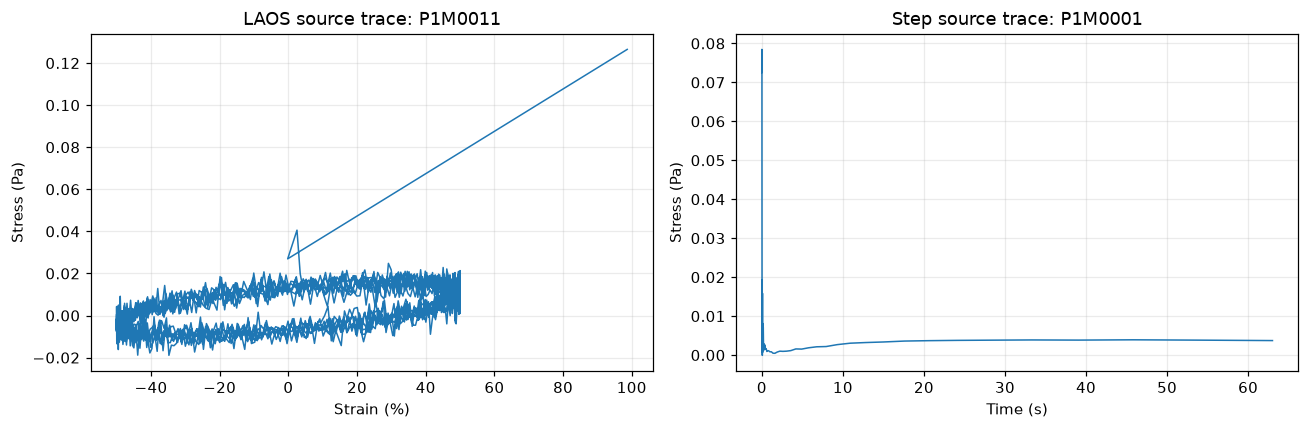

In [10]:
def get_measurement_trace(measurement_id):
    trace = standardized_signals.loc[
        standardized_signals["measurement_id"].astype(str).eq(str(measurement_id))
    ].copy()
    return trace.sort_values("time_s").reset_index(drop=True)

laos_example_id = str(laos_features["measurement_id"].iloc[0])
step_example_id = str(shared_step_features["step_id"].iloc[0])
laos_trace = get_measurement_trace(laos_example_id)
step_trace = get_measurement_trace(step_example_id)

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(laos_trace["strain_pct"], laos_trace["stress_pa"], linewidth=1)
axes[0].set(title=f"LAOS source trace: {laos_example_id}", xlabel="Strain (%)", ylabel="Stress (Pa)")
axes[1].plot(step_trace["time_s"], step_trace["stress_pa"], linewidth=1)
axes[1].set(title=f"Step source trace: {step_example_id}", xlabel="Time (s)", ylabel="Stress (Pa)")
figure.tight_layout()
plt.show()

## 8. Export the integrated tables

The source analysis outputs are not modified. This cell writes the integrated measurement-level table, identifier crosswalk, and cohort-coverage summaries to a new results folder.

In [11]:
INTEGRATED_OUTPUT_DIR = PROJECT_ROOT / "01_Active_Blood_Project" / "04_Results" / "Integrated_Feature_Analysis"
INTEGRATED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

integrated_features.to_csv(INTEGRATED_OUTPUT_DIR / "integrated_measurement_features.csv", index=False)
step_id_crosswalk.to_csv(INTEGRATED_OUTPUT_DIR / "step_measurement_id_crosswalk.csv", index=False)
cohort_counts.to_csv(INTEGRATED_OUTPUT_DIR / "pipeline_cohort_counts.csv", index=False)
step_cohort_reconciliation.to_csv(INTEGRATED_OUTPUT_DIR / "step_cohort_reconciliation.csv", index=False)

print("Saved integrated feature tables to:", INTEGRATED_OUTPUT_DIR)

Saved integrated feature tables to: /Users/riamishra/Desktop/Haemograph_Project/01_Active_Blood_Project/04_Results/Integrated_Feature_Analysis


## Scope and next analysis steps

This integration establishes a traceable feature table; it does not make all features directly comparable or treat fitted structure as biological ground truth. The next analysis can compare Fourier, STFT, CWT, and DWT features with conventional baselines using shared measurement IDs, consistent protocol windows, and workbook-level validation groups. Earlier exploratory method results should be treated as prototypes until their validation is reproduced.

The scalar ethixo-EVP step fits and literature-derived equations belong in the model-analysis stage. For real blood measurements, fitted `lambda(t)` is a model estimate. Exact latent state is known only for synthetic data when the generating model is specified.

## Original analysis code

The following sections preserve the submitted analysis code. Input and output path values are updated to the consolidated project folders. The data-processing script is included as source text because its command-line entry point is designed to run as a script.

### Data processing pipeline source

Copied from `data_processing_pipeline.py`; its source is unchanged. The script accepts its input and output directories as command-line arguments.

```python
#!/usr/bin/env python3
"""Part 1 only: inventory, classify, standardize, and quality-check rheology files.

This script deliberately does not calculate LAOS harmonics, wavelets, model fits,
or feature-selection results. Source workbooks are opened read-only in intent and
are never saved or overwritten.
"""

from __future__ import annotations

import argparse
import hashlib
import json
import math
import re
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
from openpyxl import load_workbook


ARROW_RE = re.compile(
    r"(?P<a>[+-]?(?:\d+(?:\.\d*)?|\.\d+))\s*(?:-->|-\s*>|→|\bto\b)\s*"
    r"(?P<b>[+-]?(?:\d+(?:\.\d*)?|\.\d+))",
    re.I,
)
GAMMA_RE = re.compile(r"(?:gamma|amp(?:litude)?)\s*=\s*([0-9]*\.?[0-9]+)", re.I)
OMEGA_RE = re.compile(r"(?:omega|ω)\s*=\s*([0-9]*\.?[0-9]+)", re.I)


def norm(value) -> str:
    return re.sub(r"\s+", " ", "" if value is None else str(value).strip()).lower()


def number(value) -> float:
    if value is None or isinstance(value, bool):
        return math.nan
    try:
        out = float(value)
    except (TypeError, ValueError):
        return math.nan
    return out if math.isfinite(out) else math.nan


def sheet_type(name: str) -> str:
    s = norm(name)
    if "udlaos" in s:
        return "UDLAOS"
    if "laos" in s:
        return "LAOS"
    if "cessation" in s:
        return "CESSATION"
    if "reversal" in s or "reverse" in s:
        return "REVERSAL"
    if "step" in s or re.search(r"\d\s+to\s+[+-]?\d", s):
        return "STEP_UP_DOWN"
    if "helton" in s or "srfs" in s or "sawtooth" in s:
        return "OTHER_TRANSIENT"
    if "saos" in s or "steady" in s or s == "ss" or s.startswith("ss ") or s.startswith(" ss"):
        return "SS_SAOS"
    if "amplitude sweep" in s or "frequency sweep" in s:
        return "SS_SAOS"
    if "donor" in s or "lab data" in s:
        return "ASPIRIN_SUMMARY"
    return "OTHER"


def parse_condition(label: str, protocol: str) -> dict:
    out = {
        "step_start_rate_label_1_s": math.nan,
        "step_final_rate_label_1_s": math.nan,
        "step_magnitude_label_1_s": math.nan,
        "step_direction": "",
        "omega_label_rad_s": math.nan,
        "strain_amplitude_label_fraction": math.nan,
        "strain_amplitude_label_pct": math.nan,
    }
    if protocol == "LAOS":
        g = GAMMA_RE.search(label)
        w = OMEGA_RE.search(label)
        if g:
            gamma = float(g.group(1))
            out["strain_amplitude_label_fraction"] = gamma
            out["strain_amplitude_label_pct"] = 100.0 * gamma
        if w:
            out["omega_label_rad_s"] = float(w.group(1))
    else:
        m = ARROW_RE.search(label)
        if m:
            start = float(m.group("a"))
            final = float(m.group("b"))
            out["step_start_rate_label_1_s"] = start
            out["step_final_rate_label_1_s"] = final
            out["step_magnitude_label_1_s"] = abs(final - start)
            out["step_direction"] = "UP" if final > start else "DOWN" if final < start else "UNKNOWN"
    return out


def nearest_label(ws, header_row: int, col: int) -> str:
    for row in range(header_row - 1, 0, -1):
        for c in range(col, max(0, col - 3), -1):
            value = ws.cell(row, c).value
            if value not in (None, ""):
                return str(value).strip()
    return ws.title


def trace_hash(frame: pd.DataFrame) -> str:
    vals = frame[["time_s", "stress_pa", "strain_pct", "shear_rate_1_s"]].to_numpy(float)
    vals = np.nan_to_num(vals, nan=9.87654321e99, posinf=8.7654321e99, neginf=-8.7654321e99)
    return hashlib.sha256(np.round(vals, 8).tobytes()).hexdigest()


def inspect_sheet(ws) -> dict:
    nonempty = numeric = formulas = 0
    for row in ws.iter_rows():
        for cell in row:
            value = cell.value
            if value is None:
                continue
            nonempty += 1
            if isinstance(value, (int, float)) and not isinstance(value, bool):
                numeric += 1
            if isinstance(value, str) and value.startswith("="):
                formulas += 1
    stype = sheet_type(ws.title)
    return {
        "sheet": ws.title,
        "sheet_type": stype,
        "rows": ws.max_row,
        "columns": ws.max_column,
        "nonempty_cells": nonempty,
        "numeric_cells": numeric,
        "formula_cells": formulas,
        "part1_core_scope": "YES" if stype in {"LAOS", "STEP_UP_DOWN"} else "NO",
        "scope_note": "Core LAOS/step-up/down raw time series" if stype in {"LAOS", "STEP_UP_DOWN"} else "Catalogued but not included in the Part 1 core long table",
    }


def extract_core_blocks(path: Path) -> tuple[list[dict], list[pd.DataFrame], list[dict], list[dict]]:
    wb = load_workbook(path, read_only=False, data_only=True)
    measurements: list[dict] = []
    signals: list[pd.DataFrame] = []
    issues: list[dict] = []
    exclusions: list[dict] = []
    for ws in wb.worksheets:
        stype = sheet_type(ws.title)
        if stype not in {"LAOS", "STEP_UP_DOWN"}:
            exclusions.append(
                {
                    "source_file": path.name,
                    "sheet": ws.title,
                    "sheet_type": stype,
                    "target": "worksheet",
                    "reason": "Outside Part 1 core scope; retained in sheet inventory",
                }
            )
            continue
        headers = []
        for row in range(1, min(ws.max_row, 12) + 1):
            for col in range(1, ws.max_column + 1):
                if norm(ws.cell(row, col).value).startswith("step time"):
                    headers.append((row, col))
        if not headers:
            exclusions.append(
                {
                    "source_file": path.name,
                    "sheet": ws.title,
                    "sheet_type": stype,
                    "target": "worksheet",
                    "reason": "No Step time header detected",
                }
            )
            continue
        for header_row, col in headers:
            next_cols = [c for r, c in headers if r == header_row and c > col]
            stop_col = min(next_cols) if next_cols else min(ws.max_column + 1, col + 8)
            fields = {"time_s": col}
            for c in range(col + 1, stop_col):
                h = norm(ws.cell(header_row, c).value)
                if "stress" in h and "stress_pa" not in fields:
                    fields["stress_pa"] = c
                elif "strain" in h and "strain_pct" not in fields:
                    fields["strain_pct"] = c
                elif ("shear rate" in h or h == "shear") and "shear_rate_1_s" not in fields:
                    fields["shear_rate_1_s"] = c
            label = nearest_label(ws, header_row, col)
            if "stress_pa" not in fields:
                exclusions.append(
                    {
                        "source_file": path.name,
                        "sheet": ws.title,
                        "sheet_type": stype,
                        "target": f"block column {col}",
                        "reason": f"Stress channel missing ({label})",
                    }
                )
                continue
            if stype == "LAOS" and "strain_pct" not in fields:
                exclusions.append(
                    {
                        "source_file": path.name,
                        "sheet": ws.title,
                        "sheet_type": stype,
                        "target": f"block column {col}",
                        "reason": f"Strain channel missing ({label})",
                    }
                )
                continue
            start_row = header_row + 1
            while start_row <= ws.max_row and not math.isfinite(number(ws.cell(start_row, col).value)):
                start_row += 1
            rows = []
            empty_run = 0
            for row in range(start_row, ws.max_row + 1):
                t = number(ws.cell(row, fields["time_s"]).value)
                stress = number(ws.cell(row, fields["stress_pa"]).value)
                if not (math.isfinite(t) and math.isfinite(stress)):
                    empty_run += 1
                    if empty_run > 40 and len(rows) >= 10:
                        break
                    continue
                empty_run = 0
                strain = number(ws.cell(row, fields["strain_pct"]).value) if "strain_pct" in fields else math.nan
                rate = number(ws.cell(row, fields["shear_rate_1_s"]).value) if "shear_rate_1_s" in fields else math.nan
                rows.append((row, t, stress, strain, rate))
            if len(rows) < 12:
                exclusions.append(
                    {
                        "source_file": path.name,
                        "sheet": ws.title,
                        "sheet_type": stype,
                        "target": f"block column {col}",
                        "reason": f"Fewer than 12 aligned numeric rows ({label})",
                    }
                )
                continue
            frame = pd.DataFrame(rows, columns=["source_row", "time_s", "stress_pa", "strain_pct", "shear_rate_1_s"])
            parsed = parse_condition(label, stype)
            dt = np.diff(frame.time_s.to_numpy())
            positive_dt = dt[dt > 0]
            median_dt = float(np.median(positive_dt)) if len(positive_dt) else math.nan
            dt_cv = float(np.std(positive_dt) / np.mean(positive_dt)) if len(positive_dt) > 1 and np.mean(positive_dt) else math.nan
            measured_start = measured_final = math.nan
            if frame.shear_rate_1_s.notna().sum() >= 12:
                n = len(frame)
                measured_start = float(frame.shear_rate_1_s.iloc[: max(3, int(0.03 * n))].median())
                measured_final = float(frame.shear_rate_1_s.iloc[-max(5, int(0.2 * n)) :].median())
                if not parsed["step_direction"] and stype == "STEP_UP_DOWN":
                    change = measured_final - measured_start
                    if abs(change) > 0.05 * max(abs(measured_start), abs(measured_final), 0.1):
                        parsed["step_direction"] = "UP" if change > 0 else "DOWN"
                        parsed["step_magnitude_label_1_s"] = abs(change)
            subtype = "LAOS" if stype == "LAOS" else f"STEP_{parsed['step_direction'] or 'UNKNOWN'}"
            notes = []
            review_notes = []
            if not math.isfinite(median_dt):
                notes.append("No positive time increment")
                review_notes.append("No positive time increment")
            if np.any(dt <= 0):
                notes.append("Non-increasing time values")
                review_notes.append("Non-increasing time values")
            if math.isfinite(dt_cv) and dt_cv > 0.10:
                notes.append("Irregular sampling (dt CV > 0.10)")
            if stype == "STEP_UP_DOWN" and frame.shear_rate_1_s.notna().sum() < 12:
                notes.append("Shear-rate channel unavailable; direction relies on label")
            if stype == "STEP_UP_DOWN" and not parsed["step_direction"]:
                notes.append("Step direction unresolved")
                review_notes.append("Step direction unresolved")
            if stype == "STEP_UP_DOWN" and math.isfinite(parsed["step_final_rate_label_1_s"]) and math.isfinite(measured_final):
                rel = abs(measured_final - parsed["step_final_rate_label_1_s"]) / max(abs(parsed["step_final_rate_label_1_s"]), 0.1)
                if rel > 0.10:
                    notes.append("Measured final shear rate differs from label by >10%")
                    review_notes.append("Measured final shear rate differs from label by >10%")
            startup_outliers = 0
            if stype == "LAOS" and frame.strain_pct.notna().sum() >= 12:
                abs_strain = frame.strain_pct.abs()
                q995 = float(abs_strain.quantile(0.995))
                gamma_pct = parsed["strain_amplitude_label_pct"]
                limit = max(2.5 * gamma_pct, 1.25 * q995) if math.isfinite(gamma_pct) else 1.25 * q995
                startup_outliers = int((abs_strain > limit).sum())
                if startup_outliers:
                    notes.append(f"{startup_outliers} strain startup outlier row(s) flagged")
            record = {
                "source_file": path.name,
                "sheet": ws.title,
                "source_header_row": header_row,
                "source_start_column": col,
                "experiment_type": stype,
                "experiment_subtype": subtype,
                "condition_label": label,
                "n_points": len(frame),
                "duration_s": float(frame.time_s.max() - frame.time_s.min()),
                "median_dt_s": median_dt,
                "sampling_rate_hz": 1.0 / median_dt if math.isfinite(median_dt) and median_dt > 0 else math.nan,
                "dt_coefficient_of_variation": dt_cv,
                "has_stress": "YES",
                "has_strain": "YES" if frame.strain_pct.notna().sum() >= 12 else "NO",
                "has_shear_rate": "YES" if frame.shear_rate_1_s.notna().sum() >= 12 else "NO",
                "step_start_rate_measured_1_s": measured_start,
                "step_final_rate_measured_1_s": measured_final,
                "startup_outlier_rows": startup_outliers,
                "classification_confidence": "HIGH" if (stype == "LAOS" and math.isfinite(parsed["strain_amplitude_label_fraction"])) or (stype == "STEP_UP_DOWN" and parsed["step_direction"]) else "MEDIUM",
                "qc_status": "REVIEW" if review_notes else "OK",
                "qc_notes": "; ".join(notes),
                **parsed,
            }
            measurements.append(record)
            frame["source_file"] = path.name
            frame["sheet"] = ws.title
            frame["experiment_type"] = stype
            frame["experiment_subtype"] = subtype
            frame["condition_label"] = label
            frame["qc_flag"] = ""
            if startup_outliers:
                abs_strain = frame.strain_pct.abs()
                q995 = float(abs_strain.quantile(0.995))
                gamma_pct = parsed["strain_amplitude_label_pct"]
                limit = max(2.5 * gamma_pct, 1.25 * q995) if math.isfinite(gamma_pct) else 1.25 * q995
                frame.loc[abs_strain > limit, "qc_flag"] = "STARTUP_STRAIN_OUTLIER"
            signals.append(frame)
    return measurements, signals, issues, exclusions


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("--input-dir", required=True, type=Path)
    parser.add_argument("--output-dir", required=True, type=Path)
    args = parser.parse_args()
    args.output_dir.mkdir(parents=True, exist_ok=True)

    file_rows, sheet_rows, measurement_rows, signal_frames, issue_rows, exclusion_rows = [], [], [], [], [], []
    for path in sorted(args.input_dir.glob("*.xlsx")):
        wb = load_workbook(path, read_only=False, data_only=False)
        sheet_meta = []
        for ws in wb.worksheets:
            meta = inspect_sheet(ws)
            meta["source_file"] = path.name
            sheet_meta.append(meta)
            sheet_rows.append(meta)
        measurements, signals, issues, exclusions = extract_core_blocks(path)
        measurement_rows.extend(measurements)
        signal_frames.extend(signals)
        issue_rows.extend(issues)
        exclusion_rows.extend(exclusions)
        file_rows.append(
            {
                "source_file": path.name,
                "size_bytes": path.stat().st_size,
                "size_mb": path.stat().st_size / (1024**2),
                "sheet_count": len(sheet_meta),
                "total_rows_across_sheets": sum(x["rows"] for x in sheet_meta),
                "total_nonempty_cells": sum(x["nonempty_cells"] for x in sheet_meta),
                "core_sheet_count": sum(x["part1_core_scope"] == "YES" for x in sheet_meta),
                "sheet_names": " | ".join(x["sheet"] for x in sheet_meta),
            }
        )

    files = pd.DataFrame(file_rows)
    sheets = pd.DataFrame(sheet_rows)
    measurements = pd.DataFrame(measurement_rows)
    signals = pd.concat(signal_frames, ignore_index=True) if signal_frames else pd.DataFrame()
    exclusions = pd.DataFrame(exclusion_rows)

    if len(measurements):
        measurements.insert(0, "measurement_id", [f"P1M{i:04d}" for i in range(1, len(measurements) + 1)])
        identified_frames = []
        for idx, frame in enumerate(signal_frames):
            identified = frame.copy()
            identified.insert(0, "measurement_id", measurements.iloc[idx].measurement_id)
            identified_frames.append(identified)
        signals = pd.concat(identified_frames, ignore_index=True)
        hashes = []
        for mid, group in signals.groupby("measurement_id", sort=False):
            hashes.append((mid, trace_hash(group)))
        hash_df = pd.DataFrame(hashes, columns=["measurement_id", "signal_sha256"])
        measurements = measurements.merge(hash_df, on="measurement_id", how="left")
        first_by_hash, duplicates = {}, []
        for _, row in measurements.iterrows():
            h = row.signal_sha256
            duplicates.append(first_by_hash.get(h, ""))
            first_by_hash.setdefault(h, row.measurement_id)
        measurements["duplicate_of_measurement_id"] = duplicates
        dup_mask = measurements.duplicate_of_measurement_id.ne("")
        measurements.loc[dup_mask, "qc_status"] = "REVIEW"
        measurements.loc[dup_mask, "qc_notes"] = measurements.loc[dup_mask, "qc_notes"].apply(
            lambda x: (str(x) + "; " if str(x) else "") + "Exact duplicate signal trace"
        )
        for _, row in measurements[measurements.qc_notes.fillna("").ne("")].iterrows():
            issue_rows.append(
                {
                    "measurement_id": row.measurement_id,
                    "source_file": row.source_file,
                    "sheet": row.sheet,
                    "condition_label": row.condition_label,
                    "severity": "REVIEW" if row.qc_status == "REVIEW" else "INFO",
                    "issue": row.qc_notes,
                }
            )
        signals = signals[[
            "measurement_id", "source_file", "sheet", "experiment_type", "experiment_subtype", "condition_label",
            "source_row", "time_s", "stress_pa", "strain_pct", "shear_rate_1_s", "qc_flag"
        ]]

    issues = pd.DataFrame(issue_rows)
    dictionary = pd.DataFrame(
        [
            ["measurement_index", "measurement_id", "Unique ID assigned to one detected measurement block", "text"],
            ["measurement_index", "experiment_type", "Core protocol class", "LAOS or STEP_UP_DOWN"],
            ["measurement_index", "experiment_subtype", "Detailed protocol class", "LAOS, STEP_UP, STEP_DOWN, STEP_UNKNOWN"],
            ["measurement_index", "n_points", "Aligned numeric time/stress rows in the block", "count"],
            ["measurement_index", "duration_s", "Last time minus first time", "s"],
            ["measurement_index", "sampling_rate_hz", "Inverse median positive time interval", "Hz"],
            ["measurement_index", "strain_amplitude_label_fraction", "Dimensionless LAOS gamma from source label", "fraction"],
            ["measurement_index", "strain_amplitude_label_pct", "LAOS gamma converted to percent", "%"],
            ["measurement_index", "step_direction", "Direction from source label or measured rate", "UP, DOWN, blank"],
            ["measurement_index", "duplicate_of_measurement_id", "First ID with identical numeric trace", "text or blank"],
            ["standardized_signals", "source_row", "Original worksheet row number", "row number"],
            ["standardized_signals", "time_s", "Elapsed time", "s"],
            ["standardized_signals", "stress_pa", "Measured shear stress", "Pa"],
            ["standardized_signals", "strain_pct", "Measured strain where available", "%"],
            ["standardized_signals", "shear_rate_1_s", "Measured shear rate where available", "1/s"],
            ["standardized_signals", "qc_flag", "Row-level quality flag; values are retained", "text or blank"],
        ],
        columns=["table", "column", "definition", "units_or_values"],
    )

    files.to_csv(args.output_dir / "file_inventory.csv", index=False)
    sheets.to_csv(args.output_dir / "sheet_inventory.csv", index=False)
    measurements.to_csv(args.output_dir / "measurement_index.csv", index=False)
    signals.to_csv(args.output_dir / "standardized_signals.csv.gz", index=False, compression="gzip")
    issues.to_csv(args.output_dir / "data_quality_log.csv", index=False)
    exclusions.to_csv(args.output_dir / "exclusion_log.csv", index=False)
    dictionary.to_csv(args.output_dir / "field_dictionary.csv", index=False)
    shutil.copy2(Path(__file__), args.output_dir / "data_processing_pipeline.py")

    counts = {
        "files": int(len(files)),
        "sheets": int(len(sheets)),
        "laos_measurements": int((measurements.experiment_subtype == "LAOS").sum()),
        "step_up_measurements": int((measurements.experiment_subtype == "STEP_UP").sum()),
        "step_down_measurements": int((measurements.experiment_subtype == "STEP_DOWN").sum()),
        "step_unknown_measurements": int((measurements.experiment_subtype == "STEP_UNKNOWN").sum()),
        "measurements_total": int(len(measurements)),
        "unique_signal_traces": int(measurements.duplicate_of_measurement_id.eq("").sum()),
        "standardized_signal_rows": int(len(signals)),
        "measurements_for_review": int((measurements.qc_status == "REVIEW").sum()),
        "excluded_or_catalog_only_records": int(len(exclusions)),
    }
    (args.output_dir / "processing_summary.json").write_text(json.dumps(counts, indent=2), encoding="utf-8")
    print(json.dumps(counts, indent=2))


if __name__ == "__main__":
    main()
```

### Raw-workbook step analysis

Original code cells from `Step_UpDown_Analysis.ipynb`.

In [12]:
from pathlib import Path
import re, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import trapezoid
from scipy.optimize import least_squares, curve_fit, minimize_scalar

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})

# ---- paths -------------------------------------------------------------------------
DATA_DIR = PROJECT_ROOT / "90_Archives" / "Mixed_Handover_Bundle" / "Extracted_Contents" / "New folder"                       # folder holding the client .xlsx workbooks
OUT = PROJECT_ROOT / "01_Active_Blood_Project" / "04_Results" / "Existing_Analysis" / "analysis_outputs" / "raw_workbook_step_analysis"; OUT.mkdir(exist_ok=True)
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)

# Workbooks with no raw step time series (see measurement inventory)
EXCLUDE_WORKBOOKS = ("AY21", "AUG18")
# Sheets that contain step-like tests but are out of scope for step-up/down
EXCLUDE_SHEETS = ("bureau",)               # FEB18 'Bureau Step Up & Stop' = start-up from rest

# ---- step verification ---------------------------------------------------------------
RATE_TOL = 0.05            # measured initial/final rate must be within 5 % of the protocol label
RATE_SETTLE_TOL = 0.05     # rate is 'settled' once it stays within 5 % of the target (or 0.01 1/s)
MIN_INSTRUMENT_WINDOW = 0.05   # s; never analyse stress earlier than this after the step (motor inertia)

# ---- fixed transient / stable rule -----------------------------------------------------
# Justification: the structural time constant of blood is tau_lambda ~ 1.1 s (Frontiers 2022, 12 donors).
#   transient window  W_T = [instrument settle, 2 s]   (about 2 tau_lambda: structure still evolving)
#   stable window     W_S = [30 s, end of test]        (> 25 tau_lambda: structure should have equilibrated)
# The gap 2-30 s is 'late transient' and belongs to neither label.
TRANSIENT_END = 2.0
STABLE_START = 30.0
STABLE_MAX_DRIFT = 0.10    # W_S is a *defensible* stable state only if stress drifts < 10 % across it
SETTLE_BAND = 0.10         # settling time: stress stays within +-10 % of the stable value
NOISE_PA = 0.001           # Pa; absolute noise floor (checked empirically in section 4)

# Sensitivity analysis boundaries for section 7.4
RULE_VARIANTS = {"primary (2 s / 30 s)": (2.0, 30.0), "short (1 s / 20 s)": (1.0, 20.0),
                 "long (5 s / 40 s)": (5.0, 40.0)}

# ---- relaxation model -------------------------------------------------------------------
D_EXP = 0.5                # shear-aggregation exponent, fixed at 1/2 in all four papers
TAU_LAMBDA_LIT = (1.13, 0.24)   # s, mean and SD over 12 donors (Frontiers in Physics 2022, Table 6)
G_LIT_V1 = 0.29            # Pa, G of ethixo-EVP version 1, Donor 3 (Armstrong et al. 2021, Table 3) -- same model
G_LIT_R = (0.15, 0.05)     # Pa, rouleaux modulus G_R of the tensorial t-ESSTV, 12 donors (Frontiers 2022) -- related model
MODEL_MAX_NRMSE = 0.10     # a step is 'poorly fitted' if RMS error > 10 % of that step's maximum stress

In [13]:
def storage_hours(sheet_title):
    """Storage time of the sample in hours, parsed from the sheet name ('t0', 't12', '24hr'); 0 if absent."""
    s = sheet_title.lower()
    m = re.search(r"\bt\s?(\d+)\b", s) or re.search(r"(\d+)\s?h", s)
    return float(m.group(1)) if m else 0.0

def parse_step_label(label):
    m = re.search(r"([\d.]+)\s*-->\s*([\d.]+)", label.replace(" ", ""))
    return (float(m.group(1)), float(m.group(2))) if m else (np.nan, np.nan)

def read_step_blocks(path):
    import openpyxl
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    out = []
    for ws in wb.worksheets:
        title = ws.title.strip()
        if "step" not in title.lower() or any(k in title.lower() for k in EXCLUDE_SHEETS):
            continue
        R = list(ws.iter_rows(values_only=True))
        if len(R) < 4:
            continue
        W = max(len(r) for r in R[:4])
        cell = lambda r, j: R[r][j] if j < len(R[r]) else None
        hr = 1 if any(str(v).strip().lower().startswith("step time") for v in R[1] if v) else 2
        hdr = [str(cell(hr, j)).strip().lower() if cell(hr, j) is not None else "" for j in range(W)]
        data = R[hr + 2:]
        tcols = [j for j, h in enumerate(hdr) if h.startswith("step time")]
        for k, c in enumerate(tcols):
            nxt = tcols[k + 1] if k + 1 < len(tcols) else W
            label = next((str(cell(0, j)).strip() for j in range(c, nxt) if cell(0, j) not in (None, "")), "")
            cols = {}
            for j in range(c, nxt):
                h = hdr[j]
                key = ("time" if h.startswith("step time") else "stress" if "stress" in h else
                       "shear_rate" if "shear rate" in h else "strain" if h.startswith("strain") else
                       "viscosity" if "viscosity" in h else None)
                if key and key not in cols:
                    cols[key] = np.array([r[j] if j < len(r) and isinstance(r[j], (int, float)) else np.nan
                                          for r in data], float)
            if "stress" not in cols:
                continue
            df = pd.DataFrame(cols)
            df = df[np.isfinite(df.time) & (df.time > 0) & np.isfinite(df.stress)].reset_index(drop=True)
            if len(df) < 10:
                continue
            g0, g1 = parse_step_label(label)
            out.append(dict(workbook=path.name, sheet=title, block=k + 1, label=label,
                            storage_h=storage_hours(title), rate_from=g0, rate_to=g1, data=df))
    return out

blocks = []
for p in sorted(DATA_DIR.glob("*.xlsx")):
    if any(k in p.name for k in EXCLUDE_WORKBOOKS):
        continue
    blocks += read_step_blocks(p)

# Remove blocks whose whole stress trace repeats an earlier block (copy-pasted inside the workbooks; in one case,
# DEC17 24 h '.1-->1', only the stress column was copied and the shear-rate column differs)
seen = {}
for b in blocks:
    h = hashlib.md5(np.round(b["data"].stress.values, 9).tobytes()).hexdigest()
    b["duplicate_of"] = seen.get(h, "")
    seen.setdefault(h, f'{b["workbook"]}::{b["sheet"]}::{b["label"]}')
dups = [(b["workbook"], b["sheet"], b["label"], b["duplicate_of"]) for b in blocks if b["duplicate_of"]]
print(f"{len(dups)} blocks removed as stress-trace duplicates:")
for d_ in dups:
    print("  ", d_[0][:14], "|", d_[1], "|", d_[2], "  ==  ", d_[3].split("::", 1)[1])
blocks = [b for b in blocks if not b["duplicate_of"]]

for i, b in enumerate(blocks):
    b["step_id"] = f"S{i+1:03d}"
    m = re.search(r"(\d{1,2}[A-Z]{3}\d{0,2}|[A-Z]{3}\d{2})", b["workbook"])       # e.g. JUN18, 12FEB20, DEC17
    b["sample"] = m.group(1) if m else b["workbook"]
    b["n_points"] = len(b["data"])
    b["high_res"] = b["n_points"] > 1000

inv = pd.DataFrame([{k: v for k, v in b.items() if k != "data"} for b in blocks])
print(f"{len(inv)} step blocks from {inv.workbook.nunique()} workbooks "
      f"({inv.high_res.sum()} high-resolution, {(~inv.high_res).sum()} log-spaced)")
inv.groupby("sample").agg(blocks=("step_id", "size"), storage_times=("storage_h", "nunique"))

7 blocks removed as stress-trace duplicates:
   14DEC_UDEL_Blo | Step UpDown | 0.1-->10   ==   Step UpDown::0.1-->5
   14DEC_UDEL_Blo | Step UpDown | 0.1-->20   ==   Step UpDown::0.1-->5
   9MAY19 UDEL Bl | Steps | 5-->.1(1/s)   ==   Steps::300-->5
   APR18 SS SAOS  | steps | 5-->.5   ==   steps::5-->0.1
   APR18 SS SAOS  | steps | .1-->.25   ==   steps::5-->0.1
   NOV18 UDEL ARE | Steps | .1-->10   ==   Steps::.1-->5
   UDEL Blood DEC | Step up Down 24hr | .1-->1 (1/s)   ==   Step up Down 24hr::.1-->.5(1/s)
136 step blocks from 11 workbooks (6 high-resolution, 130 log-spaced)


,blocks,storage_times
sample,,
12FEB20,10,1
14DEC,5,1
14MAR19,10,1
27FEB19,10,1
9MAY19,9,1
APR18,7,1
DEC17,41,3
FEB18,10,1
JUL18,14,1


In [14]:
def read_flow_curves(path):
    import openpyxl
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    curves = []
    for ws in wb.worksheets:
        if not re.search(r"\bSS\b|steady", ws.title, re.I):
            continue
        R = list(ws.iter_rows(values_only=True))
        for r_i in range(3):
            for j, v in enumerate(R[r_i]):
                if v is None or "shear rate" not in str(v).lower():
                    continue
                above = " ".join(str(R[k][j]) for k in range(r_i) if j < len(R[k]) and R[k][j])
                xs, ys = [], []
                for r in R[r_i + 1:]:
                    x = r[j] if j < len(r) else None; y = r[j + 1] if j + 1 < len(r) else None
                    if not isinstance(x, (int, float)) or not isinstance(y, (int, float)) or (xs and x <= xs[-1]):
                        break
                    xs.append(x); ys.append(y)
                if len(xs) >= 8:
                    m = re.search(r"(\d+)", above)
                    curves.append(dict(storage_h=float(m.group(1)) if m else 0.0,
                                       rate=np.array(xs), stress=np.array(ys)))
    return curves

flow = {p.name: read_flow_curves(p) for p in sorted(DATA_DIR.glob("*.xlsx"))
        if not any(k in p.name for k in EXCLUDE_WORKBOOKS)}

def flow_curve_for(workbook, storage_h):
    cs = flow.get(workbook, [])
    match = [c for c in cs if c["storage_h"] == storage_h]
    return (match or cs or [None])[0]

def flow_stress(fc, rate):
    """Log-log interpolation of the flow-curve stress at a given shear rate."""
    if fc is None or not np.isfinite(rate) or rate <= 0:
        return np.nan
    return float(np.exp(np.interp(np.log(rate), np.log(fc["rate"]), np.log(np.clip(fc["stress"], 1e-6, None)))))

print({k: [c["storage_h"] for c in v] for k, v in flow.items()})

{'12FEB20 UDEL Blood.xlsx': [0.0], '14DEC_UDEL_Blood_Rheo.xlsx': [0.0], '14MAR19 SS SAOS STEP LAOS etc.xlsx': [0.0], '27FEB19 UDEL Blood.xlsx': [0.0], '9MAY19 UDEL Blood.xlsx': [0.0], 'APR18 SS SAOS STEPS LAOS UDLAOS.xlsx': [0.0], 'FEB18 UDEL ARES G2 SS LAOS SAW STEP UP DATA.xlsx': [0.0, 6.0, 24.0], 'JUL18.xlsx': [0.0], 'JUN18.xlsx': [0.0, 0.0], 'NOV18 UDEL ARESG2 DATA.xlsx': [0.0], 'UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELTON.xlsx': [0.0, 12.0, 24.0]}


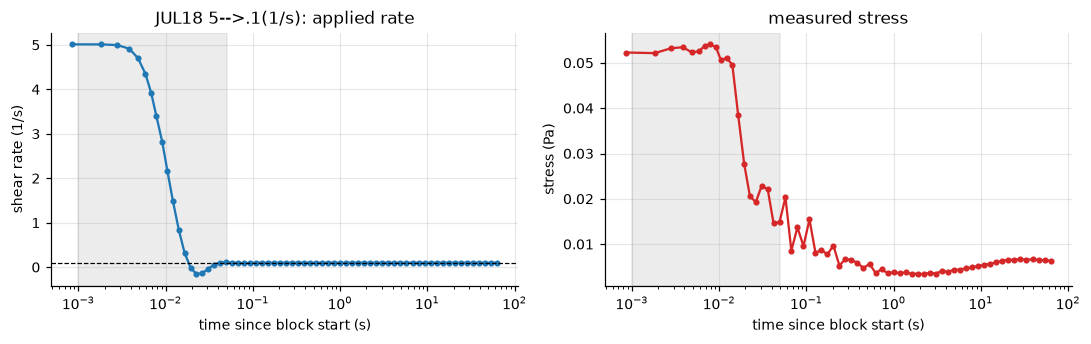

In [15]:
ex = next(b for b in blocks if b["sample"] == "JUL18" and b["label"].startswith("5-->.1"))
d = ex["data"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].semilogx(d.time, d.shear_rate, "o-", ms=3); ax[0].axhline(ex["rate_to"], color="k", lw=0.8, ls="--")
ax[0].set(xlabel="time since block start (s)", ylabel="shear rate (1/s)", title=f'{ex["sample"]} {ex["label"]}: applied rate')
ax[1].semilogx(d.time, d.stress, "o-", ms=3, color="C3")
ax[1].set(xlabel="time since block start (s)", ylabel="stress (Pa)", title="measured stress")
for a in ax: a.axvspan(1e-3, MIN_INSTRUMENT_WINDOW, color="grey", alpha=0.15)
fig.tight_layout(); fig.savefig(FIG / "01_raw_step_block.png", dpi=200); plt.show()

In [16]:
def verify_step(b):
    d = b["data"]; t = d.time.values
    g0_lab, g1_lab = b["rate_from"], b["rate_to"]
    res = dict(step_id=b["step_id"])
    if "shear_rate" not in d or d.shear_rate.isna().all():
        # no rate channel: time is zeroed at the step, so t_step = 0 and the instrument window is the minimum
        res.update(rate_from_meas=np.nan, rate_to_meas=np.nan, has_pre_step=False, t_step=0.0,
                   t_rate_settle=MIN_INSTRUMENT_WINDOW, rate_overshoot_frac=np.nan,
                   qc_rate="label only (no shear-rate channel)")
        return res
    g = d.shear_rate.values
    g1 = np.nanmedian(g[t >= 1.0])
    has_pre = t[0] < 0.004 and abs(g[0] - g1) > 0.3 * abs(g1_lab - g0_lab)
    g0 = np.nanmedian(g[:3]) if has_pre else g0_lab
    half = g0 + 0.5 * (g1 - g0)
    moved = np.where(np.sign(g1 - g0) * (g - half) > 0)[0]
    t_step = t[moved[0]] if has_pre and len(moved) else 0.005     # median observed value when not measurable
    tol = np.maximum(RATE_SETTLE_TOL * abs(g1), 0.01)
    bad = np.where(np.abs(g - g1) > tol)[0]
    t_rs = t[bad[-1] + 1] if len(bad) and bad[-1] + 1 < len(t) else t[0]
    after = g[t > t_step]
    excess = (np.max(after) - g1) if g1 > g0 else (g1 - np.min(after))
    ok0 = has_pre and abs(g0 / g0_lab - 1) <= RATE_TOL
    ok1 = abs(g1 / g1_lab - 1) <= RATE_TOL
    res.update(rate_from_meas=g0, rate_to_meas=g1, has_pre_step=has_pre, t_step=t_step,
               t_rate_settle=max(t_rs, MIN_INSTRUMENT_WINDOW), rate_overshoot_frac=excess / abs(g1 - g0),
               qc_rate=("ok" if ok0 and ok1 else
                        "final ok, initial from label (no pre-step samples)" if ok1 and not has_pre else
                        "MISMATCH with label"))
    return res

ev = inv.merge(pd.DataFrame([verify_step(b) for b in blocks]), on="step_id")
ev["ratio"] = ev.rate_to / ev.rate_from
ev["log10_ratio"] = np.log10(ev.ratio)
ev["direction"] = np.where(ev.ratio > 1, "up", "down")
ev["magnitude_abs"] = (ev.rate_to - ev.rate_from).abs()

print(ev.qc_rate.value_counts().to_string())
cols = ["step_id", "sample", "sheet", "label", "storage_h", "rate_from", "rate_to", "rate_from_meas", "rate_to_meas",
        "direction", "log10_ratio", "t_step", "t_rate_settle", "rate_overshoot_frac", "qc_rate"]
ev[cols].to_csv(OUT / "step_events.csv", index=False)
ev[cols].head(12)

qc_rate
ok                                                    127
final ok, initial from label (no pre-step samples)      6
MISMATCH with label                                     3


,step_id,sample,sheet,label,storage_h,rate_from,rate_to,rate_from_meas,rate_to_meas,direction,log10_ratio,t_step,t_rate_settle,rate_overshoot_frac,qc_rate
0,S001,12FEB20,Steps,10-->.1,0.0,10.0,0.1,9.986000,0.100012,down,-2.000000,0.010504,0.057501,0.052045,ok
1,S002,12FEB20,Steps,300--> 20(1/s),0.0,300.0,20.0,300.026000,20.002400,down,-1.176091,0.014173,0.050000,0.036953,ok
2,S003,12FEB20,Steps,300-->5,0.0,300.0,5.0,300.020000,5.000600,down,-1.778151,0.014161,0.067170,0.036195,ok
3,S004,12FEB20,Steps,300-->10,0.0,300.0,10.0,300.023000,10.001200,down,-1.477121,0.014167,0.050000,0.036517,ok
4,S005,12FEB20,Steps,5-->.1(1/s),0.0,5.0,0.1,5.027830,0.100012,down,-1.698970,0.010497,0.092498,0.052133,ok
5,S006,12FEB20,Steps,20-->.1,0.0,20.0,0.1,19.957000,0.100012,down,-2.301030,0.010479,0.057476,0.052000,ok
6,S007,12FEB20,Steps,300-->.1,0.0,300.0,0.1,300.026000,0.100012,down,-3.477121,0.013355,0.103016,0.038982,ok
7,S008,12FEB20,Steps,.1-->5,0.0,0.1,5.0,0.101051,5.000605,up,1.698970,0.010661,0.050000,0.050673,ok
8,S009,12FEB20,Steps,.1-->10,0.0,0.1,10.0,0.102100,10.001200,up,2.000000,0.010492,0.050000,0.050560,ok
9,S010,12FEB20,Steps,.1-->20,0.0,0.1,20.0,0.105109,20.002400,up,2.301030,0.010490,0.050000,0.053203,MISMATCH with label


In [17]:
bad = ev[ev.qc_rate.str.startswith("MISMATCH")]
print(f"{len(bad)} blocks disagree with their label:")
bad[cols]

3 blocks disagree with their label:


,step_id,sample,sheet,label,storage_h,rate_from,rate_to,rate_from_meas,rate_to_meas,direction,log10_ratio,t_step,t_rate_settle,rate_overshoot_frac,qc_rate
9,S010,12FEB20,Steps,.1-->20,0.0,0.1,20.0,0.105109,20.002400,up,2.30103,0.010490,0.05,0.053203,MISMATCH with label
23,S024,14MAR19,Steps,.1-->10,0.0,0.1,10.0,-0.301885,10.001200,up,2.00000,0.014169,0.05,0.040367,MISMATCH with label
44,S045,APR18,steps,5-->0.1,0.0,5.0,0.1,5.005830,0.500059,down,-1.69897,0.010505,0.05,0.051908,MISMATCH with label


In [18]:
ev.groupby("direction")[["t_step", "t_rate_settle", "rate_overshoot_frac"]].describe(percentiles=[.5]).round(3)

t_step                                    t_rate_settle                                  rate_overshoot_frac                                   
           count   mean    std    min    50%    max         count   mean    std   min   50%    max               count   mean    std    min    50%    max
direction                                                                                                                                                
down        69.0  0.011  0.002  0.005  0.011  0.014          69.0  0.068  0.022  0.05  0.05  0.108                69.0  0.046  0.008  0.035  0.051  0.053
up          67.0  0.011  0.000  0.010  0.010  0.014          67.0  0.055  0.017  0.05  0.05  0.108                67.0  0.052  0.003  0.040  0.052  0.061

In [19]:
def window(d, t0, t1):
    return d[(d.time >= t0) & (d.time <= t1)]

noise = []
for b in blocks:
    w = window(b["data"], STABLE_START, np.inf)
    if len(w) >= 4:
        x = np.log10(w.time.values); y = w.stress.values
        resid = y - np.polyval(np.polyfit(x, y, 1), x)
        noise.append(dict(step_id=b["step_id"], high_res=b["high_res"], resid_sd=np.std(resid, ddof=2),
                          stable_level=np.median(y)))
noise = pd.DataFrame(noise)
print(noise.groupby("high_res").resid_sd.describe(percentiles=[.5, .9]).round(5).to_string())
print(f"\nConfigured NOISE_PA = {NOISE_PA} Pa")

          count     mean      std      min      50%      90%      max
high_res                                                             
False     125.0  0.00056  0.00199  0.00001  0.00010  0.00106  0.02045
True        6.0  0.00387  0.00084  0.00271  0.00381  0.00479  0.00482

Configured NOISE_PA = 0.001 Pa


In [20]:
ref_grid = next(b for b in blocks if not b["high_res"])["data"].time.values
edges = np.sqrt(ref_grid[1:] * ref_grid[:-1]); edges = np.r_[ref_grid[0] / 1.2, edges, ref_grid[-1] * 1.2]

def log_bin(d):
    idx = np.digitize(d.time.values, edges) - 1
    g = d.assign(bin=idx).groupby("bin").mean(numeric_only=True)
    return g[g.index.isin(range(len(ref_grid)))].reset_index(drop=True)

for b in blocks:
    b["an"] = log_bin(b["data"]) if b["high_res"] else b["data"]   # 'analysis' series
print("high-res blocks after binning:", [len(b["an"]) for b in blocks if b["high_res"]])

high-res blocks after binning: [47, 47, 47, 47, 47, 47]


In [21]:
def windows_for(b, e, t_trans_end=TRANSIENT_END, t_stable_start=STABLE_START):
    d = b["an"]
    wt = window(d, e.t_rate_settle, t_trans_end)
    ws = window(d, t_stable_start, np.inf)
    s_stable = np.median(ws.stress) if len(ws) else np.nan
    if len(ws) >= 3:
        x = np.log10(ws.time.values)
        slope = np.polyfit(x, ws.stress.values, 1)[0]
        drift = slope * (x[-1] - x[0])
    else:
        drift = np.nan
    drift_frac = abs(drift) / max(abs(s_stable), NOISE_PA) if np.isfinite(drift) else np.nan
    return dict(n_transient=len(wt), n_stable=len(ws), sigma_stable=s_stable, stable_drift_Pa=drift,
                stable_drift_frac=drift_frac,
                stable_ok=bool(np.isfinite(drift_frac) and (drift_frac <= STABLE_MAX_DRIFT or abs(drift) <= NOISE_PA)),
                below_noise=bool(abs(s_stable) < 3 * NOISE_PA))

evi = ev.set_index("step_id")
win = pd.DataFrame([dict(step_id=b["step_id"], **windows_for(b, evi.loc[b["step_id"]])) for b in blocks])
ev = ev.drop(columns=[c for c in win.columns if c != "step_id" and c in ev], errors="ignore").merge(win, on="step_id")
ev[["step_id", "sample", "label", "n_transient", "n_stable", "sigma_stable", "stable_drift_frac",
    "stable_ok", "below_noise"]].to_csv(OUT / "step_windows.csv", index=False)

print(f"Defensible stable state reached: {ev.stable_ok.sum()} / {len(ev)} measurements")
print(f"Stable stress within 3x noise floor: {ev.below_noise.sum()}")
ev.assign(final_rate=ev.rate_to).groupby(["direction", "final_rate"]).stable_ok.agg(["mean", "size"]).round(2).T

Defensible stable state reached: 118 / 136 measurements
Stable stress within 3x noise floor: 0


direction    down                                              up                                      
final_rate  0.10  0.25  0.50  1.00  2.50  5.00  10.00 20.00 0.25  0.50   1.00   2.50  5.00  10.00 20.00
mean         0.57   1.0  0.83   1.0   1.0  0.83   1.0   1.0  0.83   1.0   0.91   0.92   1.0  0.75   1.0
size        28.00   6.0  6.00   7.0   7.0  6.00   5.0   4.0  6.00  12.0  11.00  12.00  18.0  4.00   4.0

In [22]:
def features(b, e):
    d = b["an"]; t = d.time.values; s = d.stress.values
    fc = flow_curve_for(b["workbook"], b["storage_h"])
    ss = e.sigma_stable
    m = t >= e.t_rate_settle
    tm, sm = t[m], s[m]
    pre = s[t < 0.5 * e.t_step] if e.has_pre_step else np.array([])
    f = dict(step_id=b["step_id"])
    f["sigma_pre"] = np.median(pre) if len(pre) else np.nan
    f["sigma_pre_fc"] = flow_stress(fc, e.rate_from)
    f["sigma_final_fc"] = flow_stress(fc, e.rate_to)
    f["sigma_imm"] = sm[0]
    i_pk, i_mn = np.argmax(sm), np.argmin(sm)
    f.update(sigma_peak=sm[i_pk], t_peak=tm[i_pk], sigma_min=sm[i_mn], t_min=tm[i_mn])
    denom = abs(ss) if abs(ss) > NOISE_PA else np.nan
    f["overshoot"] = (sm[i_pk] - ss) / denom
    f["undershoot"] = (ss - sm[i_mn]) / denom
    f["jump_signed"] = (sm[0] - ss) / denom
    f["relax_amp"] = sm[0] - ss
    early = (tm <= 1.0)
    f["init_slope"] = (np.polyfit(np.log10(tm[early]), sm[early] / denom, 1)[0]
                       if early.sum() >= 3 and np.isfinite(denom) else np.nan)
    outside = np.where(np.abs(sm - ss) > max(SETTLE_BAND * abs(ss), NOISE_PA))[0]
    if len(outside) == 0:
        f["settling_time"] = tm[0]
    elif outside[-1] + 1 < len(tm) and tm[outside[-1] + 1] < STABLE_START:
        f["settling_time"] = tm[outside[-1] + 1]
    else:
        f["settling_time"] = np.nan
    f["area_log"] = trapezoid((sm - ss) / denom, np.log(tm))
    f["plateau_vs_fc"] = ss / f["sigma_final_fc"]
    f["baseline_vs_fc"] = f["sigma_pre"] / f["sigma_pre_fc"]
    f["visc_ratio"] = ((ss / e.rate_to) / (f["sigma_pre"] / e.rate_from)
                       if len(pre) and abs(f["sigma_pre"]) >= 3 * NOISE_PA else np.nan)   # baseline must exceed noise
    return f

evs = ev.set_index("step_id")
feat = pd.DataFrame([features(b, evs.loc[b["step_id"]]) for b in blocks])
steps = ev.merge(feat, on="step_id")
FEATURES = ["jump_signed", "overshoot", "undershoot", "init_slope", "settling_time", "t_peak", "t_min",
            "area_log", "relax_amp", "visc_ratio"]
steps.to_csv(OUT / "step_features.csv", index=False)
steps[["step_id", "sample", "label", "direction", "sigma_pre", "sigma_imm", "sigma_stable"] + FEATURES].head(10).round(4)

,step_id,sample,label,direction,sigma_pre,sigma_imm,sigma_stable,jump_signed,overshoot,undershoot,init_slope,settling_time,t_peak,t_min,area_log,relax_amp,visc_ratio
0,S001,12FEB20,10-->.1,down,0.0753,-0.0001,0.0038,-1.0185,3.1282,1.0185,-1.4482,10.9058,0.0788,0.0575,-1.6468,-0.0039,5.0993
1,S002,12FEB20,300--> 20(1/s),down,1.1957,0.1179,0.1270,-0.0719,0.1538,0.1288,0.1948,3.0460,0.5280,0.0787,0.3790,-0.0091,1.5930
2,S003,12FEB20,300-->5,down,1.1682,0.0626,0.0532,0.1770,0.7168,0.3870,0.3299,NaN,45.7985,0.0787,0.3502,0.0094,2.7317
3,S004,12FEB20,300-->10,down,1.2008,0.0782,0.0759,0.0305,0.2750,0.2771,0.3144,20.6357,1.1707,0.0787,0.7800,0.0023,1.8955
4,S005,12FEB20,5-->.1(1/s),down,0.0474,0.0045,0.0042,0.0770,1.0279,0.6520,-1.2583,10.9058,0.1083,1.3735,-1.1801,0.0003,4.4142
5,S006,12FEB20,20-->.1,down,0.1279,0.0076,0.0040,0.8879,2.1480,1.1684,-1.6144,12.7908,0.0788,0.0925,-2.7370,0.0036,6.2981
6,S007,12FEB20,300-->.1,down,1.1575,0.0024,NaN,NaN,NaN,NaN,NaN,0.1030,0.1195,0.1030,NaN,NaN,NaN
7,S008,12FEB20,.1-->5,up,0.0087,0.0678,0.0463,0.4658,0.7185,0.0250,-0.0127,15.0013,0.2035,53.7155,2.1944,0.0216,0.1063
8,S009,12FEB20,.1-->10,up,-0.0008,0.1040,0.0753,0.3821,0.7546,0.0281,-0.3532,NaN,15.0012,63.0007,1.9765,0.0288,NaN
9,S010,12FEB20,.1-->20,up,0.0096,0.2123,0.1253,0.6951,0.6951,0.0083,-0.5800,0.8513,0.0575,33.2933,1.2348,0.0871,0.0654


       baseline_vs_fc  plateau_vs_fc
count          130.00         131.00
mean             1.37           1.31
std              1.17           0.48
min             -1.53           0.53
10%              0.52           1.01
50%              1.07           1.13
90%              2.60           2.00
max              8.89           4.38


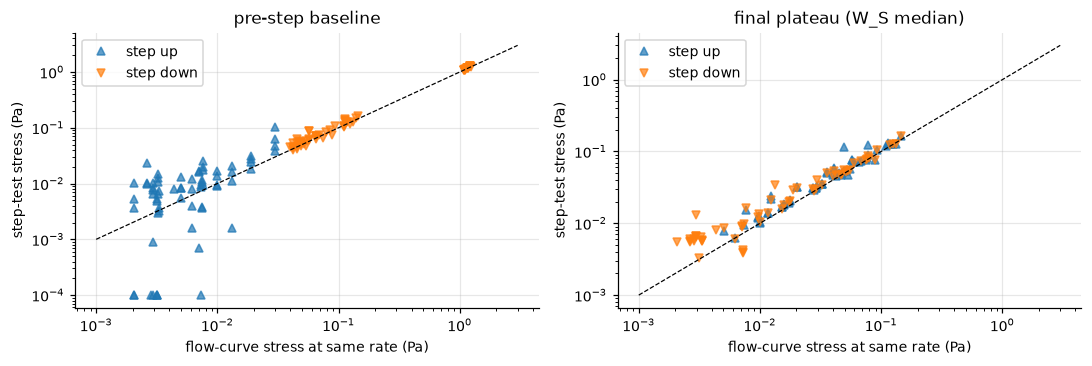

In [23]:
chk = steps[["baseline_vs_fc", "plateau_vs_fc"]].replace([np.inf, -np.inf], np.nan)
print(chk.describe(percentiles=[.1, .5, .9]).round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, (col, ref, ttl) in zip(ax, [("sigma_pre", "sigma_pre_fc", "pre-step baseline"),
                                   ("sigma_stable", "sigma_final_fc", "final plateau (W_S median)")]):
    for dirn, mk in [("up", "^"), ("down", "v")]:
        q = steps[steps.direction == dirn]
        a.loglog(q[ref], q[col].clip(lower=1e-4), mk, ms=5, alpha=0.7, label=f"step {dirn}")
    lim = [1e-3, 3]; a.plot(lim, lim, "k--", lw=0.8)
    a.set(xlabel="flow-curve stress at same rate (Pa)", ylabel="step-test stress (Pa)", title=ttl); a.legend()
fig.tight_layout(); fig.savefig(FIG / "02_baseline_plateau_vs_flowcurve.png", dpi=200); plt.show()

In [24]:
def exp_model(t, s_inf, A, tau):
    return s_inf + A * np.exp(-t / tau)

def fit_exponential(b, e):
    d = b["an"]; m = d.time >= e.t_rate_settle
    t = d.time.values[m] - e.t_step; y = d.stress.values[m]
    rec = dict(step_id=b["step_id"], model="exponential")
    try:
        p0 = [np.median(y[-5:]), y[0] - np.median(y[-5:]), 1.0]
        p, cov = curve_fit(exp_model, t, y, p0=p0, bounds=([-np.inf, -np.inf, 0.01], [np.inf, np.inf, 200]), maxfev=20000)
        yhat = exp_model(t, *p); r2 = 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)
        se = np.sqrt(np.diag(cov))[2] if np.all(np.isfinite(cov)) else np.inf
        reasons = []
        if p[2] <= 0.0101 or p[2] >= 199: reasons.append("tau at bound")
        if not np.isfinite(se) or 1.96 * se > p[2]: reasons.append("tau CI wider than tau")
        if r2 < 0.5: reasons.append("R2 < 0.5")
        rec.update(s_inf=p[0], amp=p[1], tau=p[2], tau_se=se, r2=r2, rmse=np.sqrt(np.mean((y - yhat) ** 2)),
                   status="ok" if not reasons else "not interpretable", reason="; ".join(reasons))
    except Exception as err:
        rec.update(status="failed", reason=type(err).__name__)
    return rec

evs = ev.set_index("step_id")
fits_exp = pd.DataFrame([fit_exponential(b, evs.loc[b["step_id"]]) for b in blocks])
print(fits_exp.status.value_counts().to_string())
fits_exp.merge(ev[["step_id", "direction", "rate_from", "rate_to"]]).groupby(["direction", "rate_to"]).status.agg(
    lambda s: f"{(s == 'ok').sum()}/{len(s)} ok").unstack(0).fillna("")

status
not interpretable    69
ok                   67


direction,down,up
rate_to,,
0.10,14/28 ok,
0.25,2/6 ok,1/6 ok
0.50,2/6 ok,4/12 ok
1.00,0/7 ok,3/11 ok
2.50,3/7 ok,3/12 ok
5.00,5/6 ok,18/18 ok
10.00,2/5 ok,4/4 ok
20.00,2/4 ok,4/4 ok


In [25]:
from scipy.integrate import solve_ivp

def lam_ss(g, tr1, tr2):                                   # Eq. 16
    g = np.abs(g); return (tr2 * g ** D_EXP + 1) / (tr1 * g + tr2 * g ** D_EXP + 1)

def sigma_ss(g, p):                                        # Eq. 10
    sy, eta_st, eta_inf, tr1, tr2 = p[:5]
    lam = lam_ss(g, tr1, tr2); return lam * sy + (lam * eta_st + eta_inf) * g

def simulate_step(t_eval, g0, g1, t_step, p):
    """ethixo-EVP version 1: Eq. 11 (n = 1) for stress and Eq. 13 for structure, driven by the plastic rate.
    Starts from steady state at the initial rate g0; the rate switches to g1 at t_step."""
    sy, eta_st, eta_inf, tr1, tr2, G, k_lam = p
    def rhs(t, z):
        s, lam = z
        g = g1 if t >= t_step else g0
        gp = max(0.0, abs(s) - lam * sy) / (lam * eta_st + eta_inf) * np.sign(s)     # plastic shear rate
        agp = abs(gp)
        return [G * (g - gp), k_lam * (-tr1 * agp * lam + tr2 * agp ** D_EXP * (1 - lam) + (1 - lam))]
    z0 = [sigma_ss(g0, p), lam_ss(g0, tr1, tr2)]
    sol = solve_ivp(rhs, (0, t_eval[-1]), z0, t_eval=t_eval, method="LSODA", rtol=1e-6, atol=[1e-8, 1e-8],
                    first_step=1e-5, max_step=t_eval[-1] / 20)
    if not sol.success or sol.y.shape[1] != len(t_eval):
        return np.full(len(t_eval), np.nan), np.full(len(t_eval), np.nan)
    return sol.y[0], sol.y[1]

def step_series(b, e):
    """Stress after the instrument window, with time measured from the step."""
    d = b["an"]; m = d.time >= e.t_rate_settle
    return d.time.values[m] - e.t_step, d.stress.values[m]

#                  sigma_y0  eta_ST  eta_inf  tr1   tr2    G     k_lambda
LOW = np.log([1e-6, 1e-4, 1e-4, 1e-3, 1e-4, 1e-3, 1e-3])
HIGH = np.log([1.0, 1.0, 0.05, 1e3, 1e3, 1e2, 1e2])
P_LIT = np.array([0.003, 0.02, 0.003, 0.5, 0.2, 0.3, 1.0])   # start near the papers' reported values

def fit_steady(x, y):
    """Stage 1 (initial guess, as in the papers): Eq. 17 relative cost on the flow curve only."""
    r = least_squares(lambda q: (y - sigma_ss(x, np.exp(q))) / y, np.log(P_LIT[:5]), bounds=(LOW[:5], HIGH[:5]))
    return np.exp(r.x)

def joint_residuals(q, x, y, series):
    """Stage 2: least-squares form of Frontiers Eq. 12 -- flow-curve residuals normalised point-wise, each step's
    residuals by that step's maximum stress, and every experiment weighted equally."""
    p = np.exp(q)
    r = [(y - sigma_ss(x, p)) / y / np.sqrt(len(y))]
    for t, s, g0, g1, ts in series:
        f, _ = simulate_step(t, g0, g1, ts, p)
        rr = (s - f) / np.max(np.abs(s)) / np.sqrt(len(s) * len(series))
        r.append(np.where(np.isfinite(rr), rr, 10.0))           # solver failure -> large penalty
    return np.concatenate(r)

model_rows, model_curves = [], {}
for (wb, sh), grp in ev[ev.qc_rate != "MISMATCH with label"].groupby(["workbook", "storage_h"]):
    fc = flow_curve_for(wb, sh)
    if fc is None: continue
    x, y = fc["rate"][fc["stress"] > 0], fc["stress"][fc["stress"] > 0]
    ser = []
    for sid in grp.step_id:
        e = evs.loc[sid]; d = next(b for b in blocks if b["step_id"] == sid)["an"]
        m = d.time >= e.t_rate_settle
        ser.append((d.time.values[m], d.stress.values[m], e.rate_from, e.rate_to, e.t_step))
    best = None
    for st in (np.r_[fit_steady(x, y), P_LIT[5:]], P_LIT):
        r = least_squares(joint_residuals, np.log(st), args=(x, y, ser), bounds=(LOW, HIGH), max_nfev=300)
        if best is None or r.cost < best.cost: best = r
    p = np.exp(best.x)
    # conditional profile of k_lambda (other parameters held at the optimum): k values within 10 % of the minimum cost
    grid = np.exp(np.linspace(LOW[6], HIGH[6], 41))
    prof = np.array([np.sum(joint_residuals(np.log(np.r_[p[:6], kk]), x, y, ser) ** 2) for kk in grid])
    within = grid[prof <= prof.min() * 1.10]
    per = []
    for sid, (t, s, g0, g1, ts) in zip(grp.step_id, ser):
        f, lam = simulate_step(t, g0, g1, ts, p)
        nrmse = np.sqrt(np.mean(((s - f) / np.max(np.abs(s))) ** 2))
        per.append(dict(step_id=sid, nrmse_model=nrmse,
                        fit_threshold=max(MODEL_MAX_NRMSE, 2 * NOISE_PA / np.max(np.abs(s))),
                        tau_eff=1 / (p[6] * (p[3] * g1 + p[4] * g1 ** D_EXP + 1))))
        model_curves[sid] = (t - ts, f, lam)
    per = pd.DataFrame(per).set_index("step_id")
    sel = steps.step_id.isin(per.index)
    for c in per.columns:
        steps.loc[sel, c] = steps.loc[sel, "step_id"].map(per[c]).values
    rss = np.sum(best.fun ** 2); n = len(best.fun); k_par = 7
    model_rows.append(dict(workbook=wb, sample=grp["sample"].iloc[0], storage_h=sh, n_steps=len(ser),
                           sigma_y0=p[0], eta_ST=p[1], eta_inf=p[2], tr1=p[3], tr2=p[4], G=p[5], k_lambda=p[6],
                           tau_lambda=1 / p[6], tau_lambda_lo=1 / within.max(), tau_lambda_hi=1 / within.min(),
                           Fcost_ss=np.sqrt(np.mean(((y - sigma_ss(x, p)) / y) ** 2)),
                           median_step_nrmse=per.nrmse_model.median(),
                           steps_fitted_ok=f"{(per.nrmse_model <= per.fit_threshold).sum()}/{len(per)}",
                           AIC=n * np.log(rss / n) + 2 * k_par, BIC=n * np.log(rss / n) + k_par * np.log(n),
                           k_at_bound=bool(best.x[6] <= LOW[6] + 0.05 or best.x[6] >= HIGH[6] - 0.05)))

models = pd.DataFrame(model_rows)
models.to_csv(OUT / "relaxation_fits.csv", index=False)
models.drop(columns="workbook").round(4)

,sample,storage_h,n_steps,sigma_y0,eta_ST,eta_inf,tr1,tr2,G,k_lambda,tau_lambda,tau_lambda_lo,tau_lambda_hi,Fcost_ss,median_step_nrmse,steps_fitted_ok,AIC,BIC,k_at_bound
0,12FEB20,0.0,9,0.0033,0.0273,0.0029,1.3678,0.7625,0.3425,0.7294,1.3710,0.4217,3.1623,0.0929,0.1576,3/9,-3708.1183,-3679.9882,False
1,14DEC,0.0,5,0.0006,0.0271,0.0038,0.5376,0.0289,0.2855,10.5402,0.0949,0.0316,0.1778,0.0656,0.1646,0/5,-2074.0932,-2049.9060,False
2,14MAR19,0.0,9,0.0009,0.0074,0.0033,0.0824,0.0001,0.2477,5.1039,0.1959,0.0422,1.3335,0.1439,0.1584,3/9,-3580.7985,-3552.7197,False
3,27FEB19,0.0,10,0.0018,0.0171,0.0032,0.3978,0.1341,0.2468,2.6696,0.3746,0.1778,0.7499,0.0655,0.1138,5/10,-4474.6099,-4445.7987,False
4,9MAY19,0.0,9,0.0054,0.0255,0.0024,1.0406,1.0476,0.3071,0.6180,1.6180,1.3335,2.3714,0.0676,0.0874,6/9,-4024.8559,-3996.7770,False
5,APR18,0.0,6,0.0070,0.0806,0.0050,1.4677,0.4964,0.4703,2.3467,0.4261,0.3162,0.5623,0.0329,0.0785,6/6,-3041.0776,-3015.4856,False
6,FEB18,0.0,10,0.0000,0.0525,0.0035,1.4798,0.3514,0.3204,6.1192,0.1634,0.0562,0.4217,0.0656,0.1240,3/10,-4592.7863,-4563.8983,False
7,JUL18,0.0,14,0.0000,0.0398,0.0033,2.2969,0.6612,0.1918,1.0849,0.9217,0.3162,2.3714,0.0624,0.1207,5/14,-6482.6396,-6451.4642,False
8,JUN18,0.0,14,0.0000,0.0225,0.0032,0.7241,0.1294,0.1891,1.5595,0.6412,0.1000,1.7783,0.0793,0.1162,6/14,-6326.4698,-6295.2614,False
9,NOV18,0.0,6,0.0008,0.0218,0.0035,0.4386,0.0494,0.2573,4.1936,0.2385,0.1000,0.7499,0.0529,0.1373,1/6,-2615.5701,-2590.1516,False


In [26]:
fails = pd.concat([
    fits_exp[fits_exp.status != "ok"].merge(ev[["step_id", "sample", "label"]])[["step_id", "sample", "label", "model", "status", "reason"]],
    steps[steps.nrmse_model > steps.fit_threshold].assign(model="ethixo-EVP", status="poor fit",
                                       reason=lambda x: "NRMSE = " + x.nrmse_model.round(3).astype(str))[
        ["step_id", "sample", "label", "model", "status", "reason"]],
    models[models.k_at_bound].assign(step_id="(all)", label="(workbook)", model="ethixo-EVP",
                                     status="k_lambda at bound", reason="not identifiable")[
        ["step_id", "sample", "label", "model", "status", "reason"]]])
fails.to_csv(OUT / "fit_failure_log.csv", index=False)
print(f"{len(fails)} entries in the failure log")
fails.groupby(["model", "status"]).size()

150 entries in the failure log


model        status           
ethixo-EVP   poor fit             81
exponential  not interpretable    69
dtype: int64

tau_lambda (this data): median 0.64 s, IQR 0.24-1.19 s  (n = 13 workbook x storage fits, 11 workbooks)
   literature: 1.13 +- 0.24 s (Frontiers 2022, 12 donors); 0.55-0.96 s (Sci. Rep. 2021, Donor 1)
   fits within literature mean +- 2 SD: 4 / 13
G (this data): median 0.286 Pa, range 0.189-0.470 Pa;  literature: G = 0.29 Pa (same model, JNNFM 2021), G_R = 0.15 +- 0.05 Pa (t-ESSTV, Frontiers 2022)
steps fitted within threshold: 52 / 133

fit quality by final shear rate (median NRMSE):
direction   down     up
rate_to                
0.10       0.192    NaN
0.25       0.167  0.205
0.50       0.122  0.202
1.00       0.090  0.119
2.50       0.044  0.104
5.00       0.135  0.114
10.00      0.077  0.071
20.00      0.052  0.079


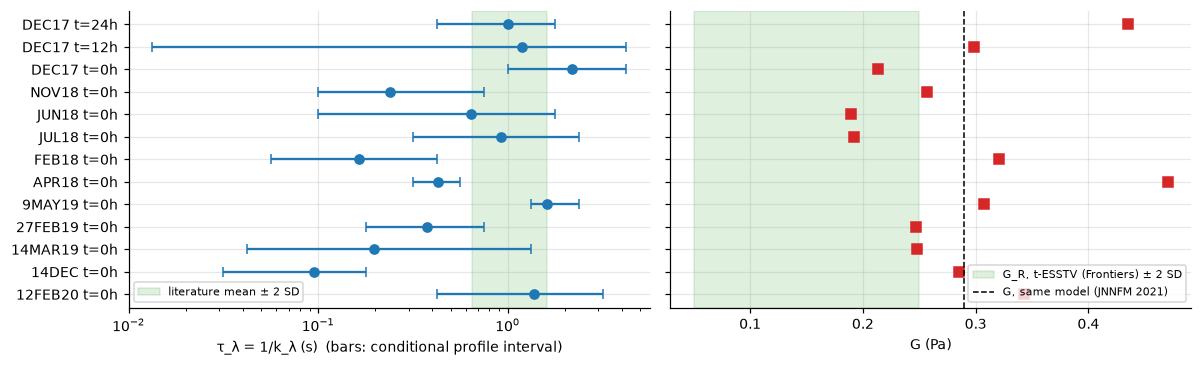

In [27]:
mu, sd = TAU_LAMBDA_LIT
okm = models[~models.k_at_bound]
print(f"tau_lambda (this data): median {okm.tau_lambda.median():.2f} s, IQR {okm.tau_lambda.quantile(.25):.2f}-"
      f"{okm.tau_lambda.quantile(.75):.2f} s  (n = {len(okm)} workbook x storage fits, {okm['sample'].nunique()} workbooks)")
print(f"   literature: {mu} +- {sd} s (Frontiers 2022, 12 donors); 0.55-0.96 s (Sci. Rep. 2021, Donor 1)")
print(f"   fits within literature mean +- 2 SD: {((okm.tau_lambda - mu).abs() <= 2 * sd).sum()} / {len(okm)}")
print(f"G (this data): median {okm.G.median():.3f} Pa, range {okm.G.min():.3f}-{okm.G.max():.3f} Pa"
      f";  literature: G = {G_LIT_V1} Pa (same model, JNNFM 2021), G_R = {G_LIT_R[0]} +- {G_LIT_R[1]} Pa (t-ESSTV, Frontiers 2022)")
print(f"steps fitted within threshold: {(steps.nrmse_model <= steps.fit_threshold).sum()} / {steps.nrmse_model.notna().sum()}")
print("\nfit quality by final shear rate (median NRMSE):")
print(steps.groupby(["direction", "rate_to"]).nrmse_model.median().unstack(0).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
yy = np.arange(len(models)); names = [f'{s_} t={int(h)}h' for s_, h in zip(models["sample"], models.storage_h)]
ax[0].errorbar(models.tau_lambda, yy, xerr=[models.tau_lambda - models.tau_lambda_lo, models.tau_lambda_hi - models.tau_lambda],
               fmt="o", capsize=3)
ax[0].axvspan(mu - 2 * sd, mu + 2 * sd, color="C2", alpha=0.15, label="literature mean ± 2 SD")
ax[0].set(xscale="log", xlabel="τ_λ = 1/k_λ (s)  (bars: conditional profile interval)"); ax[0].legend(loc="lower left", fontsize=7)
ax[1].plot(models.G, yy, "s", color="C3")
ax[1].axvspan(G_LIT_R[0] - 2 * G_LIT_R[1], G_LIT_R[0] + 2 * G_LIT_R[1], color="C2", alpha=0.15, label="G_R, t-ESSTV (Frontiers) ± 2 SD")
ax[1].axvline(G_LIT_V1, color="k", ls="--", lw=1, label="G, same model (JNNFM 2021)")
ax[1].set(xlabel="G (Pa)"); ax[1].legend(loc="lower right", fontsize=7)
ax[0].set_yticks(yy, names)
fig.tight_layout(); fig.savefig(FIG / "03_tau_lambda_vs_literature.png", dpi=200); plt.show()

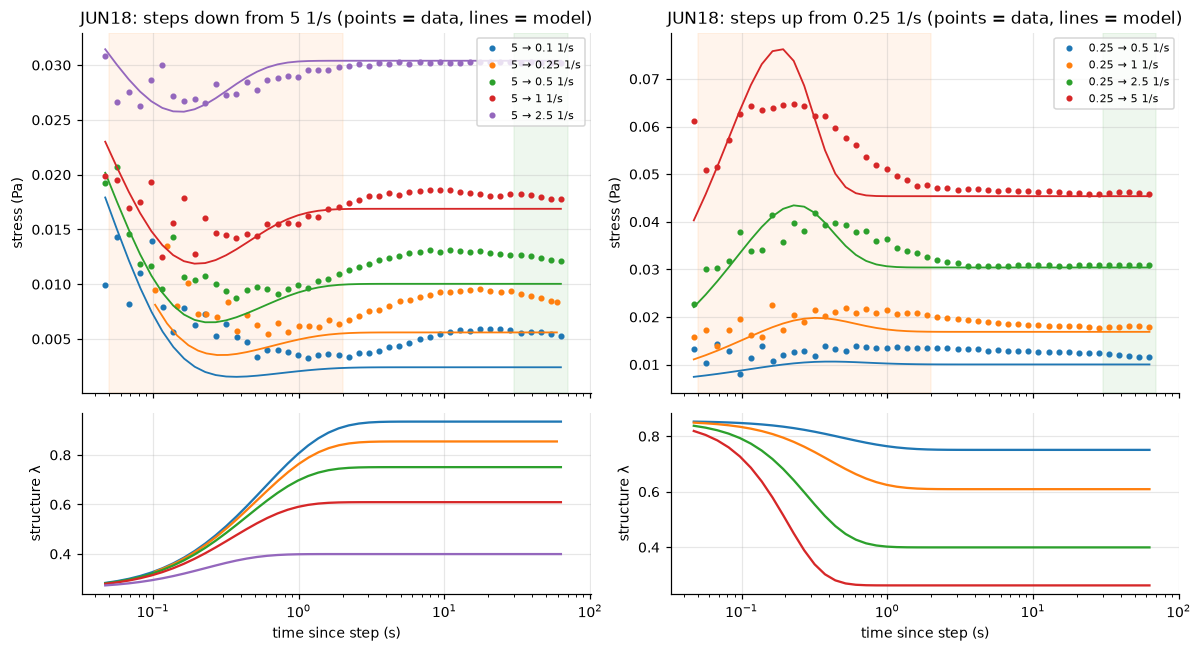

In [28]:
def plot_family(sample, storage_h=0.0, start_down=5.0, start_up=0.25, fname="04_representative_fits.png"):
    q = steps[(steps["sample"] == sample) & (steps.storage_h == storage_h)]
    fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    for col, (dirn, g0) in enumerate([("down", start_down), ("up", start_up)]):
        sub = q[(q.direction == dirn) & np.isclose(q.rate_from, g0)].sort_values("rate_to")
        for i, (_, r) in enumerate(sub.iterrows()):
            b = next(bb for bb in blocks if bb["step_id"] == r.step_id)
            t, y = step_series(b, r)
            ax[0, col].semilogx(t, y, "o", ms=3, color=f"C{i}", label=f"{g0:g} → {r.rate_to:g} 1/s")
            if r.step_id in model_curves:
                tm, fm, lam = model_curves[r.step_id]
                ax[0, col].semilogx(tm, fm, "-", color=f"C{i}", lw=1.2)
                ax[1, col].semilogx(tm, lam, "-", color=f"C{i}")
        ax[0, col].axvspan(0.05, TRANSIENT_END, color="C1", alpha=0.08); ax[0, col].axvspan(STABLE_START, 70, color="C2", alpha=0.08)
        ax[0, col].set(title=f"{sample}: steps {dirn} from {g0:g} 1/s (points = data, lines = model)", ylabel="stress (Pa)")
        ax[0, col].legend(fontsize=7); ax[1, col].set(xlabel="time since step (s)", ylabel="structure λ")
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=200); plt.show()

plot_family("JUN18")

In [29]:
A = steps[steps.qc_rate != "MISMATCH with label"].copy()
A["unit"] = A["sample"] + "_t" + A.storage_h.astype(int).astype(str)     # workbook x storage time
print(f"analysis set: {len(A)} steps, {A['sample'].nunique()} workbooks (independent units), {A.unit.nunique()} workbook x storage units")

def sign_test(x):
    x = np.asarray(x)[np.isfinite(x) & (np.asarray(x) != 0)]
    if len(x) == 0: return np.nan, 0, 0
    k = (x > 0).sum(); return stats.binomtest(k, len(x), 0.5).pvalue, k, len(x)

analysis set: 133 steps, 11 workbooks (independent units), 13 workbook x storage units


In [30]:
rows = []
for (unit, g0, dirn), fam in A.groupby(["unit", "rate_from", "direction"]):
    if len(fam) < 3: continue
    for f in FEATURES:
        x, y = fam.log10_ratio.abs(), fam[f]
        ok = np.isfinite(y)
        if ok.sum() >= 3 and y[ok].nunique() > 1:
            rows.append(dict(unit=unit, sample=fam["sample"].iloc[0], family=f"{g0:g}->*", direction=dirn,
                             feature=f, n=ok.sum(), rho=stats.spearmanr(x[ok], y[ok])[0]))
mag = pd.DataFrame(rows)
per_wb = mag.groupby(["feature", "direction", "sample"]).rho.mean().reset_index()
res_mag = []
for (f, dirn), g in per_wb.groupby(["feature", "direction"]):
    p, k, n = sign_test(g.rho)
    res_mag.append(dict(feature=f, direction=dirn, n_workbooks=n, median_rho=g.rho.median(),
                        workbooks_rho_pos=k, sign_test_p=p, families=int((mag.feature.eq(f) & mag.direction.eq(dirn)).sum())))
res_mag = pd.DataFrame(res_mag).sort_values(["direction", "sign_test_p"])
res_mag.to_csv(OUT / "result_magnitude.csv", index=False)
res_mag.round(3)

,feature,direction,n_workbooks,median_rho,workbooks_rho_pos,sign_test_p,families
12,t_min,down,9,0.900,9,0.004,11
16,undershoot,down,8,1.000,8,0.008,10
18,visc_ratio,down,8,1.000,8,0.008,10
14,t_peak,down,9,0.600,8,0.039,11
6,overshoot,down,8,0.800,7,0.070,10
0,area_log,down,8,-0.933,2,0.289,10
2,init_slope,down,8,-0.250,4,1.000,10
4,jump_signed,down,8,0.317,4,1.000,10
8,relax_amp,down,8,0.150,4,1.000,10
10,settling_time,down,9,-0.200,4,1.000,11


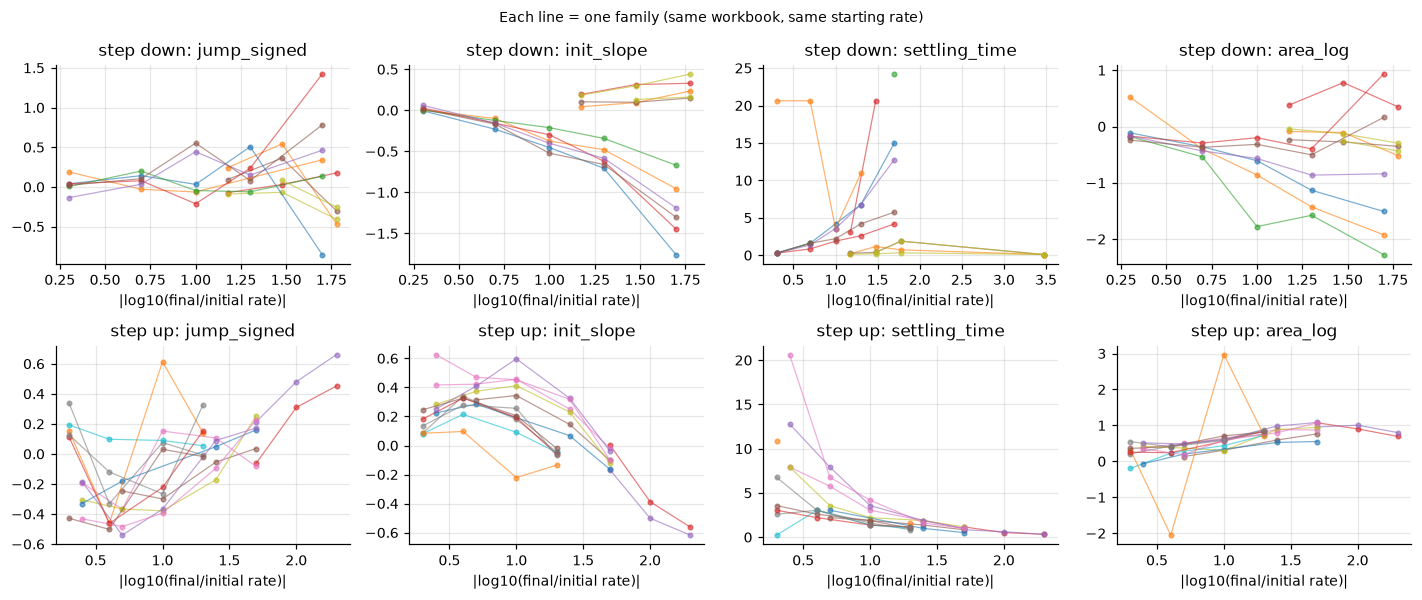

In [31]:
show = ["jump_signed", "init_slope", "settling_time", "area_log"]
fig, ax = plt.subplots(2, len(show), figsize=(13, 5.5))
for row, dirn in enumerate(["down", "up"]):
    for col, f in enumerate(show):
        a = ax[row, col]
        for i, ((unit, g0), fam) in enumerate(A[A.direction == dirn].groupby(["unit", "rate_from"])):
            if len(fam) < 3: continue
            fam = fam.sort_values("log10_ratio")
            a.plot(fam.log10_ratio.abs(), fam[f], "o-", ms=3, lw=0.8, alpha=0.6, color=f"C{i % 10}")
        a.set(title=f"step {dirn}: {f}", xlabel="|log10(final/initial rate)|")
fig.suptitle("Each line = one family (same workbook, same starting rate)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "05_magnitude.png", dpi=200); plt.show()

In [32]:
pairs = []
for unit, g in A.groupby("unit"):
    for _, u in g[g.direction == "up"].iterrows():
        dn = g[(g.direction == "down") & np.isclose(g.rate_from, u.rate_to) & np.isclose(g.rate_to, u.rate_from)]
        if len(dn):
            dn = dn.iloc[0]
            pairs.append(dict(unit=unit, sample=u["sample"], pair=f"{u.rate_from:g}<->{u.rate_to:g}",
                              up_id=u.step_id, down_id=dn.step_id,
                              **{f"d_{f}": u[f] - dn[f] for f in FEATURES},
                              **{f"up_{f}": u[f] for f in FEATURES}, **{f"down_{f}": dn[f] for f in FEATURES}))
pairs = pd.DataFrame(pairs)
print(f"{len(pairs)} matched reverse pairs from {pairs['sample'].nunique()} workbooks:",
      pairs.groupby("pair").size().to_dict())

res_dir = []
for f in FEATURES:
    wbm = pairs.groupby("sample")[f"d_{f}"].mean()
    p, k, n = sign_test(wbm)
    w = stats.wilcoxon(wbm.dropna()).pvalue if wbm.notna().sum() >= 5 else np.nan
    res_dir.append(dict(feature=f, n_workbooks=n, median_up_minus_down=wbm.median(), workbooks_up_gt_down=k,
                        sign_test_p=p, wilcoxon_p=w, pairs_up_gt_down=f"{(pairs[f'd_{f}'] > 0).sum()}/{pairs[f'd_{f}'].notna().sum()}"))
res_dir = pd.DataFrame(res_dir).sort_values("sign_test_p")
res_dir.to_csv(OUT / "result_direction.csv", index=False)
res_dir.round(4)

22 matched reverse pairs from 10 workbooks: {'0.1<->10': 3, '0.1<->20': 3, '0.1<->5': 10, '0.25<->5': 6}


,feature,n_workbooks,median_up_minus_down,workbooks_up_gt_down,sign_test_p,wilcoxon_p,pairs_up_gt_down
2,undershoot,10,-0.4882,0,0.0020,0.0020,0/22
3,init_slope,10,0.8026,10,0.0020,0.0020,22/22
9,visc_ratio,7,-7.6387,0,0.0156,0.0156,0/12
1,overshoot,10,-0.5816,1,0.0215,0.0059,6/22
4,settling_time,10,-6.8647,1,0.0215,0.0137,1/18
6,t_min,10,31.3444,9,0.0215,0.0059,15/22
7,area_log,10,1.6975,9,0.0215,0.0059,21/22
5,t_peak,10,0.0732,8,0.1094,0.1055,18/22
8,relax_amp,10,0.0093,8,0.1094,0.0371,16/22
0,jump_signed,10,-0.1239,3,0.3438,0.2754,9/22


Direction rule 'jump_signed > 0 => up' on matched pairs: accuracy 0.55 (95% workbook-bootstrap CI 0.46-0.64, n = 44 steps)
Same rule on all steps (confounded by starting rate): 0.42


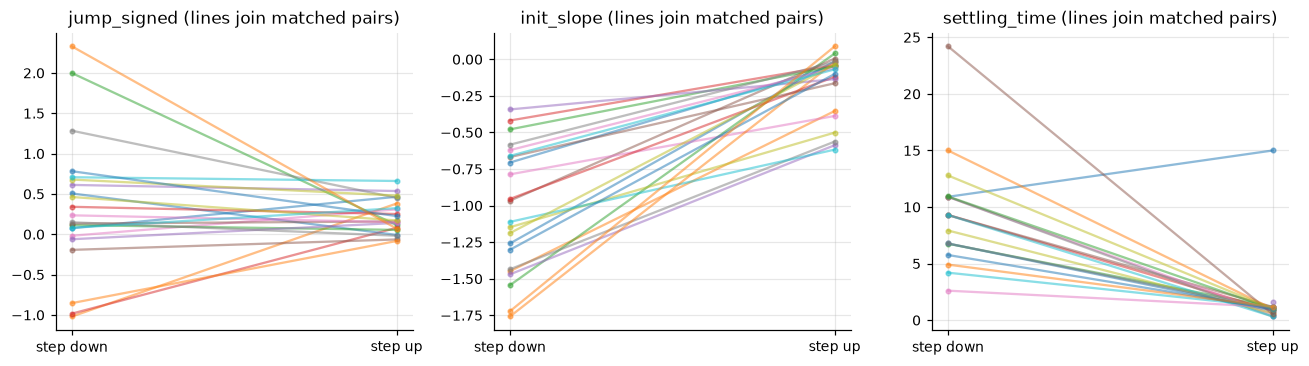

In [33]:
def rule_accuracy(df):
    ok = df.jump_signed.notna()
    return ((df.jump_signed[ok] > 0) == (df.direction[ok] == "up")).mean()

paired_ids = set(pairs.up_id) | set(pairs.down_id)
P = A[A.step_id.isin(paired_ids)]
rng = np.random.default_rng(0)
samples = P["sample"].unique()
boot = [rule_accuracy(pd.concat([P[P["sample"] == s] for s in rng.choice(samples, len(samples))])) for _ in range(2000)]
print(f"Direction rule 'jump_signed > 0 => up' on matched pairs: accuracy {rule_accuracy(P):.2f} "
      f"(95% workbook-bootstrap CI {np.percentile(boot, 2.5):.2f}-{np.percentile(boot, 97.5):.2f}, n = {len(P)} steps)")
print(f"Same rule on all steps (confounded by starting rate): {rule_accuracy(A):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, f in zip(ax, ["jump_signed", "init_slope", "settling_time"]):
    for _, r in pairs.iterrows():
        a.plot([0, 1], [r[f"down_{f}"], r[f"up_{f}"]], "-o", ms=3, alpha=0.5)
    a.set_xticks([0, 1], ["step down", "step up"]); a.set_title(f"{f} (lines join matched pairs)")
fig.tight_layout(); fig.savefig(FIG / "06_direction_pairs.png", dpi=200); plt.show()

In [34]:
def window_desc(d, t0, t1, ss):
    w = window(d, t0, t1)
    if len(w) < 3 or not np.isfinite(ss) or abs(ss) < NOISE_PA: return dict(abs_slope=np.nan, abs_dev=np.nan, cv=np.nan)
    x = np.log10(w.time.values); y = w.stress.values / ss
    return dict(abs_slope=abs(np.polyfit(x, y, 1)[0]), abs_dev=np.mean(np.abs(y - 1)), cv=np.std(y) / abs(np.mean(y)))

def phase_table(t_trans_end, t_stable_start):
    rows = []
    for _, r in A.iterrows():
        b = next(bb for bb in blocks if bb["step_id"] == r.step_id)
        ws = window(b["an"], t_stable_start, np.inf); ss = np.median(ws.stress) if len(ws) else np.nan
        rows.append(dict(step_id=r.step_id, sample=r["sample"], stable_ok=r.stable_ok,
                         **{f"T_{k}": v for k, v in window_desc(b["an"], r.t_rate_settle, t_trans_end, ss).items()},
                         **{f"S_{k}": v for k, v in window_desc(b["an"], t_stable_start, np.inf, ss).items()}))
    return pd.DataFrame(rows)

def phase_result(ph, label):
    out = []
    for k in ["abs_slope", "abs_dev", "cv"]:
        diff = np.log10(ph[f"T_{k}"].clip(lower=1e-6) / ph[f"S_{k}"].clip(lower=1e-6))   # log ratio transient/stable
        wbm = diff.groupby(ph["sample"]).median()
        p, kk, n = sign_test(wbm)
        out.append(dict(rule=label, descriptor=k, measurements_T_gt_S=f"{(diff > 0).sum()}/{diff.notna().sum()}",
                        median_log10_ratio_T_over_S=diff.median(), workbooks_T_gt_S=f"{kk}/{n}", sign_test_p=p))
    return out

ph = phase_table(TRANSIENT_END, STABLE_START)
res_phase = pd.DataFrame(phase_result(ph, "primary (2 s / 30 s)"))
res_phase.round(4)

,rule,descriptor,measurements_T_gt_S,median_log10_ratio_T_over_S,workbooks_T_gt_S,sign_test_p
0,primary (2 s / 30 s),abs_slope,106/128,0.5381,11/11,0.001
1,primary (2 s / 30 s),abs_dev,127/128,1.3827,11/11,0.001
2,primary (2 s / 30 s),cv,127/128,1.2814,11/11,0.001


In [35]:
sens = pd.concat([pd.DataFrame(phase_result(phase_table(a, b), name)) for name, (a, b) in RULE_VARIANTS.items()])
sens.to_csv(OUT / "result_transient_vs_stable.csv", index=False)
sens.pivot(index="descriptor", columns="rule", values="workbooks_T_gt_S")

rule,long (5 s / 40 s),primary (2 s / 30 s),short (1 s / 20 s)
descriptor,,,
abs_dev,11/11,11/11,11/11
abs_slope,9/11,11/11,11/11
cv,11/11,11/11,11/11


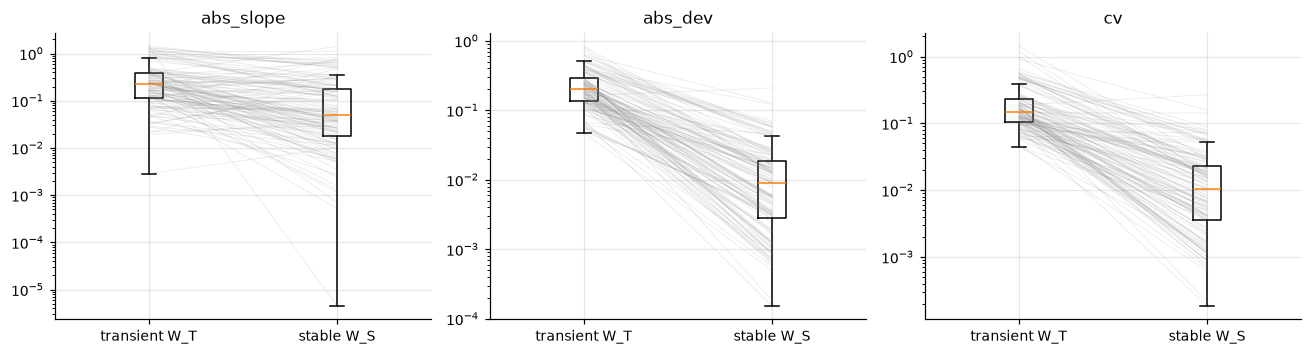

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for a, k in zip(ax, ["abs_slope", "abs_dev", "cv"]):
    a.boxplot([ph[f"T_{k}"].dropna(), ph[f"S_{k}"].dropna()], tick_labels=["transient W_T", "stable W_S"], showfliers=False)
    for _, r in ph.iterrows():
        a.plot([1, 2], [r[f"T_{k}"], r[f"S_{k}"]], color="grey", alpha=0.15, lw=0.6)
    a.set_yscale("log"); a.set_title(k)
fig.tight_layout(); fig.savefig(FIG / "07_transient_vs_stable.png", dpi=200); plt.show()

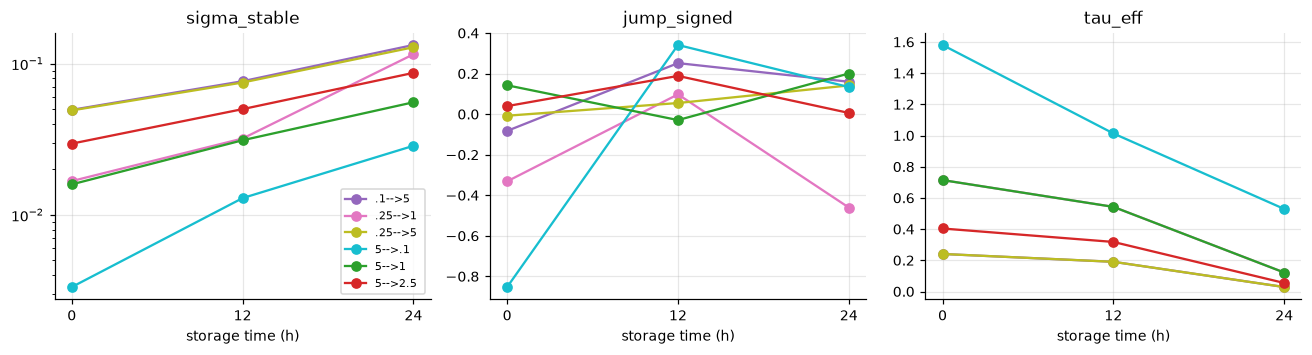

,storage_h,tau_lambda,G,sigma_y0,eta_ST,eta_inf,tr1,tr2
10,0.0,2.1730,0.2135,0.0011,0.0217,0.0027,1.2527,0.7886
11,12.0,1.1921,0.2985,0.0000,0.0358,0.0038,0.9346,0.2619
12,24.0,1.0072,0.4350,0.0062,0.2334,0.0052,6.4614,0.8131


In [37]:
dec = A[A["sample"] == "DEC17"]
if len(dec):
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
    for a, f in zip(ax, ["sigma_stable", "jump_signed", "tau_eff"]):
        for i, (lab, g) in enumerate(dec.groupby("label")):
            g = g.sort_values("storage_h")
            if g.storage_h.nunique() == 3 and lab.split("(")[0].strip() in ("5-->.1", ".1-->5", "5-->1", ".25-->1", ".25-->5", "5-->2.5"):
                a.plot(g.storage_h, g[f], "o-", label=lab.split("(")[0], color=f"C{i % 10}")
        a.set(xlabel="storage time (h)", title=f, xticks=[0, 12, 24])
        if f == "sigma_stable": a.set_yscale("log")
    ax[0].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(FIG / "08_dec17_storage.png", dpi=200); plt.show()
    display(models[models["sample"] == "DEC17"][["storage_h", "tau_lambda", "G", "sigma_y0", "eta_ST", "eta_inf", "tr1", "tr2"]].round(4))

In [38]:
def verdict(p, share):
    """'yes' = consistent in >= 80 % of workbooks AND sign-test p < 0.05; otherwise 'no'."""
    if not np.isfinite(p): return "n/a"
    return "yes" if p < 0.05 and max(share, 1 - share) >= 0.8 else "no"

rel = []
for f in FEATURES:
    row = dict(feature=f, computable=round(A[f].notna().mean(), 2))
    for dirn in ("down", "up"):
        m = res_mag[(res_mag.feature == f) & (res_mag.direction == dirn)]
        row[f"magnitude_{dirn}"] = (verdict(m.sign_test_p.iloc[0], m.workbooks_rho_pos.iloc[0] / max(m.n_workbooks.iloc[0], 1))
                                    if len(m) else "n/a")
    d = res_dir[res_dir.feature == f]
    row["direction"] = verdict(d.sign_test_p.iloc[0], d.workbooks_up_gt_down.iloc[0] / max(d.n_workbooks.iloc[0], 1)) if len(d) else "n/a"
    n_yes = sum(row[k] == "yes" for k in ("magnitude_down", "magnitude_up", "direction"))
    row["needs_stable_state"] = f in ("jump_signed", "overshoot", "undershoot", "init_slope", "area_log", "settling_time")
    row["classification"] = "unusable" if row["computable"] < 0.5 else "reliable" if row["computable"] >= 0.8 and n_yes else "inconclusive"
    rel.append(row)
fit_share = (fits_exp.status == "ok").mean()
rel.append(dict(feature="tau (single exponential)", computable=round(fit_share, 2),
                classification="unusable" if fit_share < 0.5 else "inconclusive"))
rel.append(dict(feature="tau_lambda, G (ethixo-EVP, per workbook)", computable=round((~models.k_at_bound).mean(), 2),
                classification="reliable" if (~models.k_at_bound).mean() >= 0.8 else "inconclusive"))
rel = pd.DataFrame(rel)
rel.to_csv(OUT / "metric_reliability.csv", index=False)
rel

,feature,computable,magnitude_down,magnitude_up,direction,needs_stable_state,classification
0,jump_signed,0.96,no,yes,no,True,reliable
1,overshoot,0.96,no,yes,yes,True,reliable
2,undershoot,0.96,yes,yes,yes,True,reliable
3,init_slope,0.96,no,yes,yes,True,reliable
4,settling_time,0.92,no,yes,yes,True,reliable
5,t_peak,1.00,yes,no,no,False,reliable
6,t_min,1.00,yes,no,yes,False,reliable
7,area_log,0.96,no,no,yes,True,reliable
8,relax_amp,0.96,no,yes,no,False,reliable
9,visc_ratio,0.83,yes,yes,yes,False,reliable


In [39]:
print("=== Data and verification ===")
print(f"step blocks analysed: {len(A)} from {A['sample'].nunique()} workbooks; label mismatches excluded: {(steps.qc_rate == 'MISMATCH with label').sum()}")
print(f"instrument window (rate settling): median {ev.t_rate_settle.median():.3f} s, max {ev.t_rate_settle.max():.3f} s")
print(f"defensible stable state within 63 s: {A.stable_ok.mean():.0%} of steps")
print("\n=== Relaxation model ===")
print(f"single exponential interpretable: {(fits_exp.status == 'ok').mean():.0%} of steps")
okm = models[~models.k_at_bound]
print(f"ethixo-EVP tau_lambda: median {okm.tau_lambda.median():.2f} s over {len(okm)} identifiable fits "
      f"(literature 1.13 +- 0.24 s); steps with acceptable fit (NRMSE <= {MODEL_MAX_NRMSE}): "
      f"{(A.nrmse_model <= A.fit_threshold).mean():.0%}")
print("\n=== Questions ===")
print("Magnitude (strongest):"); print(res_mag.nsmallest(3, "sign_test_p")[["feature", "direction", "median_rho", "workbooks_rho_pos", "n_workbooks", "sign_test_p"]].round(3).to_string(index=False))
print("Direction (matched pairs):"); print(res_dir.head(3)[["feature", "median_up_minus_down", "workbooks_up_gt_down", "n_workbooks", "sign_test_p"]].round(4).to_string(index=False))
print("Transient vs stable (all rule variants):"); print(sens[["rule", "descriptor", "workbooks_T_gt_S", "sign_test_p"]].round(4).to_string(index=False))
print(f"\nAll tables written to {OUT.resolve()}")

=== Data and verification ===
step blocks analysed: 133 from 11 workbooks; label mismatches excluded: 3
instrument window (rate settling): median 0.050 s, max 0.108 s
defensible stable state within 63 s: 86% of steps

=== Relaxation model ===
single exponential interpretable: 49% of steps
ethixo-EVP tau_lambda: median 0.64 s over 13 identifiable fits (literature 1.13 +- 0.24 s); steps with acceptable fit (NRMSE <= 0.1): 39%

=== Questions ===
Magnitude (strongest):
   feature direction  median_rho  workbooks_rho_pos  n_workbooks  sign_test_p
     t_min      down         0.9                  9            9        0.004
undershoot      down         1.0                  8            8        0.008
visc_ratio      down         1.0                  8            8        0.008
Direction (matched pairs):
   feature  median_up_minus_down  workbooks_up_gt_down  n_workbooks  sign_test_p
undershoot               -0.4882                     0           10       0.0020
init_slope                0.8

### Conventional LAOS analysis

Original code cells from `Conventional_LAOS_Analysis_Final.ipynb`.

In [40]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats, signal
import matplotlib.pyplot as plt

# Point this to the team Member 1 preprocessing folder.
DATA_DIR = Path(PROJECT_ROOT / "03_Team_Contributions" / "Part1_Data_Processing" / "Extracted_Contents" / "main-data")
if not DATA_DIR.exists():
    DATA_DIR = Path(PROJECT_ROOT / "03_Team_Contributions" / "Part1_Data_Processing" / "Extracted_Contents" / "main-data")

measurement_index = pd.read_csv(DATA_DIR/'measurement_index.csv')
signals = pd.read_csv(DATA_DIR/'standardized_signals.csv')
laos = measurement_index[measurement_index.experiment_type.eq('LAOS')].copy()

exclude = (
    laos.source_file.eq('9MAY19 UDEL Blood.xlsx')
    | laos.duplicate_of_measurement_id.notna()
    | laos.omega_label_rad_s.isna()
    | laos.strain_amplitude_label_fraction.isna()
)
laos_final = laos.loc[~exclude].copy()
print('Final LAOS freeze:', len(laos_final), 'measurements from', laos_final.source_file.nunique(), 'workbooks')

Final LAOS freeze: 181 measurements from 10 workbooks


In [41]:
def fit_metrics(d, omega, use_last_cycles=2, detrend=False):
    d = d[['time_s','stress_pa','strain_pct']].dropna().sort_values('time_s').copy()
    t = d.time_s.to_numpy(float)
    s = d.stress_pa.to_numpy(float)
    g = d.strain_pct.to_numpy(float)/100.0
    if len(t) < 20 or not np.isfinite(omega) or omega <= 0:
        return None

    T = 2*np.pi/omega
    tstart = t.max() - use_last_cycles*T
    keep = t >= tstart
    if keep.sum() < 20:
        keep = np.ones(len(t), dtype=bool)
    t, s, g = t[keep], s[keep], g[keep]
    if detrend:
        s = signal.detrend(s)
        g = signal.detrend(g)

    Xg = np.column_stack([np.sin(omega*t), np.cos(omega*t), np.ones_like(t)])
    cg = np.linalg.lstsq(Xg, g, rcond=None)[0]
    gamma1 = np.hypot(cg[0], cg[1])
    phi = np.arctan2(cg[1], cg[0])
    theta = omega*t + phi

    cols = []
    for n in range(1,6):
        cols += [np.sin(n*theta), np.cos(n*theta)]
    X = np.column_stack(cols + [np.ones_like(t)])
    c = np.linalg.lstsq(X, s, rcond=None)[0]
    sincoef = np.array([c[2*i] for i in range(5)])
    coscoef = np.array([c[2*i+1] for i in range(5)])
    amp = np.hypot(sincoef, coscoef)

    Gp = sincoef[0]/gamma1
    Gpp = coscoef[0]/gamma1
    delta = np.degrees(np.arctan2(Gpp, Gp))

    last = t >= t.max()-T
    area = abs(np.trapz(s[last], g[last]))
    denom = np.ptp(s[last])*np.ptp(g[last])

    pred = X@c
    r2 = 1 - np.sum((s-pred)**2)/np.sum((s-s.mean())**2)
    return {
        'G_prime_Pa': Gp,
        'G_double_prime_Pa': Gpp,
        'phase_angle_deg': delta,
        'I1_Pa': amp[0],
        'I3_Pa': amp[2],
        'I5_Pa': amp[4],
        'I3_I1': amp[2]/amp[0],
        'I5_I1': amp[4]/amp[0],
        'THD_2to5': np.sqrt(np.sum(amp[1:]**2))/amp[0],
        'lissajous_normalized_area': area/denom if denom > 0 else np.nan,
        'harmonic_fit_R2': r2,
    }

In [42]:
rows = []
for _, r in laos_final.iterrows():
    d = signals[signals.measurement_id.eq(r.measurement_id)]
    m = fit_metrics(d, float(r.omega_label_rad_s), use_last_cycles=2, detrend=False)
    if m is None:
        continue
    rows.append({
        'measurement_id': r.measurement_id,
        'source_file': r.source_file,
        'sheet': r.sheet,
        'omega_rad_s': r.omega_label_rad_s,
        'strain_amplitude': r.strain_amplitude_label_fraction,
        **m
    })
features = pd.DataFrame(rows)
features.head()

,measurement_id,source_file,sheet,omega_rad_s,strain_amplitude,G_prime_Pa,G_double_prime_Pa,phase_angle_deg,I1_Pa,I3_Pa,I5_Pa,I3_I1,I5_I1,THD_2to5,lissajous_normalized_area,harmonic_fit_R2
0,P1M0011,12FEB20 UDEL Blood.xlsx,LAOS,1.0,0.5,0.016071,0.020045,51.279739,0.012849,0.000157,0.000055,0.012243,0.004313,0.014670,0.365667,0.836350
1,P1M0012,12FEB20 UDEL Blood.xlsx,LAOS,1.0,1.0,0.010739,0.016841,57.476896,0.019977,0.000874,0.000177,0.043746,0.008842,0.046456,0.470373,0.910556
2,P1M0013,12FEB20 UDEL Blood.xlsx,LAOS,1.0,5.0,0.002259,0.010324,77.657325,0.052853,0.003963,0.000952,0.074983,0.018010,0.077217,0.702190,0.990607
3,P1M0014,12FEB20 UDEL Blood.xlsx,LAOS,1.0,10.0,0.001040,0.008568,83.079660,0.086323,0.006143,0.002044,0.071169,0.023678,0.075170,0.765946,0.997022
4,P1M0015,12FEB20 UDEL Blood.xlsx,LAOS,1.0,50.0,0.000054,0.005409,89.431605,0.270515,0.020227,0.006900,0.074774,0.025507,0.079040,0.816083,0.999311


In [43]:
metrics = ['G_prime_Pa','G_double_prime_Pa','phase_angle_deg','I3_I1','I5_I1','THD_2to5','lissajous_normalized_area']
summary = []
for omega, g in features.groupby('omega_rad_s'):
    for metric in metrics:
        rhos = []
        for workbook, gg in g.groupby('source_file'):
            a = gg.groupby('strain_amplitude', as_index=False)[metric].median().dropna().sort_values('strain_amplitude')
            if len(a) >= 4:
                rho, p = stats.spearmanr(np.log10(a.strain_amplitude), a[metric])
                rhos.append(rho)
        if rhos:
            summary.append([omega, metric, len(rhos), np.median(rhos)])
pd.DataFrame(summary, columns=['omega_rad_s','metric','n_workbooks','median_spearman_rho'])

,omega_rad_s,metric,n_workbooks,median_spearman_rho
0,0.5,G_prime_Pa,7,-1.000000
1,0.5,G_double_prime_Pa,7,-1.000000
2,0.5,phase_angle_deg,7,1.000000
3,0.5,I3_I1,7,0.100000
4,0.5,I5_I1,7,0.900000
5,0.5,THD_2to5,7,0.300000
6,0.5,lissajous_normalized_area,7,1.000000
7,1.0,G_prime_Pa,10,-1.000000
8,1.0,G_double_prime_Pa,10,-1.000000
9,1.0,phase_angle_deg,10,1.000000


### Standardized step-response analysis

Original code cells from `Member3_Step_UpDown_Analysis.ipynb`.

In [44]:
from pathlib import Path
import re, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import trapezoid
from scipy.optimize import least_squares, curve_fit, minimize_scalar

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})

# ---- paths -------------------------------------------------------------------------
DATA_DIR = PROJECT_ROOT / "90_Archives" / "Mixed_Handover_Bundle" / "Extracted_Contents" / "New folder"                       # source workbooks (used for flow curves only)
OUT = PROJECT_ROOT / "01_Active_Blood_Project" / "04_Results" / "Existing_Analysis" / "analysis_outputs" / "standardized_step_analysis"; OUT.mkdir(exist_ok=True)
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)

# Workbooks with no raw step time series (see measurement inventory)
EXCLUDE_WORKBOOKS = ("AY21", "AUG18")
# Sheets that contain step-like tests but are out of scope for step-up/down
EXCLUDE_SHEETS = ("bureau",)               # FEB18 'Bureau Step Up & Stop' = start-up from rest

# ---- step verification ---------------------------------------------------------------
RATE_TOL = 0.05            # measured initial/final rate must be within 5 % of the protocol label
RATE_SETTLE_TOL = 0.05     # rate is 'settled' once it stays within 5 % of the target (or 0.01 1/s)
MIN_INSTRUMENT_WINDOW = 0.05   # s; never analyse stress earlier than this after the step (motor inertia)

# ---- fixed transient / stable rule -----------------------------------------------------
# Justification: the structural time constant of blood is tau_lambda ~ 1.1 s (Frontiers 2022, 12 donors).
#   transient window  W_T = [instrument settle, 2 s]   (about 2 tau_lambda: structure still evolving)
#   stable window     W_S = [30 s, end of test]        (> 25 tau_lambda: structure should have equilibrated)
# The gap 2-30 s is 'late transient' and belongs to neither label.
TRANSIENT_END = 2.0
STABLE_START = 30.0
STABLE_MAX_DRIFT = 0.10    # W_S is a *defensible* stable state only if stress drifts < 10 % across it
SETTLE_BAND = 0.10         # settling time: stress stays within +-10 % of the stable value
NOISE_PA = 0.001           # Pa; absolute noise floor (checked empirically in section 4)

# Sensitivity analysis boundaries for section 7.4
RULE_VARIANTS = {"primary (2 s / 30 s)": (2.0, 30.0), "short (1 s / 20 s)": (1.0, 20.0),
                 "long (5 s / 40 s)": (5.0, 40.0)}

# ---- relaxation model -------------------------------------------------------------------
D_EXP = 0.5                # shear-aggregation exponent, fixed at 1/2 in all four papers
TAU_LAMBDA_LIT = (1.13, 0.24)   # s, mean and SD over 12 donors (Frontiers in Physics 2022, Table 6)
G_LIT_V1 = 0.29            # Pa, G of ethixo-EVP version 1, Donor 3 (Armstrong et al. 2021, Table 3) -- same model
G_LIT_R = (0.15, 0.05)     # Pa, rouleaux modulus G_R of the tensorial t-ESSTV, 12 donors (Frontiers 2022) -- related model
MODEL_MAX_NRMSE = 0.10     # a step is 'poorly fitted' if RMS error > 10 % of that step's maximum stress

In [45]:
def storage_hours(sheet_title):
    """Storage time of the sample in hours, parsed from the sheet name ('t0', 't12', '24hr'); 0 if absent."""
    s = sheet_title.lower()
    m = re.search(r"\bt\s?(\d+)\b", s) or re.search(r"(\d+)\s?h", s)
    return float(m.group(1)) if m else 0.0

def parse_step_label(label):
    m = re.search(r"([\d.]+)\s*-->\s*([\d.]+)", label.replace(" ", ""))
    return (float(m.group(1)), float(m.group(2))) if m else (np.nan, np.nan)

MAIN_DIR = PROJECT_ROOT / "03_Team_Contributions" / "Part1_Data_Processing" / "Extracted_Contents" / "main-data"
idx = pd.read_csv(MAIN_DIR / "measurement_index.csv")
sig_file = MAIN_DIR / "standardized_signals.csv.gz"
if not sig_file.exists():
    sig_file = MAIN_DIR / "standardized_signals.csv"
sig = pd.read_csv(sig_file, usecols=["measurement_id", "time_s", "stress_pa", "strain_pct", "shear_rate_1_s", "qc_flag"])

cand = idx[idx.experiment_type == "STEP_UP_DOWN"].copy()
cand["exclusion_reason"] = ""
dup = cand.duplicate_of_measurement_id.notna() & (cand.duplicate_of_measurement_id.astype(str) != "")
cand.loc[dup, "exclusion_reason"] = "exact duplicate of " + cand.loc[dup, "duplicate_of_measurement_id"].astype(str)
cand.loc[(cand.exclusion_reason == "") & (cand.experiment_subtype == "STEP_UNKNOWN"), "exclusion_reason"] = \
    "STEP_UNKNOWN: Bureau start-up-and-stop test, not a step-up/down (out of scope)"
# Member 1 hashes stress + rate together; also check the stress trace alone, which catches blocks whose stress
# column was copy-pasted from another block while the shear-rate column was not
stress_hash = sig.groupby("measurement_id", sort=False).stress_pa.apply(
    lambda s_: hashlib.md5(np.round(s_.values, 9).tobytes()).hexdigest())
first_seen = {}
for i_, mid in cand.measurement_id.items():
    h_ = stress_hash.get(mid)
    if h_ in first_seen and cand.at[i_, "exclusion_reason"] == "":
        cand.at[i_, "exclusion_reason"] = (f"stress trace identical to {first_seen[h_]} although the shear rate differs "
                                           "(probable copy-paste error in the source workbook)")
    first_seen.setdefault(h_, mid)
excluded = cand[cand.exclusion_reason != ""]
use = cand[cand.exclusion_reason == ""]
excluded[["measurement_id", "source_file", "sheet", "condition_label", "experiment_subtype", "exclusion_reason"]].to_csv(
    OUT / "excluded_measurements.csv", index=False)
print(f"Member 1 index: {len(cand)} step blocks -> {len(use)} used, {len(excluded)} excluded")
print(excluded.exclusion_reason.str.replace(r" (of|to) P1M\d+.*", "", regex=True).str.split(":").str[0].value_counts().to_string())

grouped = dict(tuple(sig[sig.measurement_id.isin(use.measurement_id)].groupby("measurement_id", sort=False)))
blocks = []
for r in use.itertuples():
    g = grouped[r.measurement_id]
    df = pd.DataFrame({"time": g.time_s.values, "stress": g.stress_pa.values,
                       "strain": g.strain_pct.values, "shear_rate": g.shear_rate_1_s.values})
    df = df.dropna(axis=1, how="all")
    df = df[np.isfinite(df.time) & (df.time > 0) & np.isfinite(df.stress)].reset_index(drop=True)
    m = re.search(r"(\d{1,2}[A-Z]{3}\d{0,2}|[A-Z]{3}\d{2})", r.source_file)
    blocks.append(dict(step_id=r.measurement_id, workbook=r.source_file, sheet=r.sheet, block=int(r.source_start_column),
                       label=r.condition_label, storage_h=storage_hours(r.sheet),
                       rate_from=r.step_start_rate_label_1_s, rate_to=r.step_final_rate_label_1_s,
                       member1_qc=r.qc_status, sample=m.group(1) if m else r.source_file,
                       n_points=len(df), high_res=len(df) > 1000, data=df))

inv = pd.DataFrame([{k: v for k, v in b.items() if k != "data"} for b in blocks])
print(f"\n{len(inv)} step blocks from {inv.workbook.nunique()} workbooks "
      f"({inv.high_res.sum()} high-resolution, {(~inv.high_res).sum()} log-spaced)")
inv.groupby("sample").agg(blocks=("step_id", "size"), storage_times=("storage_h", "nunique"),
                          member1_review=("member1_qc", lambda x: (x == "REVIEW").sum()))

Member 1 index: 157 step blocks -> 138 used, 19 excluded
exclusion_reason
exact duplicate           9
STEP_UNKNOWN              9
stress trace identical    1

138 step blocks from 12 workbooks (6 high-resolution, 132 log-spaced)


,blocks,storage_times,member1_review
sample,,,
12FEB20,10,1,0
14DEC,5,1,0
14MAR19,10,1,0
27FEB19,10,1,0
9MAY19,9,1,0
APR18,7,1,1
AUG18,2,1,0
DEC17,41,3,0
FEB18,10,1,0


In [46]:
def read_flow_curves(path):
    import openpyxl
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    curves = []
    for ws in wb.worksheets:
        if not re.search(r"\bSS\b|steady", ws.title, re.I):
            continue
        R = list(ws.iter_rows(values_only=True))
        for r_i in range(3):
            for j, v in enumerate(R[r_i]):
                if v is None or "shear rate" not in str(v).lower():
                    continue
                above = " ".join(str(R[k][j]) for k in range(r_i) if j < len(R[k]) and R[k][j])
                xs, ys = [], []
                for r in R[r_i + 1:]:
                    x = r[j] if j < len(r) else None; y = r[j + 1] if j + 1 < len(r) else None
                    if not isinstance(x, (int, float)) or not isinstance(y, (int, float)) or (xs and x <= xs[-1]):
                        break
                    xs.append(x); ys.append(y)
                if len(xs) >= 8:
                    m = re.search(r"(\d+)", above)
                    curves.append(dict(storage_h=float(m.group(1)) if m else 0.0,
                                       rate=np.array(xs), stress=np.array(ys)))
    return curves

flow = {}
for name in sorted(set(b["workbook"] for b in blocks)):
    path = DATA_DIR / name
    flow[name] = read_flow_curves(path) if path.exists() else []
print("flow curves missing for:", [k for k, v in flow.items() if not v] or "none")

def flow_curve_for(workbook, storage_h):
    cs = flow.get(workbook, [])
    match = [c for c in cs if c["storage_h"] == storage_h]
    return (match or cs or [None])[0]

def flow_stress(fc, rate):
    """Log-log interpolation of the flow-curve stress at a given shear rate."""
    if fc is None or not np.isfinite(rate) or rate <= 0:
        return np.nan
    return float(np.exp(np.interp(np.log(rate), np.log(fc["rate"]), np.log(np.clip(fc["stress"], 1e-6, None)))))

print({k: [c["storage_h"] for c in v] for k, v in flow.items()})

flow curves missing for: none
{'12FEB20 UDEL Blood.xlsx': [0.0], '14DEC_UDEL_Blood_Rheo.xlsx': [0.0], '14MAR19 SS SAOS STEP LAOS etc.xlsx': [0.0], '27FEB19 UDEL Blood.xlsx': [0.0], '9MAY19 UDEL Blood.xlsx': [0.0], 'APR18 SS SAOS STEPS LAOS UDLAOS.xlsx': [0.0], 'AUG18 UDEL Blood.xlsx': [0.0], 'FEB18 UDEL ARES G2 SS LAOS SAW STEP UP DATA.xlsx': [0.0, 6.0, 24.0], 'JUL18.xlsx': [0.0], 'JUN18.xlsx': [0.0, 0.0], 'NOV18 UDEL ARESG2 DATA.xlsx': [0.0], 'UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELTON.xlsx': [0.0, 12.0, 24.0]}


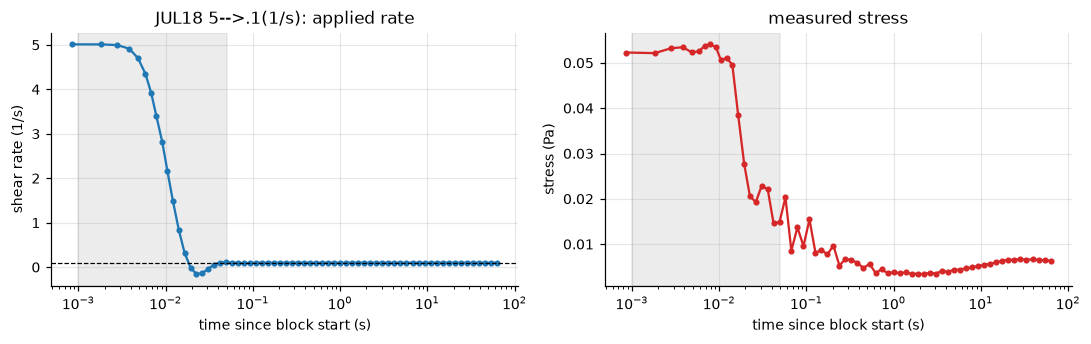

In [47]:
ex = next(b for b in blocks if b["sample"] == "JUL18" and b["label"].startswith("5-->.1"))
d = ex["data"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].semilogx(d.time, d.shear_rate, "o-", ms=3); ax[0].axhline(ex["rate_to"], color="k", lw=0.8, ls="--")
ax[0].set(xlabel="time since block start (s)", ylabel="shear rate (1/s)", title=f'{ex["sample"]} {ex["label"]}: applied rate')
ax[1].semilogx(d.time, d.stress, "o-", ms=3, color="C3")
ax[1].set(xlabel="time since block start (s)", ylabel="stress (Pa)", title="measured stress")
for a in ax: a.axvspan(1e-3, MIN_INSTRUMENT_WINDOW, color="grey", alpha=0.15)
fig.tight_layout(); fig.savefig(FIG / "01_raw_step_block.png", dpi=200); plt.show()

In [48]:
def verify_step(b):
    d = b["data"]; t = d.time.values
    g0_lab, g1_lab = b["rate_from"], b["rate_to"]
    res = dict(step_id=b["step_id"])
    if "shear_rate" not in d or d.shear_rate.isna().all():
        # no rate channel: time is zeroed at the step, so t_step = 0 and the instrument window is the minimum
        res.update(rate_from_meas=np.nan, rate_to_meas=np.nan, has_pre_step=False, t_step=0.0,
                   t_rate_settle=MIN_INSTRUMENT_WINDOW, rate_overshoot_frac=np.nan,
                   qc_rate="label only (no shear-rate channel)")
        return res
    g = d.shear_rate.values
    g1 = np.nanmedian(g[t >= 1.0])
    has_pre = t[0] < 0.004 and abs(g[0] - g1) > 0.3 * abs(g1_lab - g0_lab)
    g0 = np.nanmedian(g[:3]) if has_pre else g0_lab
    half = g0 + 0.5 * (g1 - g0)
    moved = np.where(np.sign(g1 - g0) * (g - half) > 0)[0]
    t_step = t[moved[0]] if has_pre and len(moved) else 0.005     # median observed value when not measurable
    tol = np.maximum(RATE_SETTLE_TOL * abs(g1), 0.01)
    bad = np.where(np.abs(g - g1) > tol)[0]
    t_rs = t[bad[-1] + 1] if len(bad) and bad[-1] + 1 < len(t) else t[0]
    after = g[t > t_step]
    excess = (np.max(after) - g1) if g1 > g0 else (g1 - np.min(after))
    ok0 = has_pre and abs(g0 / g0_lab - 1) <= RATE_TOL
    ok1 = abs(g1 / g1_lab - 1) <= RATE_TOL
    res.update(rate_from_meas=g0, rate_to_meas=g1, has_pre_step=has_pre, t_step=t_step,
               t_rate_settle=max(t_rs, MIN_INSTRUMENT_WINDOW), rate_overshoot_frac=excess / abs(g1 - g0),
               qc_rate=("ok" if ok0 and ok1 else
                        "final ok, initial from label (no pre-step samples)" if ok1 and not has_pre else
                        "MISMATCH with label"))
    return res

ev = inv.merge(pd.DataFrame([verify_step(b) for b in blocks]), on="step_id")
ev["ratio"] = ev.rate_to / ev.rate_from
ev["log10_ratio"] = np.log10(ev.ratio)
ev["direction"] = np.where(ev.ratio > 1, "up", "down")
ev["magnitude_abs"] = (ev.rate_to - ev.rate_from).abs()

print(ev.qc_rate.value_counts().to_string())
cols = ["step_id", "sample", "sheet", "label", "storage_h", "rate_from", "rate_to", "rate_from_meas", "rate_to_meas",
        "direction", "log10_ratio", "t_step", "t_rate_settle", "rate_overshoot_frac", "qc_rate"]
ev[cols].to_csv(OUT / "step_events.csv", index=False)
ev[cols].head(12)

qc_rate
ok                                                    127
final ok, initial from label (no pre-step samples)      6
MISMATCH with label                                     3
label only (no shear-rate channel)                      2


,step_id,sample,sheet,label,storage_h,rate_from,rate_to,rate_from_meas,rate_to_meas,direction,log10_ratio,t_step,t_rate_settle,rate_overshoot_frac,qc_rate
0,P1M0001,12FEB20,Steps,10-->.1,0.0,10.0,0.1,9.986000,0.100012,down,-2.000000,0.010504,0.057501,0.052045,ok
1,P1M0002,12FEB20,Steps,300--> 20(1/s),0.0,300.0,20.0,300.026000,20.002400,down,-1.176091,0.014173,0.050000,0.036953,ok
2,P1M0003,12FEB20,Steps,300-->5,0.0,300.0,5.0,300.020000,5.000600,down,-1.778151,0.014161,0.067170,0.036195,ok
3,P1M0004,12FEB20,Steps,300-->10,0.0,300.0,10.0,300.023000,10.001200,down,-1.477121,0.014167,0.050000,0.036517,ok
4,P1M0005,12FEB20,Steps,5-->.1(1/s),0.0,5.0,0.1,5.027830,0.100012,down,-1.698970,0.010497,0.092498,0.052133,ok
5,P1M0006,12FEB20,Steps,20-->.1,0.0,20.0,0.1,19.957000,0.100012,down,-2.301030,0.010479,0.057476,0.052000,ok
6,P1M0007,12FEB20,Steps,300-->.1,0.0,300.0,0.1,300.026000,0.100012,down,-3.477121,0.013355,0.103016,0.038982,ok
7,P1M0008,12FEB20,Steps,.1-->5,0.0,0.1,5.0,0.101051,5.000605,up,1.698970,0.010661,0.050000,0.050673,ok
8,P1M0009,12FEB20,Steps,.1-->10,0.0,0.1,10.0,0.102100,10.001200,up,2.000000,0.010492,0.050000,0.050560,ok
9,P1M0010,12FEB20,Steps,.1-->20,0.0,0.1,20.0,0.105109,20.002400,up,2.301030,0.010490,0.050000,0.053203,MISMATCH with label


In [49]:
bad = ev[ev.qc_rate.str.startswith("MISMATCH")]
print(f"{len(bad)} blocks disagree with their label:")
bad[cols]

3 blocks disagree with their label:


,step_id,sample,sheet,label,storage_h,rate_from,rate_to,rate_from_meas,rate_to_meas,direction,log10_ratio,t_step,t_rate_settle,rate_overshoot_frac,qc_rate
9,P1M0010,12FEB20,Steps,.1-->20,0.0,0.1,20.0,0.105109,20.002400,up,2.30103,0.010490,0.05,0.053203,MISMATCH with label
23,P1M0055,14MAR19,Steps,.1-->10,0.0,0.1,10.0,-0.301885,10.001200,up,2.00000,0.014169,0.05,0.040367,MISMATCH with label
44,P1M0128,APR18,steps,5-->0.1,0.0,5.0,0.1,5.005830,0.500059,down,-1.69897,0.010505,0.05,0.051908,MISMATCH with label


In [50]:
ev.groupby("direction")[["t_step", "t_rate_settle", "rate_overshoot_frac"]].describe(percentiles=[.5]).round(3)

t_step                                  t_rate_settle                                  rate_overshoot_frac                                   
           count   mean    std  min    50%    max         count   mean    std   min   50%    max               count   mean    std    min    50%    max
direction                                                                                                                                              
down        70.0  0.011  0.003  0.0  0.011  0.014          70.0  0.067  0.022  0.05  0.05  0.108                69.0  0.046  0.008  0.035  0.051  0.053
up          68.0  0.010  0.001  0.0  0.010  0.014          68.0  0.055  0.017  0.05  0.05  0.108                67.0  0.052  0.003  0.040  0.052  0.061

In [51]:
def window(d, t0, t1):
    return d[(d.time >= t0) & (d.time <= t1)]

noise = []
for b in blocks:
    w = window(b["data"], STABLE_START, np.inf)
    if len(w) >= 4:
        x = np.log10(w.time.values); y = w.stress.values
        resid = y - np.polyval(np.polyfit(x, y, 1), x)
        noise.append(dict(step_id=b["step_id"], high_res=b["high_res"], resid_sd=np.std(resid, ddof=2),
                          stable_level=np.median(y)))
noise = pd.DataFrame(noise)
print(noise.groupby("high_res").resid_sd.describe(percentiles=[.5, .9]).round(5).to_string())
print(f"\nConfigured NOISE_PA = {NOISE_PA} Pa")

          count     mean      std      min      50%      90%      max
high_res                                                             
False     127.0  0.00056  0.00198  0.00001  0.00010  0.00104  0.02045
True        6.0  0.00387  0.00084  0.00271  0.00381  0.00479  0.00482

Configured NOISE_PA = 0.001 Pa


In [52]:
ref_grid = next(b for b in blocks if not b["high_res"])["data"].time.values
edges = np.sqrt(ref_grid[1:] * ref_grid[:-1]); edges = np.r_[ref_grid[0] / 1.2, edges, ref_grid[-1] * 1.2]

def log_bin(d):
    idx = np.digitize(d.time.values, edges) - 1
    g = d.assign(bin=idx).groupby("bin").mean(numeric_only=True)
    return g[g.index.isin(range(len(ref_grid)))].reset_index(drop=True)

for b in blocks:
    b["an"] = log_bin(b["data"]) if b["high_res"] else b["data"]   # 'analysis' series
print("high-res blocks after binning:", [len(b["an"]) for b in blocks if b["high_res"]])

high-res blocks after binning: [47, 47, 47, 47, 47, 47]


In [53]:
def windows_for(b, e, t_trans_end=TRANSIENT_END, t_stable_start=STABLE_START):
    d = b["an"]
    wt = window(d, e.t_rate_settle, t_trans_end)
    ws = window(d, t_stable_start, np.inf)
    s_stable = np.median(ws.stress) if len(ws) else np.nan
    if len(ws) >= 3:
        x = np.log10(ws.time.values)
        slope = np.polyfit(x, ws.stress.values, 1)[0]
        drift = slope * (x[-1] - x[0])
    else:
        drift = np.nan
    drift_frac = abs(drift) / max(abs(s_stable), NOISE_PA) if np.isfinite(drift) else np.nan
    return dict(n_transient=len(wt), n_stable=len(ws), sigma_stable=s_stable, stable_drift_Pa=drift,
                stable_drift_frac=drift_frac,
                stable_ok=bool(np.isfinite(drift_frac) and (drift_frac <= STABLE_MAX_DRIFT or abs(drift) <= NOISE_PA)),
                below_noise=bool(abs(s_stable) < 3 * NOISE_PA))

evi = ev.set_index("step_id")
win = pd.DataFrame([dict(step_id=b["step_id"], **windows_for(b, evi.loc[b["step_id"]])) for b in blocks])
ev = ev.drop(columns=[c for c in win.columns if c != "step_id" and c in ev], errors="ignore").merge(win, on="step_id")
ev[["step_id", "sample", "label", "n_transient", "n_stable", "sigma_stable", "stable_drift_frac",
    "stable_ok", "below_noise"]].to_csv(OUT / "step_windows.csv", index=False)

print(f"Defensible stable state reached: {ev.stable_ok.sum()} / {len(ev)} measurements")
print(f"Stable stress within 3x noise floor: {ev.below_noise.sum()}")
ev.assign(final_rate=ev.rate_to).groupby(["direction", "final_rate"]).stable_ok.agg(["mean", "size"]).round(2).T

Defensible stable state reached: 120 / 138 measurements
Stable stress within 3x noise floor: 0


direction    down                                              up                                      
final_rate  0.10  0.25  0.50  1.00  2.50  5.00  10.00 20.00 0.25  0.50   1.00   2.50  5.00  10.00 20.00
mean         0.57   1.0  0.83   1.0   1.0  0.86   1.0   1.0  0.83   1.0   0.91   0.92   1.0  0.75   1.0
size        28.00   6.0  6.00   7.0   7.0  7.00   5.0   4.0  6.00  12.0  11.00  12.00  19.0  4.00   4.0

In [54]:
def features(b, e):
    d = b["an"]; t = d.time.values; s = d.stress.values
    fc = flow_curve_for(b["workbook"], b["storage_h"])
    ss = e.sigma_stable
    m = t >= e.t_rate_settle
    tm, sm = t[m], s[m]
    pre = s[t < 0.5 * e.t_step] if e.has_pre_step else np.array([])
    f = dict(step_id=b["step_id"])
    f["sigma_pre"] = np.median(pre) if len(pre) else np.nan
    f["sigma_pre_fc"] = flow_stress(fc, e.rate_from)
    f["sigma_final_fc"] = flow_stress(fc, e.rate_to)
    f["sigma_imm"] = sm[0]
    i_pk, i_mn = np.argmax(sm), np.argmin(sm)
    f.update(sigma_peak=sm[i_pk], t_peak=tm[i_pk], sigma_min=sm[i_mn], t_min=tm[i_mn])
    denom = abs(ss) if abs(ss) > NOISE_PA else np.nan
    f["overshoot"] = (sm[i_pk] - ss) / denom
    f["undershoot"] = (ss - sm[i_mn]) / denom
    f["jump_signed"] = (sm[0] - ss) / denom
    f["relax_amp"] = sm[0] - ss
    early = (tm <= 1.0)
    f["init_slope"] = (np.polyfit(np.log10(tm[early]), sm[early] / denom, 1)[0]
                       if early.sum() >= 3 and np.isfinite(denom) else np.nan)
    outside = np.where(np.abs(sm - ss) > max(SETTLE_BAND * abs(ss), NOISE_PA))[0]
    if len(outside) == 0:
        f["settling_time"] = tm[0]
    elif outside[-1] + 1 < len(tm) and tm[outside[-1] + 1] < STABLE_START:
        f["settling_time"] = tm[outside[-1] + 1]
    else:
        f["settling_time"] = np.nan
    f["area_log"] = trapezoid((sm - ss) / denom, np.log(tm))
    f["plateau_vs_fc"] = ss / f["sigma_final_fc"]
    f["baseline_vs_fc"] = f["sigma_pre"] / f["sigma_pre_fc"]
    f["visc_ratio"] = ((ss / e.rate_to) / (f["sigma_pre"] / e.rate_from)
                       if len(pre) and abs(f["sigma_pre"]) >= 3 * NOISE_PA else np.nan)   # baseline must exceed noise
    return f

evs = ev.set_index("step_id")
feat = pd.DataFrame([features(b, evs.loc[b["step_id"]]) for b in blocks])
steps = ev.merge(feat, on="step_id")
FEATURES = ["jump_signed", "overshoot", "undershoot", "init_slope", "settling_time", "t_peak", "t_min",
            "area_log", "relax_amp", "visc_ratio"]
steps.to_csv(OUT / "step_features.csv", index=False)
steps[["step_id", "sample", "label", "direction", "sigma_pre", "sigma_imm", "sigma_stable"] + FEATURES].head(10).round(4)

,step_id,sample,label,direction,sigma_pre,sigma_imm,sigma_stable,jump_signed,overshoot,undershoot,init_slope,settling_time,t_peak,t_min,area_log,relax_amp,visc_ratio
0,P1M0001,12FEB20,10-->.1,down,0.0753,-0.0001,0.0038,-1.0185,3.1282,1.0185,-1.4482,10.9058,0.0788,0.0575,-1.6468,-0.0039,5.0993
1,P1M0002,12FEB20,300--> 20(1/s),down,1.1957,0.1179,0.1270,-0.0719,0.1538,0.1288,0.1948,3.0460,0.5280,0.0787,0.3790,-0.0091,1.5930
2,P1M0003,12FEB20,300-->5,down,1.1682,0.0626,0.0532,0.1770,0.7168,0.3870,0.3299,NaN,45.7985,0.0787,0.3502,0.0094,2.7317
3,P1M0004,12FEB20,300-->10,down,1.2008,0.0782,0.0759,0.0305,0.2750,0.2771,0.3144,20.6357,1.1707,0.0787,0.7800,0.0023,1.8955
4,P1M0005,12FEB20,5-->.1(1/s),down,0.0474,0.0045,0.0042,0.0770,1.0279,0.6520,-1.2583,10.9058,0.1083,1.3735,-1.1801,0.0003,4.4142
5,P1M0006,12FEB20,20-->.1,down,0.1279,0.0076,0.0040,0.8879,2.1480,1.1684,-1.6144,12.7908,0.0788,0.0925,-2.7370,0.0036,6.2981
6,P1M0007,12FEB20,300-->.1,down,1.1575,0.0024,NaN,NaN,NaN,NaN,NaN,0.1030,0.1195,0.1030,NaN,NaN,NaN
7,P1M0008,12FEB20,.1-->5,up,0.0087,0.0678,0.0463,0.4658,0.7185,0.0250,-0.0127,15.0013,0.2035,53.7155,2.1944,0.0216,0.1063
8,P1M0009,12FEB20,.1-->10,up,-0.0008,0.1040,0.0753,0.3821,0.7546,0.0281,-0.3532,NaN,15.0012,63.0007,1.9765,0.0288,NaN
9,P1M0010,12FEB20,.1-->20,up,0.0096,0.2123,0.1253,0.6951,0.6951,0.0083,-0.5800,0.8513,0.0575,33.2933,1.2348,0.0871,0.0654


       baseline_vs_fc  plateau_vs_fc
count          130.00         133.00
mean             1.37           1.30
std              1.17           0.48
min             -1.53           0.53
10%              0.52           1.00
50%              1.07           1.13
90%              2.60           1.99
max              8.89           4.38


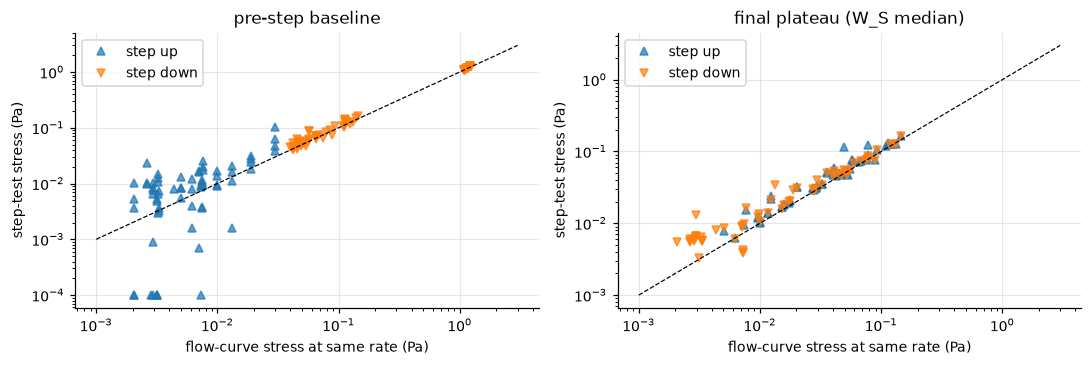

In [55]:
chk = steps[["baseline_vs_fc", "plateau_vs_fc"]].replace([np.inf, -np.inf], np.nan)
print(chk.describe(percentiles=[.1, .5, .9]).round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, (col, ref, ttl) in zip(ax, [("sigma_pre", "sigma_pre_fc", "pre-step baseline"),
                                   ("sigma_stable", "sigma_final_fc", "final plateau (W_S median)")]):
    for dirn, mk in [("up", "^"), ("down", "v")]:
        q = steps[steps.direction == dirn]
        a.loglog(q[ref], q[col].clip(lower=1e-4), mk, ms=5, alpha=0.7, label=f"step {dirn}")
    lim = [1e-3, 3]; a.plot(lim, lim, "k--", lw=0.8)
    a.set(xlabel="flow-curve stress at same rate (Pa)", ylabel="step-test stress (Pa)", title=ttl); a.legend()
fig.tight_layout(); fig.savefig(FIG / "02_baseline_plateau_vs_flowcurve.png", dpi=200); plt.show()

In [56]:
def exp_model(t, s_inf, A, tau):
    return s_inf + A * np.exp(-t / tau)

def fit_exponential(b, e):
    d = b["an"]; m = d.time >= e.t_rate_settle
    t = d.time.values[m] - e.t_step; y = d.stress.values[m]
    rec = dict(step_id=b["step_id"], model="exponential")
    try:
        p0 = [np.median(y[-5:]), y[0] - np.median(y[-5:]), 1.0]
        p, cov = curve_fit(exp_model, t, y, p0=p0, bounds=([-np.inf, -np.inf, 0.01], [np.inf, np.inf, 200]), maxfev=20000)
        yhat = exp_model(t, *p); r2 = 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)
        se = np.sqrt(np.diag(cov))[2] if np.all(np.isfinite(cov)) else np.inf
        reasons = []
        if p[2] <= 0.0101 or p[2] >= 199: reasons.append("tau at bound")
        if not np.isfinite(se) or 1.96 * se > p[2]: reasons.append("tau CI wider than tau")
        if r2 < 0.5: reasons.append("R2 < 0.5")
        rec.update(s_inf=p[0], amp=p[1], tau=p[2], tau_se=se, r2=r2, rmse=np.sqrt(np.mean((y - yhat) ** 2)),
                   status="ok" if not reasons else "not interpretable", reason="; ".join(reasons))
    except Exception as err:
        rec.update(status="failed", reason=type(err).__name__)
    return rec

evs = ev.set_index("step_id")
fits_exp = pd.DataFrame([fit_exponential(b, evs.loc[b["step_id"]]) for b in blocks])
print(fits_exp.status.value_counts().to_string())
fits_exp.merge(ev[["step_id", "direction", "rate_from", "rate_to"]]).groupby(["direction", "rate_to"]).status.agg(
    lambda s: f"{(s == 'ok').sum()}/{len(s)} ok").unstack(0).fillna("")

status
not interpretable    69
ok                   69


direction,down,up
rate_to,,
0.10,14/28 ok,
0.25,2/6 ok,1/6 ok
0.50,2/6 ok,4/12 ok
1.00,0/7 ok,3/11 ok
2.50,3/7 ok,3/12 ok
5.00,6/7 ok,19/19 ok
10.00,2/5 ok,4/4 ok
20.00,2/4 ok,4/4 ok


In [57]:
from scipy.integrate import solve_ivp

def lam_ss(g, tr1, tr2):                                   # Eq. 16
    g = np.abs(g); return (tr2 * g ** D_EXP + 1) / (tr1 * g + tr2 * g ** D_EXP + 1)

def sigma_ss(g, p):                                        # Eq. 10
    sy, eta_st, eta_inf, tr1, tr2 = p[:5]
    lam = lam_ss(g, tr1, tr2); return lam * sy + (lam * eta_st + eta_inf) * g

def simulate_step(t_eval, g0, g1, t_step, p):
    """ethixo-EVP version 1: Eq. 11 (n = 1) for stress and Eq. 13 for structure, driven by the plastic rate.
    Starts from steady state at the initial rate g0; the rate switches to g1 at t_step."""
    sy, eta_st, eta_inf, tr1, tr2, G, k_lam = p
    def rhs(t, z):
        s, lam = z
        g = g1 if t >= t_step else g0
        gp = max(0.0, abs(s) - lam * sy) / (lam * eta_st + eta_inf) * np.sign(s)     # plastic shear rate
        agp = abs(gp)
        return [G * (g - gp), k_lam * (-tr1 * agp * lam + tr2 * agp ** D_EXP * (1 - lam) + (1 - lam))]
    z0 = [sigma_ss(g0, p), lam_ss(g0, tr1, tr2)]
    sol = solve_ivp(rhs, (0, t_eval[-1]), z0, t_eval=t_eval, method="LSODA", rtol=1e-6, atol=[1e-8, 1e-8],
                    first_step=1e-5, max_step=t_eval[-1] / 20)
    if not sol.success or sol.y.shape[1] != len(t_eval):
        return np.full(len(t_eval), np.nan), np.full(len(t_eval), np.nan)
    return sol.y[0], sol.y[1]

def step_series(b, e):
    """Stress after the instrument window, with time measured from the step."""
    d = b["an"]; m = d.time >= e.t_rate_settle
    return d.time.values[m] - e.t_step, d.stress.values[m]

#                  sigma_y0  eta_ST  eta_inf  tr1   tr2    G     k_lambda
LOW = np.log([1e-6, 1e-4, 1e-4, 1e-3, 1e-4, 1e-3, 1e-3])
HIGH = np.log([1.0, 1.0, 0.05, 1e3, 1e3, 1e2, 1e2])
P_LIT = np.array([0.003, 0.02, 0.003, 0.5, 0.2, 0.3, 1.0])   # start near the papers' reported values

def fit_steady(x, y):
    """Stage 1 (initial guess, as in the papers): Eq. 17 relative cost on the flow curve only."""
    r = least_squares(lambda q: (y - sigma_ss(x, np.exp(q))) / y, np.log(P_LIT[:5]), bounds=(LOW[:5], HIGH[:5]))
    return np.exp(r.x)

def joint_residuals(q, x, y, series):
    """Stage 2: least-squares form of Frontiers Eq. 12 -- flow-curve residuals normalised point-wise, each step's
    residuals by that step's maximum stress, and every experiment weighted equally."""
    p = np.exp(q)
    r = [(y - sigma_ss(x, p)) / y / np.sqrt(len(y))]
    for t, s, g0, g1, ts in series:
        f, _ = simulate_step(t, g0, g1, ts, p)
        rr = (s - f) / np.max(np.abs(s)) / np.sqrt(len(s) * len(series))
        r.append(np.where(np.isfinite(rr), rr, 10.0))           # solver failure -> large penalty
    return np.concatenate(r)

model_rows, model_curves = [], {}
for (wb, sh), grp in ev[ev.qc_rate != "MISMATCH with label"].groupby(["workbook", "storage_h"]):
    fc = flow_curve_for(wb, sh)
    if fc is None: continue
    x, y = fc["rate"][fc["stress"] > 0], fc["stress"][fc["stress"] > 0]
    ser = []
    for sid in grp.step_id:
        e = evs.loc[sid]; d = next(b for b in blocks if b["step_id"] == sid)["an"]
        m = d.time >= e.t_rate_settle
        ser.append((d.time.values[m], d.stress.values[m], e.rate_from, e.rate_to, e.t_step))
    best = None
    for st in (np.r_[fit_steady(x, y), P_LIT[5:]], P_LIT):
        r = least_squares(joint_residuals, np.log(st), args=(x, y, ser), bounds=(LOW, HIGH), max_nfev=300)
        if best is None or r.cost < best.cost: best = r
    p = np.exp(best.x)
    # conditional profile of k_lambda (other parameters held at the optimum): k values within 10 % of the minimum cost
    grid = np.exp(np.linspace(LOW[6], HIGH[6], 41))
    prof = np.array([np.sum(joint_residuals(np.log(np.r_[p[:6], kk]), x, y, ser) ** 2) for kk in grid])
    within = grid[prof <= prof.min() * 1.10]
    per = []
    for sid, (t, s, g0, g1, ts) in zip(grp.step_id, ser):
        f, lam = simulate_step(t, g0, g1, ts, p)
        nrmse = np.sqrt(np.mean(((s - f) / np.max(np.abs(s))) ** 2))
        per.append(dict(step_id=sid, nrmse_model=nrmse,
                        fit_threshold=max(MODEL_MAX_NRMSE, 2 * NOISE_PA / np.max(np.abs(s))),
                        tau_eff=1 / (p[6] * (p[3] * g1 + p[4] * g1 ** D_EXP + 1))))
        model_curves[sid] = (t - ts, f, lam)
    per = pd.DataFrame(per).set_index("step_id")
    sel = steps.step_id.isin(per.index)
    for c in per.columns:
        steps.loc[sel, c] = steps.loc[sel, "step_id"].map(per[c]).values
    rss = np.sum(best.fun ** 2); n = len(best.fun); k_par = 7
    model_rows.append(dict(workbook=wb, sample=grp["sample"].iloc[0], storage_h=sh, n_steps=len(ser),
                           sigma_y0=p[0], eta_ST=p[1], eta_inf=p[2], tr1=p[3], tr2=p[4], G=p[5], k_lambda=p[6],
                           tau_lambda=1 / p[6], tau_lambda_lo=1 / within.max(), tau_lambda_hi=1 / within.min(),
                           Fcost_ss=np.sqrt(np.mean(((y - sigma_ss(x, p)) / y) ** 2)),
                           median_step_nrmse=per.nrmse_model.median(),
                           steps_fitted_ok=f"{(per.nrmse_model <= per.fit_threshold).sum()}/{len(per)}",
                           AIC=n * np.log(rss / n) + 2 * k_par, BIC=n * np.log(rss / n) + k_par * np.log(n),
                           k_at_bound=bool(best.x[6] <= LOW[6] + 0.05 or best.x[6] >= HIGH[6] - 0.05)))

models = pd.DataFrame(model_rows)
models.to_csv(OUT / "relaxation_fits.csv", index=False)
models.drop(columns="workbook").round(4)

,sample,storage_h,n_steps,sigma_y0,eta_ST,eta_inf,tr1,tr2,G,k_lambda,tau_lambda,tau_lambda_lo,tau_lambda_hi,Fcost_ss,median_step_nrmse,steps_fitted_ok,AIC,BIC,k_at_bound
0,12FEB20,0.0,9,0.0033,0.0273,0.0029,1.3678,0.7625,0.3425,0.7294,1.3710,0.4217,3.1623,0.0929,0.1576,3/9,-3708.1183,-3679.9882,False
1,14DEC,0.0,5,0.0006,0.0271,0.0038,0.5376,0.0289,0.2855,10.5402,0.0949,0.0316,0.1778,0.0656,0.1646,0/5,-2074.0932,-2049.9060,False
2,14MAR19,0.0,9,0.0009,0.0074,0.0033,0.0824,0.0001,0.2477,5.1039,0.1959,0.0422,1.3335,0.1439,0.1584,3/9,-3580.7985,-3552.7197,False
3,27FEB19,0.0,10,0.0018,0.0171,0.0032,0.3978,0.1341,0.2468,2.6696,0.3746,0.1778,0.7499,0.0655,0.1138,5/10,-4474.6099,-4445.7987,False
4,9MAY19,0.0,9,0.0054,0.0255,0.0024,1.0406,1.0476,0.3071,0.6180,1.6180,1.3335,2.3714,0.0676,0.0874,6/9,-4024.8559,-3996.7770,False
5,APR18,0.0,6,0.0070,0.0806,0.0050,1.4677,0.4964,0.4703,2.3467,0.4261,0.3162,0.5623,0.0329,0.0785,6/6,-3041.0776,-3015.4856,False
6,AUG18,0.0,2,0.0046,0.0167,0.0033,0.3607,0.0641,0.2685,1.5287,0.6542,0.4217,1.0000,0.0871,0.0737,2/2,-890.1745,-871.8686,False
7,FEB18,0.0,10,0.0000,0.0525,0.0035,1.4798,0.3514,0.3204,6.1192,0.1634,0.0562,0.4217,0.0656,0.1240,3/10,-4592.7863,-4563.8983,False
8,JUL18,0.0,14,0.0000,0.0401,0.0033,2.4141,0.7091,0.1890,0.9257,1.0802,0.3162,2.3714,0.0611,0.1212,4/14,-6483.9136,-6452.7383,False
9,JUN18,0.0,14,0.0000,0.0225,0.0032,0.7241,0.1294,0.1891,1.5595,0.6412,0.1000,1.7783,0.0793,0.1162,6/14,-6326.4698,-6295.2614,False


In [58]:
fails = pd.concat([
    fits_exp[fits_exp.status != "ok"].merge(ev[["step_id", "sample", "label"]])[["step_id", "sample", "label", "model", "status", "reason"]],
    steps[steps.nrmse_model > steps.fit_threshold].assign(model="ethixo-EVP", status="poor fit",
                                       reason=lambda x: "NRMSE = " + x.nrmse_model.round(3).astype(str))[
        ["step_id", "sample", "label", "model", "status", "reason"]],
    models[models.k_at_bound].assign(step_id="(all)", label="(workbook)", model="ethixo-EVP",
                                     status="k_lambda at bound", reason="not identifiable")[
        ["step_id", "sample", "label", "model", "status", "reason"]]])
fails.to_csv(OUT / "fit_failure_log.csv", index=False)
print(f"{len(fails)} entries in the failure log")
fails.groupby(["model", "status"]).size()

151 entries in the failure log


model        status           
ethixo-EVP   poor fit             82
exponential  not interpretable    69
dtype: int64

tau_lambda (this data): median 0.65 s, IQR 0.27-1.16 s  (n = 14 workbook x storage fits, 12 workbooks)
   literature: 1.13 +- 0.24 s (Frontiers 2022, 12 donors); 0.55-0.96 s (Sci. Rep. 2021, Donor 1)
   fits within literature mean +- 2 SD: 5 / 14
G (this data): median 0.277 Pa, range 0.189-0.473 Pa;  literature: G = 0.29 Pa (same model, JNNFM 2021), G_R = 0.15 +- 0.05 Pa (t-ESSTV, Frontiers 2022)
steps fitted within threshold: 53 / 135

fit quality by final shear rate (median NRMSE):
direction   down     up
rate_to                
0.10       0.192    NaN
0.25       0.169  0.205
0.50       0.123  0.201
1.00       0.091  0.119
2.50       0.044  0.104
5.00       0.131  0.110
10.00      0.077  0.071
20.00      0.052  0.079


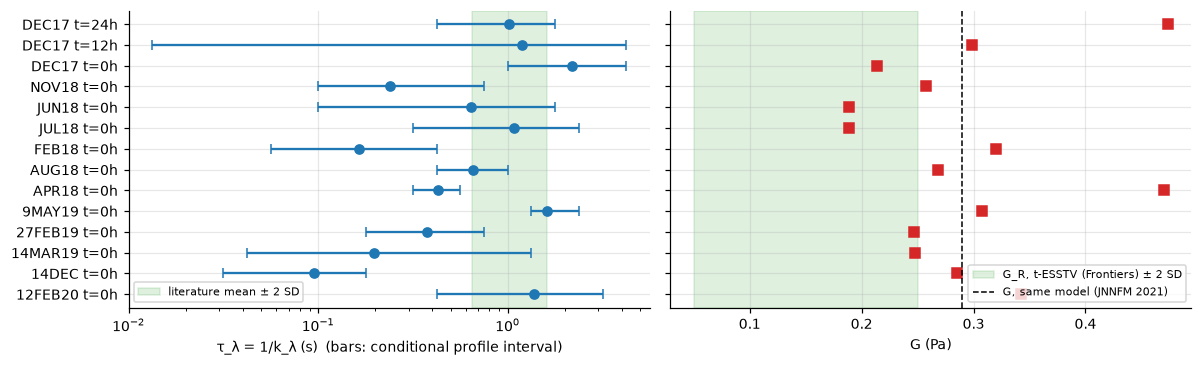

In [59]:
mu, sd = TAU_LAMBDA_LIT
okm = models[~models.k_at_bound]
print(f"tau_lambda (this data): median {okm.tau_lambda.median():.2f} s, IQR {okm.tau_lambda.quantile(.25):.2f}-"
      f"{okm.tau_lambda.quantile(.75):.2f} s  (n = {len(okm)} workbook x storage fits, {okm['sample'].nunique()} workbooks)")
print(f"   literature: {mu} +- {sd} s (Frontiers 2022, 12 donors); 0.55-0.96 s (Sci. Rep. 2021, Donor 1)")
print(f"   fits within literature mean +- 2 SD: {((okm.tau_lambda - mu).abs() <= 2 * sd).sum()} / {len(okm)}")
print(f"G (this data): median {okm.G.median():.3f} Pa, range {okm.G.min():.3f}-{okm.G.max():.3f} Pa"
      f";  literature: G = {G_LIT_V1} Pa (same model, JNNFM 2021), G_R = {G_LIT_R[0]} +- {G_LIT_R[1]} Pa (t-ESSTV, Frontiers 2022)")
print(f"steps fitted within threshold: {(steps.nrmse_model <= steps.fit_threshold).sum()} / {steps.nrmse_model.notna().sum()}")
print("\nfit quality by final shear rate (median NRMSE):")
print(steps.groupby(["direction", "rate_to"]).nrmse_model.median().unstack(0).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
yy = np.arange(len(models)); names = [f'{s_} t={int(h)}h' for s_, h in zip(models["sample"], models.storage_h)]
ax[0].errorbar(models.tau_lambda, yy, xerr=[models.tau_lambda - models.tau_lambda_lo, models.tau_lambda_hi - models.tau_lambda],
               fmt="o", capsize=3)
ax[0].axvspan(mu - 2 * sd, mu + 2 * sd, color="C2", alpha=0.15, label="literature mean ± 2 SD")
ax[0].set(xscale="log", xlabel="τ_λ = 1/k_λ (s)  (bars: conditional profile interval)"); ax[0].legend(loc="lower left", fontsize=7)
ax[1].plot(models.G, yy, "s", color="C3")
ax[1].axvspan(G_LIT_R[0] - 2 * G_LIT_R[1], G_LIT_R[0] + 2 * G_LIT_R[1], color="C2", alpha=0.15, label="G_R, t-ESSTV (Frontiers) ± 2 SD")
ax[1].axvline(G_LIT_V1, color="k", ls="--", lw=1, label="G, same model (JNNFM 2021)")
ax[1].set(xlabel="G (Pa)"); ax[1].legend(loc="lower right", fontsize=7)
ax[0].set_yticks(yy, names)
fig.tight_layout(); fig.savefig(FIG / "03_tau_lambda_vs_literature.png", dpi=200); plt.show()

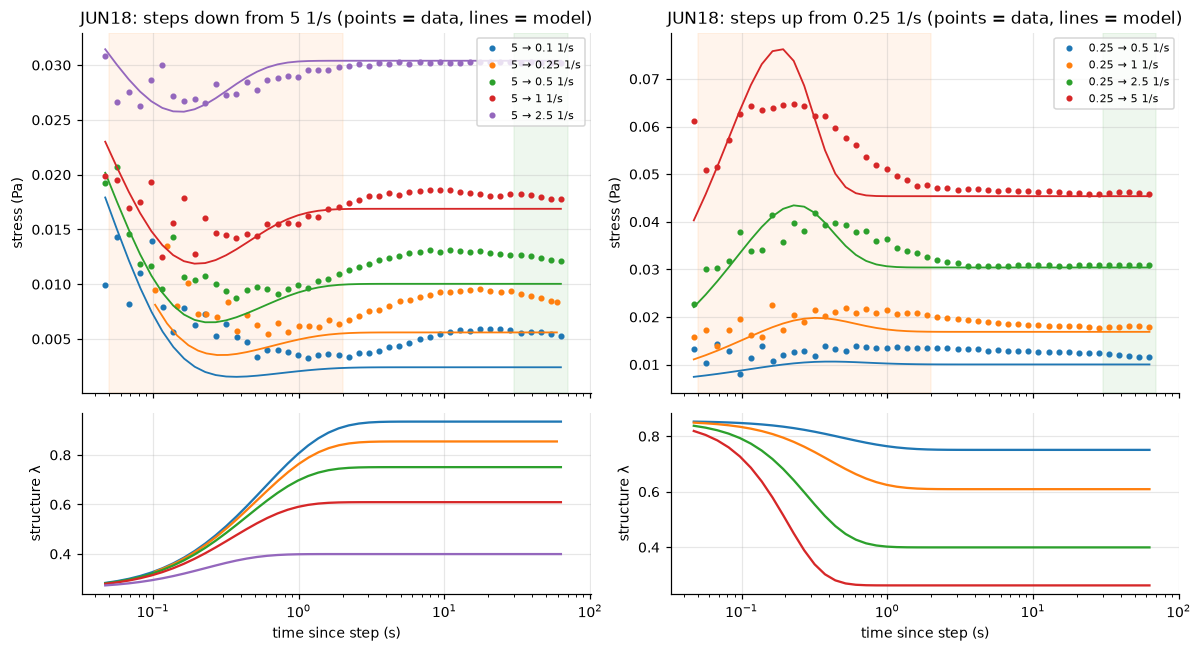

In [60]:
def plot_family(sample, storage_h=0.0, start_down=5.0, start_up=0.25, fname="04_representative_fits.png"):
    q = steps[(steps["sample"] == sample) & (steps.storage_h == storage_h)]
    fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    for col, (dirn, g0) in enumerate([("down", start_down), ("up", start_up)]):
        sub = q[(q.direction == dirn) & np.isclose(q.rate_from, g0)].sort_values("rate_to")
        for i, (_, r) in enumerate(sub.iterrows()):
            b = next(bb for bb in blocks if bb["step_id"] == r.step_id)
            t, y = step_series(b, r)
            ax[0, col].semilogx(t, y, "o", ms=3, color=f"C{i}", label=f"{g0:g} → {r.rate_to:g} 1/s")
            if r.step_id in model_curves:
                tm, fm, lam = model_curves[r.step_id]
                ax[0, col].semilogx(tm, fm, "-", color=f"C{i}", lw=1.2)
                ax[1, col].semilogx(tm, lam, "-", color=f"C{i}")
        ax[0, col].axvspan(0.05, TRANSIENT_END, color="C1", alpha=0.08); ax[0, col].axvspan(STABLE_START, 70, color="C2", alpha=0.08)
        ax[0, col].set(title=f"{sample}: steps {dirn} from {g0:g} 1/s (points = data, lines = model)", ylabel="stress (Pa)")
        ax[0, col].legend(fontsize=7); ax[1, col].set(xlabel="time since step (s)", ylabel="structure λ")
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=200); plt.show()

plot_family("JUN18")

In [61]:
A = steps[steps.qc_rate != "MISMATCH with label"].copy()
A["unit"] = A["sample"] + "_t" + A.storage_h.astype(int).astype(str)     # workbook x storage time
print(f"analysis set: {len(A)} steps, {A['sample'].nunique()} workbooks (independent units), {A.unit.nunique()} workbook x storage units")

def sign_test(x):
    x = np.asarray(x)[np.isfinite(x) & (np.asarray(x) != 0)]
    if len(x) == 0: return np.nan, 0, 0
    k = (x > 0).sum(); return stats.binomtest(k, len(x), 0.5).pvalue, k, len(x)

analysis set: 135 steps, 12 workbooks (independent units), 14 workbook x storage units


In [62]:
rows = []
for (unit, g0, dirn), fam in A.groupby(["unit", "rate_from", "direction"]):
    if len(fam) < 3: continue
    for f in FEATURES:
        x, y = fam.log10_ratio.abs(), fam[f]
        ok = np.isfinite(y)
        if ok.sum() >= 3 and y[ok].nunique() > 1:
            rows.append(dict(unit=unit, sample=fam["sample"].iloc[0], family=f"{g0:g}->*", direction=dirn,
                             feature=f, n=ok.sum(), rho=stats.spearmanr(x[ok], y[ok])[0]))
mag = pd.DataFrame(rows)
per_wb = mag.groupby(["feature", "direction", "sample"]).rho.mean().reset_index()
res_mag = []
for (f, dirn), g in per_wb.groupby(["feature", "direction"]):
    p, k, n = sign_test(g.rho)
    res_mag.append(dict(feature=f, direction=dirn, n_workbooks=n, median_rho=g.rho.median(),
                        workbooks_rho_pos=k, sign_test_p=p, families=int((mag.feature.eq(f) & mag.direction.eq(dirn)).sum())))
res_mag = pd.DataFrame(res_mag).sort_values(["direction", "sign_test_p"])
res_mag.to_csv(OUT / "result_magnitude.csv", index=False)
res_mag.round(3)

,feature,direction,n_workbooks,median_rho,workbooks_rho_pos,sign_test_p,families
12,t_min,down,9,0.900,9,0.004,11
16,undershoot,down,8,1.000,8,0.008,10
18,visc_ratio,down,8,1.000,8,0.008,10
14,t_peak,down,9,0.600,8,0.039,11
6,overshoot,down,8,0.800,7,0.070,10
0,area_log,down,8,-0.933,2,0.289,10
2,init_slope,down,8,-0.250,4,1.000,10
4,jump_signed,down,8,0.317,4,1.000,10
8,relax_amp,down,8,0.150,4,1.000,10
10,settling_time,down,9,-0.200,4,1.000,11


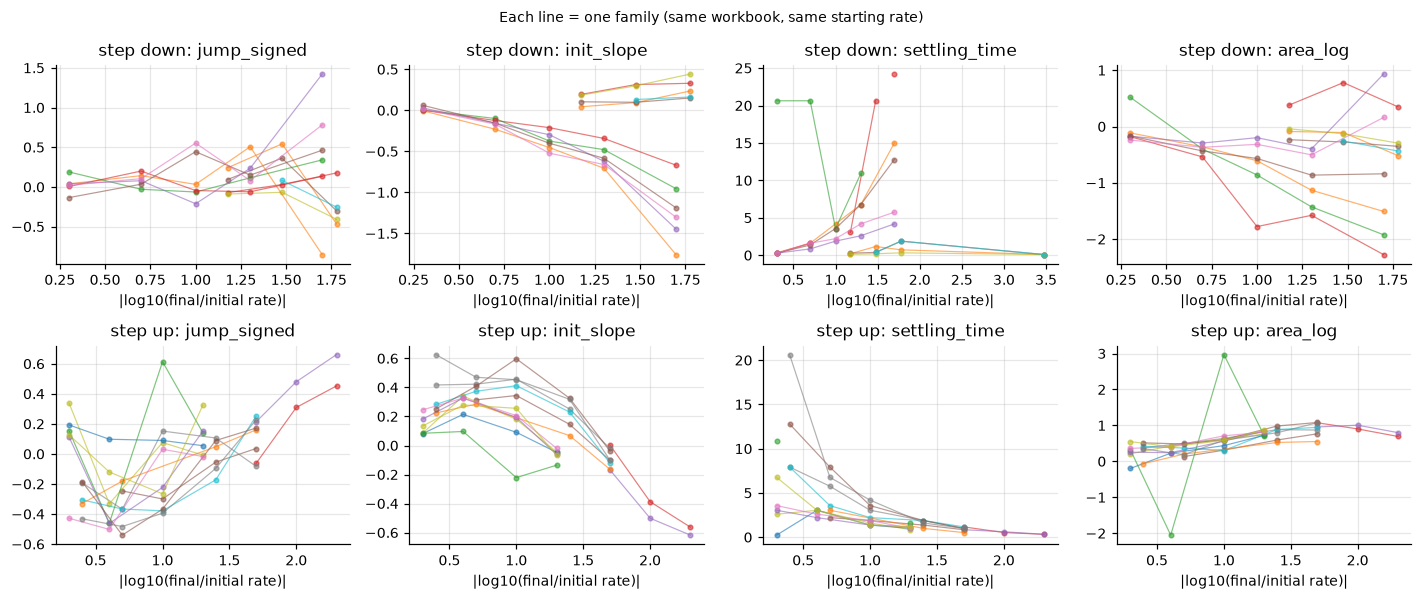

In [63]:
show = ["jump_signed", "init_slope", "settling_time", "area_log"]
fig, ax = plt.subplots(2, len(show), figsize=(13, 5.5))
for row, dirn in enumerate(["down", "up"]):
    for col, f in enumerate(show):
        a = ax[row, col]
        for i, ((unit, g0), fam) in enumerate(A[A.direction == dirn].groupby(["unit", "rate_from"])):
            if len(fam) < 3: continue
            fam = fam.sort_values("log10_ratio")
            a.plot(fam.log10_ratio.abs(), fam[f], "o-", ms=3, lw=0.8, alpha=0.6, color=f"C{i % 10}")
        a.set(title=f"step {dirn}: {f}", xlabel="|log10(final/initial rate)|")
fig.suptitle("Each line = one family (same workbook, same starting rate)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "05_magnitude.png", dpi=200); plt.show()

In [64]:
pairs = []
for unit, g in A.groupby("unit"):
    for _, u in g[g.direction == "up"].iterrows():
        dn = g[(g.direction == "down") & np.isclose(g.rate_from, u.rate_to) & np.isclose(g.rate_to, u.rate_from)]
        if len(dn):
            dn = dn.iloc[0]
            pairs.append(dict(unit=unit, sample=u["sample"], pair=f"{u.rate_from:g}<->{u.rate_to:g}",
                              up_id=u.step_id, down_id=dn.step_id,
                              **{f"d_{f}": u[f] - dn[f] for f in FEATURES},
                              **{f"up_{f}": u[f] for f in FEATURES}, **{f"down_{f}": dn[f] for f in FEATURES}))
pairs = pd.DataFrame(pairs)
print(f"{len(pairs)} matched reverse pairs from {pairs['sample'].nunique()} workbooks:",
      pairs.groupby("pair").size().to_dict())

res_dir = []
for f in FEATURES:
    wbm = pairs.groupby("sample")[f"d_{f}"].mean()
    p, k, n = sign_test(wbm)
    w = stats.wilcoxon(wbm.dropna()).pvalue if wbm.notna().sum() >= 5 else np.nan
    res_dir.append(dict(feature=f, n_workbooks=n, median_up_minus_down=wbm.median(), workbooks_up_gt_down=k,
                        sign_test_p=p, wilcoxon_p=w, pairs_up_gt_down=f"{(pairs[f'd_{f}'] > 0).sum()}/{pairs[f'd_{f}'].notna().sum()}"))
res_dir = pd.DataFrame(res_dir).sort_values("sign_test_p")
res_dir.to_csv(OUT / "result_direction.csv", index=False)
res_dir.round(4)

22 matched reverse pairs from 10 workbooks: {'0.1<->10': 3, '0.1<->20': 3, '0.1<->5': 10, '0.25<->5': 6}


,feature,n_workbooks,median_up_minus_down,workbooks_up_gt_down,sign_test_p,wilcoxon_p,pairs_up_gt_down
2,undershoot,10,-0.4882,0,0.0020,0.0020,0/22
3,init_slope,10,0.8026,10,0.0020,0.0020,22/22
9,visc_ratio,7,-7.6387,0,0.0156,0.0156,0/12
1,overshoot,10,-0.5816,1,0.0215,0.0059,6/22
4,settling_time,10,-6.8647,1,0.0215,0.0137,1/18
6,t_min,10,31.3444,9,0.0215,0.0059,15/22
7,area_log,10,1.6975,9,0.0215,0.0059,21/22
5,t_peak,10,0.0732,8,0.1094,0.1055,18/22
8,relax_amp,10,0.0093,8,0.1094,0.0371,16/22
0,jump_signed,10,-0.1239,3,0.3438,0.2754,9/22


Direction rule 'jump_signed > 0 => up' on matched pairs: accuracy 0.55 (95% workbook-bootstrap CI 0.46-0.64, n = 44 steps)
Same rule on all steps (confounded by starting rate): 0.43


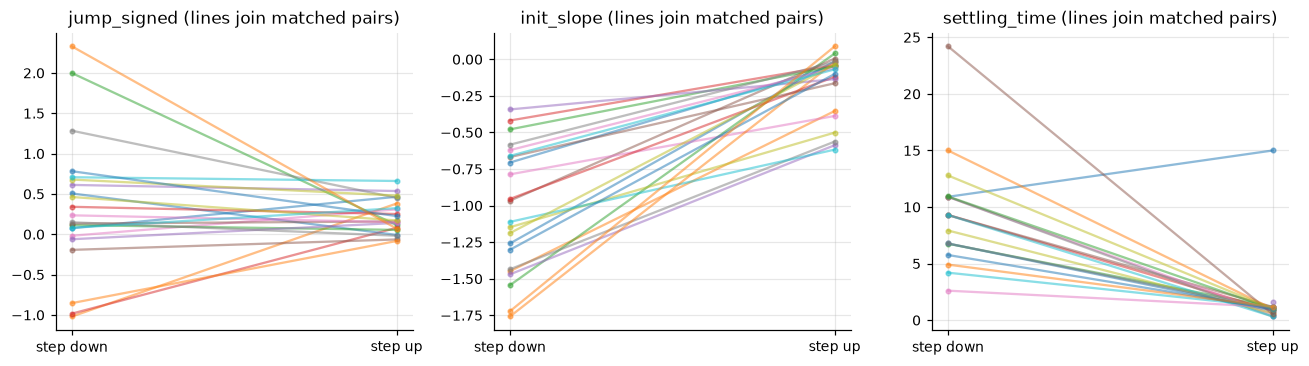

In [65]:
def rule_accuracy(df):
    ok = df.jump_signed.notna()
    return ((df.jump_signed[ok] > 0) == (df.direction[ok] == "up")).mean()

paired_ids = set(pairs.up_id) | set(pairs.down_id)
P = A[A.step_id.isin(paired_ids)]
rng = np.random.default_rng(0)
samples = P["sample"].unique()
boot = [rule_accuracy(pd.concat([P[P["sample"] == s] for s in rng.choice(samples, len(samples))])) for _ in range(2000)]
print(f"Direction rule 'jump_signed > 0 => up' on matched pairs: accuracy {rule_accuracy(P):.2f} "
      f"(95% workbook-bootstrap CI {np.percentile(boot, 2.5):.2f}-{np.percentile(boot, 97.5):.2f}, n = {len(P)} steps)")
print(f"Same rule on all steps (confounded by starting rate): {rule_accuracy(A):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, f in zip(ax, ["jump_signed", "init_slope", "settling_time"]):
    for _, r in pairs.iterrows():
        a.plot([0, 1], [r[f"down_{f}"], r[f"up_{f}"]], "-o", ms=3, alpha=0.5)
    a.set_xticks([0, 1], ["step down", "step up"]); a.set_title(f"{f} (lines join matched pairs)")
fig.tight_layout(); fig.savefig(FIG / "06_direction_pairs.png", dpi=200); plt.show()

In [66]:
def window_desc(d, t0, t1, ss):
    w = window(d, t0, t1)
    if len(w) < 3 or not np.isfinite(ss) or abs(ss) < NOISE_PA: return dict(abs_slope=np.nan, abs_dev=np.nan, cv=np.nan)
    x = np.log10(w.time.values); y = w.stress.values / ss
    return dict(abs_slope=abs(np.polyfit(x, y, 1)[0]), abs_dev=np.mean(np.abs(y - 1)), cv=np.std(y) / abs(np.mean(y)))

def phase_table(t_trans_end, t_stable_start):
    rows = []
    for _, r in A.iterrows():
        b = next(bb for bb in blocks if bb["step_id"] == r.step_id)
        ws = window(b["an"], t_stable_start, np.inf); ss = np.median(ws.stress) if len(ws) else np.nan
        rows.append(dict(step_id=r.step_id, sample=r["sample"], stable_ok=r.stable_ok,
                         **{f"T_{k}": v for k, v in window_desc(b["an"], r.t_rate_settle, t_trans_end, ss).items()},
                         **{f"S_{k}": v for k, v in window_desc(b["an"], t_stable_start, np.inf, ss).items()}))
    return pd.DataFrame(rows)

def phase_result(ph, label):
    out = []
    for k in ["abs_slope", "abs_dev", "cv"]:
        diff = np.log10(ph[f"T_{k}"].clip(lower=1e-6) / ph[f"S_{k}"].clip(lower=1e-6))   # log ratio transient/stable
        wbm = diff.groupby(ph["sample"]).median()
        p, kk, n = sign_test(wbm)
        out.append(dict(rule=label, descriptor=k, measurements_T_gt_S=f"{(diff > 0).sum()}/{diff.notna().sum()}",
                        median_log10_ratio_T_over_S=diff.median(), workbooks_T_gt_S=f"{kk}/{n}", sign_test_p=p))
    return out

ph = phase_table(TRANSIENT_END, STABLE_START)
res_phase = pd.DataFrame(phase_result(ph, "primary (2 s / 30 s)"))
res_phase.round(4)

,rule,descriptor,measurements_T_gt_S,median_log10_ratio_T_over_S,workbooks_T_gt_S,sign_test_p
0,primary (2 s / 30 s),abs_slope,108/130,0.5571,12/12,0.0005
1,primary (2 s / 30 s),abs_dev,129/130,1.4126,12/12,0.0005
2,primary (2 s / 30 s),cv,129/130,1.2956,12/12,0.0005


In [67]:
sens = pd.concat([pd.DataFrame(phase_result(phase_table(a, b), name)) for name, (a, b) in RULE_VARIANTS.items()])
sens.to_csv(OUT / "result_transient_vs_stable.csv", index=False)
sens.pivot(index="descriptor", columns="rule", values="workbooks_T_gt_S")

rule,long (5 s / 40 s),primary (2 s / 30 s),short (1 s / 20 s)
descriptor,,,
abs_dev,12/12,12/12,12/12
abs_slope,10/12,12/12,12/12
cv,12/12,12/12,12/12


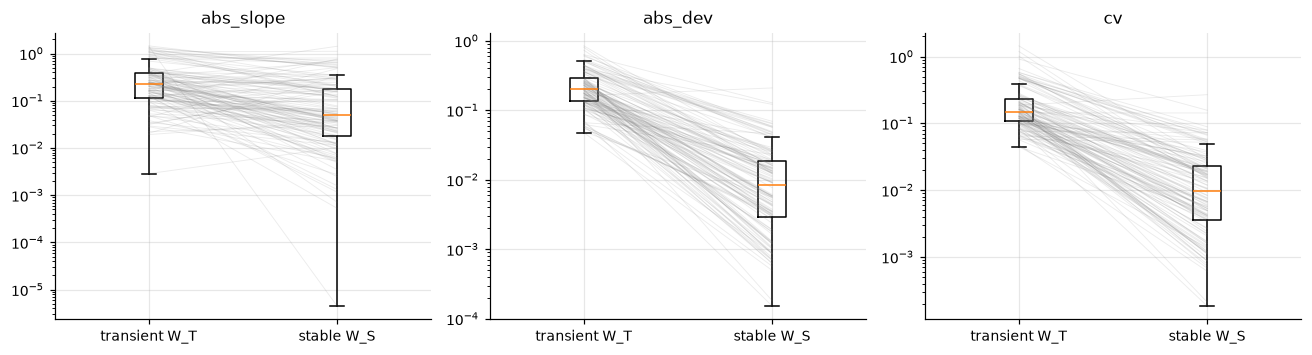

In [68]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for a, k in zip(ax, ["abs_slope", "abs_dev", "cv"]):
    a.boxplot([ph[f"T_{k}"].dropna(), ph[f"S_{k}"].dropna()], tick_labels=["transient W_T", "stable W_S"], showfliers=False)
    for _, r in ph.iterrows():
        a.plot([1, 2], [r[f"T_{k}"], r[f"S_{k}"]], color="grey", alpha=0.15, lw=0.6)
    a.set_yscale("log"); a.set_title(k)
fig.tight_layout(); fig.savefig(FIG / "07_transient_vs_stable.png", dpi=200); plt.show()

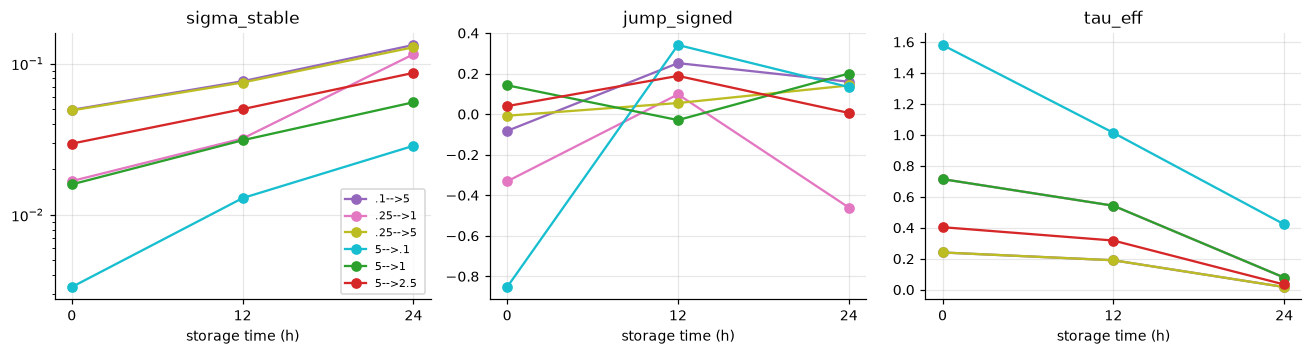

,storage_h,tau_lambda,G,sigma_y0,eta_ST,eta_inf,tr1,tr2
11,0.0,2.1730,0.2135,0.0011,0.0217,0.0027,1.2527,0.7886
12,12.0,1.1921,0.2985,0.0000,0.0358,0.0038,0.9346,0.2619
13,24.0,1.0159,0.4734,0.0004,0.3437,0.0052,10.9609,0.9796


In [69]:
dec = A[A["sample"] == "DEC17"]
if len(dec):
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
    for a, f in zip(ax, ["sigma_stable", "jump_signed", "tau_eff"]):
        for i, (lab, g) in enumerate(dec.groupby("label")):
            g = g.sort_values("storage_h")
            if g.storage_h.nunique() == 3 and lab.split("(")[0].strip() in ("5-->.1", ".1-->5", "5-->1", ".25-->1", ".25-->5", "5-->2.5"):
                a.plot(g.storage_h, g[f], "o-", label=lab.split("(")[0], color=f"C{i % 10}")
        a.set(xlabel="storage time (h)", title=f, xticks=[0, 12, 24])
        if f == "sigma_stable": a.set_yscale("log")
    ax[0].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(FIG / "08_dec17_storage.png", dpi=200); plt.show()
    display(models[models["sample"] == "DEC17"][["storage_h", "tau_lambda", "G", "sigma_y0", "eta_ST", "eta_inf", "tr1", "tr2"]].round(4))

In [70]:
def verdict(p, share):
    """'yes' = consistent in >= 80 % of workbooks AND sign-test p < 0.05; otherwise 'no'."""
    if not np.isfinite(p): return "n/a"
    return "yes" if p < 0.05 and max(share, 1 - share) >= 0.8 else "no"

rel = []
for f in FEATURES:
    row = dict(feature=f, computable=round(A[f].notna().mean(), 2))
    for dirn in ("down", "up"):
        m = res_mag[(res_mag.feature == f) & (res_mag.direction == dirn)]
        row[f"magnitude_{dirn}"] = (verdict(m.sign_test_p.iloc[0], m.workbooks_rho_pos.iloc[0] / max(m.n_workbooks.iloc[0], 1))
                                    if len(m) else "n/a")
    d = res_dir[res_dir.feature == f]
    row["direction"] = verdict(d.sign_test_p.iloc[0], d.workbooks_up_gt_down.iloc[0] / max(d.n_workbooks.iloc[0], 1)) if len(d) else "n/a"
    n_yes = sum(row[k] == "yes" for k in ("magnitude_down", "magnitude_up", "direction"))
    row["needs_stable_state"] = f in ("jump_signed", "overshoot", "undershoot", "init_slope", "area_log", "settling_time")
    row["classification"] = "unusable" if row["computable"] < 0.5 else "reliable" if row["computable"] >= 0.8 and n_yes else "inconclusive"
    rel.append(row)
fit_share = (fits_exp.status == "ok").mean()
rel.append(dict(feature="tau (single exponential)", computable=round(fit_share, 2),
                classification="unusable" if fit_share < 0.5 else "inconclusive"))
rel.append(dict(feature="tau_lambda, G (ethixo-EVP, per workbook)", computable=round((~models.k_at_bound).mean(), 2),
                classification="reliable" if (~models.k_at_bound).mean() >= 0.8 else "inconclusive"))
rel = pd.DataFrame(rel)
rel.to_csv(OUT / "metric_reliability.csv", index=False)
rel

,feature,computable,magnitude_down,magnitude_up,direction,needs_stable_state,classification
0,jump_signed,0.96,no,yes,no,True,reliable
1,overshoot,0.96,no,yes,yes,True,reliable
2,undershoot,0.96,yes,yes,yes,True,reliable
3,init_slope,0.96,no,yes,yes,True,reliable
4,settling_time,0.93,no,yes,yes,True,reliable
5,t_peak,1.00,yes,no,no,False,reliable
6,t_min,1.00,yes,no,yes,False,reliable
7,area_log,0.96,no,no,yes,True,reliable
8,relax_amp,0.96,no,yes,no,False,reliable
9,visc_ratio,0.81,yes,yes,yes,False,reliable


In [71]:
print("=== Data and verification ===")
print(f"step blocks analysed: {len(A)} from {A['sample'].nunique()} workbooks; label mismatches excluded: {(steps.qc_rate == 'MISMATCH with label').sum()}")
print(f"instrument window (rate settling): median {ev.t_rate_settle.median():.3f} s, max {ev.t_rate_settle.max():.3f} s")
print(f"defensible stable state within 63 s: {A.stable_ok.mean():.0%} of steps")
print("\n=== Relaxation model ===")
print(f"single exponential interpretable: {(fits_exp.status == 'ok').mean():.0%} of steps")
okm = models[~models.k_at_bound]
print(f"ethixo-EVP tau_lambda: median {okm.tau_lambda.median():.2f} s over {len(okm)} identifiable fits "
      f"(literature 1.13 +- 0.24 s); steps with acceptable fit (NRMSE <= {MODEL_MAX_NRMSE}): "
      f"{(A.nrmse_model <= A.fit_threshold).mean():.0%}")
print("\n=== Questions ===")
print("Magnitude (strongest):"); print(res_mag.nsmallest(3, "sign_test_p")[["feature", "direction", "median_rho", "workbooks_rho_pos", "n_workbooks", "sign_test_p"]].round(3).to_string(index=False))
print("Direction (matched pairs):"); print(res_dir.head(3)[["feature", "median_up_minus_down", "workbooks_up_gt_down", "n_workbooks", "sign_test_p"]].round(4).to_string(index=False))
print("Transient vs stable (all rule variants):"); print(sens[["rule", "descriptor", "workbooks_T_gt_S", "sign_test_p"]].round(4).to_string(index=False))
print(f"\nAll tables written to {OUT.resolve()}")

=== Data and verification ===
step blocks analysed: 135 from 12 workbooks; label mismatches excluded: 3
instrument window (rate settling): median 0.050 s, max 0.108 s
defensible stable state within 63 s: 87% of steps

=== Relaxation model ===
single exponential interpretable: 50% of steps
ethixo-EVP tau_lambda: median 0.65 s over 14 identifiable fits (literature 1.13 +- 0.24 s); steps with acceptable fit (NRMSE <= 0.1): 39%

=== Questions ===
Magnitude (strongest):
   feature direction  median_rho  workbooks_rho_pos  n_workbooks  sign_test_p
     t_min      down         0.9                  9            9        0.004
undershoot      down         1.0                  8            8        0.008
visc_ratio      down         1.0                  8            8        0.008
Direction (matched pairs):
   feature  median_up_minus_down  workbooks_up_gt_down  n_workbooks  sign_test_p
undershoot               -0.4882                     0           10       0.0020
init_slope                0.8

In [72]:
RAW_OUT = PROJECT_ROOT / "01_Active_Blood_Project" / "04_Results" / "Existing_Analysis" / "analysis_outputs" / "raw_workbook_step_analysis"
if (RAW_OUT / "step_features.csv").exists():
    raw = pd.read_csv(RAW_OUT / "step_features.csv")
    key = ["workbook", "sheet", "label"]
    cmp = steps.merge(raw, on=key, suffixes=("_main", "_raw"))
    print(f"matched {len(cmp)} of {len(steps)} main-data steps to the raw-workbook run ({len(raw)} steps there)")
    only_main = steps[~steps.set_index(key).index.isin(raw.set_index(key).index)]
    only_raw = raw[~raw.set_index(key).index.isin(steps.set_index(key).index)]
    print("\nonly in main-data run:")
    print(only_main[["step_id", "sample", "sheet", "label", "qc_rate"]].to_string(index=False) if len(only_main) else "  none")
    print("\nonly in raw-workbook run:")
    print(only_raw[["step_id", "sample", "sheet", "label", "qc_rate"]].to_string(index=False) if len(only_raw) else "  none")
    rows = []
    for f in ["sigma_pre", "sigma_stable", "jump_signed", "overshoot", "undershoot", "init_slope", "settling_time", "t_min"]:
        a_, b_ = cmp[f + "_main"], cmp[f + "_raw"]
        both = a_.notna() & b_.notna()
        rows.append(dict(feature=f, compared=int(both.sum()),
                         identical=int(np.isclose(a_[both], b_[both], rtol=1e-9, atol=1e-12).sum()),
                         max_abs_diff=float(np.max(np.abs(a_[both] - b_[both]))) if both.any() else np.nan))
    print("\nfeature agreement on matched steps:"); display(pd.DataFrame(rows))
    rawm = pd.read_csv(RAW_OUT / "relaxation_fits.csv")
    cm = models.merge(rawm, on=["workbook", "storage_h"], suffixes=("_main", "_raw"))
    display(cm[["sample_main", "storage_h", "n_steps_main", "n_steps_raw", "tau_lambda_main", "tau_lambda_raw",
                "G_main", "G_raw"]].round(3))
    for name, k in [("result_magnitude", ["feature", "direction"]), ("result_direction", ["feature"])]:
        j = pd.read_csv(OUT / f"{name}.csv").merge(pd.read_csv(RAW_OUT / f"{name}.csv"), on=k, suffixes=("_main", "_raw"))
        agree = ((j.sign_test_p_main < 0.05) == (j.sign_test_p_raw < 0.05)).mean()
        print(f"{name}: same significance verdict (p < 0.05) for {agree:.0%} of {len(j)} feature rows")
else:
    print("Run Member3_Step_UpDown_Analysis.ipynb first to create step_analysis_outputs/ for this comparison.")

matched 136 of 138 main-data steps to the raw-workbook run (136 steps there)

only in main-data run:
step_id sample    sheet    label                            qc_rate
P1M0143  AUG18 300 to 5 300 to 5 label only (no shear-rate channel)
P1M0144  AUG18 0.1 to 5 0.1 to 5 label only (no shear-rate channel)

only in raw-workbook run:
  none

feature agreement on matched steps:


,feature,compared,identical,max_abs_diff
0,sigma_pre,130,130,0.000000e+00
1,sigma_stable,131,131,6.591949e-17
2,jump_signed,131,131,2.220446e-16
3,overshoot,131,131,1.110223e-16
4,undershoot,131,131,9.714451e-17
5,init_slope,131,131,2.220446e-16
6,settling_time,126,126,0.000000e+00
7,t_min,136,136,2.220446e-16


,sample_main,storage_h,n_steps_main,n_steps_raw,tau_lambda_main,tau_lambda_raw,G_main,G_raw
0,12FEB20,0.0,9,9,1.371,1.371,0.342,0.342
1,14DEC,0.0,5,5,0.095,0.095,0.286,0.286
2,14MAR19,0.0,9,9,0.196,0.196,0.248,0.248
3,27FEB19,0.0,10,10,0.375,0.375,0.247,0.247
4,9MAY19,0.0,9,9,1.618,1.618,0.307,0.307
5,APR18,0.0,6,6,0.426,0.426,0.470,0.470
6,FEB18,0.0,10,10,0.163,0.163,0.320,0.320
7,JUL18,0.0,14,14,1.080,0.922,0.189,0.192
8,JUN18,0.0,14,14,0.641,0.641,0.189,0.189
9,NOV18,0.0,6,6,0.238,0.238,0.257,0.257


result_magnitude: same significance verdict (p < 0.05) for 100% of 20 feature rows
result_direction: same significance verdict (p < 0.05) for 100% of 10 feature rows


# Fourier and wavelet feature development

This section develops a focused, reproducible comparison of global Fourier analysis, the short-time Fourier transform (STFT), the continuous wavelet transform (CWT), and the discrete wavelet transform (DWT). It uses the real human-blood measurements only. The ten synthetic datasets and ground-truth benchmark are reserved for a separate notebook.

The comparison uses the final LAOS feature cohort (181 measurements) and the 136 step measurements that have a verified ID crosswalk to the standardized signal catalogue. LAOS features use the final two nominal oscillation cycles, matching the conventional LAOS analysis. Step features use the instrument-settled transient window from the existing analysis. A second full-response transform analysis is restricted to the six high-resolution steps, where both transient and stable windows have enough samples to support time-localised comparisons.

Most step signals contain about 65 non-uniformly spaced observations over 63 seconds. Interpolating these sparse records onto a dense grid would create apparent detail that was never measured. The code therefore audits native window support, applies the same methods to the same transient-window records, and flags limited DWT frequency support. Stable-window transform ratios are only reported for records with adequate native coverage. Results from six high-resolution steps are descriptive, not population-level evidence.

## Transform definitions and comparison rules

For a demeaned, normalised signal $x[n]$, the global discrete Fourier transform is

$$X[k] = \sum_{n=0}^{N-1} x[n] e^{-2\pi i kn/N}.$$

The STFT repeats a windowed Fourier transform as the window moves through time,

$$X(m, f) = \sum_n x[n] w[n-mH] e^{-2\pi i fn/N_w},$$

where $w$ is the selected window and $H$ is the hop length. The CWT evaluates localised wavelet coefficients over physical scale and time,

$$W(a,b) = \frac{1}{\sqrt{|a|}}\int x(t)\,\psi^*\!\left(\frac{t-b}{a}\right)dt,$$

and the DWT represents the signal with a finite set of octave-like detail bands. Frequencies are derived from the sampling interval and the wavelet scale; they are not treated as scale labels without units.

All methods receive demeaned, RMS-normalised stress signals on the same window for each comparison cohort. LAOS uses the final two cycles. Step comparisons use the same instrument-settled transient window for all four methods; the full transient-to-stable energy comparison uses the same six high-resolution steps for all methods. Absolute stress scale remains available in the accompanying baseline features. One complex Morlet family (`cmor1.5-1.0`) and one DWT family (`db4`) are fixed in advance to keep the wavelet search focused.

## 1. Loading data and fixing transform settings

The primary analysis windows and method settings are collected here. Resampling is limited to 50 Hz for LAOS and 10 Hz for the short step transient window. These rates preserve the measured resolution of each cohort without expanding the common low-resolution step traces to the LAOS sampling rate.

In [73]:
from pathlib import Path
import time
import re
import numpy
import pandas
import pywt as pywavelets
import matplotlib.pyplot as pyplot
from scipy import signal as scipy_signal
from scipy import stats as scipy_stats
from IPython.display import display

pyplot.close("all")

pyplot.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Locating the consolidated project from its manifest
transform_search_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
transform_search_roots.append(Path.home() / "Desktop" / "Haemograph_Project")
TRANSFORM_PROJECT_ROOT = next(
    (candidate_path for candidate_path in transform_search_roots if (candidate_path / "MOVE_MANIFEST.csv").is_file()),
    None,
)
if TRANSFORM_PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate Haemograph_Project from its move manifest.")

TRANSFORM_PROCESSING_DIRECTORY = TRANSFORM_PROJECT_ROOT / "03_Team_Contributions" / "Part1_Data_Processing" / "Extracted_Contents" / "main-data"
TRANSFORM_STEP_OUTPUT_DIRECTORY = TRANSFORM_PROJECT_ROOT / "03_Team_Contributions" / "Part3_Step_Transient_Analysis" / "outputs"
TRANSFORM_INTEGRATION_OUTPUT_DIRECTORY = TRANSFORM_PROJECT_ROOT / "01_Active_Blood_Project" / "04_Results" / "Integrated_Feature_Analysis"
TRANSFORM_RESULTS_DIRECTORY = TRANSFORM_PROJECT_ROOT / "01_Active_Blood_Project" / "04_Results" / "Fourier_Wavelet_Feature_Development"
TRANSFORM_FIGURE_DIRECTORY = TRANSFORM_RESULTS_DIRECTORY / "figures"
TRANSFORM_RESULTS_DIRECTORY.mkdir(parents=True, exist_ok=True)
TRANSFORM_FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)

TRANSFORM_LAOS_FEATURE_MATCHES = list(TRANSFORM_PROJECT_ROOT.glob("03_Team_Contributions/Part2*/Extracted_Contents/*/laos_features.csv"))
if len(TRANSFORM_LAOS_FEATURE_MATCHES) != 1:
    raise FileNotFoundError(f"Expected one final LAOS feature table; found {len(TRANSFORM_LAOS_FEATURE_MATCHES)}.")
TRANSFORM_LAOS_FEATURES_PATH = TRANSFORM_LAOS_FEATURE_MATCHES[0]
TRANSFORM_SIGNALS_PATH = TRANSFORM_PROCESSING_DIRECTORY / "standardized_signals.csv.gz"
TRANSFORM_MEASUREMENT_INDEX_PATH = TRANSFORM_PROCESSING_DIRECTORY / "measurement_index.csv"
TRANSFORM_STEP_FEATURES_PATH = TRANSFORM_STEP_OUTPUT_DIRECTORY / "step_features.csv"
TRANSFORM_STEP_EVENTS_PATH = TRANSFORM_STEP_OUTPUT_DIRECTORY / "step_events.csv"
TRANSFORM_STEP_CROSSWALK_PATH = TRANSFORM_INTEGRATION_OUTPUT_DIRECTORY / "step_measurement_id_crosswalk.csv"

# Fixing physical windows and a small prespecified method set
TRANSFORM_LAOS_CYCLE_COUNT = 2
TRANSFORM_LAOS_SAMPLING_FREQUENCY_HZ = 50.0
TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ = 10.0
TRANSFORM_STEP_LOW_SENSITIVITY_FREQUENCY_HZ = 5.0
TRANSFORM_STEP_TRANSIENT_END_SECONDS = 2.0
TRANSFORM_STEP_STABLE_START_SECONDS = 30.0
TRANSFORM_CWT_WAVELET_NAME = "cmor1.5-1.0"
TRANSFORM_DWT_WAVELET_NAME = "db4"
TRANSFORM_CWT_SCALE_COUNT = 32
TRANSFORM_CWT_MINIMUM_VALID_COEFFICIENT_FRACTION = 0.25
TRANSFORM_DWT_MAXIMUM_LEVEL = 6
TRANSFORM_STFT_OVERLAP_FRACTION = 0.75
TRANSFORM_MINIMUM_WINDOW_SAMPLE_COUNT = 16
TRANSFORM_LAOS_HIGH_FREQUENCY_MULTIPLIER = 3.0
TRANSFORM_STEP_HIGH_FREQUENCY_SPLIT_HZ = 1.0

# Loading the standardized inputs and saved conventional feature baselines
transform_measurement_index = pandas.read_csv(TRANSFORM_MEASUREMENT_INDEX_PATH)
transform_signal_data = pandas.read_csv(
    TRANSFORM_SIGNALS_PATH,
    usecols=["measurement_id", "time_s", "stress_pa", "strain_pct", "shear_rate_1_s"],
)
transform_laos_baselines = pandas.read_csv(TRANSFORM_LAOS_FEATURES_PATH)
transform_step_baselines = pandas.read_csv(TRANSFORM_STEP_FEATURES_PATH)
transform_step_events_source = pandas.read_csv(TRANSFORM_STEP_EVENTS_PATH)
transform_step_crosswalk = pandas.read_csv(TRANSFORM_STEP_CROSSWALK_PATH)

print("Project root:", TRANSFORM_PROJECT_ROOT)
print("PyWavelets version:", pywavelets.__version__)
print("Standardized signal rows:", transform_signal_data.shape[0])
print("Final LAOS baseline rows:", transform_laos_baselines.shape[0])
print("Step analysis rows:", transform_step_baselines.shape[0])


Project root: /Users/riamishra/Desktop/Haemograph_Project
PyWavelets version: 1.8.0
Standardized signal rows: 437956
Final LAOS baseline rows: 181
Step analysis rows: 136


## 2. Building common measurement cohorts and checking native sampling

The LAOS cohort is restricted to identifiers in the final conventional feature table. Step measurements are mapped through the supplied ID crosswalk. The transient window begins when the instrument rate has settled and ends at 2 seconds; the stable window begins at 30 seconds. The support audit is retained for every step measurement so low-resolution records are visible rather than silently discarded.

In [74]:
transform_measurement_metadata_columns = [
    "measurement_id", "source_file", "sheet", "experiment_type", "experiment_subtype",
    "condition_label", "omega_label_rad_s", "strain_amplitude_label_fraction", "n_points", "duration_s",
]
transform_measurement_metadata = transform_measurement_index[transform_measurement_metadata_columns].copy()

transform_laos_baseline_columns = [
    "measurement_id", "G_prime_Pa", "G_double_prime_Pa", "phase_angle_deg", "I3_I1",
    "I5_I1", "THD_2to5", "lissajous_normalized_area",
]
transform_laos_metadata = transform_measurement_metadata.loc[
    transform_measurement_metadata["experiment_type"].eq("LAOS")
].merge(
    transform_laos_baselines[transform_laos_baseline_columns],
    on="measurement_id",
    how="inner",
    validate="one_to_one",
)

transform_step_crosswalk_columns = ["step_id", "measurement_id"]
transform_step_feature_columns = [
    "step_id", "sample", "label", "storage_h", "rate_from", "rate_to", "direction",
    "log10_ratio", "high_res", "n_points", "t_step", "t_rate_settle", "sigma_pre",
    "undershoot", "init_slope", "settling_time", "t_peak", "t_min", "area_log",
]
transform_step_index_columns = ["measurement_id", "source_file", "sheet", "experiment_subtype", "condition_label", "duration_s"]
transform_step_metadata = transform_step_baselines[transform_step_feature_columns].merge(
    transform_step_crosswalk[transform_step_crosswalk_columns],
    on="step_id",
    how="inner",
    validate="one_to_one",
).merge(
    transform_measurement_index[transform_step_index_columns],
    on="measurement_id",
    how="left",
    validate="one_to_one",
)

transform_step_event_columns = ["step_id", "t_rate_settle", "direction", "log10_ratio", "rate_from", "rate_to"]
transform_step_events = transform_step_events_source[transform_step_event_columns].merge(
    transform_step_crosswalk[transform_step_crosswalk_columns],
    on="step_id",
    how="inner",
    validate="one_to_one",
)

# Grouping signal rows by measurement identifier for repeated trace access
transform_signals_by_measurement = {}
for measurement_identifier, measurement_signal_frame in transform_signal_data.groupby("measurement_id", sort=False):
    transform_signals_by_measurement[str(measurement_identifier)] = measurement_signal_frame.sort_values("time_s").reset_index(drop=True)

# Auditing observed time support within the shared step windows
transform_step_event_lookup = transform_step_events.set_index("measurement_id").to_dict(orient="index")
transform_step_sampling_audit_records = []
for step_metadata_row in transform_step_metadata.itertuples(index=False):
    measurement_identifier = str(step_metadata_row.measurement_id)
    measurement_signal_frame = transform_signals_by_measurement.get(measurement_identifier)
    event_record = transform_step_event_lookup.get(measurement_identifier)
    if measurement_signal_frame is None or event_record is None:
        continue

    measurement_time_values = measurement_signal_frame["time_s"].to_numpy(dtype=float)
    positive_time_intervals = numpy.diff(measurement_time_values)
    positive_time_intervals = positive_time_intervals[positive_time_intervals > 0]
    transient_time_values = measurement_signal_frame.loc[
        measurement_signal_frame["time_s"].between(float(event_record["t_rate_settle"]), TRANSFORM_STEP_TRANSIENT_END_SECONDS),
        "time_s",
    ].to_numpy(dtype=float)
    stable_time_values = measurement_signal_frame.loc[
        measurement_signal_frame["time_s"].ge(TRANSFORM_STEP_STABLE_START_SECONDS),
        "time_s",
    ].to_numpy(dtype=float)
    transient_time_intervals = numpy.diff(transient_time_values)
    stable_time_intervals = numpy.diff(stable_time_values)
    transient_time_intervals = transient_time_intervals[transient_time_intervals > 0]
    stable_time_intervals = stable_time_intervals[stable_time_intervals > 0]

    transform_step_sampling_audit_records.append({
        "measurement_id": measurement_identifier,
        "source_file": step_metadata_row.source_file,
        "condition_label": step_metadata_row.condition_label,
        "direction": event_record["direction"],
        "log10_ratio": event_record["log10_ratio"],
        "native_sample_count": len(measurement_signal_frame),
        "high_resolution": len(measurement_signal_frame) > 1000,
        "transient_sample_count": len(transient_time_values),
        "stable_sample_count": len(stable_time_values),
        "whole_trace_median_interval_s": float(numpy.median(positive_time_intervals)) if len(positive_time_intervals) else numpy.nan,
        "whole_trace_p90_interval_s": float(numpy.quantile(positive_time_intervals, 0.90)) if len(positive_time_intervals) else numpy.nan,
        "transient_p90_interval_s": float(numpy.quantile(transient_time_intervals, 0.90)) if len(transient_time_intervals) else numpy.nan,
        "stable_p90_interval_s": float(numpy.quantile(stable_time_intervals, 0.90)) if len(stable_time_intervals) else numpy.nan,
        "transient_transform_eligible": len(transient_time_values) >= TRANSFORM_MINIMUM_WINDOW_SAMPLE_COUNT,
        "transient_and_stable_transform_eligible": (
            len(transient_time_values) >= 64 and len(stable_time_values) >= 64
        ),
    })

transform_step_sampling_audit = pandas.DataFrame(transform_step_sampling_audit_records)
transform_step_cohort_summary = pandas.DataFrame([
    {
        "cohort": "Final LAOS feature cohort",
        "measurements": len(transform_laos_metadata),
        "median_native_samples": float(transform_laos_metadata["n_points"].median()),
        "analysis_window": "Final two nominal cycles",
    },
    {
        "cohort": "Crosswalked step cohort",
        "measurements": len(transform_step_sampling_audit),
        "median_native_samples": float(transform_step_sampling_audit["native_sample_count"].median()),
        "analysis_window": "Instrument-settled transient: [settling, 2 s]",
    },
    {
        "cohort": "Step cohort with transient and stable transform support",
        "measurements": int(transform_step_sampling_audit["transient_and_stable_transform_eligible"].sum()),
        "median_native_samples": float(transform_step_sampling_audit.loc[
            transform_step_sampling_audit["transient_and_stable_transform_eligible"], "native_sample_count"
        ].median()),
        "analysis_window": "Transient and stable windows, both with at least 64 native samples",
    },
])
display(transform_step_cohort_summary)
display(transform_step_sampling_audit[[
    "measurement_id", "native_sample_count", "transient_sample_count", "stable_sample_count",
    "transient_p90_interval_s", "stable_p90_interval_s", "transient_and_stable_transform_eligible",
]].head(12))

# Summarising step-window support without treating eligibility counts as a scientific plot
transform_step_window_support_records = []
for high_resolution_value, support_group_name in [
    (False, "Common low-resolution measurements"),
    (True, "High-resolution measurements"),
]:
    support_group_data = transform_step_sampling_audit.loc[
        transform_step_sampling_audit["high_resolution"].eq(high_resolution_value)
    ]
    if len(support_group_data) == 0:
        continue
    transform_step_window_support_records.append({
        "support_group": support_group_name,
        "measurement_count": len(support_group_data),
        "median_native_sample_count": float(support_group_data["native_sample_count"].median()),
        "median_transient_sample_count": float(support_group_data["transient_sample_count"].median()),
        "median_stable_sample_count": float(support_group_data["stable_sample_count"].median()),
        "measurements_supporting_both_windows": int(support_group_data["transient_and_stable_transform_eligible"].sum()),
    })
transform_step_window_support_summary = pandas.DataFrame(transform_step_window_support_records)
display(transform_step_window_support_summary)
print(
    f"Transient-window support: {int(transform_step_sampling_audit['transient_transform_eligible'].sum())} "
    f"of {len(transform_step_sampling_audit)} crosswalked step measurements."
)
print(
    f"Transient-and-stable support: {int(transform_step_sampling_audit['transient_and_stable_transform_eligible'].sum())} "
    f"of {len(transform_step_sampling_audit)} crosswalked step measurements."
)
display(transform_step_sampling_audit.loc[
    transform_step_sampling_audit["transient_and_stable_transform_eligible"],
    ["measurement_id", "source_file", "native_sample_count", "transient_sample_count", "stable_sample_count"],
].sort_values("measurement_id"))

,cohort,measurements,median_native_samples,analysis_window
0,Final LAOS feature cohort,181,1996.0,Final two nominal cycles
1,Crosswalked step cohort,136,65.0,"Instrument-settled transient: [settling, 2 s]"
2,Step cohort with transient and stable transfor...,6,4186.0,"Transient and stable windows, both with at lea..."


,measurement_id,native_sample_count,transient_sample_count,stable_sample_count,transient_p90_interval_s,stable_p90_interval_s,transient_and_stable_transform_eligible
0,P1M0001,65,23,5,0.199330,8.87482,False
1,P1M0002,65,23,5,0.199330,8.87482,False
2,P1M0003,65,22,5,0.202330,8.87482,False
3,P1M0004,65,23,5,0.199330,8.87482,False
4,P1M0005,65,20,5,0.209298,8.87482,False
5,P1M0006,65,23,5,0.199342,8.87471,False
6,P1M0007,64,20,0,0.184906,NaN,False
7,P1M0008,65,23,5,0.199328,8.87475,False
8,P1M0009,65,23,5,0.199327,8.87482,False
9,P1M0010,65,23,5,0.199328,8.87482,False


,support_group,measurement_count,median_native_sample_count,median_transient_sample_count,median_stable_sample_count,measurements_supporting_both_windows
0,Common low-resolution measurements,130,65.0,23.0,5.0,0
1,High-resolution measurements,6,4186.0,133.0,2094.0,6


Transient-window support: 136 of 136 crosswalked step measurements.
Transient-and-stable support: 6 of 136 crosswalked step measurements.


,measurement_id,source_file,native_sample_count,transient_sample_count,stable_sample_count
54,P1M0158,FEB18 UDEL ARES G2 SS LAOS SAW STEP UP DATA.xlsx,4186,133,2094
64,P1M0202,JUL18.xlsx,4186,133,2094
78,P1M0216,JUN18.xlsx,4186,133,2094
98,P1M0319,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,4186,133,2094
112,P1M0333,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,4186,133,2094
126,P1M0347,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,4186,133,2094


## 3. Preparing signals and defining feature calculations

The following functions are shared across methods. Each signal is sorted, duplicate timestamps are averaged, and interpolation is limited to a declared target rate. LAOS stress is linearly detrended over its final two cycles. Step stress is baseline-corrected using the pre-step stress and is not detrended, preserving the transient response. Signals are RMS-normalised before transform calculations; relative transform features therefore describe shape, while the conventional baseline tables retain physical stress units.

In [75]:
def prepare_uniform_transform_signal(signal_frame, target_sampling_frequency_hz, apply_linear_detrending, baseline_stress_pa=0.0, minimum_sample_count=TRANSFORM_MINIMUM_WINDOW_SAMPLE_COUNT):
    """Preparing a time-ordered, uniformly sampled, RMS-normalised stress signal."""
    selected_signal_frame = signal_frame[["time_s", "stress_pa"]].dropna().copy()
    selected_signal_frame = selected_signal_frame.groupby("time_s", as_index=False)["stress_pa"].mean()
    selected_signal_frame = selected_signal_frame.sort_values("time_s").reset_index(drop=True)

    observed_time_values = selected_signal_frame["time_s"].to_numpy(dtype=float)
    observed_stress_values = selected_signal_frame["stress_pa"].to_numpy(dtype=float)
    observed_time_intervals = numpy.diff(observed_time_values)
    observed_time_intervals = observed_time_intervals[observed_time_intervals > 0]
    if len(observed_time_values) < 4 or len(observed_time_intervals) == 0:
        return {"success": False, "reason": "Fewer than four unique time observations."}

    start_time_seconds = float(observed_time_values[0])
    end_time_seconds = float(observed_time_values[-1])
    uniform_sample_count = int(numpy.floor((end_time_seconds - start_time_seconds) * target_sampling_frequency_hz)) + 1
    if uniform_sample_count < minimum_sample_count:
        return {"success": False, "reason": f"Uniform window has fewer than the required {minimum_sample_count} samples."}

    uniform_time_values = start_time_seconds + numpy.arange(uniform_sample_count, dtype=float) / target_sampling_frequency_hz
    interpolated_stress_values = numpy.interp(uniform_time_values, observed_time_values, observed_stress_values)
    if apply_linear_detrending:
        centered_stress_values = scipy_signal.detrend(interpolated_stress_values, type="linear")
    else:
        centered_stress_values = interpolated_stress_values - float(baseline_stress_pa)
        centered_stress_values = centered_stress_values - numpy.mean(centered_stress_values)

    stress_rms_pa = float(numpy.sqrt(numpy.mean(centered_stress_values ** 2)))
    if not numpy.isfinite(stress_rms_pa) or stress_rms_pa <= numpy.finfo(float).eps:
        return {"success": False, "reason": "Signal RMS is zero or non-finite."}

    normalised_stress_values = centered_stress_values / stress_rms_pa
    interval_median_seconds = float(numpy.median(observed_time_intervals))
    interval_p90_seconds = float(numpy.quantile(observed_time_intervals, 0.90))
    interval_maximum_seconds = float(numpy.max(observed_time_intervals))
    interval_jitter_percent = float(
        100.0 * numpy.std(observed_time_intervals) / numpy.mean(observed_time_intervals)
    )

    return {
        "success": True,
        "uniform_time_values": uniform_time_values,
        "normalised_stress_values": normalised_stress_values,
        "stress_rms_pa": stress_rms_pa,
        "target_sampling_frequency_hz": float(target_sampling_frequency_hz),
        "observed_sample_count": int(len(observed_time_values)),
        "uniform_sample_count": int(uniform_sample_count),
        "window_start_s": start_time_seconds,
        "window_end_s": float(uniform_time_values[-1]),
        "window_duration_s": float(uniform_time_values[-1] - uniform_time_values[0]),
        "median_observed_interval_s": interval_median_seconds,
        "p90_observed_interval_s": interval_p90_seconds,
        "maximum_observed_interval_s": interval_maximum_seconds,
        "observed_interval_jitter_percent": interval_jitter_percent,
        "effective_nyquist_from_p90_hz": float(0.5 / interval_p90_seconds),
    }


def calculate_normalised_spectral_entropy(power_values):
    """Calculating Shannon entropy after normalising non-negative spectral energy."""
    valid_power_values = numpy.asarray(power_values, dtype=float)
    valid_power_values = valid_power_values[numpy.isfinite(valid_power_values) & (valid_power_values > 0)]
    if len(valid_power_values) < 2 or numpy.sum(valid_power_values) <= 0:
        return numpy.nan
    probability_values = valid_power_values / numpy.sum(valid_power_values)
    entropy_value = -numpy.sum(probability_values * numpy.log2(probability_values))
    return float(entropy_value / numpy.log2(len(probability_values)))


def calculate_band_energy(power_values, frequency_values_hz, minimum_frequency_hz, maximum_frequency_hz):
    """Calculating integrated energy inside a physical frequency band."""
    selected_frequency_mask = (
        numpy.isfinite(frequency_values_hz)
        & (frequency_values_hz >= minimum_frequency_hz)
        & (frequency_values_hz < maximum_frequency_hz)
    )
    if numpy.sum(selected_frequency_mask) == 0:
        return 0.0
    selected_frequency_values = frequency_values_hz[selected_frequency_mask]
    selected_power_values = power_values[selected_frequency_mask]
    if len(selected_frequency_values) == 1:
        return float(selected_power_values[0])
    return float(numpy.trapezoid(selected_power_values, selected_frequency_values))


def calculate_fft_features(normalised_stress_values, sampling_frequency_hz, fundamental_frequency_hz=None, high_frequency_split_hz=1.0, effective_nyquist_hz=None):
    """Calculating global Fourier features from a Hann-windowed periodogram."""
    frequency_values_hz, power_density_values = scipy_signal.periodogram(
        normalised_stress_values,
        fs=sampling_frequency_hz,
        window="hann",
        detrend=False,
        scaling="density",
    )
    frequency_resolution_hz = float(sampling_frequency_hz / len(normalised_stress_values))
    supported_nyquist_frequency_hz = min(
        sampling_frequency_hz / 2.0,
        effective_nyquist_hz if effective_nyquist_hz is not None and numpy.isfinite(effective_nyquist_hz) else sampling_frequency_hz / 2.0,
    )
    positive_frequency_mask = (frequency_values_hz > 0) & (frequency_values_hz <= supported_nyquist_frequency_hz)
    positive_frequency_values_hz = frequency_values_hz[positive_frequency_mask]
    positive_power_density_values = power_density_values[positive_frequency_mask]
    power_bin_values = positive_power_density_values * frequency_resolution_hz
    total_power = float(numpy.sum(power_bin_values))
    if total_power <= 0 or len(power_bin_values) == 0:
        return {}, {"frequency_values_hz": frequency_values_hz, "power_density_values": power_density_values}

    dominant_frequency_hz = float(positive_frequency_values_hz[numpy.argmax(power_bin_values)])
    low_frequency_energy = float(numpy.sum(power_bin_values[positive_frequency_values_hz < high_frequency_split_hz]))
    high_frequency_energy = float(numpy.sum(power_bin_values[positive_frequency_values_hz >= high_frequency_split_hz]))
    harmonic_energy = numpy.nan
    third_harmonic_energy_fraction = numpy.nan
    fifth_harmonic_energy_fraction = numpy.nan
    if fundamental_frequency_hz is not None and numpy.isfinite(fundamental_frequency_hz) and fundamental_frequency_hz > 0:
        harmonic_energy_by_order = {}
        harmonic_orders = [1, 3, 5]
        for harmonic_order in harmonic_orders:
            harmonic_frequency_hz = harmonic_order * fundamental_frequency_hz
            harmonic_bandwidth_hz = max(frequency_resolution_hz * 1.5, fundamental_frequency_hz * 0.08)
            harmonic_band_energy = calculate_band_energy(
                power_bin_values,
                positive_frequency_values_hz,
                max(0.0, harmonic_frequency_hz - harmonic_bandwidth_hz),
                harmonic_frequency_hz + harmonic_bandwidth_hz,
            )
            harmonic_energy_by_order[harmonic_order] = harmonic_band_energy
        harmonic_energy = float(sum(harmonic_energy_by_order.values()) / total_power)
        third_harmonic_energy_fraction = float(harmonic_energy_by_order[3] / total_power)
        fifth_harmonic_energy_fraction = float(harmonic_energy_by_order[5] / total_power)

    feature_values = {
        "dominant_frequency_hz": dominant_frequency_hz,
        "spectral_entropy_normalised": calculate_normalised_spectral_entropy(power_bin_values),
        "high_to_low_frequency_energy_ratio": float(high_frequency_energy / low_frequency_energy) if low_frequency_energy > 0 else numpy.nan,
        "harmonic_energy_fraction_1_3_5": harmonic_energy,
        "third_harmonic_energy_fraction": third_harmonic_energy_fraction,
        "fifth_harmonic_energy_fraction": fifth_harmonic_energy_fraction,
        "frequency_resolution_hz": frequency_resolution_hz,
        "integrated_spectral_energy_normalised": total_power,
    }
    diagnostic_arrays = {
        "frequency_values_hz": frequency_values_hz,
        "power_density_values": power_density_values,
    }
    return feature_values, diagnostic_arrays


def calculate_stft_features(normalised_stress_values, time_values_seconds, sampling_frequency_hz, window_seconds, high_frequency_split_hz, transient_bounds_seconds=None, stable_start_seconds=None, effective_nyquist_hz=None):
    """Calculating STFT energy, entropy, and time-localised response features."""
    requested_segment_length = int(round(window_seconds * sampling_frequency_hz))
    segment_length = min(len(normalised_stress_values), max(8, requested_segment_length))
    overlap_length = int(round(segment_length * TRANSFORM_STFT_OVERLAP_FRACTION))
    overlap_length = min(overlap_length, segment_length - 1)
    if segment_length < 8:
        return {}, {}

    frequency_values_hz, frame_time_values_seconds, complex_transform_values = scipy_signal.stft(
        normalised_stress_values,
        fs=sampling_frequency_hz,
        window="hann",
        nperseg=segment_length,
        noverlap=overlap_length,
        boundary=None,
        padded=False,
        scaling="psd",
    )
    supported_nyquist_frequency_hz = min(
        sampling_frequency_hz / 2.0,
        effective_nyquist_hz if effective_nyquist_hz is not None and numpy.isfinite(effective_nyquist_hz) else sampling_frequency_hz / 2.0,
    )
    supported_frequency_mask = frequency_values_hz <= supported_nyquist_frequency_hz
    frequency_values_hz = frequency_values_hz[supported_frequency_mask]
    complex_transform_values = complex_transform_values[supported_frequency_mask, :]
    power_values = numpy.abs(complex_transform_values) ** 2
    frame_energy_values = numpy.sum(power_values, axis=0)
    entropy_by_frame = []
    high_to_low_ratios = []
    for frame_index in range(power_values.shape[1]):
        current_frame_power = power_values[:, frame_index]
        low_frequency_energy = float(numpy.sum(current_frame_power[frequency_values_hz < high_frequency_split_hz]))
        high_frequency_energy = float(numpy.sum(current_frame_power[frequency_values_hz >= high_frequency_split_hz]))
        entropy_by_frame.append(calculate_normalised_spectral_entropy(current_frame_power))
        high_to_low_ratios.append(high_frequency_energy / low_frequency_energy if low_frequency_energy > 0 else numpy.nan)

    transient_to_stable_energy_ratio = numpy.nan
    if transient_bounds_seconds is not None and stable_start_seconds is not None:
        transient_frame_mask = (
            (frame_time_values_seconds + time_values_seconds[0] >= transient_bounds_seconds[0])
            & (frame_time_values_seconds + time_values_seconds[0] <= transient_bounds_seconds[1])
        )
        stable_frame_mask = frame_time_values_seconds + time_values_seconds[0] >= stable_start_seconds
        if numpy.sum(transient_frame_mask) > 0 and numpy.sum(stable_frame_mask) > 0:
            transient_energy = float(numpy.sum(frame_energy_values[transient_frame_mask]))
            stable_energy = float(numpy.sum(frame_energy_values[stable_frame_mask]))
            if stable_energy > 0:
                transient_to_stable_energy_ratio = transient_energy / stable_energy

    absolute_frame_time_values_seconds = frame_time_values_seconds + time_values_seconds[0]
    feature_values = {
        "mean_spectral_entropy_normalised": float(numpy.nanmean(entropy_by_frame)) if numpy.any(numpy.isfinite(entropy_by_frame)) else numpy.nan,
        "mean_high_to_low_frequency_energy_ratio": float(numpy.nanmean(high_to_low_ratios)) if numpy.any(numpy.isfinite(high_to_low_ratios)) else numpy.nan,
        "frame_energy_coefficient_of_variation": float(numpy.std(frame_energy_values) / numpy.mean(frame_energy_values)) if numpy.mean(frame_energy_values) > 0 else numpy.nan,
        "coefficient_peak_time_s": float(absolute_frame_time_values_seconds[numpy.argmax(frame_energy_values)]),
        "transient_to_stable_energy_ratio": transient_to_stable_energy_ratio,
        "window_length_s": float(segment_length / sampling_frequency_hz),
        "frequency_resolution_hz": float(sampling_frequency_hz / segment_length),
        "frame_count": int(power_values.shape[1]),
    }
    diagnostic_arrays = {
        "frequency_values_hz": frequency_values_hz,
        "time_values_seconds": absolute_frame_time_values_seconds,
        "power_values": power_values,
        "frame_energy_values": frame_energy_values,
    }
    return feature_values, diagnostic_arrays


def calculate_cwt_features(normalised_stress_values, time_values_seconds, sampling_frequency_hz, effective_nyquist_hz, fundamental_frequency_hz=None, high_frequency_split_hz=1.0, transient_bounds_seconds=None, stable_start_seconds=None, wavelet_name=TRANSFORM_CWT_WAVELET_NAME):
    """Calculating physically scaled CWT energy, entropy, peaks, and edge support."""
    signal_duration_seconds = float(time_values_seconds[-1] - time_values_seconds[0])
    minimum_frequency_hz = max(2.0 / signal_duration_seconds, 1.0 / signal_duration_seconds)
    if fundamental_frequency_hz is not None and numpy.isfinite(fundamental_frequency_hz):
        maximum_frequency_hz = min(0.45 * sampling_frequency_hz, effective_nyquist_hz, max(5.0 * fundamental_frequency_hz, fundamental_frequency_hz))
    else:
        maximum_frequency_hz = min(0.45 * sampling_frequency_hz, effective_nyquist_hz, 2.0)
    if maximum_frequency_hz <= minimum_frequency_hz:
        return {}, {}

    requested_frequency_values_hz = numpy.geomspace(minimum_frequency_hz, maximum_frequency_hz, TRANSFORM_CWT_SCALE_COUNT)
    scale_values = pywavelets.frequency2scale(wavelet_name, requested_frequency_values_hz / sampling_frequency_hz)
    coefficient_values, actual_frequency_values_hz = pywavelets.cwt(
        normalised_stress_values,
        scale_values,
        wavelet_name,
        sampling_period=1.0 / sampling_frequency_hz,
        method="fft",
    )
    power_values = numpy.abs(coefficient_values) ** 2
    time_from_window_start_seconds = time_values_seconds - time_values_seconds[0]
    scale_time_values_seconds = scale_values / sampling_frequency_hz
    edge_distance_values_seconds = numpy.sqrt(2.0) * scale_time_values_seconds
    valid_coefficient_mask = numpy.zeros(power_values.shape, dtype=bool)
    for scale_index, edge_distance_seconds in enumerate(edge_distance_values_seconds):
        valid_coefficient_mask[scale_index, :] = (
            (time_from_window_start_seconds >= edge_distance_seconds)
            & (time_from_window_start_seconds <= signal_duration_seconds - edge_distance_seconds)
        )
    valid_coefficient_fraction = float(numpy.mean(valid_coefficient_mask))
    edge_excluded_fraction = float(1.0 - valid_coefficient_fraction)
    valid_coefficient_mask_for_features = valid_coefficient_mask
    if valid_coefficient_fraction < TRANSFORM_CWT_MINIMUM_VALID_COEFFICIENT_FRACTION:
        limited_support_feature_values = {
            "cwt_status": "insufficient_edge_support",
            "edge_excluded_coefficient_fraction": edge_excluded_fraction,
            "valid_coefficient_fraction": valid_coefficient_fraction,
            "scale_count": int(len(scale_values)),
            "frequency_minimum_hz": float(numpy.min(actual_frequency_values_hz)),
            "frequency_maximum_hz": float(numpy.max(actual_frequency_values_hz)),
        }
        limited_support_diagnostic_arrays = {
            "coefficient_values": coefficient_values,
            "power_values": power_values,
            "frequency_values_hz": actual_frequency_values_hz,
            "scale_values": scale_values,
            "edge_valid_mask": valid_coefficient_mask_for_features,
            "time_values_seconds": time_values_seconds,
        }
        return limited_support_feature_values, limited_support_diagnostic_arrays
    energy_for_features = numpy.where(valid_coefficient_mask, power_values, 0.0)

    energy_by_scale = numpy.sum(energy_for_features, axis=1)
    total_energy = float(numpy.sum(energy_by_scale))
    if total_energy <= 0:
        return {}, {}
    energy_by_time = numpy.sum(energy_for_features, axis=0)
    dominant_scale_index = int(numpy.argmax(energy_by_scale))
    low_frequency_energy = float(numpy.sum(energy_by_scale[actual_frequency_values_hz < high_frequency_split_hz]))
    high_frequency_energy = float(numpy.sum(energy_by_scale[actual_frequency_values_hz >= high_frequency_split_hz]))

    transient_to_stable_energy_ratio = numpy.nan
    if transient_bounds_seconds is not None and stable_start_seconds is not None:
        transient_mask = (
            (time_values_seconds >= transient_bounds_seconds[0])
            & (time_values_seconds <= transient_bounds_seconds[1])
        )
        stable_mask = time_values_seconds >= stable_start_seconds
        if numpy.sum(transient_mask) > 0 and numpy.sum(stable_mask) > 0:
            transient_energy = float(numpy.sum(energy_by_time[transient_mask]))
            stable_energy = float(numpy.sum(energy_by_time[stable_mask]))
            if stable_energy > 0:
                transient_to_stable_energy_ratio = transient_energy / stable_energy

    high_frequency_mask = actual_frequency_values_hz >= high_frequency_split_hz
    if not numpy.any(high_frequency_mask):
        high_frequency_mask = actual_frequency_values_hz >= numpy.quantile(actual_frequency_values_hz, 0.75)
    high_frequency_power_by_time = numpy.sum(energy_for_features[high_frequency_mask, :], axis=0)
    coefficient_peak_time_seconds = float(time_values_seconds[numpy.argmax(high_frequency_power_by_time)])

    decay_start_seconds = time_values_seconds[0] + 2.0
    decay_end_seconds = min(time_values_seconds[-1], time_values_seconds[0] + 10.0)
    decay_mask = (time_values_seconds >= decay_start_seconds) & (time_values_seconds <= decay_end_seconds)
    scale_specific_decay_slope = numpy.nan
    if numpy.sum(decay_mask) >= 4 and numpy.sum(high_frequency_mask) > 0:
        decay_energy_values = numpy.mean(energy_for_features[high_frequency_mask, :][:, decay_mask], axis=0)
        valid_decay_values = numpy.isfinite(decay_energy_values) & (decay_energy_values > 0)
        if numpy.sum(valid_decay_values) >= 4:
            decay_fit = scipy_stats.linregress(
                time_values_seconds[decay_mask][valid_decay_values],
                numpy.log(decay_energy_values[valid_decay_values]),
            )
            scale_specific_decay_slope = float(decay_fit.slope)

    feature_values = {
        "wavelet_energy_entropy_normalised": calculate_normalised_spectral_entropy(energy_by_scale),
        "dominant_scale_frequency_hz": float(actual_frequency_values_hz[dominant_scale_index]),
        "high_to_low_frequency_energy_ratio": float(high_frequency_energy / low_frequency_energy) if low_frequency_energy > 0 else numpy.nan,
        "high_frequency_relative_energy": float(high_frequency_energy / total_energy),
        "coefficient_peak_time_s": coefficient_peak_time_seconds,
        "transient_to_stable_energy_ratio": transient_to_stable_energy_ratio,
        "high_frequency_scale_decay_slope_per_s": scale_specific_decay_slope,
        "edge_excluded_coefficient_fraction": edge_excluded_fraction,
        "valid_coefficient_fraction": valid_coefficient_fraction,
        "cwt_status": "computed",
        "scale_count": int(len(scale_values)),
        "frequency_minimum_hz": float(numpy.min(actual_frequency_values_hz)),
        "frequency_maximum_hz": float(numpy.max(actual_frequency_values_hz)),
    }
    diagnostic_arrays = {
        "coefficient_values": coefficient_values,
        "power_values": power_values,
        "frequency_values_hz": actual_frequency_values_hz,
        "scale_values": scale_values,
        "edge_valid_mask": valid_coefficient_mask_for_features,
        "time_values_seconds": time_values_seconds,
        "energy_by_time": energy_by_time,
    }
    return feature_values, diagnostic_arrays


def calculate_dwt_features(normalised_stress_values, time_values_seconds, sampling_frequency_hz, high_frequency_split_hz=1.0, transient_bounds_seconds=None, stable_start_seconds=None, effective_nyquist_hz=None, wavelet_name=TRANSFORM_DWT_WAVELET_NAME, boundary_mode="symmetric"):
    """Calculating DWT features only for detail bands within the observed frequency support."""
    wavelet_object = pywavelets.Wavelet(wavelet_name)
    maximum_supported_level = pywavelets.dwt_max_level(len(normalised_stress_values), wavelet_object.dec_len)
    decomposition_level = min(TRANSFORM_DWT_MAXIMUM_LEVEL, maximum_supported_level)
    supported_nyquist_frequency_hz = min(
        sampling_frequency_hz / 2.0,
        effective_nyquist_hz if effective_nyquist_hz is not None and numpy.isfinite(effective_nyquist_hz) else sampling_frequency_hz / 2.0,
    )
    if decomposition_level < 1:
        return {"dwt_status": "insufficient_length", "dwt_level_count": 0, "dwt_supported_level_count": 0}, {}

    coefficient_list = pywavelets.wavedec(
        normalised_stress_values,
        wavelet_object,
        mode=boundary_mode,
        level=decomposition_level,
    )
    coefficient_energy_by_band = []
    detail_frequency_bands = []
    supported_detail_levels = []
    for detail_level in range(1, decomposition_level + 1):
        detail_coefficients = coefficient_list[-detail_level]
        detail_energy = float(numpy.sum(detail_coefficients ** 2))
        lower_frequency_hz = sampling_frequency_hz / (2 ** (detail_level + 1))
        upper_frequency_hz = sampling_frequency_hz / (2 ** detail_level)
        band_centre_frequency_hz = (lower_frequency_hz + upper_frequency_hz) / 2.0
        coefficient_energy_by_band.append(detail_energy)
        detail_frequency_bands.append((lower_frequency_hz, upper_frequency_hz))
        supported_detail_levels.append(band_centre_frequency_hz <= supported_nyquist_frequency_hz)

    approximation_energy = float(numpy.sum(coefficient_list[0] ** 2))
    supported_detail_energy_values = [
        detail_energy
        for detail_energy, detail_is_supported in zip(coefficient_energy_by_band, supported_detail_levels)
        if detail_is_supported
    ]
    supported_detail_level_count = len(supported_detail_energy_values)
    total_supported_coefficient_energy = approximation_energy + float(sum(supported_detail_energy_values))
    feature_values = {
        "dwt_level_count": int(decomposition_level),
        "dwt_supported_level_count": int(supported_detail_level_count),
        "dwt_frequency_support_limit_hz": float(supported_nyquist_frequency_hz),
        "dwt_boundary_mode": boundary_mode,
        "dwt_status": "computed" if supported_detail_level_count > 0 else "insufficient_frequency_support",
    }
    for detail_level in range(1, TRANSFORM_DWT_MAXIMUM_LEVEL + 1):
        feature_name = f"dwt_relative_energy_level_{detail_level}"
        if detail_level <= decomposition_level and supported_detail_levels[detail_level - 1]:
            detail_energy = coefficient_energy_by_band[detail_level - 1]
            feature_values[feature_name] = (
                detail_energy / total_supported_coefficient_energy
                if total_supported_coefficient_energy > 0 else numpy.nan
            )
        else:
            feature_values[feature_name] = numpy.nan

    reconstructed_detail_energy_by_time = numpy.zeros(len(normalised_stress_values), dtype=float)
    high_frequency_energy = 0.0
    low_frequency_energy = 0.0
    for detail_level in range(1, decomposition_level + 1):
        if not supported_detail_levels[detail_level - 1]:
            continue
        detail_energy = coefficient_energy_by_band[detail_level - 1]
        lower_frequency_hz, upper_frequency_hz = detail_frequency_bands[detail_level - 1]
        band_centre_frequency_hz = (lower_frequency_hz + upper_frequency_hz) / 2.0
        if band_centre_frequency_hz >= high_frequency_split_hz:
            high_frequency_energy += detail_energy
        else:
            low_frequency_energy += detail_energy

        reconstructed_coefficients = [numpy.zeros_like(coefficient_array) for coefficient_array in coefficient_list]
        reconstructed_coefficients[-detail_level] = coefficient_list[-detail_level]
        reconstructed_detail_signal = pywavelets.waverec(
            reconstructed_coefficients,
            wavelet_object,
            mode=boundary_mode,
        )[:len(normalised_stress_values)]
        reconstructed_detail_energy_by_time += reconstructed_detail_signal ** 2

    if supported_detail_level_count > 0:
        feature_values["dwt_energy_entropy_normalised"] = calculate_normalised_spectral_entropy(
            numpy.asarray([approximation_energy] + supported_detail_energy_values)
        )
        feature_values["dwt_approximation_relative_energy"] = (
            approximation_energy / total_supported_coefficient_energy
            if total_supported_coefficient_energy > 0 else numpy.nan
        )
        feature_values["dwt_high_to_low_frequency_energy_ratio"] = (
            float(high_frequency_energy / low_frequency_energy) if low_frequency_energy > 0 else numpy.nan
        )
        feature_values["dwt_coefficient_peak_time_s"] = float(
            time_values_seconds[numpy.argmax(reconstructed_detail_energy_by_time)]
        )
    else:
        feature_values["dwt_energy_entropy_normalised"] = numpy.nan
        feature_values["dwt_approximation_relative_energy"] = numpy.nan
        feature_values["dwt_high_to_low_frequency_energy_ratio"] = numpy.nan
        feature_values["dwt_coefficient_peak_time_s"] = numpy.nan

    feature_values["dwt_transient_to_stable_energy_ratio"] = numpy.nan
    if supported_detail_level_count > 0 and transient_bounds_seconds is not None and stable_start_seconds is not None:
        transient_mask = (
            (time_values_seconds >= transient_bounds_seconds[0])
            & (time_values_seconds <= transient_bounds_seconds[1])
        )
        stable_mask = time_values_seconds >= stable_start_seconds
        transient_energy = float(numpy.sum(reconstructed_detail_energy_by_time[transient_mask]))
        stable_energy = float(numpy.sum(reconstructed_detail_energy_by_time[stable_mask]))
        if numpy.sum(transient_mask) > 0 and numpy.sum(stable_mask) > 0 and stable_energy > 0:
            feature_values["dwt_transient_to_stable_energy_ratio"] = transient_energy / stable_energy

    diagnostic_arrays = {
        "coefficient_list": coefficient_list,
        "detail_frequency_bands": detail_frequency_bands,
        "detail_energy_values": coefficient_energy_by_band,
        "supported_detail_levels": supported_detail_levels,
        "reconstructed_detail_energy_by_time": reconstructed_detail_energy_by_time,
    }
    return feature_values, diagnostic_arrays


def compute_all_method_features(prepared_signal, measurement_type, fundamental_frequency_hz=None, transient_bounds_seconds=None, stable_start_seconds=None, stft_window_seconds=None, high_frequency_split_hz=1.0):
    """Computing one consistent feature record from each transform family."""
    normalised_stress_values = prepared_signal["normalised_stress_values"]
    time_values_seconds = prepared_signal["uniform_time_values"]
    sampling_frequency_hz = prepared_signal["target_sampling_frequency_hz"]
    effective_nyquist_hz = prepared_signal["effective_nyquist_from_p90_hz"]
    if stft_window_seconds is None:
        stft_window_seconds = 1.0 / fundamental_frequency_hz if fundamental_frequency_hz else 0.8

    method_results = {}
    method_diagnostics = {}

    method_start_time = time.perf_counter()
    fft_feature_values, fft_diagnostic_arrays = calculate_fft_features(
        normalised_stress_values,
        sampling_frequency_hz,
        fundamental_frequency_hz,
        high_frequency_split_hz,
        effective_nyquist_hz,
    )
    method_results["FFT"] = fft_feature_values
    method_diagnostics["FFT"] = fft_diagnostic_arrays
    method_results["FFT"]["runtime_seconds"] = time.perf_counter() - method_start_time

    method_start_time = time.perf_counter()
    stft_feature_values, stft_diagnostic_arrays = calculate_stft_features(
        normalised_stress_values,
        time_values_seconds,
        sampling_frequency_hz,
        stft_window_seconds,
        high_frequency_split_hz,
        transient_bounds_seconds,
        stable_start_seconds,
        effective_nyquist_hz,
    )
    method_results["STFT"] = stft_feature_values
    method_diagnostics["STFT"] = stft_diagnostic_arrays
    method_results["STFT"]["runtime_seconds"] = time.perf_counter() - method_start_time

    method_start_time = time.perf_counter()
    cwt_feature_values, cwt_diagnostic_arrays = calculate_cwt_features(
        normalised_stress_values,
        time_values_seconds,
        sampling_frequency_hz,
        effective_nyquist_hz,
        fundamental_frequency_hz,
        high_frequency_split_hz,
        transient_bounds_seconds,
        stable_start_seconds,
    )
    method_results["CWT"] = cwt_feature_values
    method_diagnostics["CWT"] = cwt_diagnostic_arrays
    method_results["CWT"]["runtime_seconds"] = time.perf_counter() - method_start_time

    method_start_time = time.perf_counter()
    dwt_feature_values, dwt_diagnostic_arrays = calculate_dwt_features(
        normalised_stress_values,
        time_values_seconds,
        sampling_frequency_hz,
        high_frequency_split_hz,
        transient_bounds_seconds,
        stable_start_seconds,
        effective_nyquist_hz,
    )
    method_results["DWT"] = dwt_feature_values
    method_diagnostics["DWT"] = dwt_diagnostic_arrays
    method_results["DWT"]["runtime_seconds"] = time.perf_counter() - method_start_time

    return method_results, method_diagnostics


## 4. Extracting features on shared LAOS and step windows

The loop below sends the same prepared signal to all four methods for each measurement. LAOS uses the final two cycles. Every crosswalked step record uses the instrument-settled transient window. A second full-response pass is performed only when both step windows have adequate native sample support. Processing times and sampling diagnostics are recorded with every feature row. CWT features are withheld when less than one quarter of the coefficients remain inside the cone of influence. DWT detail bands are retained only when their centre frequency is below the observed sampling limit for that measurement.

In [76]:
transform_method_names = ["FFT", "STFT", "CWT", "DWT"]
transform_feature_records_by_method = {}
for transform_method_name in transform_method_names:
    transform_feature_records_by_method[transform_method_name] = []
transform_diagnostic_records_by_measurement = {}
transform_sampling_diagnostic_records = []
transform_step_eligibility_lookup = transform_step_sampling_audit.set_index("measurement_id").to_dict(orient="index")
transform_step_feature_lookup = transform_step_metadata.set_index("measurement_id").to_dict(orient="index")
transform_step_event_lookup = transform_step_events.set_index("measurement_id").to_dict(orient="index")

# Selecting a representative LAOS record for the method figures
transform_representative_laos_row = transform_laos_metadata.sort_values(
    ["omega_label_rad_s", "strain_amplitude_label_fraction"]
).iloc[len(transform_laos_metadata) // 2]
TRANSFORM_REPRESENTATIVE_LAOS_ID = str(transform_representative_laos_row["measurement_id"])
transform_representative_step_ids = transform_step_sampling_audit.loc[
    transform_step_sampling_audit["transient_and_stable_transform_eligible"], "measurement_id"
].astype(str).tolist()
TRANSFORM_REPRESENTATIVE_STEP_ID = transform_representative_step_ids[0] if transform_representative_step_ids else None

# Processing the final two cycles of every analysis-ready LAOS measurement
for laos_metadata_row in transform_laos_metadata.itertuples(index=False):
    measurement_identifier = str(laos_metadata_row.measurement_id)
    source_signal_frame = transform_signals_by_measurement.get(measurement_identifier)
    if source_signal_frame is None:
        continue

    angular_frequency_rad_s = float(laos_metadata_row.omega_label_rad_s)
    fundamental_frequency_hz = angular_frequency_rad_s / (2.0 * numpy.pi)
    cycle_duration_seconds = 1.0 / fundamental_frequency_hz
    analysis_end_time_seconds = float(source_signal_frame["time_s"].max())
    analysis_start_time_seconds = analysis_end_time_seconds - TRANSFORM_LAOS_CYCLE_COUNT * cycle_duration_seconds
    laos_analysis_signal_frame = source_signal_frame.loc[
        source_signal_frame["time_s"].between(analysis_start_time_seconds, analysis_end_time_seconds)
    ].copy()
    prepared_signal = prepare_uniform_transform_signal(
        laos_analysis_signal_frame,
        TRANSFORM_LAOS_SAMPLING_FREQUENCY_HZ,
        apply_linear_detrending=True,
    )
    if not prepared_signal["success"]:
        continue

    high_frequency_split_hz = TRANSFORM_LAOS_HIGH_FREQUENCY_MULTIPLIER * fundamental_frequency_hz
    method_results, method_diagnostics = compute_all_method_features(
        prepared_signal,
        measurement_type="LAOS",
        fundamental_frequency_hz=fundamental_frequency_hz,
        stft_window_seconds=cycle_duration_seconds,
        high_frequency_split_hz=high_frequency_split_hz,
    )
    shared_metadata = {
        "measurement_id": measurement_identifier,
        "measurement_type": "LAOS",
        "analysis_window": "laos_final_two_cycles",
        "source_file": laos_metadata_row.source_file,
        "workbook": laos_metadata_row.source_file,
        "condition_label": laos_metadata_row.condition_label,
        "omega_rad_s": angular_frequency_rad_s,
        "fundamental_frequency_hz": fundamental_frequency_hz,
        "strain_amplitude": float(laos_metadata_row.strain_amplitude_label_fraction),
        "direction": numpy.nan,
        "log10_ratio": numpy.nan,
        "native_sample_count": prepared_signal["observed_sample_count"],
        "uniform_sample_count": prepared_signal["uniform_sample_count"],
        "sampling_frequency_hz": prepared_signal["target_sampling_frequency_hz"],
        "window_start_s": prepared_signal["window_start_s"],
        "window_end_s": prepared_signal["window_end_s"],
        "window_duration_s": prepared_signal["window_duration_s"],
        "stress_rms_pa": prepared_signal["stress_rms_pa"],
        "p90_observed_interval_s": prepared_signal["p90_observed_interval_s"],
        "effective_nyquist_from_p90_hz": prepared_signal["effective_nyquist_from_p90_hz"],
        "transform_support_status": "computed_on_common_LAOS_cohort",
    }
    for transform_method_name, transform_feature_values in method_results.items():
        transform_feature_records_by_method[transform_method_name].append({**shared_metadata, **transform_feature_values})
    transform_sampling_diagnostic_records.append({
        **shared_metadata,
        "observed_interval_jitter_percent": prepared_signal["observed_interval_jitter_percent"],
        "maximum_observed_interval_s": prepared_signal["maximum_observed_interval_s"],
    })
    if measurement_identifier == TRANSFORM_REPRESENTATIVE_LAOS_ID:
        transform_diagnostic_records_by_measurement[(measurement_identifier, "LAOS")] = method_diagnostics

# Processing the same transient window for every crosswalked step measurement
for step_metadata_row in transform_step_metadata.itertuples(index=False):
    measurement_identifier = str(step_metadata_row.measurement_id)
    source_signal_frame = transform_signals_by_measurement.get(measurement_identifier)
    event_record = transform_step_event_lookup.get(measurement_identifier)
    eligibility_record = transform_step_eligibility_lookup.get(measurement_identifier)
    if source_signal_frame is None or event_record is None or eligibility_record is None:
        continue

    transient_start_time_seconds = float(event_record["t_rate_settle"])
    transient_end_time_seconds = TRANSFORM_STEP_TRANSIENT_END_SECONDS
    step_transient_signal_frame = source_signal_frame.loc[
        source_signal_frame["time_s"].between(transient_start_time_seconds, transient_end_time_seconds)
    ].copy()
    native_transient_sample_count = int(eligibility_record["transient_sample_count"])
    if native_transient_sample_count < TRANSFORM_MINIMUM_WINDOW_SAMPLE_COUNT:
        continue

    prepared_signal = prepare_uniform_transform_signal(
        step_transient_signal_frame,
        TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ,
        apply_linear_detrending=False,
        baseline_stress_pa=float(step_metadata_row.sigma_pre) if numpy.isfinite(step_metadata_row.sigma_pre) else 0.0,
    )
    if not prepared_signal["success"]:
        continue

    supported_high_frequency_hz = min(
        TRANSFORM_STEP_HIGH_FREQUENCY_SPLIT_HZ * 2.0,
        prepared_signal["effective_nyquist_from_p90_hz"],
    )
    method_results, method_diagnostics = compute_all_method_features(
        prepared_signal,
        measurement_type="STEP_UP_DOWN",
        high_frequency_split_hz=TRANSFORM_STEP_HIGH_FREQUENCY_SPLIT_HZ,
        stft_window_seconds=0.8,
    )
    shared_metadata = {
        "measurement_id": measurement_identifier,
        "measurement_type": "STEP_UP_DOWN",
        "analysis_window": "step_transient_settled_to_2s",
        "source_file": step_metadata_row.source_file,
        "workbook": step_metadata_row.source_file,
        "condition_label": step_metadata_row.condition_label,
        "omega_rad_s": numpy.nan,
        "fundamental_frequency_hz": numpy.nan,
        "strain_amplitude": numpy.nan,
        "direction": event_record["direction"],
        "log10_ratio": float(event_record["log10_ratio"]),
        "native_sample_count": prepared_signal["observed_sample_count"],
        "uniform_sample_count": prepared_signal["uniform_sample_count"],
        "sampling_frequency_hz": prepared_signal["target_sampling_frequency_hz"],
        "window_start_s": prepared_signal["window_start_s"],
        "window_end_s": prepared_signal["window_end_s"],
        "window_duration_s": prepared_signal["window_duration_s"],
        "stress_rms_pa": prepared_signal["stress_rms_pa"],
        "p90_observed_interval_s": prepared_signal["p90_observed_interval_s"],
        "effective_nyquist_from_p90_hz": prepared_signal["effective_nyquist_from_p90_hz"],
        "transform_support_status": (
            "exploratory_low_resolution_transient" if not eligibility_record["high_resolution"]
            else "computed_high_resolution_transient"
        ),
        "supported_high_frequency_hz": supported_high_frequency_hz,
    }
    for transform_method_name, transform_feature_values in method_results.items():
        transform_feature_records_by_method[transform_method_name].append({**shared_metadata, **transform_feature_values})
    transform_sampling_diagnostic_records.append({
        **shared_metadata,
        "observed_interval_jitter_percent": prepared_signal["observed_interval_jitter_percent"],
        "maximum_observed_interval_s": prepared_signal["maximum_observed_interval_s"],
    })
    if measurement_identifier == TRANSFORM_REPRESENTATIVE_STEP_ID:
        transform_diagnostic_records_by_measurement[(measurement_identifier, "STEP_TRANSIENT")] = method_diagnostics

# Processing full response records only when transient and stable native support are adequate
for step_metadata_row in transform_step_metadata.itertuples(index=False):
    measurement_identifier = str(step_metadata_row.measurement_id)
    eligibility_record = transform_step_eligibility_lookup.get(measurement_identifier)
    event_record = transform_step_event_lookup.get(measurement_identifier)
    source_signal_frame = transform_signals_by_measurement.get(measurement_identifier)
    if eligibility_record is None or event_record is None or source_signal_frame is None:
        continue
    if not eligibility_record["transient_and_stable_transform_eligible"]:
        continue

    full_response_start_time_seconds = float(event_record["t_rate_settle"])
    step_full_response_signal_frame = source_signal_frame.loc[
        source_signal_frame["time_s"].ge(full_response_start_time_seconds)
    ].copy()
    prepared_signal = prepare_uniform_transform_signal(
        step_full_response_signal_frame,
        TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ,
        apply_linear_detrending=False,
        baseline_stress_pa=float(step_metadata_row.sigma_pre) if numpy.isfinite(step_metadata_row.sigma_pre) else 0.0,
    )
    if not prepared_signal["success"]:
        continue

    transient_bounds_seconds = (full_response_start_time_seconds, TRANSFORM_STEP_TRANSIENT_END_SECONDS)
    method_results, method_diagnostics = compute_all_method_features(
        prepared_signal,
        measurement_type="STEP_UP_DOWN",
        transient_bounds_seconds=transient_bounds_seconds,
        stable_start_seconds=TRANSFORM_STEP_STABLE_START_SECONDS,
        stft_window_seconds=1.0,
    )
    shared_metadata = {
        "measurement_id": measurement_identifier,
        "measurement_type": "STEP_UP_DOWN",
        "analysis_window": "step_full_response_high_resolution_only",
        "source_file": step_metadata_row.source_file,
        "workbook": step_metadata_row.source_file,
        "condition_label": step_metadata_row.condition_label,
        "omega_rad_s": numpy.nan,
        "fundamental_frequency_hz": numpy.nan,
        "strain_amplitude": numpy.nan,
        "direction": event_record["direction"],
        "log10_ratio": float(event_record["log10_ratio"]),
        "native_sample_count": prepared_signal["observed_sample_count"],
        "uniform_sample_count": prepared_signal["uniform_sample_count"],
        "sampling_frequency_hz": prepared_signal["target_sampling_frequency_hz"],
        "window_start_s": prepared_signal["window_start_s"],
        "window_end_s": prepared_signal["window_end_s"],
        "window_duration_s": prepared_signal["window_duration_s"],
        "stress_rms_pa": prepared_signal["stress_rms_pa"],
        "p90_observed_interval_s": prepared_signal["p90_observed_interval_s"],
        "effective_nyquist_from_p90_hz": prepared_signal["effective_nyquist_from_p90_hz"],
        "transform_support_status": "computed_high_resolution_full_response",
    }
    for transform_method_name, transform_feature_values in method_results.items():
        transform_feature_records_by_method[transform_method_name].append({**shared_metadata, **transform_feature_values})
    transform_sampling_diagnostic_records.append({
        **shared_metadata,
        "observed_interval_jitter_percent": prepared_signal["observed_interval_jitter_percent"],
        "maximum_observed_interval_s": prepared_signal["maximum_observed_interval_s"],
    })
    if measurement_identifier == TRANSFORM_REPRESENTATIVE_STEP_ID:
        transform_diagnostic_records_by_measurement[(measurement_identifier, "STEP_FULL_RESPONSE")] = method_diagnostics

transform_method_feature_tables = {}
for transform_method_name in transform_method_names:
    transform_method_feature_tables[transform_method_name] = pandas.DataFrame(
        transform_feature_records_by_method[transform_method_name]
    )
transform_sampling_diagnostics = pandas.DataFrame(transform_sampling_diagnostic_records)

transform_method_row_counts = pandas.DataFrame([
    {"method": transform_method_name, "feature_rows": len(transform_method_feature_tables[transform_method_name])}
    for transform_method_name in transform_method_names
])
display(transform_method_row_counts)
transform_method_support_summary_records = []
for transform_method_name in transform_method_names:
    current_method_table = transform_method_feature_tables[transform_method_name]
    method_status_column = f"{transform_method_name.lower()}_status"
    if method_status_column in current_method_table.columns:
        for group_keys, grouped_method_table in current_method_table.groupby(
            ["measurement_type", "analysis_window", method_status_column], dropna=False
        ):
            measurement_type, analysis_window, method_support_status = group_keys
            transform_method_support_summary_records.append({
                "method": transform_method_name,
                "measurement_type": measurement_type,
                "analysis_window": analysis_window,
                "method_support_status": method_support_status,
                "measurement_count": len(grouped_method_table),
            })
    else:
        for group_keys, grouped_method_table in current_method_table.groupby(
            ["measurement_type", "analysis_window"]
        ):
            measurement_type, analysis_window = group_keys
            transform_method_support_summary_records.append({
                "method": transform_method_name,
                "measurement_type": measurement_type,
                "analysis_window": analysis_window,
                "method_support_status": "computed_with_observed_frequency_limit",
                "measurement_count": len(grouped_method_table),
            })
transform_method_support_summary = pandas.DataFrame(transform_method_support_summary_records)
display(transform_method_support_summary.sort_values(
    ["measurement_type", "analysis_window", "method"]
))

print("Low-resolution step records retained for transient-only transform features:",
      int((~transform_step_sampling_audit["high_resolution"] & transform_step_sampling_audit["transient_transform_eligible"]).sum()))
print("Step records with transient and stable transform support:",
      int(transform_step_sampling_audit["transient_and_stable_transform_eligible"].sum()))


,method,feature_rows
0,FFT,323
1,STFT,323
2,CWT,323
3,DWT,323


,method,measurement_type,analysis_window,method_support_status,measurement_count
6,CWT,LAOS,laos_final_two_cycles,computed,181
9,DWT,LAOS,laos_final_two_cycles,computed,181
0,FFT,LAOS,laos_final_two_cycles,computed_with_observed_frequency_limit,181
3,STFT,LAOS,laos_final_two_cycles,computed_with_observed_frequency_limit,181
7,CWT,STEP_UP_DOWN,step_full_response_high_resolution_only,computed,6
10,DWT,STEP_UP_DOWN,step_full_response_high_resolution_only,computed,6
1,FFT,STEP_UP_DOWN,step_full_response_high_resolution_only,computed_with_observed_frequency_limit,6
4,STFT,STEP_UP_DOWN,step_full_response_high_resolution_only,computed_with_observed_frequency_limit,6
8,CWT,STEP_UP_DOWN,step_transient_settled_to_2s,insufficient_edge_support,136
11,DWT,STEP_UP_DOWN,step_transient_settled_to_2s,computed,6


Low-resolution step records retained for transient-only transform features: 130
Step records with transient and stable transform support: 6


## 5. Assembling feature tables, baselines, and a feature dictionary

Each transform family is exported in both wide and long formats. The wide table is keyed by measurement and analysis window. The long table is easier to filter by method or feature. Existing conventional LAOS and step features are joined as baselines without changing their values. The dictionary links every retained feature to its interpretation and known limitation.

In [77]:
transform_shared_key_columns = ["measurement_id", "measurement_type", "analysis_window"]
transform_shared_metadata_columns = [
    "measurement_id", "measurement_type", "analysis_window", "source_file", "workbook", "condition_label",
    "omega_rad_s", "fundamental_frequency_hz", "strain_amplitude", "direction", "log10_ratio",
    "native_sample_count", "uniform_sample_count", "sampling_frequency_hz", "window_start_s", "window_end_s",
    "window_duration_s", "stress_rms_pa", "p90_observed_interval_s", "effective_nyquist_from_p90_hz",
    "transform_support_status",
]

transform_feature_table_wide = None
for transform_method_name in transform_method_names:
    current_method_table = transform_method_feature_tables[transform_method_name].copy()
    if transform_feature_table_wide is None:
        transform_feature_table_wide = current_method_table[
            [column_name for column_name in transform_shared_metadata_columns if column_name in current_method_table.columns]
        ].copy()

    method_feature_column_names = [
        column_name for column_name in current_method_table.columns
        if column_name not in transform_shared_metadata_columns
    ]
    current_method_feature_subset = current_method_table[transform_shared_key_columns + method_feature_column_names].copy()
    current_method_feature_subset = current_method_feature_subset.rename(columns={
        feature_column_name: f"{transform_method_name.lower()}__{feature_column_name}"
        for feature_column_name in method_feature_column_names
    })
    transform_feature_table_wide = transform_feature_table_wide.merge(
        current_method_feature_subset,
        on=transform_shared_key_columns,
        how="outer",
        validate="one_to_one",
    )

# Adding the existing conventional measurements as named baselines
transform_laos_baseline_metadata = transform_laos_metadata[[
    "measurement_id", "source_file", "condition_label", "omega_label_rad_s", "strain_amplitude_label_fraction",
    "G_prime_Pa", "G_double_prime_Pa", "phase_angle_deg", "I3_I1", "I5_I1", "THD_2to5", "lissajous_normalized_area",
]].copy()
transform_step_baseline_metadata = transform_step_metadata[[
    "measurement_id", "source_file", "condition_label", "direction", "log10_ratio",
    "undershoot", "init_slope", "settling_time", "t_peak", "t_min", "area_log",
]].copy()
transform_laos_primary_features = transform_feature_table_wide.loc[
    transform_feature_table_wide["measurement_type"].eq("LAOS")
].merge(
    transform_laos_baseline_metadata,
    on="measurement_id",
    how="left",
    suffixes=("", "__baseline"),
    validate="many_to_one",
)
transform_step_primary_features = transform_feature_table_wide.loc[
    (transform_feature_table_wide["measurement_type"].eq("STEP_UP_DOWN"))
    & transform_feature_table_wide["analysis_window"].eq("step_transient_settled_to_2s")
].merge(
    transform_step_baseline_metadata,
    on="measurement_id",
    how="left",
    suffixes=("", "__baseline"),
    validate="one_to_one",
)

transform_feature_records_long = []
for transform_feature_row in transform_feature_table_wide.itertuples(index=False):
    transform_feature_record = transform_feature_row._asdict()
    for transform_method_name in transform_method_names:
        method_prefix = f"{transform_method_name.lower()}__"
        for feature_column_name, feature_value in transform_feature_record.items():
            if feature_column_name.startswith(method_prefix) and isinstance(feature_value, (int, float, numpy.integer, numpy.floating)):
                transform_feature_records_long.append({
                    "measurement_id": transform_feature_record["measurement_id"],
                    "measurement_type": transform_feature_record["measurement_type"],
                    "analysis_window": transform_feature_record["analysis_window"],
                    "source_file": transform_feature_record.get("source_file"),
                    "method": transform_method_name,
                    "feature_name": feature_column_name[len(method_prefix):],
                    "feature_value": float(feature_value) if numpy.isfinite(feature_value) else numpy.nan,
                    "feature_units": "dimensionless unless stated in the feature dictionary",
                })
transform_feature_table_long = pandas.DataFrame(transform_feature_records_long)

transform_feature_dictionary_records = [
    {"method": "FFT", "feature_name": "dominant_frequency_hz", "measurement_interpretation": "Most energetic non-zero global frequency", "units": "Hz", "limitation": "Global feature; loses time localisation."},
    {"method": "FFT", "feature_name": "spectral_entropy_normalised", "measurement_interpretation": "Spectral energy spread across frequency bins", "units": "dimensionless", "limitation": "Sensitive to record length and frequency resolution."},
    {"method": "FFT", "feature_name": "high_to_low_frequency_energy_ratio", "measurement_interpretation": "Relative fast versus slow stress variation", "units": "dimensionless", "limitation": "Split frequency is cohort-specific and documented in the parameter table."},
    {"method": "FFT", "feature_name": "harmonic_energy_fraction_1_3_5", "measurement_interpretation": "Energy near the fundamental and odd LAOS harmonics", "units": "fraction", "limitation": "Applicable only when a fundamental frequency is known."},
    {"method": "FFT", "feature_name": "third_harmonic_energy_fraction", "measurement_interpretation": "Nonlinear waveform distortion near the third harmonic", "units": "fraction", "limitation": "Uses a finite band around the labelled harmonic."},
    {"method": "FFT", "feature_name": "fifth_harmonic_energy_fraction", "measurement_interpretation": "Higher-order waveform distortion near the fifth harmonic", "units": "fraction", "limitation": "More sensitive to noise and finite record length."},
    {"method": "STFT", "feature_name": "mean_spectral_entropy_normalised", "measurement_interpretation": "Average within-window frequency spread", "units": "dimensionless", "limitation": "Depends on the selected fixed window length."},
    {"method": "STFT", "feature_name": "frame_energy_coefficient_of_variation", "measurement_interpretation": "Variation in transform energy across window positions", "units": "dimensionless", "limitation": "Short records provide few independent frames."},
    {"method": "STFT", "feature_name": "coefficient_peak_time_s", "measurement_interpretation": "Time of the largest local spectral-energy frame", "units": "s", "limitation": "Temporal precision is bounded by the hop length."},
    {"method": "STFT", "feature_name": "transient_to_stable_energy_ratio", "measurement_interpretation": "Transform energy in transient versus stable windows", "units": "dimensionless", "limitation": "Reported only when both windows have supported data."},
    {"method": "CWT", "feature_name": "dominant_scale_frequency_hz", "measurement_interpretation": "Physical frequency scale with the greatest wavelet energy", "units": "Hz", "limitation": "Affected by the cone of influence near record boundaries."},
    {"method": "CWT", "feature_name": "wavelet_energy_entropy_normalised", "measurement_interpretation": "Wavelet energy spread across physical scales", "units": "dimensionless", "limitation": "Depends on the selected wavelet and frequency grid."},
    {"method": "CWT", "feature_name": "high_frequency_relative_energy", "measurement_interpretation": "Share of wavelet energy above the stated frequency split", "units": "fraction", "limitation": "Low-resolution step data restrict the supported upper frequency."},
    {"method": "CWT", "feature_name": "coefficient_peak_time_s", "measurement_interpretation": "Time of the strongest high-frequency coefficient energy", "units": "s", "limitation": "Peak timing is less certain when edge-affected coefficients dominate."},
    {"method": "CWT", "feature_name": "high_frequency_scale_decay_slope_per_s", "measurement_interpretation": "Log-energy decay rate for the high-frequency scale band", "units": "s^-1", "limitation": "Exploratory; estimated over the first 2–10 seconds after the step."},
    {"method": "DWT", "feature_name": "dwt_energy_entropy_normalised", "measurement_interpretation": "Energy spread across approximation and dyadic detail bands", "units": "dimensionless", "limitation": "Depends on decomposition depth and boundary extension."},
    {"method": "DWT", "feature_name": "dwt_relative_energy_level_1", "measurement_interpretation": "Relative energy in the finest detail band", "units": "fraction", "limitation": "The physical band must be checked against native sampling support."},
    {"method": "DWT", "feature_name": "dwt_high_to_low_frequency_energy_ratio", "measurement_interpretation": "Relative detail energy above versus below the stated split", "units": "dimensionless", "limitation": "Coarse octave bands limit frequency specificity."},
    {"method": "DWT", "feature_name": "dwt_coefficient_peak_time_s", "measurement_interpretation": "Time of maximum reconstructed detail energy", "units": "s", "limitation": "Affected by wavelet support and boundary extension."},
    {"method": "DWT", "feature_name": "dwt_transient_to_stable_energy_ratio", "measurement_interpretation": "Reconstructed detail energy in transient versus stable windows", "units": "dimensionless", "limitation": "Requires adequate native samples in both windows."},
]
for detail_level in range(1, TRANSFORM_DWT_MAXIMUM_LEVEL + 1):
    transform_feature_dictionary_records.append({
        "method": "DWT",
        "feature_name": f"dwt_relative_energy_level_{detail_level}",
        "measurement_interpretation": f"Relative energy in DWT detail level {detail_level}",
        "units": "fraction",
        "limitation": "The approximate physical band is recorded for each sampling rate.",
    })
transform_feature_dictionary_records.extend([
    {"method": "CWT", "feature_name": "valid_coefficient_fraction", "measurement_interpretation": "Fraction of wavelet coefficients retained inside the cone of influence", "units": "fraction", "limitation": "Features are withheld when the valid fraction is below 0.25."},
    {"method": "CWT", "feature_name": "cwt_status", "measurement_interpretation": "Indicates whether the window has sufficient edge-valid wavelet support", "units": "status", "limitation": "Short transient windows may not support interpretable CWT features."},
    {"method": "DWT", "feature_name": "dwt_supported_level_count", "measurement_interpretation": "Number of DWT detail bands whose centre frequencies fit the observed Nyquist limit", "units": "count", "limitation": "The band-centre rule is an approximation for octave-like DWT bands."},
    {"method": "DWT", "feature_name": "dwt_frequency_support_limit_hz", "measurement_interpretation": "Maximum frequency supported by both the target grid and observed sampling gaps", "units": "Hz", "limitation": "Irregularly spaced source samples limit physical frequency interpretation."},
    {"method": "DWT", "feature_name": "dwt_status", "measurement_interpretation": "Indicates whether any DWT detail band is supported by the observed sampling", "units": "status", "limitation": "The common low-resolution step windows may have no supported detail band."},
])
transform_feature_dictionary = pandas.DataFrame(transform_feature_dictionary_records)

transform_parameter_table = pandas.DataFrame([
    {"method": "FFT", "cohort": "LAOS", "window": "Final two nominal cycles", "preprocessing": "50 Hz uniform grid; linear detrending; RMS normalisation", "window_or_wavelet": "Hann periodogram", "frequency_or_scale_rule": "Fundamental and odd harmonics from labelled angular frequency", "boundary_handling": "Finite Hann-window record; no padding", "physical_units": "Hz; stress power normalised by RMS"},
    {"method": "STFT", "cohort": "LAOS", "window": "Final two nominal cycles", "preprocessing": "50 Hz uniform grid; linear detrending; RMS normalisation", "window_or_wavelet": "Hann; one cycle per segment; 75% overlap", "frequency_or_scale_rule": "Frequency resolution set by one-cycle segment", "boundary_handling": "No boundary extension or padded frames", "physical_units": "Hz and seconds"},
    {"method": "CWT", "cohort": "LAOS", "window": "Final two nominal cycles", "preprocessing": "50 Hz uniform grid; linear detrending; RMS normalisation", "window_or_wavelet": TRANSFORM_CWT_WAVELET_NAME, "frequency_or_scale_rule": "32 logarithmic physical frequencies; Nyquist-limited", "boundary_handling": "Masking cone-of-influence edges; withholding features below 25% valid support", "physical_units": "Hz and seconds"},
    {"method": "DWT", "cohort": "LAOS", "window": "Final two nominal cycles", "preprocessing": "50 Hz uniform grid; linear detrending; RMS normalisation", "window_or_wavelet": TRANSFORM_DWT_WAVELET_NAME, "frequency_or_scale_rule": "Maximum supported level, capped at six; retaining bands whose centre is within observed Nyquist", "boundary_handling": "Symmetric extension; periodization checked in sensitivity", "physical_units": "Hz band approximation by level"},
    {"method": "FFT", "cohort": "Step transient", "window": "Instrument rate settling to 2 s", "preprocessing": "10 Hz uniform grid; pre-step baseline correction; RMS normalisation", "window_or_wavelet": "Hann periodogram", "frequency_or_scale_rule": "High/low split at 1 Hz, capped by observed p90 interval", "boundary_handling": "Finite Hann-window record; no padding", "physical_units": "Hz and seconds"},
    {"method": "STFT", "cohort": "Step transient", "window": "Instrument rate settling to 2 s", "preprocessing": "10 Hz uniform grid; pre-step baseline correction; RMS normalisation", "window_or_wavelet": "Hann; 0.8 s segment; 75% overlap", "frequency_or_scale_rule": "Frequency resolution set by 0.8 s segment", "boundary_handling": "No boundary extension or padded frames", "physical_units": "Hz and seconds"},
    {"method": "CWT", "cohort": "Step transient", "window": "Instrument rate settling to 2 s", "preprocessing": "10 Hz uniform grid; pre-step baseline correction; RMS normalisation", "window_or_wavelet": TRANSFORM_CWT_WAVELET_NAME, "frequency_or_scale_rule": "32 logarithmic frequencies, capped by p90-gap Nyquist estimate", "boundary_handling": "Masking cone-of-influence edges; withholding features below 25% valid support", "physical_units": "Hz and seconds"},
    {"method": "DWT", "cohort": "Step transient", "window": "Instrument rate settling to 2 s", "preprocessing": "10 Hz uniform grid; pre-step baseline correction; RMS normalisation", "window_or_wavelet": TRANSFORM_DWT_WAVELET_NAME, "frequency_or_scale_rule": "Maximum supported level, capped at six; retaining bands whose centre is within observed Nyquist", "boundary_handling": "Symmetric extension; unsupported detail bands set to missing", "physical_units": "Hz band approximation by level"},
    {"method": "All methods", "cohort": "High-resolution step subset", "window": "Settled transient and 30 s-to-end stable window", "preprocessing": "10 Hz uniform grid; pre-step baseline correction; RMS normalisation", "window_or_wavelet": "Same fixed wavelet and window choices", "frequency_or_scale_rule": "Six measurements with at least 64 native samples in both windows", "boundary_handling": "Same processing rules across all four methods", "physical_units": "Hz and seconds"},
])

display(transform_method_support_summary)
display(transform_feature_dictionary)
display(transform_parameter_table)
print("Transform feature table shape:", transform_feature_table_wide.shape)
print("Long-format transform feature rows:", transform_feature_table_long.shape[0])


,method,measurement_type,analysis_window,method_support_status,measurement_count
0,FFT,LAOS,laos_final_two_cycles,computed_with_observed_frequency_limit,181
1,FFT,STEP_UP_DOWN,step_full_response_high_resolution_only,computed_with_observed_frequency_limit,6
2,FFT,STEP_UP_DOWN,step_transient_settled_to_2s,computed_with_observed_frequency_limit,136
3,STFT,LAOS,laos_final_two_cycles,computed_with_observed_frequency_limit,181
4,STFT,STEP_UP_DOWN,step_full_response_high_resolution_only,computed_with_observed_frequency_limit,6
5,STFT,STEP_UP_DOWN,step_transient_settled_to_2s,computed_with_observed_frequency_limit,136
6,CWT,LAOS,laos_final_two_cycles,computed,181
7,CWT,STEP_UP_DOWN,step_full_response_high_resolution_only,computed,6
8,CWT,STEP_UP_DOWN,step_transient_settled_to_2s,insufficient_edge_support,136
9,DWT,LAOS,laos_final_two_cycles,computed,181


,method,feature_name,measurement_interpretation,units,limitation
0,FFT,dominant_frequency_hz,Most energetic non-zero global frequency,Hz,Global feature; loses time localisation.
1,FFT,spectral_entropy_normalised,Spectral energy spread across frequency bins,dimensionless,Sensitive to record length and frequency resol...
2,FFT,high_to_low_frequency_energy_ratio,Relative fast versus slow stress variation,dimensionless,Split frequency is cohort-specific and documen...
3,FFT,harmonic_energy_fraction_1_3_5,Energy near the fundamental and odd LAOS harmo...,fraction,Applicable only when a fundamental frequency i...
4,FFT,third_harmonic_energy_fraction,Nonlinear waveform distortion near the third h...,fraction,Uses a finite band around the labelled harmonic.
5,FFT,fifth_harmonic_energy_fraction,Higher-order waveform distortion near the fift...,fraction,More sensitive to noise and finite record length.
6,STFT,mean_spectral_entropy_normalised,Average within-window frequency spread,dimensionless,Depends on the selected fixed window length.
7,STFT,frame_energy_coefficient_of_variation,Variation in transform energy across window po...,dimensionless,Short records provide few independent frames.
8,STFT,coefficient_peak_time_s,Time of the largest local spectral-energy frame,s,Temporal precision is bounded by the hop length.
9,STFT,transient_to_stable_energy_ratio,Transform energy in transient versus stable wi...,dimensionless,Reported only when both windows have supported...


,method,cohort,window,preprocessing,window_or_wavelet,frequency_or_scale_rule,boundary_handling,physical_units
0,FFT,LAOS,Final two nominal cycles,50 Hz uniform grid; linear detrending; RMS nor...,Hann periodogram,Fundamental and odd harmonics from labelled an...,Finite Hann-window record; no padding,Hz; stress power normalised by RMS
1,STFT,LAOS,Final two nominal cycles,50 Hz uniform grid; linear detrending; RMS nor...,Hann; one cycle per segment; 75% overlap,Frequency resolution set by one-cycle segment,No boundary extension or padded frames,Hz and seconds
2,CWT,LAOS,Final two nominal cycles,50 Hz uniform grid; linear detrending; RMS nor...,cmor1.5-1.0,32 logarithmic physical frequencies; Nyquist-l...,Masking cone-of-influence edges; withholding f...,Hz and seconds
3,DWT,LAOS,Final two nominal cycles,50 Hz uniform grid; linear detrending; RMS nor...,db4,"Maximum supported level, capped at six; retain...",Symmetric extension; periodization checked in ...,Hz band approximation by level
4,FFT,Step transient,Instrument rate settling to 2 s,10 Hz uniform grid; pre-step baseline correcti...,Hann periodogram,"High/low split at 1 Hz, capped by observed p90...",Finite Hann-window record; no padding,Hz and seconds
5,STFT,Step transient,Instrument rate settling to 2 s,10 Hz uniform grid; pre-step baseline correcti...,Hann; 0.8 s segment; 75% overlap,Frequency resolution set by 0.8 s segment,No boundary extension or padded frames,Hz and seconds
6,CWT,Step transient,Instrument rate settling to 2 s,10 Hz uniform grid; pre-step baseline correcti...,cmor1.5-1.0,"32 logarithmic frequencies, capped by p90-gap ...",Masking cone-of-influence edges; withholding f...,Hz and seconds
7,DWT,Step transient,Instrument rate settling to 2 s,10 Hz uniform grid; pre-step baseline correcti...,db4,"Maximum supported level, capped at six; retain...",Symmetric extension; unsupported detail bands ...,Hz band approximation by level
8,All methods,High-resolution step subset,Settled transient and 30 s-to-end stable window,10 Hz uniform grid; pre-step baseline correcti...,Same fixed wavelet and window choices,Six measurements with at least 64 native sampl...,Same processing rules across all four methods,Hz and seconds


Transform feature table shape: (323, 74)
Long-format transform feature rows: 16150


## 6. Comparing feature relationships within workbooks

For LAOS, feature–strain relationships are summarised separately within each source workbook so repeated measurements from one workbook are not pooled as unrelated rows. For step data, exploratory associations use the same 136 measurement IDs and are grouped by workbook and direction. These associations are descriptive summaries, not donor-level validation or predictive performance. The high-resolution-only full-response table remains descriptive because it contains only six measurements.

In [78]:
# Selecting numeric transform and conventional features for grouped association summaries
transform_grouped_association_records = []
transform_laos_association_data = transform_feature_table_wide.loc[
    transform_feature_table_wide["measurement_type"].eq("LAOS")
].merge(
    transform_laos_baseline_metadata[[
        "measurement_id", "source_file", "strain_amplitude_label_fraction", "G_prime_Pa",
        "G_double_prime_Pa", "phase_angle_deg", "I3_I1", "I5_I1", "THD_2to5",
        "lissajous_normalized_area",
    ]],
    on="measurement_id",
    how="left",
    suffixes=("", "__baseline"),
    validate="one_to_one",
)
transform_laos_association_feature_columns = []
for candidate_feature_column in transform_laos_association_data.columns:
    is_transform_feature = "__" in candidate_feature_column and candidate_feature_column.split("__", 1)[0] in ["fft", "stft", "cwt", "dwt"]
    is_numeric_feature = pandas.api.types.is_numeric_dtype(transform_laos_association_data[candidate_feature_column])
    feature_name = candidate_feature_column.split("__", 1)[1] if is_transform_feature else ""
    is_documented_feature = feature_name in transform_feature_dictionary["feature_name"].to_list()
    if is_transform_feature and is_numeric_feature and is_documented_feature:
        transform_laos_association_feature_columns.append(candidate_feature_column)
for conventional_feature_column in [
    "G_prime_Pa", "G_double_prime_Pa", "phase_angle_deg", "I3_I1", "I5_I1", "THD_2to5",
    "lissajous_normalized_area",
]:
    if conventional_feature_column in transform_laos_association_data.columns:
        transform_laos_association_feature_columns.append(conventional_feature_column)

for feature_column_name in transform_laos_association_feature_columns:
    workbook_correlations = []
    for workbook_name, workbook_measurements in transform_laos_association_data.groupby("source_file"):
        usable_measurements = workbook_measurements[["strain_amplitude_label_fraction", feature_column_name]].dropna()
        if usable_measurements["strain_amplitude_label_fraction"].nunique() < 4 or usable_measurements[feature_column_name].nunique() < 2:
            continue
        correlation_result = scipy_stats.spearmanr(
            numpy.log10(usable_measurements["strain_amplitude_label_fraction"].to_numpy(dtype=float)),
            usable_measurements[feature_column_name].to_numpy(dtype=float),
        )
        if numpy.isfinite(correlation_result.statistic):
            workbook_correlations.append(float(correlation_result.statistic))
    if workbook_correlations:
        positive_workbook_count = sum(correlation_value > 0 for correlation_value in workbook_correlations)
        negative_workbook_count = sum(correlation_value < 0 for correlation_value in workbook_correlations)
        dominant_sign_count = max(positive_workbook_count, negative_workbook_count)
        consistency_test = scipy_stats.binomtest(dominant_sign_count, len(workbook_correlations), p=0.5)
        transform_grouped_association_records.append({
            "measurement_type": "LAOS",
            "feature_name": feature_column_name,
            "grouping_unit": "source workbook",
            "independent_group_count": len(workbook_correlations),
            "median_spearman_rho": float(numpy.median(workbook_correlations)),
            "positive_group_fraction": positive_workbook_count / len(workbook_correlations),
            "negative_group_fraction": negative_workbook_count / len(workbook_correlations),
            "two_sided_sign_consistency_p": float(consistency_test.pvalue),
            "interpretation_note": "Within-workbook association; not a predictive validation score.",
        })

transform_step_association_data = transform_feature_table_wide.loc[
    (transform_feature_table_wide["measurement_type"].eq("STEP_UP_DOWN"))
    & transform_feature_table_wide["analysis_window"].eq("step_transient_settled_to_2s")
].merge(
    transform_step_baseline_metadata[[
        "measurement_id", "source_file", "direction", "log10_ratio", "undershoot",
        "init_slope", "settling_time", "t_peak", "t_min", "area_log",
    ]],
    on="measurement_id",
    how="left",
    suffixes=("", "__baseline"),
    validate="one_to_one",
)
transform_step_association_feature_columns = []
for candidate_feature_column in transform_step_association_data.columns:
    is_transform_feature = "__" in candidate_feature_column and candidate_feature_column.split("__", 1)[0] in ["fft", "stft", "cwt", "dwt"]
    is_numeric_feature = pandas.api.types.is_numeric_dtype(transform_step_association_data[candidate_feature_column])
    feature_name = candidate_feature_column.split("__", 1)[1] if is_transform_feature else ""
    is_documented_feature = feature_name in transform_feature_dictionary["feature_name"].to_list()
    if is_transform_feature and is_numeric_feature and is_documented_feature:
        transform_step_association_feature_columns.append(candidate_feature_column)
for conventional_feature_column in ["undershoot", "init_slope", "settling_time", "t_peak", "t_min", "area_log"]:
    if conventional_feature_column in transform_step_association_data.columns:
        transform_step_association_feature_columns.append(conventional_feature_column)

for feature_column_name in transform_step_association_feature_columns:
    workbook_correlations = []
    for grouping_key, grouped_measurements in transform_step_association_data.groupby(["source_file", "direction"]):
        usable_measurements = grouped_measurements[["log10_ratio", feature_column_name]].dropna()
        if usable_measurements["log10_ratio"].abs().nunique() < 4 or usable_measurements[feature_column_name].nunique() < 2:
            continue
        correlation_result = scipy_stats.spearmanr(
            usable_measurements["log10_ratio"].abs().to_numpy(dtype=float),
            usable_measurements[feature_column_name].to_numpy(dtype=float),
        )
        if numpy.isfinite(correlation_result.statistic):
            workbook_correlations.append(float(correlation_result.statistic))
    if workbook_correlations:
        transform_grouped_association_records.append({
            "measurement_type": "STEP_UP_DOWN",
            "feature_name": feature_column_name,
            "grouping_unit": "source workbook and direction",
            "independent_group_count": len(workbook_correlations),
            "median_spearman_rho": float(numpy.median(workbook_correlations)),
            "positive_group_fraction": float(numpy.mean(numpy.asarray(workbook_correlations) > 0)),
            "negative_group_fraction": float(numpy.mean(numpy.asarray(workbook_correlations) < 0)),
            "two_sided_sign_consistency_p": numpy.nan,
            "interpretation_note": "Exploratory magnitude association; grouped sample count is limited.",
        })

transform_grouped_association_summary = pandas.DataFrame(transform_grouped_association_records)
display(transform_grouped_association_summary.sort_values(
    ["measurement_type", "independent_group_count"], ascending=[True, False]
).head(30))

# Displaying grouped associations in a table because they are exploratory summaries rather than graph-ready measurements
transform_grouped_association_summary = transform_grouped_association_summary.sort_values(
    ["measurement_type", "feature_name"]
).reset_index(drop=True)
display(transform_grouped_association_summary)

,measurement_type,feature_name,grouping_unit,independent_group_count,median_spearman_rho,positive_group_fraction,negative_group_fraction,two_sided_sign_consistency_p,interpretation_note
1,LAOS,fft__spectral_entropy_normalised,source workbook,10,-0.488400,0.000000,1.000000,0.001953,Within-workbook association; not a predictive ...
2,LAOS,fft__high_to_low_frequency_energy_ratio,source workbook,10,-0.767269,0.000000,1.000000,0.001953,Within-workbook association; not a predictive ...
3,LAOS,fft__harmonic_energy_fraction_1_3_5,source workbook,10,0.201171,1.000000,0.000000,0.001953,Within-workbook association; not a predictive ...
4,LAOS,fft__third_harmonic_energy_fraction,source workbook,10,0.058832,0.600000,0.400000,0.753906,Within-workbook association; not a predictive ...
5,LAOS,fft__fifth_harmonic_energy_fraction,source workbook,10,0.553626,0.900000,0.100000,0.021484,Within-workbook association; not a predictive ...
6,LAOS,stft__mean_spectral_entropy_normalised,source workbook,10,-0.206735,0.300000,0.700000,0.343750,Within-workbook association; not a predictive ...
7,LAOS,stft__frame_energy_coefficient_of_variation,source workbook,10,-0.451939,0.000000,1.000000,0.001953,Within-workbook association; not a predictive ...
8,LAOS,stft__coefficient_peak_time_s,source workbook,10,-0.268758,0.000000,1.000000,0.001953,Within-workbook association; not a predictive ...
9,LAOS,cwt__wavelet_energy_entropy_normalised,source workbook,10,0.333982,0.900000,0.100000,0.021484,Within-workbook association; not a predictive ...
11,LAOS,cwt__high_to_low_frequency_energy_ratio,source workbook,10,0.332741,0.900000,0.100000,0.021484,Within-workbook association; not a predictive ...


,measurement_type,feature_name,grouping_unit,independent_group_count,median_spearman_rho,positive_group_fraction,negative_group_fraction,two_sided_sign_consistency_p,interpretation_note
0,LAOS,G_double_prime_Pa,source workbook,10,-0.613294,0.000000,1.000000,0.001953,Within-workbook association; not a predictive ...
1,LAOS,G_prime_Pa,source workbook,10,-0.825800,0.000000,1.000000,0.001953,Within-workbook association; not a predictive ...
2,LAOS,I3_I1,source workbook,10,0.253970,1.000000,0.000000,0.001953,Within-workbook association; not a predictive ...
3,LAOS,I5_I1,source workbook,10,0.681622,1.000000,0.000000,0.001953,Within-workbook association; not a predictive ...
4,LAOS,THD_2to5,source workbook,10,0.276491,0.900000,0.100000,0.021484,Within-workbook association; not a predictive ...
5,LAOS,cwt__coefficient_peak_time_s,source workbook,10,0.001872,0.500000,0.500000,1.000000,Within-workbook association; not a predictive ...
6,LAOS,cwt__dominant_scale_frequency_hz,source workbook,9,-0.111884,0.111111,0.777778,0.179688,Within-workbook association; not a predictive ...
7,LAOS,cwt__high_frequency_relative_energy,source workbook,10,0.332741,0.900000,0.100000,0.021484,Within-workbook association; not a predictive ...
8,LAOS,cwt__high_frequency_scale_decay_slope_per_s,source workbook,10,0.127549,0.800000,0.200000,0.109375,Within-workbook association; not a predictive ...
9,LAOS,cwt__high_to_low_frequency_energy_ratio,source workbook,10,0.332741,0.900000,0.100000,0.021484,Within-workbook association; not a predictive ...


## 7. Checking sampling-rate, window, boundary, noise, and window-boundary sensitivity

The sensitivity checks keep measurement IDs fixed within each comparison. The low-resolution step window is evaluated at 5 Hz and 10 Hz for FFT spectral entropy using an 8-sample minimum at 5 Hz; CWT and DWT results remain missing when the edge or physical-frequency support checks fail. LAOS is evaluated at 25 Hz and 50 Hz. STFT window lengths are varied in physical units. DWT boundary modes and CWT edge energy are recorded. For the six high-resolution steps, transient/stable boundaries are varied using the same short, primary, and long rules as the conventional step analysis. Noise perturbations are limited to a small repeatability check and are not the planned synthetic ground-truth datasets.

In [79]:
transform_sampling_sensitivity_records = []

# Comparing LAOS features after conservative 25 Hz and 50 Hz resampling
for laos_metadata_row in transform_laos_metadata.itertuples(index=False):
    measurement_identifier = str(laos_metadata_row.measurement_id)
    source_signal_frame = transform_signals_by_measurement.get(measurement_identifier)
    if source_signal_frame is None:
        continue
    fundamental_frequency_hz = float(laos_metadata_row.omega_label_rad_s) / (2.0 * numpy.pi)
    cycle_duration_seconds = 1.0 / fundamental_frequency_hz
    analysis_end_time_seconds = float(source_signal_frame["time_s"].max())
    analysis_start_time_seconds = analysis_end_time_seconds - TRANSFORM_LAOS_CYCLE_COUNT * cycle_duration_seconds
    laos_analysis_signal_frame = source_signal_frame.loc[
        source_signal_frame["time_s"].between(analysis_start_time_seconds, analysis_end_time_seconds)
    ].copy()
    for target_sampling_frequency_hz in [25.0, 50.0]:
        prepared_signal = prepare_uniform_transform_signal(
            laos_analysis_signal_frame,
            target_sampling_frequency_hz,
            apply_linear_detrending=True,
        )
        if not prepared_signal["success"]:
            continue
        fft_feature_values, _ = calculate_fft_features(
            prepared_signal["normalised_stress_values"],
            target_sampling_frequency_hz,
            fundamental_frequency_hz,
            TRANSFORM_LAOS_HIGH_FREQUENCY_MULTIPLIER * fundamental_frequency_hz,
            effective_nyquist_hz=prepared_signal["effective_nyquist_from_p90_hz"],
        )
        cwt_feature_values, _ = calculate_cwt_features(
            prepared_signal["normalised_stress_values"],
            prepared_signal["uniform_time_values"],
            target_sampling_frequency_hz,
            prepared_signal["effective_nyquist_from_p90_hz"],
            fundamental_frequency_hz,
            TRANSFORM_LAOS_HIGH_FREQUENCY_MULTIPLIER * fundamental_frequency_hz,
        )
        transform_sampling_sensitivity_records.append({
            "measurement_id": measurement_identifier,
            "measurement_type": "LAOS",
            "sampling_frequency_hz": target_sampling_frequency_hz,
            "uniform_sample_count": prepared_signal["uniform_sample_count"],
            "fft_harmonic_energy_fraction_1_3_5": fft_feature_values.get("harmonic_energy_fraction_1_3_5"),
            "fft_spectral_entropy_normalised": fft_feature_values.get("spectral_entropy_normalised"),
            "cwt_wavelet_energy_entropy_normalised": cwt_feature_values.get("wavelet_energy_entropy_normalised"),
            "cwt_support_status": cwt_feature_values.get("cwt_status"),
        })

# Comparing low-resolution step transient features after conservative 5 Hz and 10 Hz resampling
for step_metadata_row in transform_step_metadata.itertuples(index=False):
    measurement_identifier = str(step_metadata_row.measurement_id)
    source_signal_frame = transform_signals_by_measurement.get(measurement_identifier)
    event_record = transform_step_event_lookup.get(measurement_identifier)
    eligibility_record = transform_step_eligibility_lookup.get(measurement_identifier)
    if source_signal_frame is None or event_record is None or eligibility_record is None:
        continue
    transient_start_time_seconds = float(event_record["t_rate_settle"])
    step_transient_signal_frame = source_signal_frame.loc[
        source_signal_frame["time_s"].between(transient_start_time_seconds, TRANSFORM_STEP_TRANSIENT_END_SECONDS)
    ].copy()
    if len(step_transient_signal_frame) < TRANSFORM_MINIMUM_WINDOW_SAMPLE_COUNT:
        continue
    for target_sampling_frequency_hz in [TRANSFORM_STEP_LOW_SENSITIVITY_FREQUENCY_HZ, TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ]:
        prepared_signal = prepare_uniform_transform_signal(
            step_transient_signal_frame,
            target_sampling_frequency_hz,
            apply_linear_detrending=False,
            baseline_stress_pa=float(step_metadata_row.sigma_pre) if numpy.isfinite(step_metadata_row.sigma_pre) else 0.0,
            minimum_sample_count=8 if target_sampling_frequency_hz == TRANSFORM_STEP_LOW_SENSITIVITY_FREQUENCY_HZ else TRANSFORM_MINIMUM_WINDOW_SAMPLE_COUNT,
        )
        if not prepared_signal["success"]:
            continue
        fft_feature_values, _ = calculate_fft_features(
            prepared_signal["normalised_stress_values"],
            target_sampling_frequency_hz,
            high_frequency_split_hz=TRANSFORM_STEP_HIGH_FREQUENCY_SPLIT_HZ,
            effective_nyquist_hz=prepared_signal["effective_nyquist_from_p90_hz"],
        )
        cwt_feature_values, _ = calculate_cwt_features(
            prepared_signal["normalised_stress_values"],
            prepared_signal["uniform_time_values"],
            target_sampling_frequency_hz,
            prepared_signal["effective_nyquist_from_p90_hz"],
            high_frequency_split_hz=TRANSFORM_STEP_HIGH_FREQUENCY_SPLIT_HZ,
        )
        dwt_feature_values, _ = calculate_dwt_features(
            prepared_signal["normalised_stress_values"],
            prepared_signal["uniform_time_values"],
            target_sampling_frequency_hz,
            high_frequency_split_hz=TRANSFORM_STEP_HIGH_FREQUENCY_SPLIT_HZ,
            effective_nyquist_hz=prepared_signal["effective_nyquist_from_p90_hz"],
        )
        transform_sampling_sensitivity_records.append({
            "measurement_id": measurement_identifier,
            "measurement_type": "STEP_UP_DOWN",
            "sampling_frequency_hz": target_sampling_frequency_hz,
            "uniform_sample_count": prepared_signal["uniform_sample_count"],
            "fft_harmonic_energy_fraction_1_3_5": fft_feature_values.get("harmonic_energy_fraction_1_3_5"),
            "fft_spectral_entropy_normalised": fft_feature_values.get("spectral_entropy_normalised"),
            "cwt_wavelet_energy_entropy_normalised": cwt_feature_values.get("wavelet_energy_entropy_normalised"),
            "cwt_support_status": cwt_feature_values.get("cwt_status"),
            "dwt_energy_entropy_normalised": dwt_feature_values.get("dwt_energy_entropy_normalised"),
            "dwt_support_status": dwt_feature_values.get("dwt_status"),
            "dwt_level_count": dwt_feature_values.get("dwt_level_count"),
            "high_resolution": bool(eligibility_record["high_resolution"]),
        })

transform_sampling_sensitivity = pandas.DataFrame(transform_sampling_sensitivity_records)
transform_sampling_sensitivity_comparisons = []
for measurement_type in ["LAOS", "STEP_UP_DOWN"]:
    current_measurement_sensitivity = transform_sampling_sensitivity.loc[
        transform_sampling_sensitivity["measurement_type"].eq(measurement_type)
    ]
    feature_columns_to_compare = [
        "fft_harmonic_energy_fraction_1_3_5", "fft_spectral_entropy_normalised", "cwt_wavelet_energy_entropy_normalised",
    ]
    if measurement_type == "STEP_UP_DOWN":
        feature_columns_to_compare.append("dwt_energy_entropy_normalised")
    for feature_column_name in feature_columns_to_compare:
        pivoted_sensitivity_values = current_measurement_sensitivity.pivot_table(
            index="measurement_id", columns="sampling_frequency_hz", values=feature_column_name, aggfunc="first"
        ).dropna()
        if 25.0 in pivoted_sensitivity_values.columns and 50.0 in pivoted_sensitivity_values.columns:
            lower_rate = 25.0
            higher_rate = 50.0
        elif TRANSFORM_STEP_LOW_SENSITIVITY_FREQUENCY_HZ in pivoted_sensitivity_values.columns and TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ in pivoted_sensitivity_values.columns:
            lower_rate = TRANSFORM_STEP_LOW_SENSITIVITY_FREQUENCY_HZ
            higher_rate = TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ
        else:
            continue
        if len(pivoted_sensitivity_values) >= 3:
            rate_correlation = scipy_stats.spearmanr(
                pivoted_sensitivity_values[lower_rate], pivoted_sensitivity_values[higher_rate]
            ).statistic
            transform_sampling_sensitivity_comparisons.append({
                "measurement_type": measurement_type,
                "feature_name": feature_column_name,
                "lower_sampling_rate_hz": lower_rate,
                "higher_sampling_rate_hz": higher_rate,
                "paired_measurement_count": len(pivoted_sensitivity_values),
                "spearman_rho_across_resampling_rates": float(rate_correlation),
                "median_absolute_difference": float(numpy.median(
                    numpy.abs(pivoted_sensitivity_values[lower_rate] - pivoted_sensitivity_values[higher_rate])
                )),
            })
transform_sampling_sensitivity_summary = pandas.DataFrame(transform_sampling_sensitivity_comparisons)
display(transform_sampling_sensitivity_summary)

# Comparing STFT window length sensitivity on the shared LAOS cohort
transform_stft_window_sensitivity_records = []
for laos_metadata_row in transform_laos_metadata.itertuples(index=False):
    measurement_identifier = str(laos_metadata_row.measurement_id)
    source_signal_frame = transform_signals_by_measurement.get(measurement_identifier)
    if source_signal_frame is None:
        continue
    fundamental_frequency_hz = float(laos_metadata_row.omega_label_rad_s) / (2.0 * numpy.pi)
    cycle_duration_seconds = 1.0 / fundamental_frequency_hz
    analysis_end_time_seconds = float(source_signal_frame["time_s"].max())
    analysis_start_time_seconds = analysis_end_time_seconds - TRANSFORM_LAOS_CYCLE_COUNT * cycle_duration_seconds
    laos_analysis_signal_frame = source_signal_frame.loc[
        source_signal_frame["time_s"].between(analysis_start_time_seconds, analysis_end_time_seconds)
    ].copy()
    prepared_signal = prepare_uniform_transform_signal(
        laos_analysis_signal_frame,
        TRANSFORM_LAOS_SAMPLING_FREQUENCY_HZ,
        apply_linear_detrending=True,
    )
    if not prepared_signal["success"]:
        continue
    for cycle_window_count in [0.5, 1.0, 2.0]:
        stft_feature_values, _ = calculate_stft_features(
            prepared_signal["normalised_stress_values"],
            prepared_signal["uniform_time_values"],
            TRANSFORM_LAOS_SAMPLING_FREQUENCY_HZ,
            cycle_window_count * cycle_duration_seconds,
            TRANSFORM_LAOS_HIGH_FREQUENCY_MULTIPLIER * fundamental_frequency_hz,
            effective_nyquist_hz=prepared_signal["effective_nyquist_from_p90_hz"],
        )
        transform_stft_window_sensitivity_records.append({
            "measurement_id": measurement_identifier,
            "measurement_type": "LAOS",
            "window_setting": f"{cycle_window_count:g}_cycles",
            "mean_spectral_entropy_normalised": stft_feature_values.get("mean_spectral_entropy_normalised"),
            "frame_count": stft_feature_values.get("frame_count"),
        })

transform_stft_window_sensitivity = pandas.DataFrame(transform_stft_window_sensitivity_records)
transform_stft_window_sensitivity_summary = transform_stft_window_sensitivity.groupby(
    ["measurement_type", "window_setting"], as_index=False
).agg(
    measurement_count=("measurement_id", "nunique"),
    median_spectral_entropy=("mean_spectral_entropy_normalised", "median"),
    median_frame_count=("frame_count", "median"),
)
display(transform_stft_window_sensitivity_summary)

# Comparing wavelet boundary modes for the shared high-resolution step subset
transform_dwt_boundary_sensitivity_records = []
for measurement_identifier in transform_representative_step_ids:
    step_metadata_record = transform_step_feature_lookup[measurement_identifier]
    event_record = transform_step_event_lookup[measurement_identifier]
    source_signal_frame = transform_signals_by_measurement[measurement_identifier]
    full_response_signal_frame = source_signal_frame.loc[
        source_signal_frame["time_s"].ge(float(event_record["t_rate_settle"]))
    ].copy()
    prepared_signal = prepare_uniform_transform_signal(
        full_response_signal_frame,
        TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ,
        apply_linear_detrending=False,
        baseline_stress_pa=float(step_metadata_record["sigma_pre"]) if numpy.isfinite(step_metadata_record["sigma_pre"]) else 0.0,
    )
    if not prepared_signal["success"]:
        continue
    for boundary_mode in ["symmetric", "periodization"]:
        dwt_feature_values, _ = calculate_dwt_features(
            prepared_signal["normalised_stress_values"],
            prepared_signal["uniform_time_values"],
            TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ,
            high_frequency_split_hz=TRANSFORM_STEP_HIGH_FREQUENCY_SPLIT_HZ,
            boundary_mode=boundary_mode,
            effective_nyquist_hz=prepared_signal["effective_nyquist_from_p90_hz"],
        )
        transform_dwt_boundary_sensitivity_records.append({
            "measurement_id": measurement_identifier,
            "boundary_mode": boundary_mode,
            "dwt_level_count": dwt_feature_values.get("dwt_level_count"),
            "dwt_energy_entropy_normalised": dwt_feature_values.get("dwt_energy_entropy_normalised"),
            "dwt_relative_energy_level_1": dwt_feature_values.get("dwt_relative_energy_level_1"),
        })
transform_dwt_boundary_sensitivity = pandas.DataFrame(transform_dwt_boundary_sensitivity_records)
display(transform_dwt_boundary_sensitivity)

# Comparing transient and stable boundaries with the same high-resolution measurements
transform_step_boundary_settings = [
    {"window_name": "short", "transient_end_s": 1.0, "stable_start_s": 20.0},
    {"window_name": "primary", "transient_end_s": 2.0, "stable_start_s": 30.0},
    {"window_name": "long", "transient_end_s": 5.0, "stable_start_s": 40.0},
]
transform_step_window_boundary_records = []
for measurement_identifier in transform_representative_step_ids:
    step_metadata_record = transform_step_feature_lookup[measurement_identifier]
    event_record = transform_step_event_lookup[measurement_identifier]
    source_signal_frame = transform_signals_by_measurement[measurement_identifier]
    full_response_signal_frame = source_signal_frame.loc[
        source_signal_frame["time_s"].ge(float(event_record["t_rate_settle"]))
    ].copy()
    prepared_signal = prepare_uniform_transform_signal(
        full_response_signal_frame,
        TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ,
        apply_linear_detrending=False,
        baseline_stress_pa=float(step_metadata_record["sigma_pre"]) if numpy.isfinite(step_metadata_record["sigma_pre"]) else 0.0,
    )
    if not prepared_signal["success"]:
        continue
    for boundary_setting in transform_step_boundary_settings:
        transient_bounds_seconds = (
            float(event_record["t_rate_settle"]),
            float(boundary_setting["transient_end_s"]),
        )
        cwt_feature_values, _ = calculate_cwt_features(
            prepared_signal["normalised_stress_values"],
            prepared_signal["uniform_time_values"],
            TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ,
            prepared_signal["effective_nyquist_from_p90_hz"],
            high_frequency_split_hz=TRANSFORM_STEP_HIGH_FREQUENCY_SPLIT_HZ,
            transient_bounds_seconds=transient_bounds_seconds,
            stable_start_seconds=float(boundary_setting["stable_start_s"]),
        )
        stft_feature_values, _ = calculate_stft_features(
            prepared_signal["normalised_stress_values"],
            prepared_signal["uniform_time_values"],
            TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ,
            1.0,
            TRANSFORM_STEP_HIGH_FREQUENCY_SPLIT_HZ,
            transient_bounds_seconds=transient_bounds_seconds,
            stable_start_seconds=float(boundary_setting["stable_start_s"]),
            effective_nyquist_hz=prepared_signal["effective_nyquist_from_p90_hz"],
        )
        transform_step_window_boundary_records.append({
            "measurement_id": measurement_identifier,
            "window_name": boundary_setting["window_name"],
            "transient_end_s": boundary_setting["transient_end_s"],
            "stable_start_s": boundary_setting["stable_start_s"],
            "cwt_transient_to_stable_energy_ratio": cwt_feature_values.get("transient_to_stable_energy_ratio"),
            "stft_transient_to_stable_energy_ratio": stft_feature_values.get("transient_to_stable_energy_ratio"),
        })
transform_step_window_boundary_sensitivity = pandas.DataFrame(transform_step_window_boundary_records)
display(transform_step_window_boundary_sensitivity)

# Estimating stable-window noise and applying small reproducible perturbations to high-resolution steps
transform_noise_sensitivity_records = []
noise_random_generator = numpy.random.default_rng(90106)
for measurement_identifier in transform_representative_step_ids:
    step_metadata_record = transform_step_feature_lookup[measurement_identifier]
    event_record = transform_step_event_lookup[measurement_identifier]
    source_signal_frame = transform_signals_by_measurement[measurement_identifier]
    full_response_signal_frame = source_signal_frame.loc[
        source_signal_frame["time_s"].ge(float(event_record["t_rate_settle"]))
    ].copy()
    prepared_signal = prepare_uniform_transform_signal(
        full_response_signal_frame,
        TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ,
        apply_linear_detrending=False,
        baseline_stress_pa=float(step_metadata_record["sigma_pre"]) if numpy.isfinite(step_metadata_record["sigma_pre"]) else 0.0,
    )
    if not prepared_signal["success"]:
        continue
    stable_observations = source_signal_frame.loc[
        source_signal_frame["time_s"].ge(TRANSFORM_STEP_STABLE_START_SECONDS), "stress_pa"
    ].to_numpy(dtype=float)
    stable_residual_values = stable_observations - numpy.median(stable_observations)
    estimated_noise_standard_deviation_pa = float(numpy.std(stable_residual_values, ddof=1)) if len(stable_residual_values) > 2 else 0.0
    for noise_multiplier in [0.0, 0.5, 1.0]:
        perturbed_values = prepared_signal["normalised_stress_values"].copy()
        if noise_multiplier > 0 and prepared_signal["stress_rms_pa"] > 0:
            generated_noise = noise_random_generator.normal(
                loc=0.0,
                scale=noise_multiplier * estimated_noise_standard_deviation_pa / prepared_signal["stress_rms_pa"],
                size=len(perturbed_values),
            )
            perturbed_values = perturbed_values + generated_noise
        cwt_feature_values, _ = calculate_cwt_features(
            perturbed_values,
            prepared_signal["uniform_time_values"],
            TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ,
            prepared_signal["effective_nyquist_from_p90_hz"],
            high_frequency_split_hz=TRANSFORM_STEP_HIGH_FREQUENCY_SPLIT_HZ,
        )
        fft_feature_values, _ = calculate_fft_features(
            perturbed_values,
            TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ,
            high_frequency_split_hz=TRANSFORM_STEP_HIGH_FREQUENCY_SPLIT_HZ,
            effective_nyquist_hz=prepared_signal["effective_nyquist_from_p90_hz"],
        )
        transform_noise_sensitivity_records.append({
            "measurement_id": measurement_identifier,
            "noise_multiplier": noise_multiplier,
            "estimated_stable_noise_standard_deviation_pa": estimated_noise_standard_deviation_pa,
            "cwt_wavelet_energy_entropy_normalised": cwt_feature_values.get("wavelet_energy_entropy_normalised"),
            "fft_spectral_entropy_normalised": fft_feature_values.get("spectral_entropy_normalised"),
        })
transform_noise_sensitivity = pandas.DataFrame(transform_noise_sensitivity_records)
display(transform_noise_sensitivity)

transform_runtime_summary = transform_feature_table_long.merge(
    transform_feature_table_wide[["measurement_id", "measurement_type", "analysis_window"]],
    on=["measurement_id", "measurement_type", "analysis_window"],
    how="left",
    validate="many_to_one",
)
transform_runtime_records = []
for transform_method_name in transform_method_names:
    method_table = transform_method_feature_tables[transform_method_name]
    runtime_column = "runtime_seconds"
    if runtime_column in method_table.columns:
        for measurement_type, grouped_method_table in method_table.groupby("measurement_type"):
            transform_runtime_records.append({
                "method": transform_method_name,
                "measurement_type": measurement_type,
                "record_count": len(grouped_method_table),
                "median_runtime_seconds": float(grouped_method_table[runtime_column].median()),
                "p95_runtime_seconds": float(grouped_method_table[runtime_column].quantile(0.95)),
                "median_uniform_samples": float(grouped_method_table["uniform_sample_count"].median()),
                "signal_length_requirement": "At least 16 samples for the current shared feature implementation",
            })
transform_cwt_edge_support_records = []
for grouping_keys, grouped_cwt_measurements in transform_method_feature_tables["CWT"].groupby(
    ["measurement_type", "analysis_window"]
):
    measurement_type, analysis_window = grouping_keys
    valid_fraction_values = grouped_cwt_measurements["valid_coefficient_fraction"]
    for minimum_valid_fraction in [0.25, 0.50, 0.75]:
        measurements_passing_edge_support = valid_fraction_values.ge(minimum_valid_fraction)
        transform_cwt_edge_support_records.append({
            "measurement_type": measurement_type,
            "analysis_window": analysis_window,
            "minimum_valid_coefficient_fraction": minimum_valid_fraction,
            "measurement_count": len(grouped_cwt_measurements),
            "measurements_passing_edge_support": int(measurements_passing_edge_support.sum()),
            "median_valid_coefficient_fraction": float(valid_fraction_values.median()),
        })
transform_cwt_edge_support_sensitivity = pandas.DataFrame(transform_cwt_edge_support_records)
display(transform_cwt_edge_support_sensitivity)

transform_runtime_summary = pandas.DataFrame(transform_runtime_records)
transform_runtime_summary["online_or_near_real_time_note"] = transform_runtime_summary["method"].map({
    "FFT": "Fast after a complete analysis window; cycle completion is required for final LAOS features.",
    "STFT": "Streamable with fixed-window latency; frame size determines temporal delay.",
    "CWT": "Near-real-time is plausible with scale-dependent latency and edge handling.",
    "DWT": "Fast block processing; streaming use requires a defined block and boundary policy.",
})
display(transform_runtime_summary)

transform_sensitivity_summary = pandas.concat([
    transform_sampling_sensitivity_summary.assign(sensitivity_type="sampling rate"),
    transform_stft_window_sensitivity_summary.rename(columns={
        "window_setting": "feature_name",
        "median_spectral_entropy": "spearman_rho_across_resampling_rates",
    }).assign(sensitivity_type="STFT window length"),
], ignore_index=True, sort=False)
print("Sampling-rate sensitivity rows:", len(transform_sampling_sensitivity_summary))
print("STFT window-length sensitivity rows:", len(transform_stft_window_sensitivity_summary))
print("DWT boundary sensitivity rows:", len(transform_dwt_boundary_sensitivity))
print("Step-window boundary sensitivity rows:", len(transform_step_window_boundary_sensitivity))
print("Noise perturbation sensitivity rows:", len(transform_noise_sensitivity))


,measurement_type,feature_name,lower_sampling_rate_hz,higher_sampling_rate_hz,paired_measurement_count,spearman_rho_across_resampling_rates,median_absolute_difference
0,LAOS,fft_harmonic_energy_fraction_1_3_5,25.0,50.0,181,0.999271,0.000071
1,LAOS,fft_spectral_entropy_normalised,25.0,50.0,181,0.990525,0.023359
2,LAOS,cwt_wavelet_energy_entropy_normalised,25.0,50.0,181,0.976156,0.002097
3,STEP_UP_DOWN,fft_spectral_entropy_normalised,5.0,10.0,136,0.887186,0.046621


,measurement_type,window_setting,measurement_count,median_spectral_entropy,median_frame_count
0,LAOS,0.5_cycles,181,0.177823,13.0
1,LAOS,1_cycles,181,0.188852,5.0
2,LAOS,2_cycles,181,0.174440,1.0


,measurement_id,boundary_mode,dwt_level_count,dwt_energy_entropy_normalised,dwt_relative_energy_level_1
0,P1M0158,symmetric,6,0.610236,0.097025
1,P1M0158,periodization,6,0.808662,0.223948
2,P1M0202,symmetric,6,0.714204,0.536503
3,P1M0202,periodization,6,0.694946,0.519794
4,P1M0216,symmetric,6,0.725924,0.288143
5,P1M0216,periodization,6,0.686947,0.517644
6,P1M0319,symmetric,6,0.930316,0.197054
7,P1M0319,periodization,6,0.913391,0.310646
8,P1M0333,symmetric,6,0.388789,0.050253
9,P1M0333,periodization,6,0.911544,0.200242


,measurement_id,window_name,transient_end_s,stable_start_s,cwt_transient_to_stable_energy_ratio,stft_transient_to_stable_energy_ratio
0,P1M0158,short,1.0,20.0,0.000011,0.035258
1,P1M0158,primary,2.0,30.0,0.002489,0.092266
2,P1M0158,long,5.0,40.0,0.240968,0.464188
3,P1M0202,short,1.0,20.0,0.000071,0.032155
4,P1M0202,primary,2.0,30.0,0.003066,0.129932
5,P1M0202,long,5.0,40.0,0.190697,0.511343
6,P1M0216,short,1.0,20.0,0.000166,0.021811
7,P1M0216,primary,2.0,30.0,0.007782,0.149847
8,P1M0216,long,5.0,40.0,0.175099,0.590006
9,P1M0319,short,1.0,20.0,0.000002,0.004811


,measurement_id,noise_multiplier,estimated_stable_noise_standard_deviation_pa,cwt_wavelet_energy_entropy_normalised,fft_spectral_entropy_normalised
0,P1M0158,0.0,0.003277,0.879761,0.866238
1,P1M0158,0.5,0.003277,0.908589,0.891746
2,P1M0158,1.0,0.003277,0.940734,0.933430
3,P1M0202,0.0,0.003571,0.947292,0.807747
4,P1M0202,0.5,0.003571,0.944664,0.862671
5,P1M0202,1.0,0.003571,0.976372,0.897409
6,P1M0216,0.0,0.002724,0.915707,0.696021
7,P1M0216,0.5,0.002724,0.938417,0.768701
8,P1M0216,1.0,0.002724,0.959495,0.875650
9,P1M0319,0.0,0.004059,0.912656,0.816333


,measurement_type,analysis_window,minimum_valid_coefficient_fraction,measurement_count,measurements_passing_edge_support,median_valid_coefficient_fraction
0,LAOS,laos_final_two_cycles,0.25,181,181,0.339179
1,LAOS,laos_final_two_cycles,0.50,181,0,0.339179
2,LAOS,laos_final_two_cycles,0.75,181,0,0.339179
3,STEP_UP_DOWN,step_full_response_high_resolution_only,0.25,6,6,0.669710
4,STEP_UP_DOWN,step_full_response_high_resolution_only,0.50,6,6,0.669710
5,STEP_UP_DOWN,step_full_response_high_resolution_only,0.75,6,0,0.669710
6,STEP_UP_DOWN,step_transient_settled_to_2s,0.25,136,0,0.044408
7,STEP_UP_DOWN,step_transient_settled_to_2s,0.50,136,0,0.044408
8,STEP_UP_DOWN,step_transient_settled_to_2s,0.75,136,0,0.044408


,method,measurement_type,record_count,median_runtime_seconds,p95_runtime_seconds,median_uniform_samples,signal_length_requirement,online_or_near_real_time_note
0,FFT,LAOS,181,0.000190,0.000261,629.0,At least 16 samples for the current shared fea...,Fast after a complete analysis window; cycle c...
1,FFT,STEP_UP_DOWN,142,0.000108,0.000142,19.0,At least 16 samples for the current shared fea...,Fast after a complete analysis window; cycle c...
2,STFT,LAOS,181,0.000191,0.000234,629.0,At least 16 samples for the current shared fea...,Streamable with fixed-window latency; frame si...
3,STFT,STEP_UP_DOWN,142,0.000157,0.000204,19.0,At least 16 samples for the current shared fea...,Streamable with fixed-window latency; frame si...
4,CWT,LAOS,181,0.003494,0.009108,629.0,At least 16 samples for the current shared fea...,Near-real-time is plausible with scale-depende...
5,CWT,STEP_UP_DOWN,142,0.000845,0.001101,19.0,At least 16 samples for the current shared fea...,Near-real-time is plausible with scale-depende...
6,DWT,LAOS,181,0.000166,0.000208,629.0,At least 16 samples for the current shared fea...,Fast block processing; streaming use requires ...
7,DWT,STEP_UP_DOWN,142,0.000020,0.000040,19.0,At least 16 samples for the current shared fea...,Fast block processing; streaming use requires ...


Sampling-rate sensitivity rows: 4
STFT window-length sensitivity rows: 3
DWT boundary sensitivity rows: 12
Step-window boundary sensitivity rows: 18
Noise perturbation sensitivity rows: 18


## 8. Plotting representative transforms and method comparisons

The figures show the same LAOS and step windows supplied to each method. The low-resolution audit is shown alongside the transform results so that apparent time-frequency detail is interpreted in light of the measurements actually available.

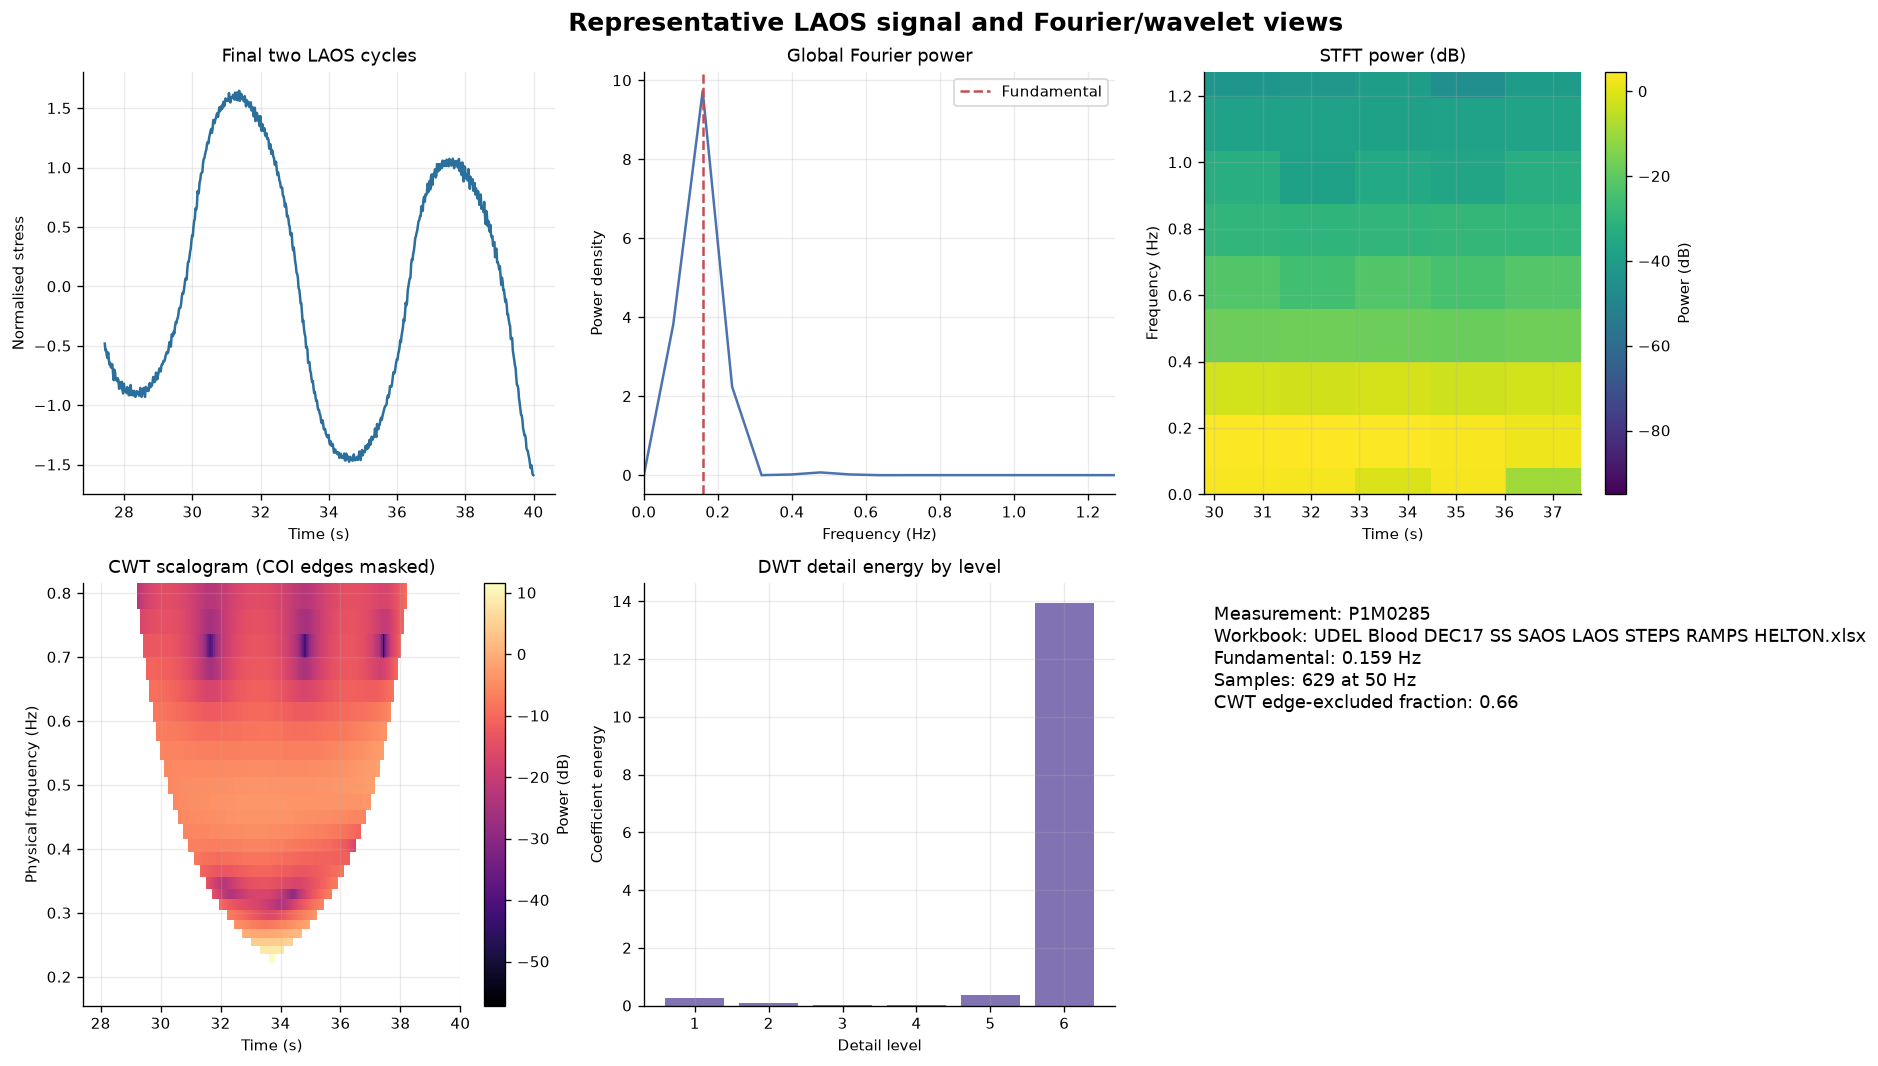

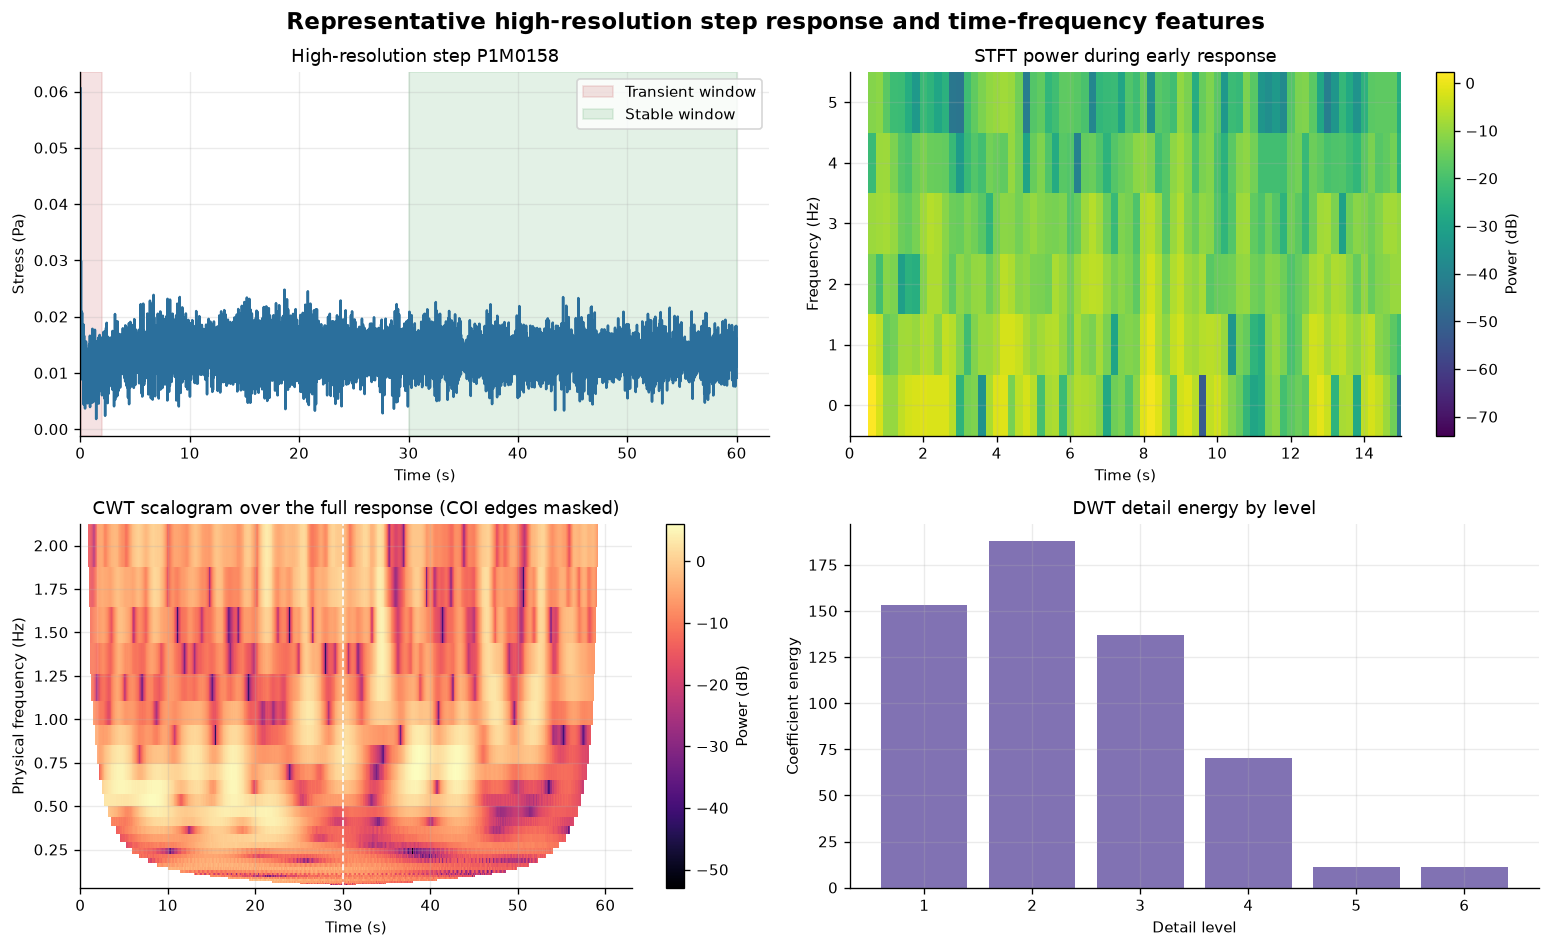

In [80]:
# Plotting one representative LAOS measurement across all four transform families
transform_representative_laos_signal_frame = transform_signals_by_measurement[TRANSFORM_REPRESENTATIVE_LAOS_ID]
transform_representative_laos_metadata = transform_laos_metadata.loc[
    transform_laos_metadata["measurement_id"].astype(str).eq(TRANSFORM_REPRESENTATIVE_LAOS_ID)
].iloc[0]
transform_representative_laos_frequency_hz = float(transform_representative_laos_metadata["omega_label_rad_s"]) / (2.0 * numpy.pi)
transform_representative_laos_period_seconds = 1.0 / transform_representative_laos_frequency_hz
transform_representative_laos_end_seconds = float(transform_representative_laos_signal_frame["time_s"].max())
transform_representative_laos_start_seconds = transform_representative_laos_end_seconds - TRANSFORM_LAOS_CYCLE_COUNT * transform_representative_laos_period_seconds
transform_representative_laos_window = transform_representative_laos_signal_frame.loc[
    transform_representative_laos_signal_frame["time_s"].between(transform_representative_laos_start_seconds, transform_representative_laos_end_seconds)
].copy()
transform_representative_laos_prepared = prepare_uniform_transform_signal(
    transform_representative_laos_window,
    TRANSFORM_LAOS_SAMPLING_FREQUENCY_HZ,
    apply_linear_detrending=True,
)
transform_representative_laos_methods = transform_diagnostic_records_by_measurement[(TRANSFORM_REPRESENTATIVE_LAOS_ID, "LAOS")]

figure, axis_objects = pyplot.subplots(2, 3, figsize=(16, 9))
axis_objects[0, 0].plot(
    transform_representative_laos_prepared["uniform_time_values"],
    transform_representative_laos_prepared["normalised_stress_values"],
    color="#2B6F9C",
)
axis_objects[0, 0].set(title="Final two LAOS cycles", xlabel="Time (s)", ylabel="Normalised stress")
fft_plot_values = transform_representative_laos_methods["FFT"]
axis_objects[0, 1].plot(fft_plot_values["frequency_values_hz"], fft_plot_values["power_density_values"], color="#4C72B0")
axis_objects[0, 1].axvline(transform_representative_laos_frequency_hz, color="#C44E52", linestyle="--", label="Fundamental")
axis_objects[0, 1].set(xlim=(0, min(8 * transform_representative_laos_frequency_hz, 10)), title="Global Fourier power", xlabel="Frequency (Hz)", ylabel="Power density")
axis_objects[0, 1].legend()
stft_plot_values = transform_representative_laos_methods["STFT"]
stft_mesh = axis_objects[0, 2].pcolormesh(
    stft_plot_values["time_values_seconds"],
    stft_plot_values["frequency_values_hz"],
    10.0 * numpy.log10(stft_plot_values["power_values"] + numpy.finfo(float).tiny),
    shading="auto",
    cmap="viridis",
)
axis_objects[0, 2].set(title="STFT power (dB)", xlabel="Time (s)", ylabel="Frequency (Hz)", ylim=(0, min(8 * transform_representative_laos_frequency_hz, 10)))
figure.colorbar(stft_mesh, ax=axis_objects[0, 2], label="Power (dB)")
cwt_plot_values = transform_representative_laos_methods["CWT"]
masked_cwt_power_values = numpy.ma.masked_where(
    ~cwt_plot_values["edge_valid_mask"],
    cwt_plot_values["power_values"],
)
cwt_mesh = axis_objects[1, 0].pcolormesh(
    cwt_plot_values["time_values_seconds"],
    cwt_plot_values["frequency_values_hz"],
    10.0 * numpy.log10(masked_cwt_power_values + numpy.finfo(float).tiny),
    shading="auto",
    cmap="magma",
)
axis_objects[1, 0].set(title="CWT scalogram (COI edges masked)", xlabel="Time (s)", ylabel="Physical frequency (Hz)")
figure.colorbar(cwt_mesh, ax=axis_objects[1, 0], label="Power (dB)")
dwt_plot_values = transform_representative_laos_methods["DWT"]
dwt_level_numbers = list(range(1, len(dwt_plot_values["detail_energy_values"]) + 1))
axis_objects[1, 1].bar(dwt_level_numbers, dwt_plot_values["detail_energy_values"], color="#8172B3")
axis_objects[1, 1].set(title="DWT detail energy by level", xlabel="Detail level", ylabel="Coefficient energy")
axis_objects[1, 2].axis("off")
axis_objects[1, 2].text(
    0.02, 0.95,
    f"Measurement: {TRANSFORM_REPRESENTATIVE_LAOS_ID}\n"
    f"Workbook: {transform_representative_laos_metadata['source_file']}\n"
    f"Fundamental: {transform_representative_laos_frequency_hz:.3f} Hz\n"
    f"Samples: {transform_representative_laos_prepared['uniform_sample_count']} at 50 Hz\n"
    f"CWT edge-excluded fraction: {transform_method_feature_tables['CWT'].loc[transform_method_feature_tables['CWT']['measurement_id'].eq(TRANSFORM_REPRESENTATIVE_LAOS_ID), 'edge_excluded_coefficient_fraction'].iloc[0]:.2f}",
    va="top",
    fontsize=11,
)
figure.suptitle("Representative LAOS signal and Fourier/wavelet views", fontsize=15, fontweight="bold")
figure.tight_layout()
pyplot.show()

# Plotting one high-resolution step response and marking the shared transient and stable windows
if TRANSFORM_REPRESENTATIVE_STEP_ID is not None:
    transform_representative_step_signal_frame = transform_signals_by_measurement[TRANSFORM_REPRESENTATIVE_STEP_ID]
    transform_representative_step_event = transform_step_event_lookup[TRANSFORM_REPRESENTATIVE_STEP_ID]
    transform_representative_step_feature = transform_step_feature_lookup[TRANSFORM_REPRESENTATIVE_STEP_ID]
    transform_representative_step_start_seconds = float(transform_representative_step_event["t_rate_settle"])
    transform_representative_step_signal_window = transform_representative_step_signal_frame.loc[
        transform_representative_step_signal_frame["time_s"].ge(transform_representative_step_start_seconds)
    ].copy()
    transform_representative_step_prepared = prepare_uniform_transform_signal(
        transform_representative_step_signal_window,
        TRANSFORM_STEP_SAMPLING_FREQUENCY_HZ,
        apply_linear_detrending=False,
        baseline_stress_pa=float(transform_representative_step_feature["sigma_pre"]),
    )
    transform_representative_step_full_methods = transform_diagnostic_records_by_measurement[(TRANSFORM_REPRESENTATIVE_STEP_ID, "STEP_FULL_RESPONSE")]
    figure, axis_objects = pyplot.subplots(2, 2, figsize=(13, 8))
    axis_objects[0, 0].plot(
        transform_representative_step_signal_frame["time_s"],
        transform_representative_step_signal_frame["stress_pa"],
        color="#2B6F9C",
    )
    axis_objects[0, 0].axvspan(transform_representative_step_start_seconds, TRANSFORM_STEP_TRANSIENT_END_SECONDS, color="#C44E52", alpha=0.16, label="Transient window")
    axis_objects[0, 0].axvspan(TRANSFORM_STEP_STABLE_START_SECONDS, float(transform_representative_step_signal_frame["time_s"].max()), color="#55A868", alpha=0.16, label="Stable window")
    axis_objects[0, 0].set(xlim=(0, 63), title=f"High-resolution step {TRANSFORM_REPRESENTATIVE_STEP_ID}", xlabel="Time (s)", ylabel="Stress (Pa)")
    axis_objects[0, 0].legend()
    step_stft_plot_values = transform_representative_step_full_methods["STFT"]
    step_stft_mesh = axis_objects[0, 1].pcolormesh(
        step_stft_plot_values["time_values_seconds"],
        step_stft_plot_values["frequency_values_hz"],
        10.0 * numpy.log10(step_stft_plot_values["power_values"] + numpy.finfo(float).tiny),
        shading="auto",
        cmap="viridis",
    )
    axis_objects[0, 1].set(xlim=(0, 15), title="STFT power during early response", xlabel="Time (s)", ylabel="Frequency (Hz)")
    figure.colorbar(step_stft_mesh, ax=axis_objects[0, 1], label="Power (dB)")
    step_cwt_plot_values = transform_representative_step_full_methods["CWT"]
    masked_step_cwt_power_values = numpy.ma.masked_where(
        ~step_cwt_plot_values["edge_valid_mask"],
        step_cwt_plot_values["power_values"],
    )
    step_cwt_mesh = axis_objects[1, 0].pcolormesh(
        step_cwt_plot_values["time_values_seconds"],
        step_cwt_plot_values["frequency_values_hz"],
        10.0 * numpy.log10(masked_step_cwt_power_values + numpy.finfo(float).tiny),
        shading="auto",
        cmap="magma",
    )
    axis_objects[1, 0].axvspan(transform_representative_step_start_seconds, TRANSFORM_STEP_TRANSIENT_END_SECONDS, color="white", alpha=0.08)
    axis_objects[1, 0].axvline(TRANSFORM_STEP_STABLE_START_SECONDS, color="white", linestyle="--", linewidth=1)
    axis_objects[1, 0].set(xlim=(0, 63), title="CWT scalogram over the full response (COI edges masked)", xlabel="Time (s)", ylabel="Physical frequency (Hz)")
    figure.colorbar(step_cwt_mesh, ax=axis_objects[1, 0], label="Power (dB)")
    step_dwt_plot_values = transform_representative_step_full_methods["DWT"]
    step_dwt_level_numbers = list(range(1, len(step_dwt_plot_values["detail_energy_values"]) + 1))
    axis_objects[1, 1].bar(step_dwt_level_numbers, step_dwt_plot_values["detail_energy_values"], color="#8172B3")
    axis_objects[1, 1].set(title="DWT detail energy by level", xlabel="Detail level", ylabel="Coefficient energy")
    figure.suptitle("Representative high-resolution step response and time-frequency features", fontsize=14, fontweight="bold")
    figure.tight_layout()
    pyplot.show()



## 9. Saving feature tables, parameter documentation, and figures

The output folder contains the four method-specific feature tables, shared wide and long tables, conventional baselines, cohort eligibility audit, feature dictionary, parameter table, grouped association summaries, sensitivity tables, runtime summary, and representative figures. The primary measurement-level merge uses the common LAOS and step transient windows. The method-support summary records when short, sparsely sampled step windows cannot support CWT or DWT frequency features. Full-response step outputs remain separately labelled because they cover only the high-resolution subset.

In [81]:
# Adding conventional baseline columns to the primary-window feature table
transform_primary_window_features = transform_feature_table_wide.loc[
    ~transform_feature_table_wide["analysis_window"].eq("step_full_response_high_resolution_only")
].copy()
transform_primary_window_features = transform_primary_window_features.merge(
    transform_laos_baseline_metadata,
    on="measurement_id",
    how="left",
    suffixes=("", "__laos_baseline"),
    validate="many_to_one",
)
transform_primary_window_features = transform_primary_window_features.merge(
    transform_step_baseline_metadata,
    on="measurement_id",
    how="left",
    suffixes=("", "__step_baseline"),
    validate="one_to_one",
)

transform_export_tables = {
    "fft_features.csv": transform_method_feature_tables["FFT"],
    "stft_features.csv": transform_method_feature_tables["STFT"],
    "cwt_features.csv": transform_method_feature_tables["CWT"],
    "dwt_features.csv": transform_method_feature_tables["DWT"],
    "transform_features_wide.csv": transform_feature_table_wide,
    "transform_features_long.csv": transform_feature_table_long,
    "transform_primary_features_with_baselines.csv": transform_primary_window_features,
    "transform_sampling_audit.csv": transform_sampling_diagnostics,
    "transform_method_support_summary.csv": transform_method_support_summary,
    "step_transform_eligibility.csv": transform_step_sampling_audit,
    "transform_feature_dictionary.csv": transform_feature_dictionary,
    "transform_parameter_table.csv": transform_parameter_table,
    "transform_grouped_associations.csv": transform_grouped_association_summary,
    "transform_sampling_sensitivity.csv": transform_sampling_sensitivity,
    "transform_sampling_sensitivity_summary.csv": transform_sampling_sensitivity_summary,
    "transform_stft_window_sensitivity.csv": transform_stft_window_sensitivity,
    "transform_dwt_boundary_sensitivity.csv": transform_dwt_boundary_sensitivity,
    "transform_step_window_boundary_sensitivity.csv": transform_step_window_boundary_sensitivity,
    "transform_noise_sensitivity.csv": transform_noise_sensitivity,
    "transform_cwt_edge_support_sensitivity.csv": transform_cwt_edge_support_sensitivity,
    "transform_runtime_summary.csv": transform_runtime_summary,
}
for output_file_name, output_dataframe in transform_export_tables.items():
    output_dataframe.to_csv(TRANSFORM_RESULTS_DIRECTORY / output_file_name, index=False)

print("Saved transform analysis tables to:", TRANSFORM_RESULTS_DIRECTORY)
# Removing superseded diagnostic charts so only representative transform plots remain
TRANSFORM_SUPERSEDED_FIGURE_NAMES = [
    "assessing_native_sampling_support_before_applying_time_frequency_methods.png",
    "laos_feature_relationships_by_transform_family.png",
    "per_measurement_transform_runtime.png",
    "step_transform_support_under_a_shared_64_sample_window_rule.png",
]
for superseded_figure_name in TRANSFORM_SUPERSEDED_FIGURE_NAMES:
    superseded_figure_path = TRANSFORM_FIGURE_DIRECTORY / superseded_figure_name
    if superseded_figure_path.is_file():
        superseded_figure_path.unlink()

for figure_number, figure_identifier in enumerate(pyplot.get_fignums(), start=1):
    current_figure = pyplot.figure(figure_identifier)
    figure_title = current_figure._suptitle.get_text() if current_figure._suptitle is not None else ""
    if not figure_title and current_figure.axes:
        figure_title = current_figure.axes[0].get_title()
    figure_filename_stub = re.sub(r"[^a-z0-9]+", "_", figure_title.lower()).strip("_")
    if not figure_filename_stub:
        figure_filename_stub = f"transform_figure_{figure_number:02d}"
    current_figure.savefig(TRANSFORM_FIGURE_DIRECTORY / f"{figure_filename_stub}.png", dpi=180, bbox_inches="tight")
print("Saved transform figures to:", TRANSFORM_FIGURE_DIRECTORY)
print("Primary transform feature rows:", len(transform_primary_window_features))
print("High-resolution full-response step rows:", int(transform_feature_table_wide["analysis_window"].eq("step_full_response_high_resolution_only").sum()))


Saved transform analysis tables to: /Users/riamishra/Desktop/Haemograph_Project/01_Active_Blood_Project/04_Results/Fourier_Wavelet_Feature_Development
Saved transform figures to: /Users/riamishra/Desktop/Haemograph_Project/01_Active_Blood_Project/04_Results/Fourier_Wavelet_Feature_Development/figures
Primary transform feature rows: 317
High-resolution full-response step rows: 6


## 10. Comparing methods on matched real-data cohorts

This comparison uses the same LAOS measurements and analysis windows for all four methods. Step comparisons use the 136 common low-resolution transient records for FFT and STFT; wavelet coverage is reported explicitly, because CWT and DWT are unsupported for most of those records. The six high-resolution step records are a separate, small cohort.

Methods are compared using (1) supported measurement coverage, (2) within-workbook agreement in the ranking of measurements for conceptually related features, (3) associations with LAOS strain amplitude, and (4) sampling/window sensitivity and computation time. Related feature names do not imply identical definitions: each transform has different frequency or scale bands. These results compare descriptive behaviour and practical support; they are not accuracy scores or evidence of ground-truth detection.


In [82]:
# Preparing readable support counts for the shared analysis cohorts
transform_method_comparison_support_counts = transform_method_support_summary.pivot_table(
    index=["method", "measurement_type", "analysis_window"],
    columns="method_support_status",
    values="measurement_count",
    aggfunc="sum",
    fill_value=0,
).reset_index()

transform_method_comparison_support_counts.columns.name = None
transform_method_comparison_support_counts = transform_method_comparison_support_counts.rename(columns={
    "computed": "computed_measurements",
    "computed_with_observed_frequency_limit": "computed_with_frequency_limit",
    "insufficient_edge_support": "insufficient_edge_support_measurements",
    "insufficient_frequency_support": "insufficient_frequency_support_measurements",
})

# Defining related feature pairs for matched measurement-ranking comparisons
transform_comparison_pairs = [
    ("LAOS", "Entropy", "FFT", "fft__spectral_entropy_normalised", "STFT", "stft__mean_spectral_entropy_normalised", ["workbook"]),
    ("LAOS", "Entropy", "FFT", "fft__spectral_entropy_normalised", "CWT", "cwt__wavelet_energy_entropy_normalised", ["workbook"]),
    ("LAOS", "Entropy", "FFT", "fft__spectral_entropy_normalised", "DWT", "dwt__dwt_energy_entropy_normalised", ["workbook"]),
    ("LAOS", "Entropy", "STFT", "stft__mean_spectral_entropy_normalised", "CWT", "cwt__wavelet_energy_entropy_normalised", ["workbook"]),
    ("LAOS", "Entropy", "STFT", "stft__mean_spectral_entropy_normalised", "DWT", "dwt__dwt_energy_entropy_normalised", ["workbook"]),
    ("LAOS", "Entropy", "CWT", "cwt__wavelet_energy_entropy_normalised", "DWT", "dwt__dwt_energy_entropy_normalised", ["workbook"]),
    ("LAOS", "High-to-low energy", "FFT", "fft__high_to_low_frequency_energy_ratio", "CWT", "cwt__high_to_low_frequency_energy_ratio", ["workbook"]),
    ("LAOS", "High-to-low energy", "FFT", "fft__high_to_low_frequency_energy_ratio", "DWT", "dwt__dwt_high_to_low_frequency_energy_ratio", ["workbook"]),
    ("LAOS", "High-to-low energy", "CWT", "cwt__high_to_low_frequency_energy_ratio", "DWT", "dwt__dwt_high_to_low_frequency_energy_ratio", ["workbook"]),
    ("Step transient", "Entropy", "FFT", "fft__spectral_entropy_normalised", "STFT", "stft__mean_spectral_entropy_normalised", ["workbook", "direction"]),
    ("Step transient", "High-to-low energy", "FFT", "fft__high_to_low_frequency_energy_ratio", "STFT", "stft__mean_high_to_low_frequency_energy_ratio", ["workbook", "direction"]),
]

transform_comparison_pair_records = []
for (
    transform_comparison_cohort,
    transform_comparison_concept,
    transform_first_method,
    transform_first_feature,
    transform_second_method,
    transform_second_feature,
    transform_grouping_columns,
) in transform_comparison_pairs:
    if transform_comparison_cohort == "LAOS":
        transform_comparison_cohort_data = transform_feature_table_wide.loc[
            transform_feature_table_wide["measurement_type"].eq("LAOS")
            & transform_feature_table_wide["analysis_window"].eq("laos_final_two_cycles")
        ].copy()
    else:
        transform_comparison_cohort_data = transform_feature_table_wide.loc[
            transform_feature_table_wide["measurement_type"].eq("STEP_UP_DOWN")
            & transform_feature_table_wide["analysis_window"].eq("step_transient_settled_to_2s")
        ].copy()

    for transform_group_values, transform_group_data in transform_comparison_cohort_data.groupby(
        transform_grouping_columns,
        dropna=False,
    ):
        transform_paired_feature_data = transform_group_data[
            [transform_first_feature, transform_second_feature]
        ].dropna()
        if len(transform_paired_feature_data) < 4:
            continue
        if (
            transform_paired_feature_data[transform_first_feature].nunique() < 2
            or transform_paired_feature_data[transform_second_feature].nunique() < 2
        ):
            continue

        transform_group_spearman_rho = scipy_stats.spearmanr(
            transform_paired_feature_data[transform_first_feature],
            transform_paired_feature_data[transform_second_feature],
        ).statistic
        transform_comparison_pair_records.append({
            "cohort": transform_comparison_cohort,
            "feature_concept": transform_comparison_concept,
            "method_pair": f"{transform_first_method} vs {transform_second_method}",
            "grouping_unit": " / ".join(transform_grouping_columns),
            "group_label": str(transform_group_values),
            "paired_measurement_count": len(transform_paired_feature_data),
            "within_group_spearman_rho": transform_group_spearman_rho,
        })

transform_method_pairwise_rank_agreement = pandas.DataFrame(transform_comparison_pair_records)
transform_method_pairwise_rank_summary = (
    transform_method_pairwise_rank_agreement
    .groupby(["cohort", "feature_concept", "method_pair", "grouping_unit"], as_index=False)
    .agg(
        independent_group_count=("within_group_spearman_rho", "count"),
        median_within_group_spearman_rho=("within_group_spearman_rho", "median"),
        lower_quartile_spearman_rho=("within_group_spearman_rho", lambda transform_group_rho_values: transform_group_rho_values.quantile(0.25)),
        upper_quartile_spearman_rho=("within_group_spearman_rho", lambda transform_group_rho_values: transform_group_rho_values.quantile(0.75)),
        median_paired_measurements_per_group=("paired_measurement_count", "median"),
    )
)

# Selecting LAOS strain-association summaries for related transform features
transform_laos_comparison_feature_names = {
    "fft__spectral_entropy_normalised": "FFT entropy",
    "stft__mean_spectral_entropy_normalised": "STFT entropy",
    "cwt__wavelet_energy_entropy_normalised": "CWT scale entropy",
    "dwt__dwt_energy_entropy_normalised": "DWT level entropy",
    "fft__high_to_low_frequency_energy_ratio": "FFT high-to-low ratio",
    "cwt__high_to_low_frequency_energy_ratio": "CWT high-to-low ratio",
    "dwt__dwt_high_to_low_frequency_energy_ratio": "DWT high-to-low ratio",
}
transform_method_comparison_laos_associations = transform_grouped_association_summary.loc[
    transform_grouped_association_summary["measurement_type"].eq("LAOS")
    & transform_grouped_association_summary["feature_name"].isin(transform_laos_comparison_feature_names)
].copy()
transform_method_comparison_laos_associations["feature_label"] = (
    transform_method_comparison_laos_associations["feature_name"].map(transform_laos_comparison_feature_names)
)

# Saving the comparison tables alongside the existing transform results
transform_method_comparison_support_counts.to_csv(
    TRANSFORM_RESULTS_DIRECTORY / "transform_method_comparison_support.csv",
    index=False,
)
transform_method_pairwise_rank_agreement.to_csv(
    TRANSFORM_RESULTS_DIRECTORY / "transform_method_pairwise_rank_agreement_by_group.csv",
    index=False,
)
transform_method_pairwise_rank_summary.to_csv(
    TRANSFORM_RESULTS_DIRECTORY / "transform_method_pairwise_rank_agreement_summary.csv",
    index=False,
)
transform_method_comparison_laos_associations.to_csv(
    TRANSFORM_RESULTS_DIRECTORY / "transform_method_comparison_laos_associations.csv",
    index=False,
)

# Displaying support, matched ranking, strain-association, and sensitivity evidence
display(transform_method_comparison_support_counts)
display(transform_method_pairwise_rank_summary.round(3))
display(
    transform_method_comparison_laos_associations[[
        "feature_label", "independent_group_count", "median_spearman_rho",
        "positive_group_fraction", "negative_group_fraction", "two_sided_sign_consistency_p",
    ]].sort_values("feature_label").round(3)
)
display(transform_sampling_sensitivity_summary.round(3))
display(transform_stft_window_sensitivity.round(3))
transform_runtime_comparison = transform_runtime_summary.copy()
transform_runtime_comparison["median_runtime_milliseconds"] = (
    transform_runtime_comparison["median_runtime_seconds"] * 1000
)
transform_runtime_comparison["p95_runtime_milliseconds"] = (
    transform_runtime_comparison["p95_runtime_seconds"] * 1000
)
display(transform_runtime_comparison[[
    "method", "measurement_type", "record_count", "median_runtime_milliseconds",
    "p95_runtime_milliseconds", "median_uniform_samples",
]].round(3))


,method,measurement_type,analysis_window,computed_measurements,computed_with_frequency_limit,insufficient_edge_support_measurements,insufficient_frequency_support_measurements
0,CWT,LAOS,laos_final_two_cycles,181,0,0,0
1,CWT,STEP_UP_DOWN,step_full_response_high_resolution_only,6,0,0,0
2,CWT,STEP_UP_DOWN,step_transient_settled_to_2s,0,0,136,0
3,DWT,LAOS,laos_final_two_cycles,181,0,0,0
4,DWT,STEP_UP_DOWN,step_full_response_high_resolution_only,6,0,0,0
5,DWT,STEP_UP_DOWN,step_transient_settled_to_2s,6,0,0,130
6,FFT,LAOS,laos_final_two_cycles,0,181,0,0
7,FFT,STEP_UP_DOWN,step_full_response_high_resolution_only,0,6,0,0
8,FFT,STEP_UP_DOWN,step_transient_settled_to_2s,0,136,0,0
9,STFT,LAOS,laos_final_two_cycles,0,181,0,0


,cohort,feature_concept,method_pair,grouping_unit,independent_group_count,median_within_group_spearman_rho,lower_quartile_spearman_rho,upper_quartile_spearman_rho,median_paired_measurements_per_group
0,LAOS,Entropy,CWT vs DWT,workbook,10,-0.650,-0.737,-0.490,17.0
1,LAOS,Entropy,FFT vs CWT,workbook,10,-0.612,-0.711,-0.462,17.0
2,LAOS,Entropy,FFT vs DWT,workbook,10,0.968,0.961,0.991,17.0
3,LAOS,Entropy,FFT vs STFT,workbook,10,0.894,0.783,0.919,17.0
4,LAOS,Entropy,STFT vs CWT,workbook,10,-0.619,-0.740,-0.350,17.0
5,LAOS,Entropy,STFT vs DWT,workbook,10,0.877,0.766,0.914,17.0
6,LAOS,High-to-low energy,CWT vs DWT,workbook,9,0.257,0.143,0.257,6.0
7,LAOS,High-to-low energy,FFT vs CWT,workbook,10,0.023,-0.056,0.129,17.0
8,LAOS,High-to-low energy,FFT vs DWT,workbook,9,0.886,0.886,0.886,6.0
9,Step transient,Entropy,FFT vs STFT,workbook / direction,15,0.583,0.071,0.812,6.0


,feature_label,independent_group_count,median_spearman_rho,positive_group_fraction,negative_group_fraction,two_sided_sign_consistency_p
9,CWT high-to-low ratio,10,0.333,0.9,0.1,0.021
11,CWT scale entropy,10,0.334,0.9,0.1,0.021
15,DWT high-to-low ratio,9,-0.943,0.0,1.0,0.004
13,DWT level entropy,10,-0.492,0.0,1.0,0.002
27,FFT entropy,10,-0.488,0.0,1.0,0.002
26,FFT high-to-low ratio,10,-0.767,0.0,1.0,0.002
33,STFT entropy,10,-0.207,0.3,0.7,0.344


,measurement_type,feature_name,lower_sampling_rate_hz,higher_sampling_rate_hz,paired_measurement_count,spearman_rho_across_resampling_rates,median_absolute_difference
0,LAOS,fft_harmonic_energy_fraction_1_3_5,25.0,50.0,181,0.999,0.000
1,LAOS,fft_spectral_entropy_normalised,25.0,50.0,181,0.991,0.023
2,LAOS,cwt_wavelet_energy_entropy_normalised,25.0,50.0,181,0.976,0.002
3,STEP_UP_DOWN,fft_spectral_entropy_normalised,5.0,10.0,136,0.887,0.047


,measurement_id,measurement_type,window_setting,mean_spectral_entropy_normalised,frame_count
0,P1M0011,LAOS,0.5_cycles,0.287,13
1,P1M0011,LAOS,1_cycles,0.251,5
2,P1M0011,LAOS,2_cycles,0.236,1
3,P1M0012,LAOS,0.5_cycles,0.231,13
4,P1M0012,LAOS,1_cycles,0.217,5
...,...,...,...,...,...
538,P1M0314,LAOS,1_cycles,0.156,5
539,P1M0314,LAOS,2_cycles,0.154,1
540,P1M0315,LAOS,0.5_cycles,0.137,13
541,P1M0315,LAOS,1_cycles,0.154,5


,method,measurement_type,record_count,median_runtime_milliseconds,p95_runtime_milliseconds,median_uniform_samples
0,FFT,LAOS,181,0.190,0.261,629.0
1,FFT,STEP_UP_DOWN,142,0.108,0.142,19.0
2,STFT,LAOS,181,0.191,0.234,629.0
3,STFT,STEP_UP_DOWN,142,0.157,0.204,19.0
4,CWT,LAOS,181,3.494,9.108,629.0
5,CWT,STEP_UP_DOWN,142,0.845,1.101,19.0
6,DWT,LAOS,181,0.166,0.208,629.0
7,DWT,STEP_UP_DOWN,142,0.020,0.040,19.0


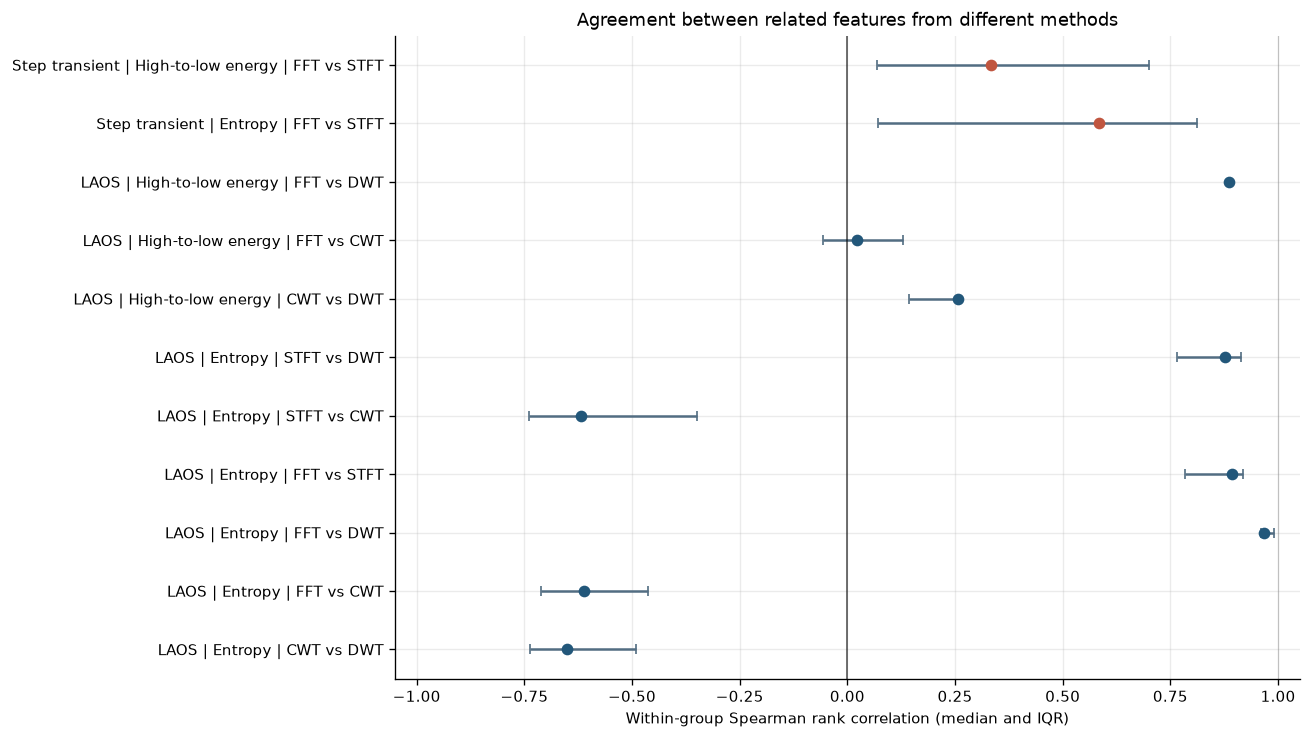

In [83]:
# Plotting matched feature-ranking agreement across independent source groups
transform_rank_plot_data = transform_method_pairwise_rank_summary.copy()
transform_rank_plot_data["comparison_label"] = (
    transform_rank_plot_data["cohort"]
    + " | "
    + transform_rank_plot_data["feature_concept"]
    + " | "
    + transform_rank_plot_data["method_pair"]
)
transform_rank_plot_data = transform_rank_plot_data.sort_values(
    ["cohort", "feature_concept", "method_pair"]
).reset_index(drop=True)

transform_rank_figure_height = max(5.0, 0.43 * len(transform_rank_plot_data) + 1.5)
transform_rank_figure, transform_rank_axis = pyplot.subplots(
    figsize=(11, transform_rank_figure_height)
)
for transform_plot_row_number, transform_plot_row in transform_rank_plot_data.iterrows():
    transform_rank_axis.errorbar(
        transform_plot_row["median_within_group_spearman_rho"],
        transform_plot_row_number,
        xerr=[[
            transform_plot_row["median_within_group_spearman_rho"]
            - transform_plot_row["lower_quartile_spearman_rho"]
        ], [
            transform_plot_row["upper_quartile_spearman_rho"]
            - transform_plot_row["median_within_group_spearman_rho"]
        ]],
        fmt="o",
        color="#22577A" if transform_plot_row["cohort"] == "LAOS" else "#C05640",
        ecolor="#526D82",
        capsize=3,
        markersize=6,
    )

transform_rank_axis.axvline(0, color="black", linewidth=1, alpha=0.65)
transform_rank_axis.axvline(1, color="grey", linewidth=0.7, alpha=0.4)
transform_rank_axis.set_yticks(range(len(transform_rank_plot_data)))
transform_rank_axis.set_yticklabels(transform_rank_plot_data["comparison_label"])
transform_rank_axis.set_xlim(-1.05, 1.05)
transform_rank_axis.set_xlabel("Within-group Spearman rank correlation (median and IQR)")
transform_rank_axis.set_title("Agreement between related features from different methods")
transform_rank_axis.grid(axis="x", alpha=0.25)
transform_rank_figure.tight_layout()
transform_rank_figure.savefig(
    TRANSFORM_FIGURE_DIRECTORY / "method_pairwise_rank_agreement.png",
    dpi=220,
    bbox_inches="tight",
)
pyplot.show()


### Reading the method comparison

The paired-ranking comparison asks whether two methods order measurements similarly **within each source workbook** (and within workbook and step direction for the step cohort). Each group needs at least four paired measurements. A high positive correlation means similar rankings; a negative correlation means opposite rankings. The interquartile range shows how much that agreement varies between groups.

In the saved run, LAOS entropy rankings agreed strongly for FFT–DWT (median within-workbook Spearman $\rho$ about 0.968) and FFT–STFT (about 0.894), while FFT–CWT was inverse (about -0.613). This indicates that the entropy features are not interchangeable across transforms. For the common step transient, FFT–STFT agreement was moderate for entropy (median $\rho$ about 0.583; IQR about 0.071–0.813) and weaker for the high-to-low energy ratio (about 0.333; IQR about 0.069–0.700), with substantial variation between workbook/direction groups.

For LAOS strain associations, FFT and DWT high-to-low ratios tended to decrease with strain within workbooks, while the CWT ratio tended to increase. Their scale/frequency definitions differ, so this is a reason to inspect feature definitions and sensitivity, not to declare one method correct. Sampling checks showed high rank stability for the selected LAOS FFT and CWT features between 25 and 50 Hz; step FFT entropy was less stable between 5 and 10 Hz. STFT window length and DWT boundary mode also affect their respective outputs.

**Interpretation:** FFT and DWT provide similar LAOS entropy rankings in this dataset, and FFT/STFT are the practical transform comparison for the common low-resolution step cohort. CWT contributes a distinct LAOS ranking but cannot be evaluated on common step transients under the current edge-support rule. Runtime is low for these short offline records for all four methods, so coverage, feature stability, and interpretability matter more here than raw computation time. None of these comparisons is a ground-truth accuracy test.


# Final real-data review and method benchmark

This final version preserves the existing analysis and adds a source-file audit, a condition-matching audit for the instrument comparison, explicit step-cohort reconciliation, corrected multiple-testing summaries, and a matched-workbook comparison of FFT, STFT, CWT, and DWT.

The real blood data contain no known clot-time labels. The statistical comparison below therefore measures how strongly preselected transform features track the protocol strain-amplitude levels across source workbooks. It is an exploratory method comparison, not clot-time accuracy.

## 11. Verifying raw workbook selection and DataZ exclusion

The notebook uses the standardized signals and catalogue produced by the processing pipeline. The following audit compares the current raw folder with the saved preprocessing inventory. It excludes DataZ and Excel lock files explicitly. Exact file-size matches provide a one-to-one inventory check; the saved inventory does not contain raw workbook hashes, so this is not a byte-for-byte identity test.

In [84]:
FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY = PROJECT_ROOT / "01_Active_Blood_Project" / "04_Results" / "Final_Real_Data_Analysis"
FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY.mkdir(parents = True, exist_ok = True)

raw_haemograph_directory = PROJECT_ROOT / "01_Active_Blood_Project" / "01_Data" / "Haemograph_Rheology"
raw_haemograph_paths = sorted(path for path in raw_haemograph_directory.iterdir() if path.is_file())
raw_excel_paths = [
    path for path in raw_haemograph_paths
    if path.suffix.casefold() == ".xlsx"
    and not path.name.startswith("~$")
    and path.name.casefold() != "dataz.xlsx"
]
excluded_dataz_paths = [
    path for path in raw_haemograph_paths
    if path.name.casefold() == "dataz.xlsx"
]
ignored_excel_lock_paths = [
    path for path in raw_haemograph_paths
    if path.name.startswith("~$")
]

preprocessing_file_inventory = pd.read_csv(PROCESSING_DIR / "file_inventory.csv")
preprocessing_measurement_index = pd.read_csv(INDEX_PATH)
raw_paths_by_size = {}
for raw_excel_path in raw_excel_paths:
    raw_paths_by_size.setdefault(raw_excel_path.stat().st_size, []).append(raw_excel_path)

raw_source_audit_records = []
for inventory_row in preprocessing_file_inventory.itertuples(index = False):
    matching_raw_paths = raw_paths_by_size.get(int(inventory_row.size_bytes), [])
    raw_source_audit_records.append({
        "processed_source_file": inventory_row.source_file,
        "processed_size_bytes": int(inventory_row.size_bytes),
        "matching_raw_filename": matching_raw_paths[0].name if len(matching_raw_paths) == 1 else "",
        "matching_raw_file_count": len(matching_raw_paths),
        "has_core_measurements": bool(
            preprocessing_measurement_index["source_file"].astype(str).eq(inventory_row.source_file).any()
        ),
        "audit_status": "unique file-size match" if len(matching_raw_paths) == 1 else "review required",
    })

raw_source_audit = pd.DataFrame(raw_source_audit_records)
excluded_input_audit = pd.DataFrame([
    {
        "filename": excluded_path.name,
        "size_bytes": excluded_path.stat().st_size,
        "handling": "excluded by design; separate DataZ dataset",
    }
    for excluded_path in excluded_dataz_paths
] + [
    {
        "filename": lock_path.name,
        "size_bytes": lock_path.stat().st_size,
        "handling": "ignored; temporary Excel lock file",
    }
    for lock_path in ignored_excel_lock_paths
])

if len(preprocessing_file_inventory) != 15:
    raise ValueError("The saved preprocessing inventory no longer contains the expected 15 workbooks.")
if not raw_source_audit["audit_status"].eq("unique file-size match").all():
    raise ValueError("At least one processed workbook is not matched uniquely to the current raw folder.")
if preprocessing_measurement_index["source_file"].astype(str).str.casefold().eq("dataz.xlsx").any():
    raise ValueError("DataZ appears in the processed measurement index and must be excluded before analysis.")

display(raw_source_audit)
display(excluded_input_audit)
print("Processed source workbooks:", len(raw_source_audit))
print("Core-scope workbooks:", int(raw_source_audit["has_core_measurements"].sum()))
print("DataZ records in processed catalogue:", int(
    preprocessing_measurement_index["source_file"].astype(str).str.casefold().eq("dataz.xlsx").sum()
))

raw_source_audit.to_csv(FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "raw_source_inventory_audit.csv", index = False)
excluded_input_audit.to_csv(FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "excluded_raw_inputs.csv", index = False)

,processed_source_file,processed_size_bytes,matching_raw_filename,matching_raw_file_count,has_core_measurements,audit_status
0,12FEB20 UDEL Blood.xlsx,1221984,data10.xlsx,1,True,unique file-size match
1,14DEC_UDEL_Blood_Rheo.xlsx,682006,data4.xlsx,1,True,unique file-size match
2,14MAR19 SS SAOS STEP LAOS etc.xlsx,1551963,data1.xlsx,1,True,unique file-size match
3,27FEB19 UDEL Blood.xlsx,1587275,data11.xlsx,1,True,unique file-size match
4,9MAY19 UDEL Blood.xlsx,1286412,data3.xlsx,1,True,unique file-size match
5,APR18 SS SAOS STEPS LAOS UDLAOS.xlsx,469070,data2.xlsx,1,True,unique file-size match
6,AUG18 UDEL Blood.xlsx,17649,data6.xlsx,1,True,unique file-size match
7,AY21 Aspirin Data to submit Mendeley 4May2021 ...,140739,data15.xlsx,1,False,unique file-size match
8,AY21 Aspirin Data to submit Mendeley 4May2021....,141335,data14.xlsx,1,False,unique file-size match
9,FEB18 UDEL ARES G2 SS LAOS SAW STEP UP DATA.xlsx,1760718,data7.xlsx,1,True,unique file-size match


,filename,size_bytes,handling
0,DataZ.xlsx,41526072,excluded by design; separate DataZ dataset
1,~$data1.xlsx,165,ignored; temporary Excel lock file


Processed source workbooks: 15
Core-scope workbooks: 13
DataZ records in processed catalogue: 0


The saved processing inventory contains the 15 numbered workbooks, while DataZ is absent. Thirteen inventoried workbooks contribute core LAOS or step records; the two aspirin-summary workbooks remain outside this analysis. The current analysis reads the standardized outputs, so changing the raw folder does not silently change its results.

For future preprocessing reruns, use `data_processing_pipeline_final.py` in this folder. It preserves the teammate pipeline while skipping DataZ and temporary Excel lock files.

## 12. Checking whether instrument comparisons use matched conditions

A meaningful instrument cross-check needs comparable angular frequency and strain amplitude. The saved cross-validation table includes both values, allowing the comparison conditions to be checked before interpreting its error or correlation statistics.

In [85]:
instrument_pair_condition_data = pd.read_csv(LAOS_FEATURE_DIR / "instrument_crossvalidation.csv")
instrument_pair_condition_data["omega_nominal_numeric"] = pd.to_numeric(
    instrument_pair_condition_data["omega_nominal"], errors = "coerce"
)
instrument_pair_condition_data["omega_instrument_numeric"] = pd.to_numeric(
    instrument_pair_condition_data["omega_instrument"], errors = "coerce"
)
instrument_pair_condition_data["strain_nominal_numeric"] = pd.to_numeric(
    instrument_pair_condition_data["strain_nominal"], errors = "coerce"
)
instrument_pair_condition_data["strain_instrument_numeric"] = pd.to_numeric(
    instrument_pair_condition_data["strain_instrument_pct"], errors = "coerce"
)

instrument_pair_condition_data["frequency_relative_difference"] = (
    abs(instrument_pair_condition_data["omega_instrument_numeric"]
        - instrument_pair_condition_data["omega_nominal_numeric"])
    / instrument_pair_condition_data["omega_nominal_numeric"].abs().replace(0, np.nan)
)
instrument_pair_condition_data["strain_relative_difference"] = (
    abs(instrument_pair_condition_data["strain_instrument_numeric"]
        - instrument_pair_condition_data["strain_nominal_numeric"])
    / instrument_pair_condition_data["strain_nominal_numeric"].abs().replace(0, np.nan)
)
instrument_pair_condition_data["frequency_matches_within_5_percent"] = (
    instrument_pair_condition_data["frequency_relative_difference"] <= 0.05
)
instrument_pair_condition_data["strain_matches_within_5_percent"] = (
    instrument_pair_condition_data["strain_relative_difference"] <= 0.05
)
instrument_pair_condition_data["same_condition_match"] = (
    instrument_pair_condition_data["frequency_matches_within_5_percent"]
    & instrument_pair_condition_data["strain_matches_within_5_percent"]
)

instrument_condition_summary = pd.DataFrame([{
    "instrument_pair_count": len(instrument_pair_condition_data),
    "frequency_matches_within_5_percent": int(
        instrument_pair_condition_data["frequency_matches_within_5_percent"].sum()
    ),
    "strain_matches_within_5_percent": int(
        instrument_pair_condition_data["strain_matches_within_5_percent"].sum()
    ),
    "matched_frequency_and_strain_pairs": int(
        instrument_pair_condition_data["same_condition_match"].sum()
    ),
    "median_laos_strain_percent": instrument_pair_condition_data["strain_nominal_numeric"].median(),
    "median_instrument_strain_percent": instrument_pair_condition_data["strain_instrument_numeric"].median(),
}])

display(instrument_condition_summary)
display(instrument_pair_condition_data[[
    "source_file", "measurement_id", "omega_nominal_numeric", "omega_instrument_numeric",
    "strain_nominal_numeric", "strain_instrument_numeric", "same_condition_match",
]].head(10))

instrument_pair_condition_data.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "instrument_condition_match_audit.csv",
    index = False,
)
instrument_condition_summary.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "instrument_condition_match_summary.csv",
    index = False,
)

,instrument_pair_count,frequency_matches_within_5_percent,strain_matches_within_5_percent,matched_frequency_and_strain_pairs,median_laos_strain_percent,median_instrument_strain_percent
0,26,26,0,0,10.0,996.146


,source_file,measurement_id,omega_nominal_numeric,omega_instrument_numeric,strain_nominal_numeric,strain_instrument_numeric,same_condition_match
0,12FEB20 UDEL Blood.xlsx,P1M0025,0.5,0.500000,10.0,996.334,False
1,12FEB20 UDEL Blood.xlsx,P1M0014,1.0,0.997631,10.0,995.789,False
2,12FEB20 UDEL Blood.xlsx,P1M0020,5.0,5.000000,10.0,996.146,False
3,14MAR19 SS SAOS STEP LAOS etc.xlsx,P1M0071,0.5,0.500000,10.0,996.333,False
4,14MAR19 SS SAOS STEP LAOS etc.xlsx,P1M0060,1.0,0.997631,10.0,995.791,False
5,14MAR19 SS SAOS STEP LAOS etc.xlsx,P1M0066,5.0,5.000000,10.0,996.145,False
6,27FEB19 UDEL Blood.xlsx,P1M0098,0.5,0.500000,10.0,996.334,False
7,27FEB19 UDEL Blood.xlsx,P1M0087,1.0,0.997631,10.0,995.789,False
8,27FEB19 UDEL Blood.xlsx,P1M0093,5.0,5.000000,10.0,996.146,False
9,FEB18 UDEL ARES G2 SS LAOS SAW STEP UP DATA.xlsx,P1M0179,0.5,0.500000,10.0,996.334,False


The saved pairs match frequency but not strain: the LAOS records are nominally at 10% strain, while the matched instrument sweep rows are about 995–996% strain. Therefore the existing G′, G″, and I₃/I₁ error and correlation summaries cannot be described as same-condition instrument validation. They are retained as unmatched cross-checks and should not support validation claims.

In [86]:
reviewed_laos_metric_status = pd.DataFrame([
    {
        "metric": "G_prime_Pa",
        "previous_status": "VALID",
        "reviewed_status": "Computed; independent instrument validation not established",
        "reason": "The saved instrument pairs do not match the LAOS strain amplitude.",
    },
    {
        "metric": "G_double_prime_Pa",
        "previous_status": "VALID",
        "reviewed_status": "Computed; independent instrument validation not established",
        "reason": "The saved instrument pairs do not match the LAOS strain amplitude.",
    },
    {
        "metric": "phase_angle_deg",
        "previous_status": "VALID",
        "reviewed_status": "Derived feature; no independent instrument phase measurement",
        "reason": "The supplied instrument summary has no directly matched phase-angle column.",
    },
    {
        "metric": "I3_I1",
        "previous_status": "VALID WITH CAUTION",
        "reviewed_status": "Computed; same-condition instrument validation not established",
        "reason": "The saved third-harmonic pairs do not match the LAOS strain amplitude.",
    },
    {
        "metric": "I5_I1",
        "previous_status": "UNSTABLE / EXPLORATORY",
        "reviewed_status": "Exploratory",
        "reason": "The feature is sensitive to detrending and lacks a matched instrument reference.",
    },
    {
        "metric": "THD_2to5",
        "previous_status": "UNSTABLE / EXPLORATORY",
        "reviewed_status": "Exploratory",
        "reason": "The feature is sensitive to detrending and combines higher harmonics.",
    },
    {
        "metric": "lissajous_normalized_area",
        "previous_status": "VALID DESCRIPTIVE",
        "reviewed_status": "Descriptive feature",
        "reason": "The feature describes loop shape; it is not an independent biological endpoint.",
    },
])

display(reviewed_laos_metric_status)
reviewed_laos_metric_status.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "reviewed_laos_metric_status.csv",
    index = False,
)

,metric,previous_status,reviewed_status,reason
0,G_prime_Pa,VALID,Computed; independent instrument validation no...,The saved instrument pairs do not match the LA...
1,G_double_prime_Pa,VALID,Computed; independent instrument validation no...,The saved instrument pairs do not match the LA...
2,phase_angle_deg,VALID,Derived feature; no independent instrument pha...,The supplied instrument summary has no directl...
3,I3_I1,VALID WITH CAUTION,Computed; same-condition instrument validation...,The saved third-harmonic pairs do not match th...
4,I5_I1,UNSTABLE / EXPLORATORY,Exploratory,The feature is sensitive to detrending and lac...
5,THD_2to5,UNSTABLE / EXPLORATORY,Exploratory,The feature is sensitive to detrending and com...
6,lissajous_normalized_area,VALID DESCRIPTIVE,Descriptive feature,The feature describes loop shape; it is not an...


## 13. Reconciling step cohorts and reporting transform support

The standardized step table has 138 records; the raw-workbook transient package has 136 mapped records. The two additional standardized records are shown separately because they have label-only step verification. Low-resolution CWT and DWT support is then reported alongside FFT and STFT coverage rather than forcing a four-method comparison on unmatched data.

In [87]:
shared_step_measurement_identifiers = set(shared_step_features["step_id"].astype(str))
mapped_step_measurement_identifiers = set(
    step_id_crosswalk["measurement_id"].dropna().astype(str)
)
shared_step_only_identifiers = sorted(
    shared_step_measurement_identifiers - mapped_step_measurement_identifiers
)
step_cohort_review = measurement_index.loc[
    measurement_index["measurement_id"].astype(str).isin(shared_step_only_identifiers),
    [
        "measurement_id", "source_file", "sheet", "condition_label", "n_points",
        "has_shear_rate", "qc_status", "qc_notes",
    ],
].copy()
step_cohort_review["cohort_note"] = "Present in 138-row shared table; absent from 136-row raw-workbook comparison"

step_cohort_summary = pd.DataFrame([
    {
        "cohort": "Shared standardized step features",
        "record_count": len(shared_step_features),
        "mapped_raw_workbook_records": len(mapped_step_measurement_identifiers),
        "record_note": "Includes two AUG18 records verified from labels only.",
    },
    {
        "cohort": "Raw-workbook step analysis",
        "record_count": len(step_analysis_features),
        "mapped_raw_workbook_records": len(mapped_step_measurement_identifiers),
        "record_note": "Use this 136-record cohort for matched method comparisons.",
    },
])

display(step_cohort_summary)
display(step_cohort_review)

step_transient_method_support = transform_method_support_summary.loc[
    transform_method_support_summary["measurement_type"].eq("STEP_UP_DOWN")
    & transform_method_support_summary["analysis_window"].eq("step_transient_settled_to_2s")
].copy()
step_transient_method_support["supported_record_count"] = np.where(
    step_transient_method_support["method_support_status"].isin([
        "computed", "computed_with_observed_frequency_limit",
    ]),
    step_transient_method_support["measurement_count"],
    0,
)
step_transient_method_support["unsupported_record_count"] = (
    step_transient_method_support["measurement_count"]
    - step_transient_method_support["supported_record_count"]
)

# Combining separate support-status rows so each transform has one common-cohort total
step_transient_method_support = step_transient_method_support.groupby(
    "method", as_index = False
).agg(
    measurement_count = ("measurement_count", "sum"),
    supported_record_count = ("supported_record_count", "sum"),
    unsupported_record_count = ("unsupported_record_count", "sum"),
    method_support_status = (
        "method_support_status",
        lambda support_status_values: "; ".join(sorted(set(support_status_values))),
    ),
)

display(step_transient_method_support[[
    "method", "measurement_count", "supported_record_count",
    "unsupported_record_count", "method_support_status",
]])

step_cohort_summary.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "step_cohort_review_summary.csv",
    index = False,
)
step_cohort_review.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "step_cohort_unmatched_records.csv",
    index = False,
)
step_transient_method_support.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "step_transient_method_support.csv",
    index = False,
)

,cohort,record_count,mapped_raw_workbook_records,record_note
0,Shared standardized step features,138,136,Includes two AUG18 records verified from label...
1,Raw-workbook step analysis,136,136,Use this 136-record cohort for matched method ...


,measurement_id,source_file,sheet,condition_label,n_points,has_shear_rate,qc_status,qc_notes,cohort_note
142,P1M0143,AUG18 UDEL Blood.xlsx,300 to 5,300 to 5,46,NO,OK,Irregular sampling (dt CV > 0.10); Shear-rate ...,Present in 138-row shared table; absent from 1...
143,P1M0144,AUG18 UDEL Blood.xlsx,0.1 to 5,0.1 to 5,53,NO,OK,Irregular sampling (dt CV > 0.10); Shear-rate ...,Present in 138-row shared table; absent from 1...


,method,measurement_count,supported_record_count,unsupported_record_count,method_support_status
0,CWT,136,0,136,insufficient_edge_support
1,DWT,136,6,130,computed; insufficient_frequency_support
2,FFT,136,136,0,computed_with_observed_frequency_limit
3,STFT,136,136,0,computed_with_observed_frequency_limit


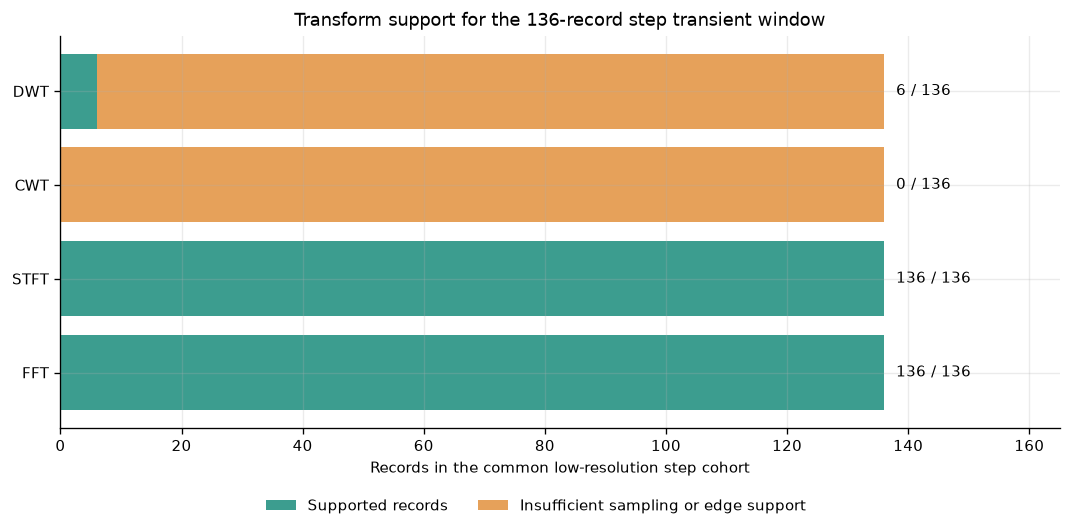

In [88]:
step_support_figure, step_support_axis = plt.subplots(figsize = (9, 4.5))
step_support_plot_data = step_transient_method_support.set_index("method").reindex(
    ["FFT", "STFT", "CWT", "DWT"]
).reset_index()

step_support_axis.barh(
    step_support_plot_data["method"],
    step_support_plot_data["supported_record_count"],
    color = "#3C9D8F",
    label = "Supported records",
)
step_support_axis.barh(
    step_support_plot_data["method"],
    step_support_plot_data["unsupported_record_count"],
    left = step_support_plot_data["supported_record_count"],
    color = "#E6A15A",
    label = "Insufficient sampling or edge support",
)
for row_number, support_row in step_support_plot_data.iterrows():
    step_support_axis.text(
        support_row["measurement_count"] + 2,
        row_number,
        f'{support_row["supported_record_count"]} / {support_row["measurement_count"]}',
        va = "center",
        fontsize = 9,
    )
step_support_axis.set(
    xlabel = "Records in the common low-resolution step cohort",
    title = "Transform support for the 136-record step transient window",
    xlim = (0, 165),
)
step_support_figure.legend(
    step_support_axis.get_legend_handles_labels()[0],
    step_support_axis.get_legend_handles_labels()[1],
    frameon = False,
    loc = "lower center",
    bbox_to_anchor = (0.5, 0.015),
    ncol = 2,
)
step_support_figure.tight_layout(rect = (0, 0.08, 1, 1))
step_support_figure.savefig(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "step_transform_support.png",
    dpi = 220,
    bbox_inches = "tight",
)
plt.show()

## 14. Correcting significance summaries for multiple testing

The original analyses contain several related feature tests. The following tables keep their original results and add Holm-adjusted p-values. These adjustments reduce false-positive claims when several features are tested within the same analysis family.

Workbook-level sign tests and transform comparisons share the same independence assumption: separate workbooks are treated as separate blocks. Donor IDs do not let us confirm that all workbooks contain independent donors, so treat these p-values as exploratory rather than donor-level evidence.

In [89]:
def calculate_holm_adjusted_p_values(p_values):
    p_value_series = pd.to_numeric(pd.Series(p_values), errors = "coerce")
    valid_p_value_mask = p_value_series.notna()
    valid_p_values = p_value_series.loc[valid_p_value_mask].to_numpy(dtype = float)
    adjusted_p_values = np.full(len(p_value_series), np.nan, dtype = float)

    if len(valid_p_values) == 0:
        return pd.Series(adjusted_p_values, index = p_value_series.index)

    sorted_positions = np.argsort(valid_p_values)
    sorted_p_values = valid_p_values[sorted_positions]
    adjusted_sorted_p_values = np.maximum.accumulate(
        (len(sorted_p_values) - np.arange(len(sorted_p_values))) * sorted_p_values
    )
    adjusted_sorted_p_values = np.minimum(adjusted_sorted_p_values, 1.0)
    restored_positions = np.empty(len(sorted_positions), dtype = int)
    restored_positions[sorted_positions] = np.arange(len(sorted_positions))
    adjusted_p_values[valid_p_value_mask.to_numpy()] = adjusted_sorted_p_values[restored_positions]

    return pd.Series(adjusted_p_values, index = p_value_series.index)

laos_amplitude_test_audit = laos_strain_results.copy()
laos_amplitude_test_audit["p_holm_across_21_tests"] = calculate_holm_adjusted_p_values(
    laos_amplitude_test_audit["two_sided_sign_test_p"]
)
laos_amplitude_test_audit["significant_after_holm"] = (
    laos_amplitude_test_audit["p_holm_across_21_tests"] < 0.05
)

step_magnitude_test_audit = step_magnitude_results.copy()
step_magnitude_test_audit["p_holm_across_20_tests"] = calculate_holm_adjusted_p_values(
    step_magnitude_test_audit["sign_test_p"]
)
step_magnitude_test_audit["significant_after_holm"] = (
    step_magnitude_test_audit["p_holm_across_20_tests"] < 0.05
)

step_direction_test_audit = step_direction_results.copy()
step_direction_test_audit["wilcoxon_p_holm_across_10_tests"] = calculate_holm_adjusted_p_values(
    step_direction_test_audit["wilcoxon_p"]
)
step_direction_test_audit["significant_wilcoxon_after_holm"] = (
    step_direction_test_audit["wilcoxon_p_holm_across_10_tests"] < 0.05
)

step_phase_test_audit = step_transient_stable_results.copy()
step_phase_test_audit["p_holm_across_9_tests"] = calculate_holm_adjusted_p_values(
    step_phase_test_audit["sign_test_p"]
)
step_phase_test_audit["significant_after_holm"] = (
    step_phase_test_audit["p_holm_across_9_tests"] < 0.05
)

transform_association_test_audit = transform_grouped_association_summary.copy()
transform_association_test_audit["p_holm_within_cohort"] = np.nan
for cohort_name, cohort_indices in transform_association_test_audit.groupby(
    "measurement_type"
).groups.items():
    transform_association_test_audit.loc[cohort_indices, "p_holm_within_cohort"] = (
        calculate_holm_adjusted_p_values(
            transform_association_test_audit.loc[
                cohort_indices, "two_sided_sign_consistency_p"
            ]
        ).to_numpy()
    )

display(laos_amplitude_test_audit.head(10))
display(step_direction_test_audit[[
    "feature", "wilcoxon_p", "wilcoxon_p_holm_across_10_tests",
    "significant_wilcoxon_after_holm",
]])

laos_amplitude_test_audit.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "laos_amplitude_tests_holm.csv",
    index = False,
)
step_magnitude_test_audit.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "step_magnitude_tests_holm.csv",
    index = False,
)
step_direction_test_audit.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "step_direction_tests_holm.csv",
    index = False,
)
step_phase_test_audit.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "step_transient_stable_tests_holm.csv",
    index = False,
)
transform_association_test_audit.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "transform_association_tests_holm.csv",
    index = False,
)

,omega_rad_s,metric,n_workbooks,median_spearman_rho,bootstrap_CI_low,bootstrap_CI_high,direction_consistency_fraction,two_sided_sign_test_p,p_holm_across_21_tests,significant_after_holm
0,0.5,G_prime_Pa,7,-1.0,-1.000000,-1.0,1.0,0.015625,0.171875,False
1,0.5,G_double_prime_Pa,7,-1.0,-1.000000,-1.0,1.0,0.015625,0.171875,False
2,0.5,phase_angle_deg,7,1.0,1.000000,1.0,1.0,0.015625,0.171875,False
3,0.5,I3_I1,7,0.1,0.100000,0.3,1.0,0.031250,0.171875,False
4,0.5,I5_I1,7,0.9,0.600000,0.9,1.0,0.015625,0.171875,False
5,0.5,THD_2to5,7,0.3,0.100000,0.6,1.0,0.015625,0.171875,False
6,0.5,lissajous_normalized_area,7,1.0,0.900000,1.0,1.0,0.015625,0.171875,False
7,1.0,G_prime_Pa,10,-1.0,-1.000000,-1.0,1.0,0.001953,0.041016,True
8,1.0,G_double_prime_Pa,10,-1.0,-1.000000,-1.0,1.0,0.001953,0.041016,True
9,1.0,phase_angle_deg,10,1.0,0.971429,1.0,1.0,0.001953,0.041016,True


,feature,wilcoxon_p,wilcoxon_p_holm_across_10_tests,significant_wilcoxon_after_holm
0,init_slope,0.001953,0.019531,True
1,undershoot,0.001953,0.019531,True
2,visc_ratio,0.015625,0.068359,False
3,overshoot,0.005859,0.046875,True
4,area_log,0.005859,0.046875,True
5,t_min,0.005859,0.046875,True
6,settling_time,0.013672,0.068359,False
7,t_peak,0.105469,0.210938,False
8,relax_amp,0.037109,0.111328,False
9,jump_signed,0.275391,0.275391,False


## 15. Comparing transform families across source workbooks

For a matched comparison, each method contributes one preselected entropy feature: FFT spectral entropy, mean STFT spectral entropy, CWT scale-energy entropy, and DWT energy entropy. Within each source workbook, measurements at the same strain amplitude are combined by their median across frequencies. Spearman association is then calculated over the six labelled strain amplitudes.

The comparison unit is the source workbook, not each individual measurement. The score is the absolute Spearman correlation, so a consistent increasing or decreasing relationship both count as strong tracking. Signed correlations are also retained. This measures association with the experimental strain protocol; it does not establish clot-time accuracy or a causal material transition. The conventional LAOS metrics remain contextual baselines rather than being mixed into the four-method rank test.

The ten source workbooks are the blocking units for these tests. They are not verified independent donor cohorts because donor identifiers are not consistently available across files; therefore the p-values are exploratory and should not be presented as donor-level clinical evidence. The bootstrap intervals also resample workbooks, not individual records.

In [90]:
laos_transform_entropy_features = {
    "FFT": "fft__spectral_entropy_normalised",
    "STFT": "stft__mean_spectral_entropy_normalised",
    "CWT": "cwt__wavelet_energy_entropy_normalised",
    "DWT": "dwt__dwt_energy_entropy_normalised",
}

laos_transform_association_data = transform_feature_table_wide.loc[
    transform_feature_table_wide["measurement_type"].eq("LAOS"),
    ["measurement_id", "source_file", "strain_amplitude", *laos_transform_entropy_features.values()],
].copy()
laos_transform_association_data["strain_amplitude"] = pd.to_numeric(
    laos_transform_association_data["strain_amplitude"], errors = "coerce"
)

workbook_method_association_records = []
for source_workbook_name, workbook_signal_features in laos_transform_association_data.groupby(
    "source_file", sort = True
):
    median_feature_by_strain = workbook_signal_features.groupby(
        "strain_amplitude"
    )[list(laos_transform_entropy_features.values())].median()
    median_feature_by_strain = median_feature_by_strain.loc[
        median_feature_by_strain.index.to_series().gt(0)
    ]

    association_record = {
        "source_workbook": source_workbook_name,
        "strain_amplitude_level_count": len(median_feature_by_strain),
    }

    for method_name, feature_column_name in laos_transform_entropy_features.items():
        paired_feature_values = median_feature_by_strain[
            [feature_column_name]
        ].dropna()
        if len(paired_feature_values) < 4:
            spearman_association = np.nan
        else:
            spearman_association = stats.spearmanr(
                np.log10(paired_feature_values.index.to_numpy(dtype = float)),
                paired_feature_values[feature_column_name].to_numpy(dtype = float),
            ).statistic

        association_record[f"{method_name}_spearman_rho"] = spearman_association
        association_record[f"{method_name}_absolute_spearman_rho"] = abs(spearman_association)

    workbook_method_association_records.append(association_record)

workbook_method_association_scores = pd.DataFrame(workbook_method_association_records)
workbook_method_score_columns = [
    f"{method_name}_absolute_spearman_rho"
    for method_name in laos_transform_entropy_features
]
workbook_method_score_matrix = workbook_method_association_scores.set_index(
    "source_workbook"
)[workbook_method_score_columns].rename(columns = {
    f"{method_name}_absolute_spearman_rho": method_name
    for method_name in laos_transform_entropy_features
})
workbook_method_score_matrix = workbook_method_score_matrix.dropna(
    subset = list(laos_transform_entropy_features)
)

display(workbook_method_association_scores.round(3))
print("Complete independent workbook blocks:", len(workbook_method_score_matrix))
print("Strain levels available per workbook:", sorted(
    workbook_method_association_scores["strain_amplitude_level_count"].unique()
))

workbook_method_association_scores.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "transform_method_workbook_association_scores.csv",
    index = False,
)

,source_workbook,strain_amplitude_level_count,FFT_spearman_rho,FFT_absolute_spearman_rho,STFT_spearman_rho,STFT_absolute_spearman_rho,CWT_spearman_rho,CWT_absolute_spearman_rho,DWT_spearman_rho,DWT_absolute_spearman_rho
0,12FEB20 UDEL Blood.xlsx,6,-1.000,1.000,-0.714,0.714,0.657,0.657,-1.000,1.000
1,14DEC_UDEL_Blood_Rheo.xlsx,6,-0.943,0.943,0.314,0.314,0.086,0.086,-1.000,1.000
2,14MAR19 SS SAOS STEP LAOS etc.xlsx,6,-1.000,1.000,-1.000,1.000,-0.943,0.943,-1.000,1.000
3,27FEB19 UDEL Blood.xlsx,6,-1.000,1.000,-0.829,0.829,0.657,0.657,-1.000,1.000
4,APR18 SS SAOS STEPS LAOS UDLAOS.xlsx,6,-0.943,0.943,0.829,0.829,0.600,0.600,-1.000,1.000
5,FEB18 UDEL ARES G2 SS LAOS SAW STEP UP DATA.xlsx,6,-1.000,1.000,-0.257,0.257,0.486,0.486,-1.000,1.000
6,JUL18.xlsx,6,-1.000,1.000,-0.771,0.771,0.600,0.600,-1.000,1.000
7,JUN18.xlsx,6,-0.829,0.829,-0.829,0.829,0.429,0.429,-0.943,0.943
8,NOV18 UDEL ARESG2 DATA.xlsx,6,-0.086,0.086,0.886,0.886,0.086,0.086,-0.143,0.143
9,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,6,-0.943,0.943,-0.600,0.600,0.314,0.314,-1.000,1.000


Complete independent workbook blocks: 10
Strain levels available per workbook: [np.int64(6)]


In [91]:
transform_method_names = list(laos_transform_entropy_features)
transform_method_score_values = [
    workbook_method_score_matrix[method_name].to_numpy(dtype = float)
    for method_name in transform_method_names
]
friedman_method_test = stats.friedmanchisquare(*transform_method_score_values)

method_average_ranks = workbook_method_score_matrix.rank(
    axis = 1,
    ascending = False,
    method = "average",
).mean(axis = 0)
method_test_count = len(workbook_method_score_matrix)
method_count = len(transform_method_names)
kendall_w_effect_size = float(
    friedman_method_test.statistic / (method_test_count * (method_count - 1))
)
nemenyi_q_critical = stats.studentized_range.ppf(
    0.95, method_count, np.inf
) / np.sqrt(2.0)
nemenyi_critical_difference = nemenyi_q_critical * np.sqrt(
    method_count * (method_count + 1) / (6.0 * method_test_count)
)

paired_method_test_records = []
for first_method_position, first_method_name in enumerate(transform_method_names):
    for second_method_name in transform_method_names[first_method_position + 1:]:
        paired_first_scores = workbook_method_score_matrix[first_method_name]
        paired_second_scores = workbook_method_score_matrix[second_method_name]
        paired_score_differences = paired_first_scores - paired_second_scores

        if np.allclose(paired_score_differences.to_numpy(), 0.0):
            wilcoxon_statistic = 0.0
            wilcoxon_p_value = 1.0
            paired_rank_biserial_effect = 0.0
        else:
            nonzero_score_differences = paired_score_differences.loc[
                ~np.isclose(paired_score_differences, 0.0)
            ]
            absolute_difference_ranks = stats.rankdata(
                abs(nonzero_score_differences.to_numpy(dtype = float))
            )
            positive_rank_sum = float(
                absolute_difference_ranks[nonzero_score_differences.to_numpy() > 0].sum()
            )
            negative_rank_sum = float(
                absolute_difference_ranks[nonzero_score_differences.to_numpy() < 0].sum()
            )
            paired_rank_biserial_effect = (
                (positive_rank_sum - negative_rank_sum)
                / (positive_rank_sum + negative_rank_sum)
            )
            wilcoxon_result = stats.wilcoxon(
                paired_first_scores,
                paired_second_scores,
                alternative = "two-sided",
                method = "auto",
            )
            wilcoxon_statistic = float(wilcoxon_result.statistic)
            wilcoxon_p_value = float(wilcoxon_result.pvalue)

        average_rank_difference = abs(
            method_average_ranks[first_method_name]
            - method_average_ranks[second_method_name]
        )
        nemenyi_standard_error = np.sqrt(
            method_count * (method_count + 1) / (6.0 * method_test_count)
        )
        nemenyi_q_statistic = (
            np.sqrt(2.0) * average_rank_difference / nemenyi_standard_error
        )
        nemenyi_p_value = float(
            stats.studentized_range.sf(nemenyi_q_statistic, method_count, np.inf)
        )

        paired_method_test_records.append({
            "first_method": first_method_name,
            "second_method": second_method_name,
            "workbook_count": method_test_count,
            "wilcoxon_statistic": wilcoxon_statistic,
            "wilcoxon_p_value": wilcoxon_p_value,
            "median_paired_score_difference": float(paired_score_differences.median()),
            "mean_paired_score_difference": float(paired_score_differences.mean()),
            "paired_rank_biserial_effect": paired_rank_biserial_effect,
            "average_rank_difference": average_rank_difference,
            "nemenyi_p_value": nemenyi_p_value,
            "nemenyi_significant_at_0_05": average_rank_difference > nemenyi_critical_difference,
        })

paired_transform_method_tests = pd.DataFrame(paired_method_test_records)
paired_transform_method_tests["wilcoxon_p_holm"] = calculate_holm_adjusted_p_values(
    paired_transform_method_tests["wilcoxon_p_value"]
)
paired_transform_method_tests["wilcoxon_significant_after_holm"] = (
    paired_transform_method_tests["wilcoxon_p_holm"] < 0.05
)

transform_method_summary_records = []
random_number_generator = np.random.default_rng(20261013)
for method_name in transform_method_names:
    signed_association_values = workbook_method_association_scores[
        f"{method_name}_spearman_rho"
    ].dropna().to_numpy(dtype = float)
    absolute_association_values = workbook_method_score_matrix[
        method_name
    ].to_numpy(dtype = float)

    bootstrap_median_values = []
    for bootstrap_iteration in range(5000):
        bootstrap_sample = random_number_generator.choice(
            absolute_association_values,
            size = len(absolute_association_values),
            replace = True,
        )
        bootstrap_median_values.append(float(np.median(bootstrap_sample)))

    transform_method_summary_records.append({
        "method": method_name,
        "workbook_count": len(absolute_association_values),
        "median_signed_spearman_rho": float(np.median(signed_association_values)),
        "median_absolute_spearman_rho": float(np.median(absolute_association_values)),
        "bootstrap_95_percentile_low": float(np.percentile(bootstrap_median_values, 2.5)),
        "bootstrap_95_percentile_high": float(np.percentile(bootstrap_median_values, 97.5)),
        "average_friedman_rank": float(method_average_ranks[method_name]),
    })

transform_method_statistical_summary = pd.DataFrame(
    transform_method_summary_records
).sort_values("average_friedman_rank")

friedman_test_summary = pd.DataFrame([{
    "comparison": "Four transform entropy features across source workbooks",
    "independent_workbook_count": method_test_count,
    "method_count": method_count,
    "friedman_statistic": float(friedman_method_test.statistic),
    "friedman_p_value": float(friedman_method_test.pvalue),
    "kendall_w_effect_size": kendall_w_effect_size,
    "nemenyi_alpha": 0.05,
    "nemenyi_critical_difference": float(nemenyi_critical_difference),
}])

display(friedman_test_summary)
display(transform_method_statistical_summary.round(4))
display(paired_transform_method_tests.round(4))

transform_method_statistical_summary.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "transform_method_statistical_summary.csv",
    index = False,
)
paired_transform_method_tests.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "transform_method_pairwise_wilcoxon_nemenyi.csv",
    index = False,
)
friedman_test_summary.to_csv(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "transform_method_friedman_summary.csv",
    index = False,
)

,comparison,independent_workbook_count,method_count,friedman_statistic,friedman_p_value,kendall_w_effect_size,nemenyi_alpha,nemenyi_critical_difference
0,Four transform entropy features across source ...,10,4,22.3,0.000056,0.743333,0.05,1.483231


,method,workbook_count,median_signed_spearman_rho,median_absolute_spearman_rho,bootstrap_95_percentile_low,bootstrap_95_percentile_high,average_friedman_rank
3,DWT,10,-1.0000,1.0000,0.9714,1.0000,1.40
0,FFT,10,-0.9714,0.9714,0.8857,1.0000,2.00
1,STFT,10,-0.6571,0.8000,0.5143,0.8571,2.75
2,CWT,10,0.4571,0.5429,0.2857,0.6571,3.85


,first_method,second_method,workbook_count,wilcoxon_statistic,wilcoxon_p_value,median_paired_score_difference,mean_paired_score_difference,paired_rank_biserial_effect,average_rank_difference,nemenyi_p_value,nemenyi_significant_at_0_05,wilcoxon_p_holm,wilcoxon_significant_after_holm
0,FFT,STFT,10,8.0,0.1953,0.2000,0.1714,0.5556,0.75,0.5635,False,0.2188,False
1,FFT,CWT,10,0.0,0.0039,0.3714,0.3886,1.0000,1.85,0.0074,True,0.0195,True
2,FFT,DWT,10,0.0,0.0625,-0.0286,-0.0343,-1.0000,0.60,0.7263,False,0.1875,False
3,STFT,CWT,10,6.0,0.0234,0.2000,0.2171,0.7818,1.10,0.2257,False,0.0938,False
4,STFT,DWT,10,8.5,0.1094,-0.2000,-0.2057,-0.6222,1.35,0.0895,False,0.2188,False
5,CWT,DWT,10,0.0,0.0020,-0.4000,-0.4229,-1.0000,2.45,0.0001,True,0.0117,True


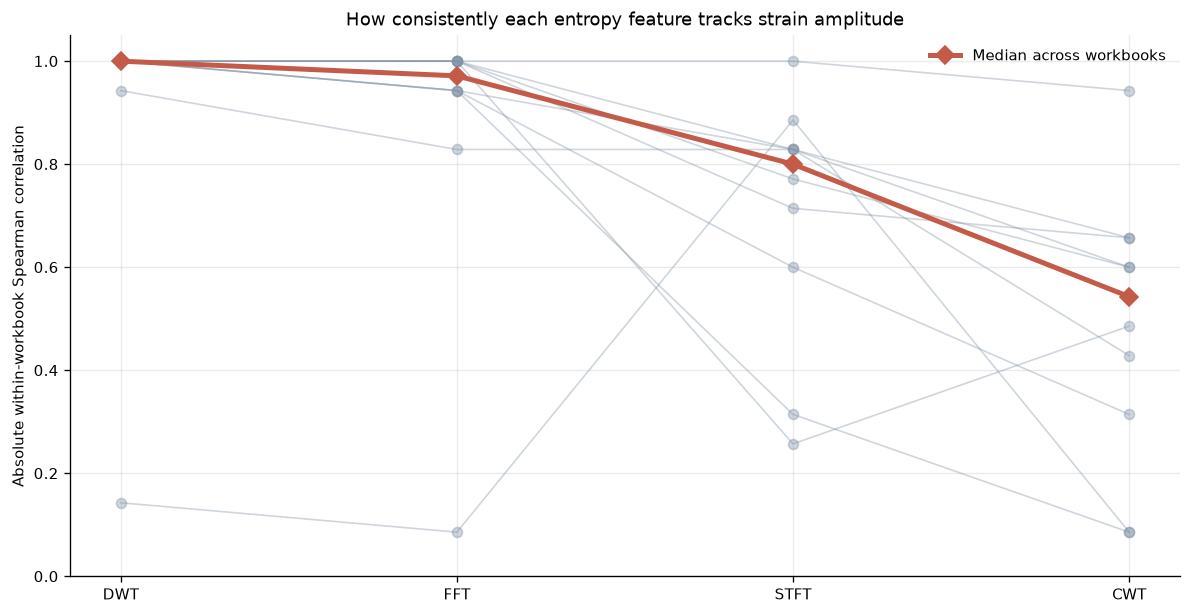

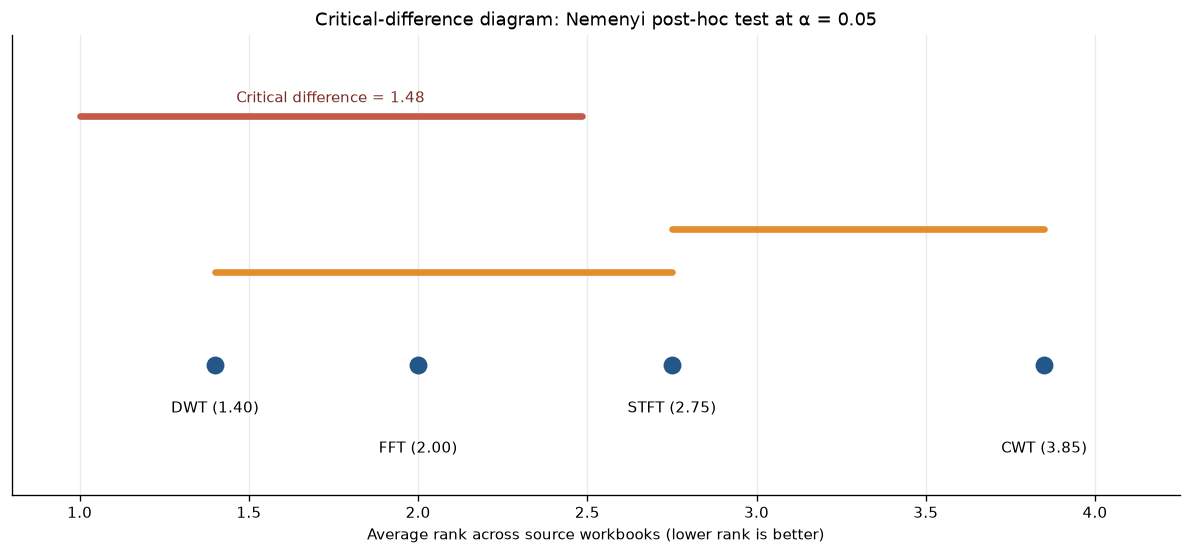

In [92]:
method_rank_order = transform_method_statistical_summary["method"].to_list()
method_score_figure, method_score_axis = plt.subplots(figsize = (10, 5.2))
method_axis_positions = np.arange(len(method_rank_order))

for workbook_name, workbook_scores in workbook_method_score_matrix[method_rank_order].iterrows():
    method_score_axis.plot(
        method_axis_positions,
        workbook_scores.to_numpy(dtype = float),
        marker = "o",
        linewidth = 1,
        alpha = 0.38,
        color = "#8093A6",
    )

median_method_scores = workbook_method_score_matrix[method_rank_order].median(axis = 0)
method_score_axis.plot(
    method_axis_positions,
    median_method_scores.to_numpy(dtype = float),
    marker = "D",
    linewidth = 3,
    markersize = 8,
    color = "#C45B49",
    label = "Median across workbooks",
)
method_score_axis.set_xticks(method_axis_positions, method_rank_order)
method_score_axis.set(
    ylabel = "Absolute within-workbook Spearman correlation",
    title = "How consistently each entropy feature tracks strain amplitude",
    ylim = (0, 1.05),
)
method_score_axis.grid(axis = "y", alpha = 0.25)
method_score_axis.legend(frameon = False)
method_score_figure.tight_layout()
method_score_figure.savefig(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "transform_workbook_association_scores.png",
    dpi = 220,
    bbox_inches = "tight",
)
plt.show()

method_rank_values = method_average_ranks.sort_values()
ranked_methods = method_rank_values.index.to_list()
critical_difference_figure, critical_difference_axis = plt.subplots(figsize = (10, 4.7))

for method_position, method_name in enumerate(ranked_methods):
    average_rank = float(method_rank_values[method_name])
    critical_difference_axis.scatter(
        average_rank, 0.0, s = 95, color = "#235789", zorder = 3,
    )
    vertical_offset = -0.16 if method_position % 2 == 0 else -0.34
    critical_difference_axis.text(
        average_rank,
        vertical_offset,
        f"{method_name} ({average_rank:.2f})",
        ha = "center",
        va = "top",
        fontsize = 9,
    )

nonsignificant_rank_groups = []
for group_start in range(len(ranked_methods)):
    for group_end in range(group_start + 1, len(ranked_methods)):
        group_methods = ranked_methods[group_start:group_end + 1]
        group_rank_span = (
            method_rank_values[group_methods[-1]] - method_rank_values[group_methods[0]]
        )
        if group_rank_span <= nemenyi_critical_difference:
            nonsignificant_rank_groups.append(tuple(group_methods))

maximal_nonsignificant_groups = [
    group for group in nonsignificant_rank_groups
    if not any(set(group).issubset(set(other_group)) and group != other_group
               for other_group in nonsignificant_rank_groups)
]
for group_number, group_methods in enumerate(maximal_nonsignificant_groups):
    first_rank = float(method_rank_values[group_methods[0]])
    last_rank = float(method_rank_values[group_methods[-1]])
    connector_height = 0.42 + 0.19 * group_number
    critical_difference_axis.plot(
        [first_rank, last_rank],
        [connector_height, connector_height],
        color = "#E28E2C",
        linewidth = 4,
        solid_capstyle = "round",
    )

critical_difference_axis.plot(
    [1.0, 1.0 + nemenyi_critical_difference],
    [1.12, 1.12],
    color = "#C45B49",
    linewidth = 4,
    solid_capstyle = "round",
)
critical_difference_axis.text(
    1.0 + nemenyi_critical_difference / 2,
    1.18,
    f"Critical difference = {nemenyi_critical_difference:.2f}",
    ha = "center",
    fontsize = 9,
    color = "#7C2D25",
)
critical_difference_axis.set(
   xlim = (0.8, method_count + 0.25),
    ylim = (-0.58, 1.48),
    yticks = [],
    xlabel = "Average rank across source workbooks (lower rank is better)",
    title = "Critical-difference diagram: Nemenyi post-hoc test at α = 0.05",
)
critical_difference_axis.grid(axis = "x", alpha = 0.25)
critical_difference_figure.tight_layout()
critical_difference_figure.savefig(
    FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY / "transform_method_critical_difference.png",
    dpi = 220,
    bbox_inches = "tight",
)
plt.show()

## 16. Reading the corrected real-data comparison

The Friedman test checks whether the four preselected entropy features have different association strengths across the ten source workbooks. Paired Wilcoxon tests compare workbook-level scores, with Holm adjustment across the six method pairs. The Nemenyi critical-difference diagram summarizes average ranks and which rank gaps exceed the critical difference.

These are comparisons of protocol-strain tracking, not of clot-time detection. Stronger association with imposed strain amplitude does not establish that an algorithm detects a clot point or is universally superior. The low-resolution step cohort remains a support audit: CWT has no supported transient windows and DWT has only six, so a four-way step significance test would be misleading.

In [93]:
print("Final real-data analysis outputs:", FINAL_REAL_ANALYSIS_OUTPUT_DIRECTORY)
print("Matched workbook count for the transform comparison:", method_test_count)
print("Median absolute association by method:")
print(transform_method_statistical_summary[[
    "method", "median_absolute_spearman_rho", "average_friedman_rank",
]].round(3).to_string(index = False))
print(
    "Friedman test: statistic = "
    f"{friedman_method_test.statistic:.3f}, p = {friedman_method_test.pvalue:.6g}"
)
print(
    "Nemenyi critical difference = "
    f"{nemenyi_critical_difference:.3f}; significant pair count = "
    f"{int(paired_transform_method_tests['nemenyi_significant_at_0_05'].sum())}"
)
print(
    "Same-condition instrument pairs = "
    f"{int(instrument_condition_summary['matched_frequency_and_strain_pairs'].iloc[0])} / "
    f"{int(instrument_condition_summary['instrument_pair_count'].iloc[0])}"
)
print(
    "Low-resolution step transform support: "
    + ", ".join(
        f'{row.method} {row.supported_record_count}/{row.measurement_count}'
        for row in step_transient_method_support.itertuples(index = False)
    )
)
print(f"Friedman Kendall W effect size = {kendall_w_effect_size:.3f}")

Final real-data analysis outputs: /Users/riamishra/Desktop/Haemograph_Project/01_Active_Blood_Project/04_Results/Final_Real_Data_Analysis
Matched workbook count for the transform comparison: 10
Median absolute association by method:
method  median_absolute_spearman_rho  average_friedman_rank
   DWT                         1.000                   1.40
   FFT                         0.971                   2.00
  STFT                         0.800                   2.75
   CWT                         0.543                   3.85
Friedman test: statistic = 22.300, p = 5.64959e-05
Nemenyi critical difference = 1.483; significant pair count = 2
Same-condition instrument pairs = 0 / 26
Low-resolution step transform support: CWT 0/136, DWT 6/136, FFT 136/136, STFT 136/136
Friedman Kendall W effect size = 0.743
